# Détection de Posidonia oceanica par SegFormer

## Notebook tutoriel - Segmentation sémantique avec SegFormer (variantes B0, B1, B2, B3, B4, B5)

Ce notebook implémente l'architecture **SegFormer** (Xie et al., 2021) pour la
segmentation sémantique de la Posidonia oceanica en imagerie sous-marine. Il
constitue le troisième volet de l'étude comparative entre trois familles
d'architectures :

- **U-Net** (CNN encodeur-décodeur, entraîné from scratch)
- **FCN-8s VGG16** (CNN avec encodeur pré-entraîné ImageNet, référence Martin-Abadal 2018)
- **SegFormer** (Transformer hiérarchique, ce notebook)

### Spécificité de ce notebook

Le notebook gère les **6 variantes** SegFormer-B0, B1, B2, B3, B4, B5 via une variable unique `SEGFORMER_VARIANT` (en cellule de configuration). Changer cette variable suffit à basculer entre les variantes : le chemin de sauvegarde s'adapte automatiquement (`segformer_b0/`, `segformer_b1/`, `segformer_b2/`), évitant tout risque d'écrasement des résultats.

### Démarche

Identique à celle appliquée à U-Net et FCN-VGG16 :
1. Variation des fonctions de perte (Section 7)
2. Variation de la résolution (Section 8)
3. Variation des prétraitements (Section 9)
4. Mini-GridSearch sur les hyperparamètres (Section 10)
5. Validation finale par K-fold k=5 stratifié (Section 11)
6. Synthèse et préparation de la comparaison finale (Section 12)


# 0. Configuration globale et setup

## 0.1 Imports / installations

Toutes les librairies nécessaires sont importées ici

In [4]:
import sys, torch
print(sys.executable)    # doit contenir "posidonie_env"
print(torch.__version__)

c:\M2_USPN\Projet_Stage_M2\implémentations\segformer_env\Scripts\python.exe
2.12.0+cpu


In [5]:
import torch
print(torch.__version__)

2.12.0+cpu


In [6]:
# === INSTALLATION DE TRANSFORMERS (pour SegFormer) ===
# SegFormer provient de Hugging Face transformers
try:
    import transformers
    print(f" transformers {transformers.__version__} déjà installé")
except ImportError:
    import subprocess
    subprocess.run(["pip", "install", "transformers", "-q"])
    import transformers
    print(f" transformers {transformers.__version__} installé")

c:\M2_USPN\Projet_Stage_M2\implémentations\segformer_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


 transformers 4.40.0 déjà installé


In [7]:
# === IMPORTS ===

# Standard library
import os
import sys
import gc
import json
import shutil
import datetime
from pathlib import Path

# Numerical & ML
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import transforms

# Image processing
import cv2
from PIL import Image

# Scikit-learn (split + métriques)
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve, average_precision_score,
    confusion_matrix
)

# Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Progress bars
from tqdm.auto import tqdm

# Reproductibilité
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Affichage des versions
print("=== Environnement ===")
print(f"  PyTorch       : {torch.__version__}")
print(f"  NumPy         : {np.__version__}")
print(f"  CUDA          : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"  GPU           : {torch.cuda.get_device_name(0)}")
    print(f"  Mémoire GPU   : {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"  SEED          : {SEED}")

=== Environnement ===
  PyTorch       : 2.12.0+cpu
  NumPy         : 2.4.6
  CUDA          : False
  SEED          : 42


## 0.2 Paramètres globaux

Toutes les constantes du notebook sont définies ici. **Pour modifier
une configuration (par exemple changer la résolution), il suffit de
modifier les valeurs ici puis de relancer les cellules suivantes.**

In [8]:
# ============================================================
# PARAMÈTRES GLOBAUX
# ============================================================

import os
import torch

# ------------------------------------------------------------
# CONFIGURATION DU MODÈLE
# ------------------------------------------------------------

SEGFORMER_VARIANT = "b2"

# ------------------------------------------------------------
# CHEMIN RACINE DU PROJET - LOCAL WINDOWS
# ------------------------------------------------------------

DRIVE_ROOT = r"C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project"

# ------------------------------------------------------------
# CHEMINS DU PROJET
# ------------------------------------------------------------

LOCAL_PATH = os.path.join(
    DRIVE_ROOT,
    "Dataset"
)

SHARED_DIR = os.path.join(
    DRIVE_ROOT,
    "shared"
)

SEGFORMER_DIR = os.path.join(
    DRIVE_ROOT,
    "segformer"
)

ARCH_DIR = os.path.join(
    SEGFORMER_DIR,
    f"segformer_{SEGFORMER_VARIANT}"
)

RESULTS_DIR = os.path.join(
    ARCH_DIR,
    "results"
)

SINGLESPLIT_DIR = os.path.join(
    RESULTS_DIR,
    "singlesplit"
)

KFOLD_DIR = os.path.join(
    RESULTS_DIR,
    "kfold"
)

FIGURES_DIR = os.path.join(
    RESULTS_DIR,
    "figures"
)

TRAIN_CSV = os.path.join(
    LOCAL_PATH,
    "train_split_stratified.csv"
)

VAL_CSV = os.path.join(
    LOCAL_PATH,
    "val_split_stratified.csv"
)

# ------------------------------------------------------------
# PARAMÈTRES DU DATASET
# ------------------------------------------------------------

IMG_H = 360
IMG_W = 480

N_CLASSES = 2

# Pour reproduire le protocole final SegFormer-B2
BATCH_SIZE = 8

# ------------------------------------------------------------
# PARAMÈTRES D'ENTRAÎNEMENT
# ------------------------------------------------------------

DEFAULT_LR = 1e-4
DEFAULT_EPOCHS = 100
DEFAULT_PATIENCE = 9
DEFAULT_WEIGHT_DECAY = 1e-4

DEFAULT_THRESHOLD_CRITERION = "recall_minus_fallout"

# ------------------------------------------------------------
# DEVICE
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

# ------------------------------------------------------------
# CRÉATION DES DOSSIERS DE SORTIE
# ------------------------------------------------------------

for directory in [
    SHARED_DIR,
    SEGFORMER_DIR,
    ARCH_DIR,
    RESULTS_DIR,
    SINGLESPLIT_DIR,
    KFOLD_DIR,
    FIGURES_DIR,
]:
    os.makedirs(directory, exist_ok=True)

# ------------------------------------------------------------
# VÉRIFICATIONS
# ------------------------------------------------------------

print("=== Configuration locale ===")
print(f"Drive root       : {DRIVE_ROOT}")
print(f"Dataset          : {LOCAL_PATH}")
print(f"Train CSV        : {TRAIN_CSV}")
print(f"Validation CSV   : {VAL_CSV}")
print(f"Architecture     : SegFormer-{SEGFORMER_VARIANT.upper()}")
print(f"Résolution       : {IMG_H} x {IMG_W}")
print(f"Batch size       : {BATCH_SIZE}")
print(f"Device           : {DEVICE}")

print("\n=== Vérification des chemins ===")

print(
    "Projet :",
    "OK" if os.path.exists(DRIVE_ROOT)
    else "INTROUVABLE"
)

print(
    "Dataset :",
    "OK" if os.path.exists(LOCAL_PATH)
    else "INTROUVABLE"
)

print(
    "Train CSV :",
    "OK" if os.path.exists(TRAIN_CSV)
    else "INTROUVABLE"
)

print(
    "Val CSV :",
    "OK" if os.path.exists(VAL_CSV)
    else "INTROUVABLE"
)

=== Configuration locale ===
Drive root       : C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project
Dataset          : C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\Dataset
Train CSV        : C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\Dataset\train_split_stratified.csv
Validation CSV   : C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\Dataset\val_split_stratified.csv
Architecture     : SegFormer-B2
Résolution       : 360 x 480
Batch size       : 8
Device           : cpu

=== Vérification des chemins ===
Projet : OK
Dataset : OK
Train CSV : OK
Val CSV : OK


## 0.3 Setup Drive (Colab uniquement)

Cette cellule **doit être exécutée en premier sur chaque nouvelle session Colab**.
Elle :
1. Monte Google Drive
2. Crée la structure de dossiers si elle n'existe pas
3. Vérifie que tous les fichiers nécessaires sont présents

**Sur un environnement local**, je sauterai cette cellule.

In [9]:
# === SETUP DRIVE (à exécuter en début de session Colab) ===

# Détection automatique de Colab
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Monter Drive si pas déjà monté
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount('/content/drive')
        print("Google Drive monté")
    else:
        print("Google Drive déjà monté")
else:
    print("Environnement local détecté (pas de Drive à monter)")

# Créer la structure de dossiers (no-op si existant)
for d in [SHARED_DIR, ARCH_DIR, RESULTS_DIR,
          SINGLESPLIT_DIR, KFOLD_DIR, FIGURES_DIR]:
    os.makedirs(d, exist_ok=True)

print("\n=== Structure des dossiers ===")
print(f"  shared/         : {SHARED_DIR}")
print(f"  segformer/      : {ARCH_DIR}")
print(f"  segformer/results/ : {RESULTS_DIR}")
print(f"    ├─ singlesplit/")
print(f"    ├─ kfold/")
print(f"    └─ figures/")

Environnement local détecté (pas de Drive à monter)

=== Structure des dossiers ===
  shared/         : C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\shared
  segformer/      : C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\segformer\segformer_b2
  segformer/results/ : C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\segformer\segformer_b2\results
    ├─ singlesplit/
    ├─ kfold/
    └─ figures/


## 0.4 Vérifications de l'environnement

Vérifications préalables : Dataset accessible, CSV stratifiés présents,
SEMEDA pré-entraîné disponible

In [10]:
# === VÉRIFICATIONS ===

print("=== Vérifications préalables ===\n")

# 1. Dataset
print("1. Dataset Posidonia :")
training_imgs = os.path.join(LOCAL_PATH, "training", "images")
testing_imgs  = os.path.join(LOCAL_PATH, "testing", "images")

for label, path in [("Training images", training_imgs), ("Testing images", testing_imgs)]:
    if os.path.exists(path):
        n = len([f for f in os.listdir(path) if f.lower().endswith(('.png', '.jpg'))])
        print(f"  {label}: {n} fichiers ({path})")
    else:
        print(f"  {label}: INTROUVABLE ({path})")

# 2. CSV stratifiés
print("\n2. CSV stratifiés :")
for label, path in [("Train CSV", TRAIN_CSV), ("Val CSV", VAL_CSV)]:
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"   {label}: {len(df)} lignes ({path})")
    else:
        print(f"   {label}: INTROUVABLE ({path})")

# 3. SEMEDA pré-entraîné : bien qu'il ne sera pas utile pour les premières expériementations, on le charge tout de mêmes
print("\n3. SEMEDA pré-entraîné:")
semeda_path = os.path.join(SHARED_DIR, "semeda_net_pretrained.pth")
if os.path.exists(semeda_path):
    size_mb = os.path.getsize(semeda_path) / (1024*1024)
    print(f"   Disponible : {semeda_path} ({size_mb:.2f} MB)")
else:
    print(f"   Non trouvé : {semeda_path}")
    print(f"     SEMEDA sera pré-entraîné automatiquement quand nécessaire")

# 4. Espace disque
if IN_COLAB:
    import shutil as sh
    stat = sh.disk_usage('/content')
    print(f"\n4. Espace disque Colab :")
    print(f"   Total : {stat.total/1e9:.1f} GB")
    print(f"   Libre : {stat.free/1e9:.1f} GB")

print("\n=== Vérifications terminées ===")

=== Vérifications préalables ===

1. Dataset Posidonia :
  Training images: 376 fichiers (C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\Dataset\training\images)
  Testing images: 94 fichiers (C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\Dataset\testing\images)

2. CSV stratifiés :
   Train CSV: 300 lignes (C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\Dataset\train_split_stratified.csv)
   Val CSV: 76 lignes (C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\Dataset\val_split_stratified.csv)

3. SEMEDA pré-entraîné:
   Disponible : C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\shared\semeda_net_pretrained.pth (0.33 MB)

=== Vérifications terminées ===


# 1. Dataset Posidonia

Cette section définit les classes Dataset PyTorch pour charger les images
et leurs masques de segmentation.

**Deux modes de chargement** :
- `PosidoniaDatasetFromCSV` : charge depuis les CSV stratifiés (training/val splits)
- `PosidoniaDataset` : charge directement depuis un dossier (testing)

**Caractéristiques** :
- Conversion automatique masques RGB (rouge = posidonie) -> masques binaires {0, 1}
- Conversion automatique masques grayscale (testing) -> masques binaires {0, 1}
- Resize uniforme à `(IMG_H, IMG_W)` avec interpolation adaptée (bilinéaire pour images, nearest pour masques)
- Support optionnel de l'augmentation et du prétraitement

## 1.1 Fonctions utilitaires de conversion des masques

Le dataset Posidonia a deux formats de masques :
- **Training** : RGB avec posidonie en rouge `(255, 0, 0)`
- **Testing** : Grayscale avec différentes valeurs représentant les classes

Ces fonctions standardisent les deux formats vers un format binaire commun :
`0` = fond, `1` = posidonie.

In [11]:
# === FONCTIONS DE CONVERSION DES MASQUES ===

def rgb_mask_to_class(mask_pil, red_threshold=200, low_threshold=50):
    """
    Convertit un masque RGB (training) en masque binaire {0, 1}.

    Le pixel est posidonie si :
        R > red_threshold AND G < low_threshold AND B < low_threshold

    Args:
        mask_pil : PIL Image RGB
        red_threshold : seuil minimum pour le canal R (rouge)
        low_threshold : seuil maximum pour G et B

    Returns:
        np.ndarray (H, W) avec valeurs 0 ou 1
    """
    mask_np = np.array(mask_pil)
    is_posidonie = (
        (mask_np[:, :, 0] > red_threshold) &
        (mask_np[:, :, 1] < low_threshold) &
        (mask_np[:, :, 2] < low_threshold)
    )
    return is_posidonie.astype(np.uint8)


def grayscale_mask_to_class(mask_pil, threshold=127):
    """
    Convertit un masque grayscale (testing) en masque binaire {0, 1}.

    Args:
        mask_pil : PIL Image grayscale (ou RGB qui sera converti)
        threshold : seuil de binarisation

    Returns:
        np.ndarray (H, W) avec valeurs 0 ou 1
    """
    if mask_pil.mode != 'L':
        mask_pil = mask_pil.convert('L')
    mask_np = np.array(mask_pil)
    return (mask_np > threshold).astype(np.uint8)


# Test rapide sur des données synthétiques
test_rgb = Image.fromarray(np.array([
    [[255, 0, 0], [0, 0, 0]],
    [[200, 100, 100], [255, 10, 10]],
], dtype=np.uint8))
test_gray = Image.fromarray(np.array([
    [255, 0],
    [128, 200],
], dtype=np.uint8))

print("=== Test des fonctions de conversion ===")
print(f"RGB test -> {rgb_mask_to_class(test_rgb)}")
print(f"Grayscale test -> {grayscale_mask_to_class(test_gray)}")
print(" Fonctions opérationnelles")

=== Test des fonctions de conversion ===
RGB test -> [[1 0]
 [0 1]]
Grayscale test -> [[1 0]
 [1 1]]
 Fonctions opérationnelles


## Fonctions utilitaires pour le chargement

Ces fonctions détectent automatiquement :
- L'**extension** dominante des fichiers dans un dossier
- Le **suffixe** des noms de masques par rapport aux images (par exemple `_gt`)

Cela rend les classes Dataset plus robustes face aux différentes conventions
de nommage.

In [12]:
# === FONCTIONS UTILITAIRES POUR LE CHARGEMENT DES DONNÉES ===

from collections import Counter


def detect_extension(file_list, label="fichier"):
    """
    Détecte l'extension dominante dans une liste de fichiers.

    Args:
        file_list : liste de noms de fichiers
        label : étiquette pour le message d'erreur

    Returns:
        str : extension la plus fréquente (avec le point), ex: '.png'
    """
    extensions = [os.path.splitext(f)[1].lower() for f in file_list]
    if not extensions:
        raise FileNotFoundError(f"Aucun fichier {label} trouvé !")
    return Counter(extensions).most_common(1)[0][0]


def detect_mask_suffix(img_files, mask_files):
    """
    Détecte si les masques ont un suffixe par rapport aux images.

    Exemple :
        image  : valldemossa_PO022.png
        masque : valldemossa_PO022_gt.png
        -> suffixe détecté : "_gt"

    Stratégie :
    1. Si certains noms correspondent directement -> pas de suffixe ("")
    2. Sinon, on teste des suffixes communs : _gt, _mask, _label, _seg
    3. En dernier recours, devinette à partir d'un fichier exemple

    Args:
        img_files : liste des noms de fichiers images
        mask_files : liste des noms de fichiers masques

    Returns:
        str : le suffixe détecté (ex: "_gt"), ou "" si pas de suffixe
    """
    if not img_files or not mask_files:
        return ""

    # Prendre les noms sans extension
    img_basenames  = set(os.path.splitext(f)[0] for f in img_files)
    mask_basenames = set(os.path.splitext(f)[0] for f in mask_files)

    # Test 1 : correspondance directe (pas de suffixe)
    if len(img_basenames & mask_basenames) > 0:
        return ""

    # Test 2 : suffixes communs
    common_suffixes = ["_gt", "_mask", "_label", "_seg"]
    for suffix in common_suffixes:
        mask_without_suffix = set(
            m[:-len(suffix)] for m in mask_basenames if m.endswith(suffix)
        )
        if len(mask_without_suffix & img_basenames) > 0:
            return suffix

    # Test 3 : devinette à partir d'un fichier exemple
    sample_mask = next(iter(mask_basenames))
    for img_name in img_basenames:
        if sample_mask.startswith(img_name) and len(sample_mask) > len(img_name):
            return sample_mask[len(img_name):]

    return ""


# Test rapide
print("=== Test des fonctions utilitaires ===")

# Test detect_extension
test_files = ['image1.png', 'image2.png', 'image3.jpg', 'image4.png']
ext = detect_extension(test_files, "test")
print(f"  detect_extension(['png', 'png', 'jpg', 'png']) -> '{ext}' (attendu : '.png')")

# Test detect_mask_suffix
test_imgs = ['palma_001.png', 'palma_002.png', 'palma_003.png']
test_masks = ['palma_001_gt.png', 'palma_002_gt.png', 'palma_003_gt.png']
suffix = detect_mask_suffix(test_imgs, test_masks)
print(f"  detect_mask_suffix avec suffixe '_gt' -> '{suffix}' (attendu : '_gt')")

# Test sans suffixe
test_masks_no_suffix = ['palma_001.png', 'palma_002.png', 'palma_003.png']
suffix = detect_mask_suffix(test_imgs, test_masks_no_suffix)
print(f"  detect_mask_suffix sans suffixe -> '{suffix}' (attendu : '')")

print("\n Fonctions utilitaires opérationnelles")

=== Test des fonctions utilitaires ===
  detect_extension(['png', 'png', 'jpg', 'png']) -> '.png' (attendu : '.png')
  detect_mask_suffix avec suffixe '_gt' -> '_gt' (attendu : '_gt')
  detect_mask_suffix sans suffixe -> '' (attendu : '')

 Fonctions utilitaires opérationnelles


## 1.2 Classe PosidoniaDatasetFromCSV

Charge les images training à partir d'un CSV stratifié.
Utilisé pour les splits `train_split_stratified.csv` et `val_split_stratified.csv`.

**Paramètres** :
- `csv_path` : chemin vers le CSV (colonne 'name' avec les noms sans extension)
- `root_path` : chemin vers le dossier Dataset/
- `split` : "training" (utilise le dossier training/)
- `img_h, img_w` : taille de redimensionnement
- `augment` : applique augmentations (à utiliser en training uniquement)
- `preprocess` : None ou 'clahe' (prétraitement optionnel)

In [13]:
# === CLASSE DATASET POUR LES CSV STRATIFIÉS ===

class PosidoniaDatasetFromCSV(Dataset):
    """
    Dataset Posidonia chargé depuis un CSV.

    Le CSV doit contenir au minimum une colonne 'name' avec les noms
    de fichiers (sans extension). Les images sont cherchées dans
    {root_path}/{split}/images/ et les masques dans {root_path}/{split}/gt_images/.

    Le masque peut avoir un suffixe (par exemple "_gt") : la classe le détecte
    automatiquement en analysant le premier fichier du dossier gt_images/.
    """

    def __init__(self, csv_path, root_path, split="training",
                 img_h=IMG_H, img_w=IMG_W,
                 augment=False, preprocess=None):
        # Chargement du CSV
        self.df = pd.read_csv(csv_path)
        self.root_path = root_path
        self.split = split
        self.img_h = img_h
        self.img_w = img_w
        self.augment = augment
        self.preprocess = preprocess

        # Chemins des dossiers
        self.img_dir  = os.path.join(root_path, split, "images")
        self.mask_dir = os.path.join(root_path, split, "gt_images")

        # Détection automatique des extensions
        sample_files = os.listdir(self.img_dir)
        self.img_ext  = self._detect_extension(sample_files, "image")
        sample_masks  = os.listdir(self.mask_dir)
        self.mask_ext = self._detect_extension(sample_masks, "mask")

        # === NOUVEAU : détection automatique du suffixe des masques ===
        self.mask_suffix = self._detect_mask_suffix(sample_files, sample_masks)

        # Transformations PyTorch
        self.resize_img  = transforms.Resize((img_h, img_w),
                                               interpolation=transforms.InterpolationMode.BILINEAR)
        self.resize_mask = transforms.Resize((img_h, img_w),
                                               interpolation=transforms.InterpolationMode.NEAREST)
        self.to_tensor   = transforms.ToTensor()

        # Affichage informatif (utile pour debug)
        print(f"  [{split}] Extensions détectées : image={self.img_ext}, mask={self.mask_ext}")
        if self.mask_suffix:
            print(f"  [{split}] Suffixe des masques détecté : '{self.mask_suffix}'")

    @staticmethod
    def _detect_extension(file_list, label):
        """Détecte l'extension dominante dans une liste de fichiers."""
        extensions = [os.path.splitext(f)[1].lower() for f in file_list]
        if not extensions:
            raise FileNotFoundError(f"Aucun fichier {label} trouvé !")
        from collections import Counter
        ext = Counter(extensions).most_common(1)[0][0]
        return ext

    @staticmethod
    def _detect_mask_suffix(img_files, mask_files):
        """
        Détecte si les masques ont un suffixe par rapport aux images.

        Exemple :
            image  : valldemossa_PO022.png
            masque : valldemossa_PO022_gt.png
            -> suffixe détecté : "_gt"

        Returns:
            str : le suffixe détecté (ex: "_gt"), ou "" si pas de suffixe
        """
        if not img_files or not mask_files:
            return ""

        # Prendre les noms sans extension
        img_basenames  = set(os.path.splitext(f)[0] for f in img_files)
        mask_basenames = set(os.path.splitext(f)[0] for f in mask_files)

        # Tester si certains masques correspondent directement (pas de suffixe)
        direct_matches = img_basenames & mask_basenames
        if len(direct_matches) > 0:
            return ""

        # Sinon, tester des suffixes communs
        common_suffixes = ["_gt", "_mask", "_label", "_seg"]
        for suffix in common_suffixes:
            # Vérifier si des masques se terminent par ce suffixe +
            # si on retrouve les bons noms d'images en l'enlevant
            mask_without_suffix = set(
                m[:-len(suffix)] for m in mask_basenames if m.endswith(suffix)
            )
            if len(mask_without_suffix & img_basenames) > 0:
                return suffix

        # Sinon, prendre un masque au hasard et essayer de deviner
        sample_mask = next(iter(mask_basenames))
        for img_name in img_basenames:
            if sample_mask.startswith(img_name) and len(sample_mask) > len(img_name):
                return sample_mask[len(img_name):]

        return ""

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # Récupérer le nom du fichier
        name = self.df.iloc[idx]['name']

        # Chemins (avec gestion du suffixe pour le masque)
        img_path  = os.path.join(self.img_dir,  name + self.img_ext)
        mask_path = os.path.join(self.mask_dir, name + self.mask_suffix + self.mask_ext)

        # Chargement
        img  = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)

        # Redimensionnement
        img  = self.resize_img(img)
        mask = self.resize_mask(mask)

        # === Augmentation (avant prétraitement pour cohérence) ===
        if self.augment and self.split == "training":
            # Flips géométriques (cohérents image + masque)
            if np.random.rand() < 0.5:
                img  = transforms.functional.hflip(img)
                mask = transforms.functional.hflip(mask)
            if np.random.rand() < 0.3:
                img  = transforms.functional.vflip(img)
                mask = transforms.functional.vflip(mask)

            # Augmentation photométrique (image uniquement)
            if self.preprocess == "clahe":
                img = transforms.ColorJitter(brightness=0.2)(img)
            else:
                img = transforms.ColorJitter(brightness=0.3, contrast=0.3)(img)

          # === Prétraitement (après augmentation) ===
          # NOTE : pour l'instant, seul CLAHE est géré ici car la fonction `apply_clahe`
          # sera définie en Section 2. Les autres méthodes (Expansion+RGB, homomorphique,
          # ondelettes, Bazeille, etc.) seront également ajoutées en Section 2 via un
          # REGISTRY pattern, qui remplacera ces lignes if/elif par un simple appel
          # générique : img = apply_preprocess(img, self.preprocess)
        if self.preprocess == "clahe":
            img_np = np.array(img)
            img_np = apply_clahe(img_np) # Cette fonction sera définie à la section 2 dans laquelle nous allons définir les fonctions de pré-traitement
            img = Image.fromarray(img_np)

        # === Conversion en tenseurs ===
        if self.split == "training":
            mask_np = rgb_mask_to_class(mask)
        else:
            mask_np = grayscale_mask_to_class(mask)

        img_tensor  = self.to_tensor(img)
        mask_tensor = torch.from_numpy(mask_np).long()

        return img_tensor, mask_tensor


print(" Classe PosidoniaDatasetFromCSV définie (avec détection automatique du suffixe)")

 Classe PosidoniaDatasetFromCSV définie (avec détection automatique du suffixe)


## 1.3 Classe PosidoniaDataset (pour testing)

Charge directement depuis le dossier `testing/`, sans CSV.
Utilisé pour le set de test externe (94 images).

In [14]:
# === CLASSE DATASET POUR LE TESTING ===

class PosidoniaDataset(Dataset):
    """
    Dataset Posidonia chargé directement depuis un dossier.
    Conçu principalement pour le testing set.

    Détecte automatiquement le suffixe des masques (par exemple "_gt").
    """

    def __init__(self, root_path, split="testing",
                 img_h=IMG_H, img_w=IMG_W,
                 augment=False, preprocess=None):
        self.root_path = root_path
        self.split = split
        self.img_h = img_h
        self.img_w = img_w
        self.augment = augment
        self.preprocess = preprocess

        # Chemins
        self.img_dir  = os.path.join(root_path, split, "images")
        self.mask_dir = os.path.join(root_path, split, "gt_images")

        # Liste des fichiers
        self.image_files = sorted([
            f for f in os.listdir(self.img_dir)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])

        # Détection automatique du suffixe des masques
        mask_files = os.listdir(self.mask_dir)
        self.mask_suffix = PosidoniaDatasetFromCSV._detect_mask_suffix(
            self.image_files, mask_files
        )

        # Détection de l'extension des masques
        mask_extensions = [os.path.splitext(f)[1].lower() for f in mask_files]
        from collections import Counter
        self.mask_ext = Counter(mask_extensions).most_common(1)[0][0] if mask_extensions else '.png'

        # Transformations
        self.resize_img  = transforms.Resize((img_h, img_w),
                                               interpolation=transforms.InterpolationMode.BILINEAR)
        self.resize_mask = transforms.Resize((img_h, img_w),
                                               interpolation=transforms.InterpolationMode.NEAREST)
        self.to_tensor   = transforms.ToTensor()

        print(f"  [{split}] Suffixe des masques : '{self.mask_suffix}' (extension : {self.mask_ext})")

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
      img_name = self.image_files[idx]
      img_path = os.path.join(self.img_dir, img_name)

      base_name = os.path.splitext(img_name)[0]
      mask_path = os.path.join(self.mask_dir, base_name + self.mask_suffix + self.mask_ext)

      if not os.path.exists(mask_path):
          raise FileNotFoundError(
              f"Masque introuvable : {mask_path}\n"
              f"   (image source : {img_name})\n"
              f"   Suffixe détecté : '{self.mask_suffix}'\n"
              f"   Extension détectée : {self.mask_ext}"
          )

      img  = Image.open(img_path).convert("RGB")
      mask = Image.open(mask_path)

      img  = self.resize_img(img)
      mask = self.resize_mask(mask)

      # === Prétraitement (après augmentation) ===
      # NOTE : pour l'instant, seul CLAHE est géré ici car la fonction `apply_clahe`
      # sera définie en Section 2. Les autres méthodes (Expansion+RGB, homomorphique,
      # ondelettes, Bazeille, etc.) seront également ajoutées en Section 2 via un
      # REGISTRY pattern, qui remplacera ces lignes if/elif par un simple appel
      # générique : img = apply_preprocess(img, self.preprocess)
      if self.preprocess == "clahe":
          img_np = np.array(img)
          img_np = apply_clahe(img_np)
          img = Image.fromarray(img_np)
      # === Conversion masque ===
      # Conversion masque (testing : toujours grayscale)
      mask_np = grayscale_mask_to_class(mask)

      img_tensor  = self.to_tensor(img)
      mask_tensor = torch.from_numpy(mask_np).long()

      return img_tensor, mask_tensor

print(" Classe PosidoniaDataset définie (avec détection automatique du suffixe)")

 Classe PosidoniaDataset définie (avec détection automatique du suffixe)


## 1.4 Test de chargement des datasets

Vérification que les 3 datasets se chargent correctement et ont les bonnes tailles.

In [15]:
# === TEST DE CHARGEMENT DES DATASETS ===

print("=== Chargement des datasets ===\n")

# 1. Training (depuis CSV stratifié)
train_ds = PosidoniaDatasetFromCSV(
    csv_path=TRAIN_CSV,
    root_path=LOCAL_PATH,
    split="training",
    augment=False,           # désactivé pour le test, sera réactivé pour entraînement
    preprocess=None,
)

# 2. Validation (depuis CSV stratifié)
val_ds = PosidoniaDatasetFromCSV(
    csv_path=VAL_CSV,
    root_path=LOCAL_PATH,
    split="training",
    augment=False,
    preprocess=None,
)

# 3. Testing (depuis dossier direct)
test_ds = PosidoniaDataset(
    root_path=LOCAL_PATH,
    split="testing",
    augment=False,
    preprocess=None,
)

# Affichage des tailles
print(f"  Train : {len(train_ds):3d} images (attendu : 300)")
print(f"  Val   : {len(val_ds):3d} images (attendu :  76)")
print(f"  Test  : {len(test_ds):3d} images (attendu :  94)")

# Vérification d'un échantillon
print(f"\n=== Vérification d'un échantillon ===")
img, mask = train_ds[0]
print(f"  Image shape : {img.shape}     (attendu : torch.Size([3, {IMG_H}, {IMG_W}]))")
print(f"  Image dtype : {img.dtype}     (attendu : torch.float32)")
print(f"  Image range : [{img.min():.3f}, {img.max():.3f}]  (attendu : [0, 1])")
print(f"  Mask shape  : {mask.shape}    (attendu : torch.Size([{IMG_H}, {IMG_W}]))")
print(f"  Mask dtype  : {mask.dtype}    (attendu : torch.int64)")
print(f"  Mask valeurs uniques : {torch.unique(mask).tolist()}  (attendu : [0, 1])")

# Vérification testing aussi
print(f"\n=== Vérification testing ===")
img_t, mask_t = test_ds[0]
print(f"  Image shape : {img_t.shape}")
print(f"  Mask shape  : {mask_t.shape}")
print(f"  Mask valeurs uniques : {torch.unique(mask_t).tolist()}")

print("\n Tous les datasets se chargent correctement")

=== Chargement des datasets ===

  [training] Extensions détectées : image=.png, mask=.png
  [training] Suffixe des masques détecté : '_gt'
  [training] Extensions détectées : image=.png, mask=.png
  [training] Suffixe des masques détecté : '_gt'
  [testing] Suffixe des masques : '_gt' (extension : .png)
  Train : 300 images (attendu : 300)
  Val   :  76 images (attendu :  76)
  Test  :  94 images (attendu :  94)

=== Vérification d'un échantillon ===
  Image shape : torch.Size([3, 360, 480])     (attendu : torch.Size([3, 360, 480]))
  Image dtype : torch.float32     (attendu : torch.float32)
  Image range : [0.020, 1.000]  (attendu : [0, 1])
  Mask shape  : torch.Size([360, 480])    (attendu : torch.Size([360, 480]))
  Mask dtype  : torch.int64    (attendu : torch.int64)
  Mask valeurs uniques : [0, 1]  (attendu : [0, 1])

=== Vérification testing ===
  Image shape : torch.Size([3, 360, 480])
  Mask shape  : torch.Size([360, 480])
  Mask valeurs uniques : [0, 1]

 Tous les datasets se

### Confirmation des dimensions des images

Les images et les masques du jeu de données ont une résolution native de **360 × 480 pixels**.

Lors des premières expérimentations avec SegFormer, les entrées avaient été redimensionnées en **352 × 480**, en reprenant une configuration initialement utilisée pour faciliter le traitement avec d'autres architectures.

Une vérification plus approfondie a montré que **SegFormer peut traiter directement les images à leur résolution native de 360 × 480** et ne nécessite donc pas cette réduction à 352 pixels en hauteur.

Les entraînements de SegFormer sont donc repris en **360 × 480** afin de :

- conserver la résolution spatiale originale des images et des masques ;
- éviter toute modification inutile du rapport d'aspect ;
- assurer une comparaison plus cohérente avec les autres architectures ;
- comparer les performances obtenues en **360 × 480** avec les résultats précédemment obtenus en **352 × 480**.

La cellule suivante vérifie explicitement les dimensions natives de l'ensemble des images et des masques avant de poursuivre les nouveaux entraînements.

In [16]:
from collections import Counter
from PIL import Image
import os

def get_dimensions(folder):
    dimensions = []

    for filename in os.listdir(folder):
        if filename.lower().endswith(
            (".png", ".jpg", ".jpeg")
        ):
            path = os.path.join(folder, filename)

            with Image.open(path) as img:
                dimensions.append(img.size)

    return Counter(dimensions)


print(
    "Training images :",
    get_dimensions(
        os.path.join(
            LOCAL_PATH,
            "training",
            "images"
        )
    )
)

print(
    "Training masks :",
    get_dimensions(
        os.path.join(
            LOCAL_PATH,
            "training",
            "gt_images"
        )
    )
)

print(
    "Testing images :",
    get_dimensions(
        os.path.join(
            LOCAL_PATH,
            "testing",
            "images"
        )
    )
)

print(
    "Testing masks :",
    get_dimensions(
        os.path.join(
            LOCAL_PATH,
            "testing",
            "gt_images"
        )
    )
)

Training images : Counter({(480, 360): 376})
Training masks : Counter({(480, 360): 376})
Testing images : Counter({(480, 360): 94})
Testing masks : Counter({(480, 360): 94})


## 1.5 Visualisation d'échantillons

Affichage d'images et de leurs masques pour vérifier visuellement que tout est cohérent.

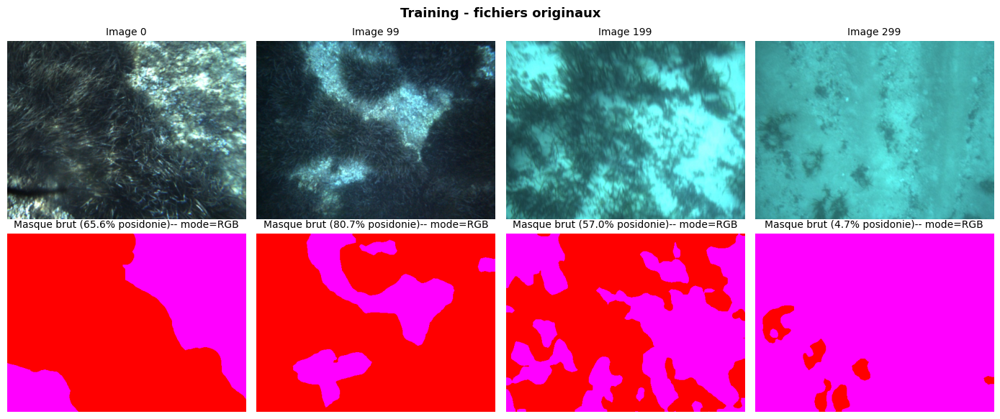

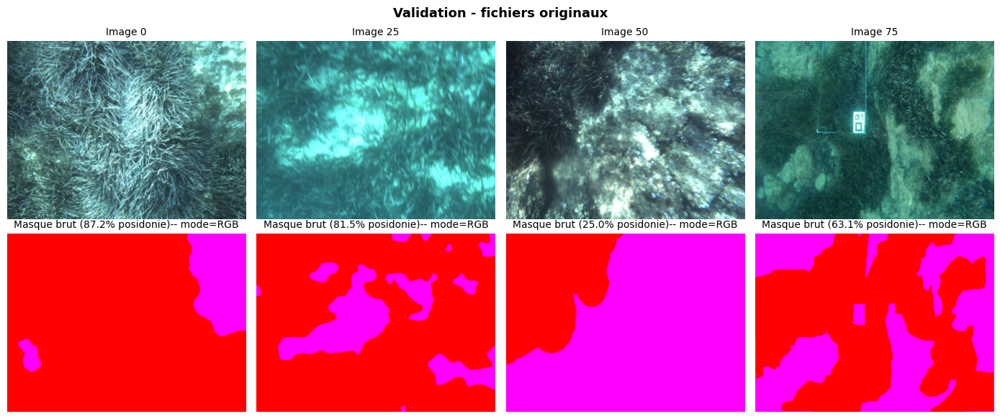

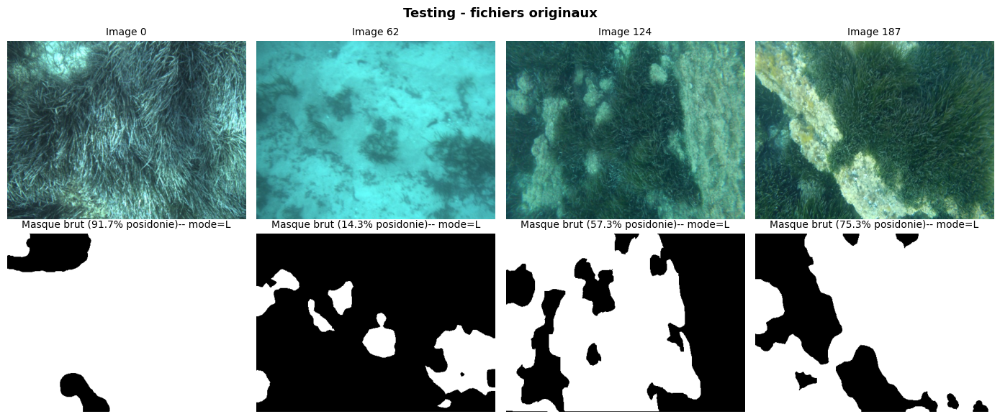

In [17]:
# === VISUALISATION D'ÉCHANTILLONS BRUTS SANS TRANSFORMATION ===

import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image



# === CONSTRUCTION ROBUSTE DES CHEMINS IMAGE/MASQUE TRAIN/VAL/TEST ===

import os
import glob



def get_name_column(df):
    """
    Trouve automatiquement la colonne qui contient le chemin ou le nom de l'image.
    """
    possible_cols = [
        "image_path", "img_path", "path",
        "image", "image_name", "img", "img_name",
        "filename", "file_name", "name", "id",
        "base_name", "basename"
    ]

    for col in possible_cols:
        if col in df.columns:
            return col

    print("Colonnes disponibles dans df :")
    print(df.columns.tolist())
    raise ValueError("Impossible de trouver la colonne contenant le nom ou chemin des images.")


def clean_filename(name):
    """
    Nettoie un nom provenant du CSV.
    Exemple :
    C:\\...\\valldemossa_crop000454.png -> valldemossa_crop000454
    """
    name = str(name)
    name = name.replace("\\", "/")
    filename = os.path.basename(name)
    base_name = os.path.splitext(filename)[0]
    return base_name


def detect_image_files(img_dir):
    """
    Détecte automatiquement les fichiers images présents dans un dossier.
    """
    extensions = ["*.png", "*.jpg", "*.jpeg", "*.tif", "*.tiff", "*.bmp"]

    image_paths = []
    for ext in extensions:
        image_paths.extend(glob.glob(os.path.join(img_dir, ext)))
        image_paths.extend(glob.glob(os.path.join(img_dir, ext.upper())))

    return sorted(image_paths)


def find_mask_path(mask_dir, base_name):
    """
    Trouve automatiquement le masque correspondant à une image.
    Gère les cas :
    - image.png -> image_gt.png
    - image.png -> image.png
    - image.png -> image_mask.png
    """

    possible_suffixes = ["_gt", "_mask", ""]
    possible_exts = [".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"]

    for suffix in possible_suffixes:
        for ext in possible_exts:
            candidate = os.path.join(mask_dir, base_name + suffix + ext)
            if os.path.exists(candidate):
                return candidate

    raise FileNotFoundError(
        f"Masque introuvable pour {base_name} dans {mask_dir}"
    )


def build_raw_paths_from_dataset(dataset):
    """
    Reconstruit les chemins image/masque.

    Cas 1 : train/val depuis CSV avec dataset.df.
    Cas 2 : test depuis dossier direct sans dataset.df.
    """

    image_paths = []
    mask_paths = []

    # =====================================================
    # CAS 1 : train / validation avec CSV stratifié
    # =====================================================
    if hasattr(dataset, "df"):
        df = dataset.df
        name_col = get_name_column(df)

        for name in df[name_col].tolist():
            base_name = clean_filename(name)

            # On utilise les extensions si elles existent,
            # sinon on détecte le fichier directement.
            if hasattr(dataset, "img_ext"):
                img_path = os.path.join(dataset.img_dir, base_name + dataset.img_ext)
            else:
                img_path = None
                for candidate in detect_image_files(dataset.img_dir):
                    if os.path.splitext(os.path.basename(candidate))[0] == base_name:
                        img_path = candidate
                        break

            if img_path is None or not os.path.exists(img_path):
                raise FileNotFoundError(
                    f"Image introuvable pour {base_name} dans {dataset.img_dir}"
                )

            if hasattr(dataset, "mask_suffix") and hasattr(dataset, "mask_ext"):
                mask_path = os.path.join(
                    dataset.mask_dir,
                    base_name + dataset.mask_suffix + dataset.mask_ext
                )

                if not os.path.exists(mask_path):
                    mask_path = find_mask_path(dataset.mask_dir, base_name)
            else:
                mask_path = find_mask_path(dataset.mask_dir, base_name)

            image_paths.append(img_path)
            mask_paths.append(mask_path)

    # =====================================================
    # CAS 2 : testing sans CSV
    # =====================================================
    else:
        image_paths = detect_image_files(dataset.img_dir)

        if len(image_paths) == 0:
            raise FileNotFoundError(
                f"Aucune image trouvée dans {dataset.img_dir}"
            )

        for img_path in image_paths:
            filename = os.path.basename(img_path)
            base_name = os.path.splitext(filename)[0]

            mask_path = find_mask_path(dataset.mask_dir, base_name)

            mask_paths.append(mask_path)

    return image_paths, mask_paths

def compute_posidonia_coverage(mask_np, dataset):
    """
    Calcule le pourcentage de posidonie selon le format du masque.

    Training / Validation :
        rouge = posidonie
        magenta = fond

    Testing :
        blanc = posidonie
        noir = fond
    """

    # Cas masque RGB : training / validation
    if mask_np.ndim == 3:
        r = mask_np[:, :, 0]
        g = mask_np[:, :, 1]
        b = mask_np[:, :, 2]

        # Posidonie = rouge
        # On utilise une condition robuste au lieu de RGB exactement [255, 0, 0]
        posidonia_pixels = (r > 200) & (g < 80) & (b < 80)

        coverage = posidonia_pixels.mean() * 100
        return coverage

    # Cas masque niveaux de gris : testing
    elif mask_np.ndim == 2:
        # Posidonie = blanc
        posidonia_pixels = mask_np > 127

        coverage = posidonia_pixels.mean() * 100
        return coverage

    else:
        return np.nan


# === VISUALISATION D'ÉCHANTILLONS BRUTS EN CONSERVANT LES COULEURS D'ORIGINE ===


def visualize_raw_dataset_samples(dataset, n_samples=4, title="Échantillons bruts"):
    """
    Affiche directement les fichiers image/masque d'origine.
    Aucune normalisation, aucune binarisation, aucune recoloration.

    Le pourcentage de posidonie est calculé selon le format du masque :
    - RGB : rouge = posidonie, magenta = fond
    - niveaux de gris : blanc = posidonie, noir = fond
    """

    image_paths, mask_paths = build_raw_paths_from_dataset(dataset)

    fig, axes = plt.subplots(2, n_samples, figsize=(n_samples * 3.5, 6))

    n_total = len(image_paths)
    indices = np.linspace(0, n_total - 1, n_samples).astype(int)

    for col, idx in enumerate(indices):
        img_path = image_paths[idx]
        mask_path = mask_paths[idx]

        img = Image.open(img_path)
        mask = Image.open(mask_path)

        mask_np = np.array(mask)

        # Calcul correct du taux de posidonie
        coverage = compute_posidonia_coverage(mask_np, dataset)

        # Affichage image brute
        axes[0, col].imshow(img)
        axes[0, col].set_title(f"Image {idx}", fontsize=10)
        axes[0, col].axis("off")

        # Affichage masque brut
        if mask_np.ndim == 2:
            # Testing : masque noir/blanc
            axes[1, col].imshow(mask_np, cmap="gray", vmin=0, vmax=255)
        else:
            # Training / validation : masque RGB rouge/magenta
            axes[1, col].imshow(mask)

        axes[1, col].set_title(
            f"Masque brut ({coverage:.1f}% posidonie)-- mode={mask.mode}",
            fontsize=10
        )
        axes[1, col].axis("off")

    fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

    return fig


fig_train = visualize_raw_dataset_samples(
    train_ds,
    n_samples=4,
    title="Training - fichiers originaux"
)

fig_val = visualize_raw_dataset_samples(
    val_ds,
    n_samples=4,
    title="Validation - fichiers originaux"
)

fig_test = visualize_raw_dataset_samples(
    test_ds,
    n_samples=4,
    title="Testing - fichiers originaux"
)

Confirmation des hypothèses concernant la binarisation des couleurs qu'on s'est fixé dans le script plus haut

Notre hypothèse est bonne (la A). Nous allons donc continuer

## 1.6 Statistiques de distribution

Calcul de la distribution des taux de couverture de posidonie dans chaque dataset. Pour vérifier que la stratification est respectée.

=== Calcul des statistiques de couverture ===

  Calcul des taux de couverture pour Train...


  Calcul des taux de couverture pour Val...


  Calcul des taux de couverture pour Test...



=== Résumé des distributions ===

Dataset      N     Moy.      Std      Min      Max    Médiane
------------------------------------------------------------
Train      300   43.52%   29.03%    0.00%  100.00%     45.73%
Val         76   44.18%   29.01%    0.00%  100.00%     46.00%
Test        94   44.77%   30.33%    0.00%  100.00%     45.57%


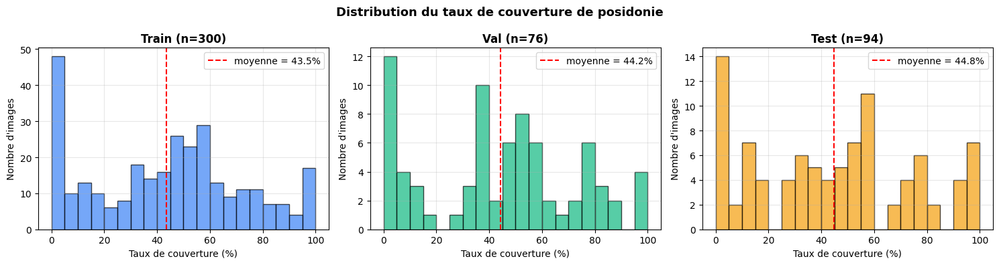


 Les distributions sont cohérentes entre train, val et test


In [18]:
# === STATISTIQUES DE DISTRIBUTION ===

def compute_coverage_stats(dataset, name):
    """Calcule et affiche les statistiques de couverture du dataset."""
    coverages = []
    print(f"  Calcul des taux de couverture pour {name}...")
    for i in tqdm(range(len(dataset)), leave=False):
        _, mask = dataset[i]
        coverages.append(mask.float().mean().item())

    coverages = np.array(coverages)
    return {
        'name': name,
        'n': len(coverages),
        'mean': coverages.mean(),
        'std': coverages.std(),
        'min': coverages.min(),
        'max': coverages.max(),
        'median': np.median(coverages),
        'values': coverages,
    }


print("=== Calcul des statistiques de couverture ===\n")
stats_train = compute_coverage_stats(train_ds, "Train")
stats_val   = compute_coverage_stats(val_ds, "Val")
stats_test  = compute_coverage_stats(test_ds, "Test")

# Affichage tabulaire
print("\n=== Résumé des distributions ===\n")
print(f"{'Dataset':<8} {'N':>5} {'Moy.':>8} {'Std':>8} {'Min':>8} {'Max':>8} {'Médiane':>10}")
print("-" * 60)
for s in [stats_train, stats_val, stats_test]:
    print(f"{s['name']:<8} {s['n']:>5} "
          f"{s['mean']*100:>7.2f}% {s['std']*100:>7.2f}% "
          f"{s['min']*100:>7.2f}% {s['max']*100:>7.2f}% "
          f"{s['median']*100:>9.2f}%")

# Visualisation des distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, s, color in zip(axes,
                          [stats_train, stats_val, stats_test],
                          ['#3b82f6', '#10b981', '#f59e0b']):
    ax.hist(s['values'] * 100, bins=20, color=color, alpha=0.7, edgecolor='black')
    ax.axvline(s['mean'] * 100, color='red', linestyle='--', label=f"moyenne = {s['mean']*100:.1f}%")
    ax.set_title(f"{s['name']} (n={s['n']})", fontsize=12, fontweight='bold')
    ax.set_xlabel("Taux de couverture (%)")
    ax.set_ylabel("Nombre d'images")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Distribution du taux de couverture de posidonie", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n Les distributions sont cohérentes entre train, val et test")

# 2. Prétraitement et augmentation

## 2.1 Pourquoi étudier le prétraitement des images sous-marines ?

La segmentation de *Posidonia oceanica* est particulièrement difficile en raison des conditions d'acquisition propres au milieu sous-marin. Les images peuvent présenter plusieurs dégradations et ambiguïtés visuelles susceptibles de compliquer la distinction entre la Posidonie et le fond marin.

| Difficulté | Manifestation dans l'image | Impact potentiel sur la segmentation |
|---|---|---|
| **Atténuation des couleurs** | Perte progressive des composantes colorimétriques, notamment du rouge avec la profondeur | Modification de l'apparence naturelle de la végétation et diminution de la fiabilité de la couleur comme indice de classification |
| **Faible contraste et variations d'éclairage** | Ombres, zones sous-exposées et différences importantes de luminosité au sein d'une même image | Frontières moins visibles et apparence variable d'une même classe |
| **Turbidité** | Particules en suspension qui diffusent la lumière et réduisent la netteté | Perte de détails et diminution de la visibilité des structures de la Posidonie |
| **Flou** | Contours et textures moins nets | Difficulté à localiser précisément les limites de l'herbier |
| **Similarité visuelle** | Posidonie, algues, sable, roches ou zones de végétation peu dense peuvent présenter des apparences proches | Risque de confusion entre la classe Posidonie et le fond marin |
| **Transitions ambiguës** | Passage parfois progressif entre les zones de Posidonie et l'arrière-plan | Incertitude accrue près des frontières, aussi bien pour l'annotation que pour la prédiction |

Ces difficultés montrent que la segmentation ne peut pas reposer uniquement sur la couleur. Le modèle doit apprendre des caractéristiques plus robustes, notamment **les textures, les contours, les structures spatiales et le contexte global de l'image**.

### Approches de prétraitement étudiées dans la littérature

Plusieurs méthodes ont été proposées pour améliorer la qualité des images sous-marines avant leur analyse :

- **Égalisation locale du contraste (CLAHE)** ;
- **Filtrage homomorphique** pour corriger les variations d'illumination ;
- **Débruitage par ondelettes** ;
- **Filtrage anisotropique** ;
- **Expansion dynamique et égalisation des canaux RGB** ;
- **Pipelines composites d'amélioration d'images sous-marines**.

### Démarche adoptée dans ce notebook

L'objectif n'est pas de supposer qu'un prétraitement améliore nécessairement la segmentation, mais de **vérifier expérimentalement son influence sur les performances du modèle**.

Le pipeline est donc conçu de manière **modulaire**, à l'aide d'un système de *registry*, afin de pouvoir activer, comparer ou ajouter facilement différentes méthodes de prétraitement.

Les configurations étudiées comprennent notamment :

- **Aucun prétraitement externe** ;
- **CLAHE** ;
- **Expansion dynamique RGB + égalisation**.

Les performances obtenues permettront ensuite de déterminer si ces transformations apportent un bénéfice par rapport à l'utilisation des images originales.

## 2.2 Implémentation des méthodes de prétraitement

### 2.2.1 CLAHE (Contrast Limited Adaptive Histogram Equalization)

**Principe** : Égalise l'histogramme **localement** sur des tuiles (par exemple 8x8),
avec une **limite de contraste** pour éviter d'amplifier le bruit.

**Application sur le canal L de l'espace LAB** :
- Permet de rehausser le contraste sans altérer les couleurs
- L = Lightness (luminance perceptuelle)
- A, B = composantes chromatiques (préservées)

**Effet attendu** : contraste local fortement augmenté, structures plus visibles.

In [19]:
# === CLAHE ===

def apply_clahe(img_rgb, clip_limit=3.0, tile_grid_size=(8, 8)):
    """
    Égalisation locale du contraste (CLAHE) sur le canal L de LAB.

    Args:
        img_rgb : np.ndarray [H, W, 3] uint8 RGB
        clip_limit : seuil de limitation du contraste (default 3.0)
        tile_grid_size : taille de la grille de tuiles (default 8x8)

    Returns:
        np.ndarray [H, W, 3] uint8 RGB avec contraste local rehaussé

    Référence : Pizer et al. (1987), Zuiderveld (1994).
    """
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    lab[:, :, 0] = clahe.apply(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


# Test rapide
print("=== Test apply_clahe ===")
test_img = np.random.randint(0, 255, (100, 100, 3), dtype=np.uint8)
result = apply_clahe(test_img)
print(f"  Input shape  : {test_img.shape}, dtype : {test_img.dtype}")
print(f"  Output shape : {result.shape}, dtype : {result.dtype}")
print(f"  apply_clahe opérationnelle")

=== Test apply_clahe ===
  Input shape  : (100, 100, 3), dtype : uint8
  Output shape : (100, 100, 3), dtype : uint8
  apply_clahe opérationnelle


### 2.2.2 Expansion dynamique + égalisation des moyennes RGB

**Principe** en deux étapes :

1. **Expansion dynamique** : pour chaque canal R/G/B, on étire les valeurs entre
   les percentiles `[low, high]` (typiquement [1, 99]) vers la plage complète [0, 255].
   -> Utilise toute la plage dynamique disponible.

2. **Égalisation des moyennes RGB** : on ajuste chaque canal pour qu'il ait la
   même moyenne globale.
   -> Atténue la dominante de couleur (bleu-vert en sous-marin).

**Effet attendu** : transformation visuelle radicale, dominante bleue supprimée,
le sable apparaît presque blanc.

**Référence** : étape 4 du pipeline de Bazeille et al. (2006).

In [20]:
# === EXPANSION DYNAMIQUE + ÉGALISATION RGB ===

def dynamic_expansion_rgb_eq(img_rgb, percentile_low=1, percentile_high=99):
    """
    Expansion dynamique par canal + égalisation des moyennes RGB.

    Étape 1 : étire chaque canal entre [percentile_low, percentile_high] vers [0, 255]
    Étape 2 : ajuste chaque canal pour avoir la même moyenne (supprime dominante couleur)

    Args:
        img_rgb : np.ndarray [H, W, 3] uint8 RGB
        percentile_low : percentile bas pour l'étirement (default 1)
        percentile_high : percentile haut pour l'étirement (default 99)

    Returns:
        np.ndarray [H, W, 3] uint8 RGB avec contraste maximisé et couleur neutralisée

    Référence : Bazeille et al. (2006).
    """
    img_out = img_rgb.astype(np.float32).copy()

    # === Étape 1 : expansion dynamique par canal ===
    for ch in range(3):
        low = np.percentile(img_out[:, :, ch], percentile_low)
        high = np.percentile(img_out[:, :, ch], percentile_high)
        if high > low:
            img_out[:, :, ch] = (img_out[:, :, ch] - low) / (high - low) * 255
            img_out[:, :, ch] = np.clip(img_out[:, :, ch], 0, 255)

    # === Étape 2 : égalisation des moyennes RGB ===
    target_mean = img_out.mean()  # moyenne globale = cible commune
    for ch in range(3):
        ch_mean = img_out[:, :, ch].mean()
        if ch_mean > 0:
            img_out[:, :, ch] *= (target_mean / ch_mean)

    img_out = np.clip(img_out, 0, 255)
    return img_out.astype(np.uint8)


# Test rapide
print("=== Test dynamic_expansion_rgb_eq ===")
# Image avec dominante bleue artificielle
test_img = np.zeros((100, 100, 3), dtype=np.uint8)
test_img[:, :, 0] = 50   # R faible
test_img[:, :, 1] = 100  # G moyen
test_img[:, :, 2] = 200  # B fort (dominante bleue)
result = dynamic_expansion_rgb_eq(test_img)
print(f"  Moyennes avant : R={test_img[..., 0].mean():.1f}, G={test_img[..., 1].mean():.1f}, B={test_img[..., 2].mean():.1f}")
print(f"  Moyennes après : R={result[..., 0].mean():.1f}, G={result[..., 1].mean():.1f}, B={result[..., 2].mean():.1f}")
print(f"  Les canaux convergent vers une moyenne commune (couleur neutralisée)")

=== Test dynamic_expansion_rgb_eq ===
  Moyennes avant : R=50.0, G=100.0, B=200.0
  Moyennes après : R=116.0, G=116.0, B=116.0
  Les canaux convergent vers une moyenne commune (couleur neutralisée)


## 2.3 Registry des méthodes de prétraitement

Pour rendre le pipeline **extensible**, on utilise un **dictionnaire-registry**
qui mappe les noms de méthodes vers leurs fonctions.

**Avantages** :
- Ajouter une méthode = ajouter une ligne dans le registry
- Détection automatique des noms invalides (typos)
- Code des classes Dataset ne change jamais

**Convention de signature** :
```python
def ma_methode(img_rgb: np.ndarray) -> np.ndarray:
    """Reçoit RGB uint8 [H, W, 3], retourne RGB uint8 [H, W, 3]."""
    ...
```

In [21]:
# === REGISTRY DES MÉTHODES DE PRÉTRAITEMENT ===

PREPROCESS_REGISTRY = {
    "none":          lambda img: img,              # identité (aucun prétraitement)
    "clahe":         apply_clahe,
    "expansion_rgb": dynamic_expansion_rgb_eq,
    # ┌────────────────────────────────────────────────────────────────┐
    # │ POUR AJOUTER UNE NOUVELLE MÉTHODE DE PRÉTRAITEMENT :            │
    # │                                                                 │
    # │ 1. Définir la fonction au-dessus, avec la signature standard :  │
    # │    def ma_methode(img_rgb):                                     │
    # │        ...                                                      │
    # │        return img_processed  # même shape, même dtype           │
    # │                                                                 │
    # │ 2. Ajouter ici une entrée dans le registry :                    │
    # │    "ma_methode": ma_methode,                                    │
    # │                                                                 │
    # │ 3. C'est tout ! Aucune autre modification nécessaire.           │
    # └────────────────────────────────────────────────────────────────┘
    # Méthodes prévues :
    # "homomorphic":  homomorphic_filter,
    # "wavelet":      wavelet_denoise,
    # "anisotropic":  anisotropic_filter,
    # "bazeille":     bazeille_pipeline,
}


def apply_preprocess(img_pil, preprocess_name):
    """
    Applique un prétraitement à une image PIL via le registry.

    Gère la conversion PIL ↔ numpy en interne.

    Args:
        img_pil : PIL.Image (entrée)
        preprocess_name : str ou None, nom de la méthode dans le registry

    Returns:
        PIL.Image (prétraitée si nom valide, identique si None ou "none")

    Raises:
        ValueError : si preprocess_name n'est pas dans le registry
    """
    if preprocess_name is None or preprocess_name == "none":
        return img_pil

    if preprocess_name not in PREPROCESS_REGISTRY:
        available = list(PREPROCESS_REGISTRY.keys())
        raise ValueError(
            f"Prétraitement '{preprocess_name}' inconnu. "
            f"Méthodes disponibles : {available}"
        )

    preprocess_fn = PREPROCESS_REGISTRY[preprocess_name]
    img_np = np.array(img_pil)
    img_np = preprocess_fn(img_np)
    return Image.fromarray(img_np)


# Affichage du registry
print("=== Registry des prétraitements ===")
for name in PREPROCESS_REGISTRY.keys():
    print(f"  - '{name}'")
print(f"\n {len(PREPROCESS_REGISTRY)} méthodes disponibles")

# Test que la validation marche
print("\n=== Test de la validation ===")
test_pil = Image.fromarray(np.random.randint(0, 255, (50, 50, 3), dtype=np.uint8))
try:
    apply_preprocess(test_pil, "typo_inexistant")
    print("  La validation devrait avoir échoué")
except ValueError as e:
    print(f"  Validation OK : {e}")

=== Registry des prétraitements ===
  - 'none'
  - 'clahe'
  - 'expansion_rgb'

 3 méthodes disponibles

=== Test de la validation ===
  Validation OK : Prétraitement 'typo_inexistant' inconnu. Méthodes disponibles : ['none', 'clahe', 'expansion_rgb']


## 2.4 Mise à jour des classes Dataset pour utiliser le registry

On **redéfinit** maintenant les classes `PosidoniaDatasetFromCSV` et `PosidoniaDataset`
pour utiliser `apply_preprocess` au lieu du `if self.preprocess == "clahe"` codé en dur.

**Avantage** : ces nouvelles versions des classes supportent **tous** les prétraitements
du registry, sans modification du code.

In [22]:
# === MISE À JOUR DE PosidoniaDatasetFromCSV ===
# Cette version utilise le registry et est extensible.

class PosidoniaDatasetFromCSV(Dataset):
    """
    Dataset Posidonia chargé depuis un CSV.

    Version avec registry extensible pour le prétraitement.

    Prétraitement (paramètre `preprocess`) : voir PREPROCESS_REGISTRY pour
    la liste des méthodes disponibles. Pour ajouter une nouvelle méthode,
    voir le commentaire dans la définition du registry.
    """

    def __init__(self, csv_path, root_path, split="training",
                 img_h=IMG_H, img_w=IMG_W,
                 augment=False, preprocess=None):
        # Validation du paramètre preprocess via le registry
        if preprocess is not None and preprocess != "none":
            if preprocess not in PREPROCESS_REGISTRY:
                available = list(PREPROCESS_REGISTRY.keys())
                raise ValueError(
                    f"Prétraitement '{preprocess}' inconnu. "
                    f"Méthodes disponibles : {available}"
                )

        self.df = pd.read_csv(csv_path)
        self.root_path = root_path
        self.split = split
        self.img_h = img_h
        self.img_w = img_w
        self.augment = augment
        self.preprocess = preprocess

        # Chemins
        self.img_dir  = os.path.join(root_path, split, "images")
        self.mask_dir = os.path.join(root_path, split, "gt_images")

        # Détection automatique des extensions et suffixe
        img_files  = os.listdir(self.img_dir)
        mask_files = os.listdir(self.mask_dir)
        self.img_ext     = detect_extension(img_files,  "image")
        self.mask_ext    = detect_extension(mask_files, "mask")
        self.mask_suffix = detect_mask_suffix(img_files, mask_files)

        # Transformations
        self.resize_img  = transforms.Resize((img_h, img_w),
                                               interpolation=transforms.InterpolationMode.BILINEAR)
        self.resize_mask = transforms.Resize((img_h, img_w),
                                               interpolation=transforms.InterpolationMode.NEAREST)
        self.to_tensor   = transforms.ToTensor()

        print(f"  [{split}/CSV] image_ext={self.img_ext}, mask_ext={self.mask_ext}, "
              f"mask_suffix='{self.mask_suffix}', preprocess={self.preprocess}")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        name = self.df.iloc[idx]['name']
        img_path  = os.path.join(self.img_dir,  name + self.img_ext)
        mask_path = os.path.join(self.mask_dir, name + self.mask_suffix + self.mask_ext)

        img  = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)

        img  = self.resize_img(img)
        mask = self.resize_mask(mask)

        # === Augmentation (avant prétraitement) ===
        if self.augment and self.split == "training":
            # Flips géométriques (cohérents image + masque)
            if np.random.rand() < 0.5:
                img  = transforms.functional.hflip(img)
                mask = transforms.functional.hflip(mask)
            if np.random.rand() < 0.3:
                img  = transforms.functional.vflip(img)
                mask = transforms.functional.vflip(mask)

            # Augmentation photométrique : douce si prétraitement actif
            if self.preprocess and self.preprocess != "none":
                img = transforms.ColorJitter(brightness=0.2)(img)
            else:
                img = transforms.ColorJitter(brightness=0.3, contrast=0.3)(img)

        # === Prétraitement via le registry (extensible) ===
        img = apply_preprocess(img, self.preprocess)

        # === Conversion masque selon le format ===
        if self.split == "training":
            mask_np = rgb_mask_to_class(mask)
        else:
            mask_np = grayscale_mask_to_class(mask)

        img_tensor  = self.to_tensor(img)
        mask_tensor = torch.from_numpy(mask_np).long()

        return img_tensor, mask_tensor


print(" PosidoniaDatasetFromCSV redéfinie avec registry extensible")

 PosidoniaDatasetFromCSV redéfinie avec registry extensible


In [23]:
# === MISE À JOUR DE PosidoniaDataset ===

class PosidoniaDataset(Dataset):
    """
    Dataset Posidonia chargé directement depuis un dossier (sans CSV).
    Conçu pour le testing.

    Version avec registry extensible pour le prétraitement.
    """

    def __init__(self, root_path, split="testing",
                 img_h=IMG_H, img_w=IMG_W,
                 augment=False, preprocess=None):
        # Validation du paramètre preprocess
        if preprocess is not None and preprocess != "none":
            if preprocess not in PREPROCESS_REGISTRY:
                available = list(PREPROCESS_REGISTRY.keys())
                raise ValueError(
                    f"Prétraitement '{preprocess}' inconnu. "
                    f"Méthodes disponibles : {available}"
                )

        self.root_path = root_path
        self.split = split
        self.img_h = img_h
        self.img_w = img_w
        self.augment = augment
        self.preprocess = preprocess

        # Chemins
        self.img_dir  = os.path.join(root_path, split, "images")
        self.mask_dir = os.path.join(root_path, split, "gt_images")

        # Liste des images
        self.image_files = sorted([
            f for f in os.listdir(self.img_dir)
            if f.lower().endswith(('.png', '.jpg', '.jpeg'))
        ])

        # Détection automatique du suffixe
        mask_files = os.listdir(self.mask_dir)
        self.mask_ext    = detect_extension(mask_files, "mask")
        self.mask_suffix = detect_mask_suffix(self.image_files, mask_files)

        # Transformations
        self.resize_img  = transforms.Resize((img_h, img_w),
                                               interpolation=transforms.InterpolationMode.BILINEAR)
        self.resize_mask = transforms.Resize((img_h, img_w),
                                               interpolation=transforms.InterpolationMode.NEAREST)
        self.to_tensor   = transforms.ToTensor()

        print(f"  [{split}/dir] mask_ext={self.mask_ext}, mask_suffix='{self.mask_suffix}', "
              f"preprocess={self.preprocess}")

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_name = self.image_files[idx]
        img_path = os.path.join(self.img_dir, img_name)

        base_name = os.path.splitext(img_name)[0]
        mask_path = os.path.join(self.mask_dir, base_name + self.mask_suffix + self.mask_ext)

        if not os.path.exists(mask_path):
            raise FileNotFoundError(
                f"Masque introuvable : {mask_path}\n"
                f"   (image source : {img_name})\n"
                f"   Suffixe détecté : '{self.mask_suffix}'"
            )

        img  = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)

        img  = self.resize_img(img)
        mask = self.resize_mask(mask)

        # === Prétraitement via le registry (extensible) ===
        img = apply_preprocess(img, self.preprocess)

        # === Conversion masque (testing : toujours grayscale) ===
        mask_np = grayscale_mask_to_class(mask)

        img_tensor  = self.to_tensor(img)
        mask_tensor = torch.from_numpy(mask_np).long()

        return img_tensor, mask_tensor


print(" PosidoniaDataset redéfinie avec registry extensible")

 PosidoniaDataset redéfinie avec registry extensible


## 2.5 Stratégies d'augmentation

L'augmentation de données génère de la variation artificielle pour améliorer
la **généralisation** du modèle. On définit **trois stratégies** comparables
en intensité.

### Principes

1. **Augmentations géométriques** (flips, rotations) : appliquées de manière
   **cohérente** à l'image ET au masque.
2. **Augmentations photométriques** (brightness, contrast, saturation, hue) :
   appliquées **uniquement à l'image** (le masque ne change pas).
3. **Ordre des opérations** : augmentation **avant** prétraitement pour éviter
   les conflits (par exemple jitter de contraste avant CLAHE).

### Stratégies définies

| Stratégie | Flips H/V | Photométrique | Autres |
|---|---|---|---|
| **minimal** | H (50%) | aucun | aucun |
| **standard** | H (50%) + V (30%) | brightness ± 0.3, contrast ± 0.3 | aucun |
| **fort** | H (50%) + V (30%) | brightness ± 0.3, contrast ± 0.3, saturation ± 0.2 | rotation ± 10° |

**Note** : la stratégie "standard" suit la méthodologie de Martin-Abadal et al. (2018).

In [24]:
# === STRATÉGIES D'AUGMENTATION ===

# Probabilités fixées (pas de paramètres pour rester simple)
AUG_STRATEGIES = {
    "minimal": {
        "hflip_prob": 0.5,
        "vflip_prob": 0.0,
        "rotation_deg": 0,
        "brightness": 0.0,
        "contrast": 0.0,
        "saturation": 0.0,
    },
    "standard": {
        "hflip_prob": 0.5,
        "vflip_prob": 0.3,
        "rotation_deg": 0,
        "brightness": 0.3,
        "contrast": 0.3,
        "saturation": 0.0,
    },
    "fort": {
        "hflip_prob": 0.5,
        "vflip_prob": 0.3,
        "rotation_deg": 10,
        "brightness": 0.3,
        "contrast": 0.3,
        "saturation": 0.2,
    },
}


def apply_augmentation(img, mask, strategy="standard", preprocess=None):
    """
    Applique une stratégie d'augmentation à une paire (image, masque).

    Args:
        img : PIL.Image (RGB)
        mask : PIL.Image (le masque, sera transformé géométriquement de manière cohérente)
        strategy : nom de la stratégie dans AUG_STRATEGIES
        preprocess : nom du prétraitement à venir (pour adapter le jitter)

    Returns:
        (img_aug, mask_aug) : tuple de PIL.Image après augmentation
    """
    if strategy not in AUG_STRATEGIES:
        available = list(AUG_STRATEGIES.keys())
        raise ValueError(
            f"Stratégie '{strategy}' inconnue. Disponibles : {available}"
        )

    params = AUG_STRATEGIES[strategy]

    # === Augmentations géométriques (cohérentes image + masque) ===
    if params["hflip_prob"] > 0 and np.random.rand() < params["hflip_prob"]:
        img  = transforms.functional.hflip(img)
        mask = transforms.functional.hflip(mask)

    if params["vflip_prob"] > 0 and np.random.rand() < params["vflip_prob"]:
        img  = transforms.functional.vflip(img)
        mask = transforms.functional.vflip(mask)

    if params["rotation_deg"] > 0:
        angle = np.random.uniform(-params["rotation_deg"], params["rotation_deg"])
        img  = transforms.functional.rotate(img, angle, interpolation=transforms.InterpolationMode.BILINEAR)
        mask = transforms.functional.rotate(mask, angle, interpolation=transforms.InterpolationMode.NEAREST)

    # === Augmentations photométriques (image uniquement) ===
    # Si prétraitement actif, on réduit l'intensité pour éviter les conflits
    if preprocess and preprocess != "none":
        brightness = min(params["brightness"], 0.2)
        contrast = 0.0  # désactivé car peut conflituer avec CLAHE/expansion
        saturation = 0.0
    else:
        brightness = params["brightness"]
        contrast = params["contrast"]
        saturation = params["saturation"]

    if brightness > 0 or contrast > 0 or saturation > 0:
        jitter = transforms.ColorJitter(
            brightness=brightness,
            contrast=contrast,
            saturation=saturation,
        )
        img = jitter(img)

    return img, mask


# Test rapide
print("=== Test des stratégies d'augmentation ===")
for strategy in AUG_STRATEGIES.keys():
    print(f"\n  Stratégie '{strategy}' :")
    for key, val in AUG_STRATEGIES[strategy].items():
        print(f"    {key:<16} : {val}")

=== Test des stratégies d'augmentation ===

  Stratégie 'minimal' :
    hflip_prob       : 0.5
    vflip_prob       : 0.0
    rotation_deg     : 0
    brightness       : 0.0
    contrast         : 0.0
    saturation       : 0.0

  Stratégie 'standard' :
    hflip_prob       : 0.5
    vflip_prob       : 0.3
    rotation_deg     : 0
    brightness       : 0.3
    contrast         : 0.3
    saturation       : 0.0

  Stratégie 'fort' :
    hflip_prob       : 0.5
    vflip_prob       : 0.3
    rotation_deg     : 10
    brightness       : 0.3
    contrast         : 0.3
    saturation       : 0.2


### Intégration de la stratégie d'augmentation dans le Dataset

On met à jour `PosidoniaDatasetFromCSV` pour accepter un paramètre `aug_strategy`
qui choisit la stratégie d'augmentation à utiliser.

**Compatibilité descendante** : `augment=True` (ancien paramètre) utilise désormais
la stratégie "standard" par défaut.

In [25]:
# === MISE À JOUR FINALE DE PosidoniaDatasetFromCSV avec aug_strategy ===

class PosidoniaDatasetFromCSV(Dataset):
    """
    Dataset Posidonia avec registry de prétraitement et stratégies d'augmentation.

    Args:
        csv_path : chemin vers le CSV stratifié
        root_path : racine du dataset (contient training/ et testing/)
        split : "training" ou "testing"
        img_h, img_w : taille de redimensionnement
        augment : True/False (pour rétrocompatibilité)
        aug_strategy : nom de la stratégie d'augmentation ("minimal", "standard", "fort")
                       Utilisé uniquement si augment=True et split="training"
        preprocess : nom du prétraitement (voir PREPROCESS_REGISTRY)
    """

    def __init__(self, csv_path, root_path, split="training",
                 img_h=IMG_H, img_w=IMG_W,
                 augment=False, aug_strategy="standard", preprocess=None):
        # Validations
        if preprocess is not None and preprocess != "none":
            if preprocess not in PREPROCESS_REGISTRY:
                available = list(PREPROCESS_REGISTRY.keys())
                raise ValueError(f"Prétraitement '{preprocess}' inconnu. Disponibles : {available}")

        if augment and aug_strategy not in AUG_STRATEGIES:
            available = list(AUG_STRATEGIES.keys())
            raise ValueError(f"Stratégie '{aug_strategy}' inconnue. Disponibles : {available}")

        self.df = pd.read_csv(csv_path)
        self.root_path = root_path
        self.split = split
        self.img_h = img_h
        self.img_w = img_w
        self.augment = augment
        self.aug_strategy = aug_strategy
        self.preprocess = preprocess

        # Chemins et détection automatique
        self.img_dir  = os.path.join(root_path, split, "images")
        self.mask_dir = os.path.join(root_path, split, "gt_images")
        img_files  = os.listdir(self.img_dir)
        mask_files = os.listdir(self.mask_dir)
        self.img_ext     = detect_extension(img_files,  "image")
        self.mask_ext    = detect_extension(mask_files, "mask")
        self.mask_suffix = detect_mask_suffix(img_files, mask_files)

        # Transformations PyTorch
        self.resize_img  = transforms.Resize((img_h, img_w),
                                               interpolation=transforms.InterpolationMode.BILINEAR)
        self.resize_mask = transforms.Resize((img_h, img_w),
                                               interpolation=transforms.InterpolationMode.NEAREST)
        self.to_tensor   = transforms.ToTensor()

        # Affichage
        aug_str = f"aug='{self.aug_strategy}'" if augment else "aug=False"
        print(f"  [{split}/CSV] preprocess={self.preprocess}, {aug_str}, "
              f"images={len(self.df)}")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        name = self.df.iloc[idx]['name']
        img_path  = os.path.join(self.img_dir,  name + self.img_ext)
        mask_path = os.path.join(self.mask_dir, name + self.mask_suffix + self.mask_ext)

        img  = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)

        img  = self.resize_img(img)
        mask = self.resize_mask(mask)

        # === Augmentation (selon la stratégie) ===
        if self.augment and self.split == "training":
            img, mask = apply_augmentation(img, mask,
                                              strategy=self.aug_strategy,
                                              preprocess=self.preprocess)

        # === Prétraitement via le registry ===
        img = apply_preprocess(img, self.preprocess)

        # === Conversion masque ===
        if self.split == "training":
            mask_np = rgb_mask_to_class(mask)
        else:
            mask_np = grayscale_mask_to_class(mask)

        img_tensor  = self.to_tensor(img)
        mask_tensor = torch.from_numpy(mask_np).long()

        return img_tensor, mask_tensor


print(" PosidoniaDatasetFromCSV finalisée avec registry + stratégies d'augmentation")

 PosidoniaDatasetFromCSV finalisée avec registry + stratégies d'augmentation


**Commentaire**: Nous appliquons l'augmentation uniquement sur les données d'entrainement et de validation, les données de test subissent uniquement le pré-traitement et pas l'augmentation des données

## 2.6 Visualisations comparatives

Maintenant qu'on a tous les outils, on visualise :

1. **L'effet des méthodes de prétraitement** sur quelques images représentatives
2. **L'effet des stratégies d'augmentation** sur une même image (plusieurs tirages)

Ces visualisations seront utiles pour le rapport (compréhension visuelle des choix).

  [training/CSV] preprocess=None, aug=False, images=76


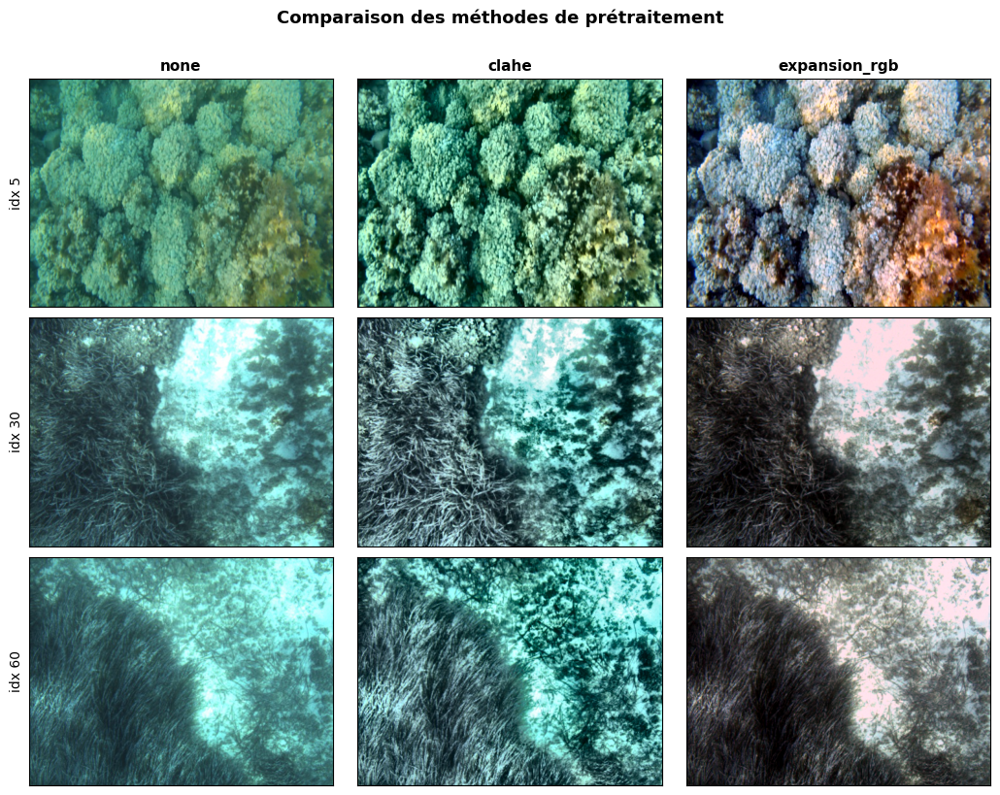

In [26]:
# === VISUALISATION DES MÉTHODES DE PRÉTRAITEMENT ===

def visualize_preprocessing_comparison(dataset, image_indices=None, n_samples=4):
    """
    Affiche une grille comparative des méthodes de prétraitement disponibles
    dans le registry.

    Args:
        dataset : dataset à utiliser (sans prétraitement)
        image_indices : liste d'indices d'images à visualiser. Si None, sélection auto.
        n_samples : nombre d'images si image_indices=None
    """
    if image_indices is None:
        image_indices = np.linspace(0, len(dataset) - 1, n_samples).astype(int)

    methods = list(PREPROCESS_REGISTRY.keys())
    n_methods = len(methods)
    n_images = len(image_indices)

    fig, axes = plt.subplots(n_images, n_methods,
                              figsize=(n_methods * 3.5, n_images * 2.7))

    if n_images == 1:
        axes = axes.reshape(1, -1)

    for row, idx in enumerate(image_indices):
        # Récupérer l'image RAW (sans prétraitement) via le dataset
        img_tensor, _ = dataset[idx]
        img_pil = transforms.functional.to_pil_image(img_tensor)

        for col, method in enumerate(methods):
            img_processed = apply_preprocess(img_pil, method)
            axes[row, col].imshow(np.array(img_processed))
            if row == 0:
                axes[row, col].set_title(method, fontsize=11, fontweight='bold')
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
            if col == 0:
                axes[row, col].set_ylabel(f"idx {idx}", fontsize=10)

    plt.suptitle("Comparaison des méthodes de prétraitement",
                  fontsize=13, fontweight='bold', y=1.005)
    plt.tight_layout()
    plt.show()


# Charger un dataset SANS prétraitement pour la visualisation
viz_ds = PosidoniaDatasetFromCSV(
    csv_path=VAL_CSV,
    root_path=LOCAL_PATH,
    split="training",
    augment=False,
    preprocess=None,
)

# Visualiser sur 3 images variées (faible/moyenne/forte couverture)
visualize_preprocessing_comparison(viz_ds, image_indices=[5, 30, 60])

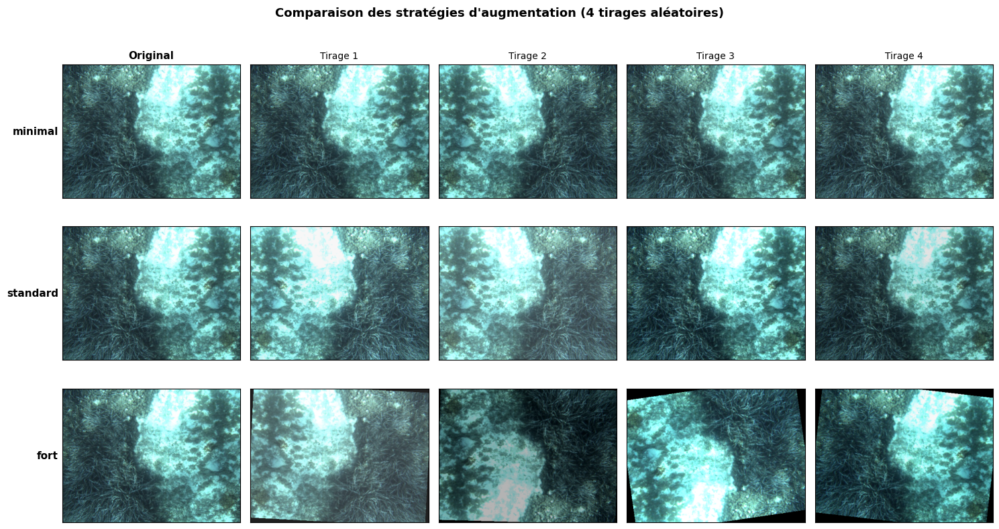

In [27]:
# === VISUALISATION DES STRATÉGIES D'AUGMENTATION ===

def visualize_augmentation_strategies(dataset, img_idx=0, n_examples=4):
    """
    Affiche l'effet de chaque stratégie d'augmentation sur une même image.
    Plusieurs tirages pour montrer la variabilité de l'augmentation.

    Args:
        dataset : dataset source (sans augmentation)
        img_idx : index de l'image à utiliser
        n_examples : nombre d'exemples par stratégie
    """
    strategies = list(AUG_STRATEGIES.keys())
    n_strategies = len(strategies)

    # +1 pour la colonne "original"
    fig, axes = plt.subplots(n_strategies, n_examples + 1,
                              figsize=((n_examples + 1) * 3, n_strategies * 2.7))

    # Image originale
    img_tensor, mask_tensor = dataset[img_idx]
    img_original_pil = transforms.functional.to_pil_image(img_tensor)
    mask_original_pil = Image.fromarray((mask_tensor.numpy() * 255).astype(np.uint8))

    for row, strategy in enumerate(strategies):
        # Colonne 0 : original
        axes[row, 0].imshow(np.array(img_original_pil))
        if row == 0:
            axes[row, 0].set_title("Original", fontsize=11, fontweight='bold')
        axes[row, 0].set_ylabel(strategy, fontsize=11, fontweight='bold', rotation=0,
                                  ha='right', va='center')
        axes[row, 0].set_xticks([])
        axes[row, 0].set_yticks([])

        # Colonnes suivantes : augmentations
        for col in range(1, n_examples + 1):
            img_aug, _ = apply_augmentation(img_original_pil, mask_original_pil,
                                              strategy=strategy)
            axes[row, col].imshow(np.array(img_aug))
            if row == 0:
                axes[row, col].set_title(f"Tirage {col}", fontsize=10)
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])

    plt.suptitle("Comparaison des stratégies d'augmentation (4 tirages aléatoires)",
                  fontsize=13, fontweight='bold', y=1.005)
    plt.tight_layout()
    plt.show()


# Visualiser sur une image variée
visualize_augmentation_strategies(viz_ds, img_idx=30, n_examples=4)

## 2.7 Test rapide d'une combinaison

Chargeons un dataset avec une **vraie combinaison** (augmentation + prétraitement)
pour vérifier que tout fonctionne ensemble.

  [training/CSV] preprocess=None, aug=False, images=300
  [training/CSV] preprocess=clahe, aug='standard', images=300
  [training/CSV] preprocess=expansion_rgb, aug='standard', images=300

=== Visualisation des combinaisons aug + prétraitement ===
Image testée : index 0 du training set



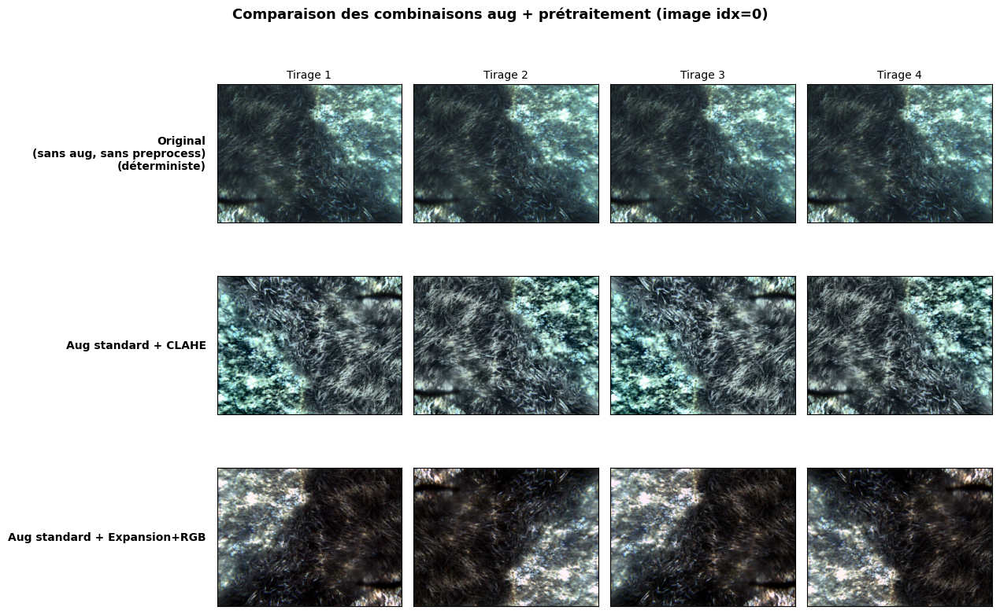


=== Observations attendues ===
   Original : 4 tirages identiques (déterministe, sans aug)
   Aug + CLAHE : variabilité (flips/jitter) + contraste local rehaussé
   Aug + Expansion+RGB : variabilité (flips/jitter) + dominante bleue supprimée

 Les deux combinaisons fonctionnent correctement

=== Section 2 terminée ===


In [28]:
# === TEST DES DEUX COMBINAISONS AUG + PRÉTRAITEMENT ===

TEST_IDX = 0  # index de l'image à utiliser

# Dataset SANS aug ni preprocess (pour l'image originale)
ds_original = PosidoniaDatasetFromCSV(
    csv_path=TRAIN_CSV,
    root_path=LOCAL_PATH,
    split="training",
    augment=False,
    preprocess=None,
)

# Combinaison 1 : aug standard + CLAHE
ds_combo_clahe = PosidoniaDatasetFromCSV(
    csv_path=TRAIN_CSV,
    root_path=LOCAL_PATH,
    split="training",
    augment=True,
    aug_strategy="standard",
    preprocess="clahe",
)

# Combinaison 2 : aug standard + Expansion+RGB
ds_combo_expansion = PosidoniaDatasetFromCSV(
    csv_path=TRAIN_CSV,
    root_path=LOCAL_PATH,
    split="training",
    augment=True,
    aug_strategy="standard",
    preprocess="expansion_rgb",
)

print(f"\n=== Visualisation des combinaisons aug + prétraitement ===")
print(f"Image testée : index {TEST_IDX} du training set\n")

# === Visualisation en grille 3 lignes × 4 colonnes ===
N_TIRAGES = 4

configurations = [
    ("Original\n(sans aug, sans preprocess)", ds_original,         False),
    ("Aug standard + CLAHE",                   ds_combo_clahe,      True),
    ("Aug standard + Expansion+RGB",            ds_combo_expansion,  True),
]

n_rows = len(configurations)
fig, axes = plt.subplots(n_rows, N_TIRAGES, figsize=(N_TIRAGES * 3.2, n_rows * 2.7))

for row, (title, ds, is_stochastic) in enumerate(configurations):
    for col in range(N_TIRAGES):
        img, mask = ds[TEST_IDX]
        img_np = img.permute(1, 2, 0).numpy()
        axes[row, col].imshow(img_np)

        # Titre uniquement sur la première ligne
        if row == 0:
            axes[row, col].set_title(f"Tirage {col + 1}", fontsize=10)

        # Étiquette à gauche (uniquement colonne 0)
        if col == 0:
            label_suffix = "" if is_stochastic else "\n(déterministe)"
            axes[row, col].set_ylabel(title + label_suffix, fontsize=10,
                                        rotation=0, ha='right', va='center',
                                        labelpad=10, fontweight='bold')

        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

plt.suptitle(f"Comparaison des combinaisons aug + prétraitement (image idx={TEST_IDX})",
              fontsize=13, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()

print("\n=== Observations attendues ===")
print("   Original : 4 tirages identiques (déterministe, sans aug)")
print("   Aug + CLAHE : variabilité (flips/jitter) + contraste local rehaussé")
print("   Aug + Expansion+RGB : variabilité (flips/jitter) + dominante bleue supprimée")
print("\n Les deux combinaisons fonctionnent correctement")
print("\n=== Section 2 terminée ===")

## 3.1 Architecture SegFormer

SegFormer (Xie et al., 2021) est une architecture de segmentation sémantique basée sur un **Transformer hiérarchique**.

Contrairement à U-Net et FCN-VGG16, qui reposent principalement sur des opérations convolutionnelles, SegFormer utilise des mécanismes d'**attention** permettant de modéliser à la fois les informations locales et les dépendances à plus longue portée dans l'image.

Cette propriété est particulièrement intéressante pour les images sous-marines, dans lesquelles l'identification de la Posidonie ne dépend pas uniquement de la couleur d'un pixel, mais également de sa **texture**, de sa **structure** et du **contexte spatial environnant**.

### Principe général

SegFormer se compose de deux parties principales :

1. **Encodeur MiT (Mix Transformer)**  
   L'encodeur est organisé en quatre niveaux hiérarchiques (*stages*).  
   À chaque niveau, la résolution spatiale diminue tandis que la richesse des représentations augmente.

   Il produit ainsi des cartes de caractéristiques à plusieurs échelles :

   - `1/4` de la résolution d'entrée ;
   - `1/8` ;
   - `1/16` ;
   - `1/32`.

   Le backbone MiT utilisé est pré-entraîné sur **ImageNet**.

2. **Décodeur léger All-MLP**  
   Les représentations produites aux quatre échelles sont projetées vers une dimension commune, redimensionnées à une résolution commune puis fusionnées.

   Contrairement à des architectures telles que U-Net, le décodeur ne repose pas sur une succession importante de convolutions et de blocs de décodage. Il utilise principalement des couches **MLP**, ce qui permet de conserver un décodeur relativement léger.

   Les logits produits sont ensuite réinterpolés à la résolution de l'image d'entrée afin d'obtenir une prédiction pixel par pixel.

---

### Les variantes B0 à B5

SegFormer existe en plusieurs tailles, de **B0**, la variante la plus légère, à **B5**, la plus importante.

Les variantes diffèrent principalement par :

- la **profondeur de l'encodeur** : nombre de blocs Transformer présents dans chacun des quatre stages ;
- la **dimension de l'encodeur** : nombre de caractéristiques (*features* ou canaux) manipulées à chaque stage ;
- la **dimension interne du décodeur**.

| Variante | Paramètres | Blocs par stage | Dimensions encodeur | Décodeur (dim.) |
|---|---:|---|---|---:|
| **B0** | 3.71 M | `[2, 2, 2, 2]` | `[32, 64, 160, 256]` | 256 |
| **B1** | 13.68 M | `[2, 2, 2, 2]` | `[64, 128, 320, 512]` | 256 |
| **B2** | 27.35 M | `[3, 4, 6, 3]` | `[64, 128, 320, 512]` | 768 |
| **B3** | 47.22 M | `[3, 4, 18, 3]` | `[64, 128, 320, 512]` | 768 |
| **B4** | 63.99 M | `[3, 8, 27, 3]` | `[64, 128, 320, 512]` | 768 |
| **B5** | 84.59 M | `[3, 6, 40, 3]` | `[64, 128, 320, 512]` | 768 |

### Comment lire ce tableau ?

Il est important de distinguer **profondeur** et **largeur** de l'encodeur.

#### Profondeur : nombre de blocs Transformer

La colonne `Blocs par stage` indique combien de blocs Transformer sont empilés dans chacun des quatre niveaux de l'encodeur.

Par exemple :

```text
B0 : [2, 2, 2, 2]
B1 : [2, 2, 2, 2]
```

B0 et B1 possèdent donc la **même profondeur** : chacun contient deux blocs Transformer dans chacun des quatre stages.

En revanche :

```text
B2 : [3, 4, 6, 3]
```

B2 contient davantage de blocs, notamment dans les stages intermédiaires. Son encodeur est donc **plus profond** que ceux de B0 et B1.

#### Largeur : dimensions des représentations

La colonne `Dimensions encodeur` représente le nombre de caractéristiques manipulées à chaque niveau.

Pour B0 :

```text
[32, 64, 160, 256]
```

Pour B1 :

```text
[64, 128, 320, 512]
```

B1 traite donc des représentations beaucoup plus larges que B0, même si les deux variantes possèdent exactement le même nombre de blocs.

Par exemple, au dernier stage :

```text
B0 : 256 caractéristiques
B1 : 512 caractéristiques
```

Cette augmentation de largeur entraîne une augmentation importante du nombre de paramètres, car les projections utilisées dans les mécanismes d'attention et les MLP dépendent directement de la dimension des représentations.

Ainsi :

> **B0 et B1 ont la même profondeur, mais B1 est beaucoup plus large.**

Cela explique pourquoi B1 possède environ **13.68 millions de paramètres**, contre seulement **3.71 millions pour B0**.

#### Pourquoi B2 est-il encore plus lourd que B1 ?

B1 et B2 utilisent les mêmes dimensions d'encodeur :

```text
[64, 128, 320, 512]
```

Cependant, B2 possède :

- davantage de blocs Transformer : `[3, 4, 6, 3]` contre `[2, 2, 2, 2]` ;
- un décodeur de dimension `768` contre `256` pour B1.

B2 est donc principalement **plus profond**, avec également une capacité de décodage supérieure.

On peut résumer les trois variantes principales de l'étude ainsi :

```text
B0 : moins profond + moins large
     -> modèle très léger

B1 : même profondeur que B0 + représentations plus larges
     -> capacité supérieure

B2 : représentations aussi larges que B1 + encodeur plus profond
     -> capacité encore supérieure
```

Cette progression permet d'étudier le compromis entre **complexité du modèle**, **performances de segmentation** et **coût d'inférence**.

---

### Normalisation ImageNet

Le backbone MiT étant initialisé à partir de poids pré-entraînés sur ImageNet, les images sont normalisées avec les statistiques ImageNet :

```text
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]
```

Dans ce notebook, cette normalisation est directement intégrée dans le `forward` du wrapper SegFormer.

Cela permet au Dataset de conserver les images sous forme de tenseurs RGB dans l'intervalle `[0, 1]`, tandis que la normalisation nécessaire au backbone est appliquée directement avant leur passage dans le modèle.

---

### Implémentation

L'implémentation utilisée repose sur :

```python
transformers.SegformerForSemanticSegmentation
```

de la bibliothèque **Hugging Face Transformers**.

Elle est encapsulée dans un wrapper PyTorch afin :

- d'appliquer automatiquement la normalisation ImageNet ;
- d'utiliser la variante sélectionnée (`B0`, `B1`, `B2`, etc.) ;
- d'adapter la couche de classification au problème binaire **fond / Posidonie** ;
- de réinterpoler automatiquement les logits vers la résolution exacte de l'image d'entrée.

Ainsi, pour une image de résolution native :

```text
Entrée  : [B, 3, 360, 480]
```

le modèle retourne après réinterpolation :

```text
Sortie  : [B, 2, 360, 480]
```

Les deux canaux de sortie correspondent respectivement aux logits des classes :

```text
0 -> fond
1 -> Posidonie
```

Cette implémentation permet donc de conserver directement la résolution native **360 × 480** des images pour les nouveaux entraînements.


In [29]:
# === ARCHITECTURE SEGFORMER ===
# Référence : Xie et al. (2021), "SegFormer: Simple and Efficient Design for
# Semantic Segmentation with Transformers"

from transformers import SegformerForSemanticSegmentation, SegformerConfig

# Configurations officielles des 6 variantes MiT (Mix Transformer) du papier
# Source : Xie et al. (2021), Tableau 1
#
# +----------+------------+-------------------+-----------+
# | Variante | Paramètres | Profondeur (Mi-T) | Décodeur  |
# +----------+------------+-------------------+-----------+
# |    B0    |    3.71M   |   [2, 2, 2, 2]    |    256    |
# |    B1    |   13.68M   |   [2, 2, 2, 2]    |    256    |
# |    B2    |   27.35M   |   [3, 4, 6, 3]    |    768    |
# |    B3    |   47.22M   |   [3, 4, 18, 3]   |    768    |
# |    B4    |   63.99M   |   [3, 8, 27, 3]   |    768    |
# |    B5    |   84.59M   |   [3, 6, 40, 3]   |    768    |
# +----------+------------+-------------------+-----------+

SEGFORMER_CONFIGS = {
    'b0': dict(depths=[2, 2, 2, 2],  hidden_sizes=[32, 64, 160, 256],  decoder_hidden_size=256),
    'b1': dict(depths=[2, 2, 2, 2],  hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=256),
    'b2': dict(depths=[3, 4, 6, 3],  hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
    'b3': dict(depths=[3, 4, 18, 3], hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
    'b4': dict(depths=[3, 8, 27, 3], hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
    'b5': dict(depths=[3, 6, 40, 3], hidden_sizes=[64, 128, 320, 512], decoder_hidden_size=768),
}


class SegFormer(nn.Module):
    """
    SegFormer : Transformer hiérarchique pour la segmentation sémantique.

    Wrapper autour de l'implémentation Hugging Face, exposant la même interface
    que U-Net et FCN-VGG16 : entrée [B, 3, H, W] en [0,1] -> sortie [B, n_classes, H, W].

    Args:
        in_channels : 3 (RGB)
        n_classes : nombre de classes (2 pour binaire fond/posidonie)
        base_channels : ignoré (compatibilité de signature avec U-Net/FCN)
        variant : 'b0', 'b1', 'b2', 'b3', 'b4' ou 'b5'
        pretrained : si True, charge le backbone MiT pré-entraîné sur ImageNet

    Référence : Xie et al. (2021).
    """
    def __init__(self, in_channels=3, n_classes=2, base_channels=None,
                 variant='b0', pretrained=True):
        super().__init__()
        self.n_classes = n_classes
        self.variant = variant

        # Normalisation ImageNet (intégrée pour garder le pipeline de données identique)
        self.register_buffer('img_mean',
                             torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('img_std',
                             torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

        if pretrained:
            # Backbone MiT pré-entraîné ImageNet, tête de segmentation réinitialisée
            self.model = SegformerForSemanticSegmentation.from_pretrained(
                f'nvidia/mit-{variant}',
                num_labels=n_classes,
                ignore_mismatched_sizes=True,
            )
        else:
            params = SEGFORMER_CONFIGS[variant]
            cfg = SegformerConfig(num_labels=n_classes, **params)
            self.model = SegformerForSemanticSegmentation(cfg)

    def forward(self, x):
        input_size = x.shape[2:]  # (H, W) d'origine

        # Normalisation ImageNet (entrées en [0,1] via ToTensor)
        x = (x - self.img_mean) / self.img_std

        # SegFormer produit des logits à 1/4 de la résolution d'entrée
        logits = self.model(pixel_values=x).logits  # [B, n_classes, H/4, W/4]

        # Upsampling bilinéaire à la résolution d'entrée
        logits = F.interpolate(logits, size=input_size, mode='bilinear', align_corners=False)

        return logits


# === Test de l'architecture ===
print("=== Test SegFormer ===\n")
_model = SegFormer(in_channels=3, n_classes=N_CLASSES, variant=SEGFORMER_VARIANT, pretrained=True)
n_params = sum(p.numel() for p in _model.parameters())
n_trainable = sum(p.numel() for p in _model.parameters() if p.requires_grad)
print(f"  Variante : {SEGFORMER_VARIANT.upper()}")
print(f"  Nombre total de paramètres : {n_params:,}")
print(f"  Paramètres entraînables : {n_trainable:,}")
print(f"  En millions : {n_params/1e6:.2f}M")

x = torch.randn(2, 3, IMG_H, IMG_W)
print(f"\n  Entrée : {x.shape}")
y = _model(x)
print(f"  Sortie : {y.shape} (attendu : [2, {N_CLASSES}, {IMG_H}, {IMG_W}])")
assert y.shape == (2, N_CLASSES, IMG_H, IMG_W), "Dimensions de sortie incorrectes !"
print(f"\n   SegFormer-{SEGFORMER_VARIANT.upper()} opérationnel")

del _model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

=== Test SegFormer ===



c:\M2_USPN\Projet_Stage_M2\implémentations\segformer_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b2 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.wei

  Variante : B2
  Nombre total de paramètres : 27,348,162
  Paramètres entraînables : 27,348,162
  En millions : 27.35M

  Entrée : torch.Size([2, 3, 360, 480])
  Sortie : torch.Size([2, 2, 360, 480]) (attendu : [2, 2, 360, 480])

   SegFormer-B2 opérationnel


In [30]:
# === SÉLECTION DE L'ARCHITECTURE (système générique) ===
#
# Pour changer de variante SegFormer, il suffit de modifier
# UNIQUEMENT le paramètre 'variant' ci-dessous. Tout le reste suit automatiquement.


def build_model():
    """Construit le modèle SegFormer de la variante choisie."""
    return SegFormer(in_channels=3, n_classes=N_CLASSES,
                     variant=SEGFORMER_VARIANT, pretrained=True)


_m = build_model()
print(f" build_model() -> SegFormer-{SEGFORMER_VARIANT.upper()} "
      f"({sum(p.numel() for p in _m.parameters())/1e6:.2f}M paramètres)")
del _m

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b2 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


 build_model() -> SegFormer-B2 (27.35M paramètres)


## 3.2 Vérification avec un batch réel du dataset

Maintenant que SegFormer est défini, on vérifie qu'il fonctionne avec **les vraies
données** du dataset (pas seulement avec des tenseurs aléatoires).

Cette étape **valide** que :
1. Le modèle accepte bien la sortie du DataLoader
2. Les dimensions sont cohérentes
3. La sortie est dans le bon format pour calculer la loss


In [31]:
# === TEST AVEC UN BATCH RÉEL ===

# Créer un dataset et un DataLoader
ds_test = PosidoniaDatasetFromCSV(
    csv_path=TRAIN_CSV,
    root_path=LOCAL_PATH,
    split="training",
    augment=False,
    preprocess=None,
)

loader_test = DataLoader(ds_test, batch_size=BATCH_SIZE, shuffle=False)

# Récupérer un batch
batch_images, batch_masks = next(iter(loader_test))

print(f"=== Batch réel ===")
print(f"  Batch images : {batch_images.shape}")
print(f"  Batch masks  : {batch_masks.shape}")
print(f"  Image dtype  : {batch_images.dtype}")
print(f"  Mask dtype   : {batch_masks.dtype}")
print(f"  Mask uniques : {torch.unique(batch_masks).tolist()}")

# Passer le batch dans le modèle
model = build_model().to(DEVICE)

model.eval()  # mode évaluation (désactive dropout, etc.)

with torch.no_grad():
    batch_images_gpu = batch_images.to(DEVICE)
    logits = model(batch_images_gpu)

print(f"\n=== Sortie du modèle ===")
print(f"  Logits shape : {logits.shape}")
print(f"  Logits range : [{logits.min().item():.3f}, {logits.max().item():.3f}]")

# Obtenir les probabilités (softmax) et les prédictions (argmax)
probas = F.softmax(logits, dim=1)
predictions = logits.argmax(dim=1)

print(f"\n=== Probabilités et prédictions ===")
print(f"  Probas shape : {probas.shape}")
print(f"  Probas range : [{probas.min().item():.4f}, {probas.max().item():.4f}]")
print(f"  Predictions shape  : {predictions.shape}")
print(f"  Predictions uniques: {torch.unique(predictions).tolist()}")

# Calcul de la mémoire GPU utilisée (si CUDA)
if torch.cuda.is_available():
    mem_used = torch.cuda.memory_allocated() / 1e6
    print(f"\n  Mémoire GPU utilisée : {mem_used:.1f} MB")

print(f"\n SegFormer_{SEGFORMER_VARIANT.upper} fonctionne sur un batch réel")

  [training/CSV] preprocess=None, aug=False, images=300
=== Batch réel ===
  Batch images : torch.Size([8, 3, 360, 480])
  Batch masks  : torch.Size([8, 360, 480])
  Image dtype  : torch.float32
  Mask dtype   : torch.int64
  Mask uniques : [0, 1]


Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b2 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



=== Sortie du modèle ===
  Logits shape : torch.Size([8, 2, 360, 480])
  Logits range : [-0.281, 0.450]

=== Probabilités et prédictions ===
  Probas shape : torch.Size([8, 2, 360, 480])
  Probas range : [0.3636, 0.6364]
  Predictions shape  : torch.Size([8, 360, 480])
  Predictions uniques: [0, 1]

 SegFormer_<built-in method upper of str object at 0x000001D738659C50> fonctionne sur un batch réel


## 3.3 Visualisation des prédictions (modèle non entraîné)

Avant l'entraînement, le modèle a des **poids aléatoires**. Ses prédictions seront
donc essentiellement du bruit. Mais c'est intéressant de visualiser pour :
1. **Confirmer** que le modèle produit des sorties de bonne forme
2. **Avoir une référence** pour comparer avec les prédictions après entraînement
3. **Vérifier** la chaîne complète : image -> modèle -> prédiction -> visualisation

In [32]:
# ============================================================
# UTILITAIRE : RÉCUPÉRER LES CHEMINS DES FICHIERS BRUTS
# ============================================================

def build_raw_paths_from_dataset(dataset):
    """
    Reconstruit les chemins des images et masques bruts associés
    à un Dataset Posidonia.

    Compatible avec :
      - PosidoniaDatasetFromCSV : train / validation
      - PosidoniaDataset        : test

    Returns
    -------
    image_paths : list[str]
        Chemins vers les images originales.
    mask_paths : list[str]
        Chemins vers les masques originaux.
    """

    image_paths = []
    mask_paths = []

    # ========================================================
    # Cas 1 : Dataset construit depuis un CSV
    #         (training / validation)
    # ========================================================
    if hasattr(dataset, "df"):

        if "name" not in dataset.df.columns:
            raise ValueError(
                "La colonne 'name' est absente du CSV."
            )

        names = dataset.df["name"].astype(str).tolist()

        for name in names:

            img_path = os.path.join(
                dataset.img_dir,
                name + dataset.img_ext
            )

            mask_path = os.path.join(
                dataset.mask_dir,
                name
                + dataset.mask_suffix
                + dataset.mask_ext
            )

            image_paths.append(img_path)
            mask_paths.append(mask_path)

    # ========================================================
    # Cas 2 : Dataset construit directement depuis le dossier
    #         (testing)
    # ========================================================
    elif hasattr(dataset, "image_files"):

        for img_name in dataset.image_files:

            img_path = os.path.join(
                dataset.img_dir,
                img_name
            )

            base_name = os.path.splitext(
                img_name
            )[0]

            mask_path = os.path.join(
                dataset.mask_dir,
                base_name
                + dataset.mask_suffix
                + dataset.mask_ext
            )

            image_paths.append(img_path)
            mask_paths.append(mask_path)

    else:
        raise TypeError(
            "Type de Dataset non reconnu : impossible "
            "de reconstruire les chemins bruts."
        )

    # ========================================================
    # Vérifications
    # ========================================================
    if len(image_paths) != len(dataset):
        raise RuntimeError(
            f"Nombre d'images incohérent : "
            f"{len(image_paths)} chemins pour "
            f"{len(dataset)} éléments."
        )

    for img_path, mask_path in zip(
        image_paths,
        mask_paths
    ):
        if not os.path.exists(img_path):
            raise FileNotFoundError(
                f"Image introuvable : {img_path}"
            )

        if not os.path.exists(mask_path):
            raise FileNotFoundError(
                f"Masque introuvable : {mask_path}"
            )

    return image_paths, mask_paths


print("build_raw_paths_from_dataset définie")

build_raw_paths_from_dataset définie


In [33]:
image_paths_test, mask_paths_test = build_raw_paths_from_dataset(
    ds_test
)

print("Nombre images :", len(image_paths_test))
print("Nombre masks  :", len(mask_paths_test))

print("\nPremière image :")
print(image_paths_test[0])

print("\nPremier masque :")
print(mask_paths_test[0])

Nombre images : 300
Nombre masks  : 300

Première image :
C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\Dataset\training\images\valldemossa_crop000454.png

Premier masque :
C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\Dataset\training\gt_images\valldemossa_crop000454_gt.png


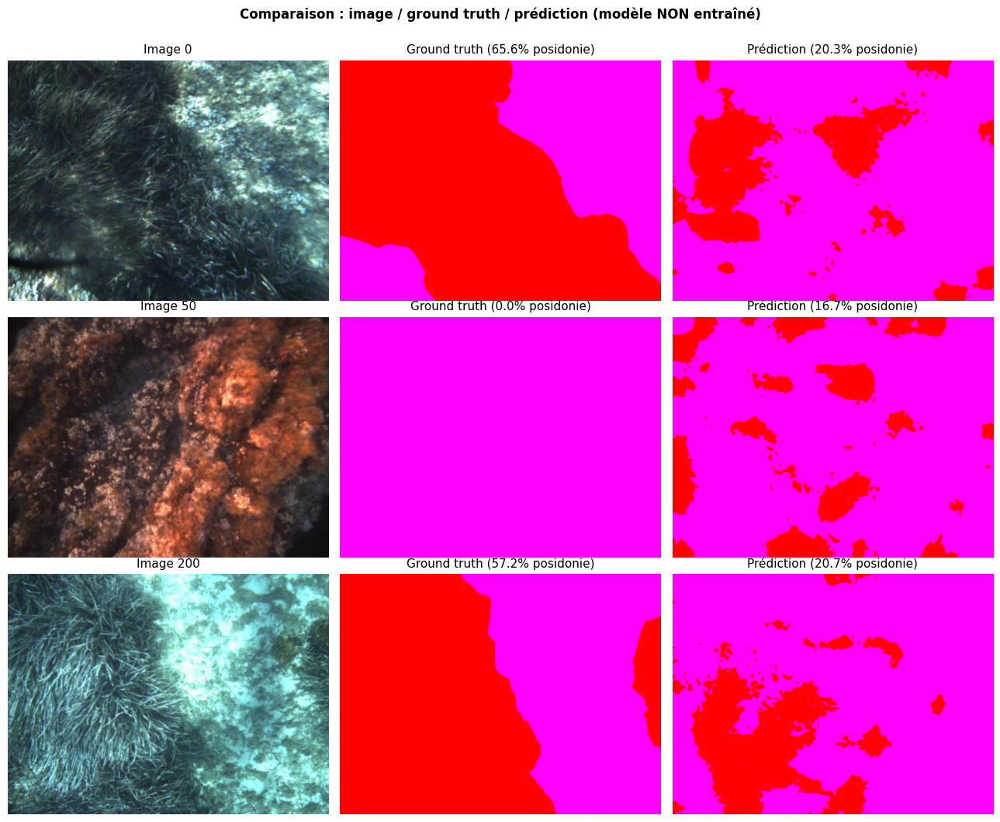


=== Note ===
Les prédictions sont aléatoires (modèle non entraîné).
Après entraînement, les prédictions devraient ressembler aux ground truth.


In [34]:
# === VISUALISATION : MODÈLE NON ENTRAÎNÉ, COULEURS COHÉRENTES ===

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch


def prediction_to_display_colors(pred, mask_np):
    """
    Convertit une prédiction binaire 0/1 en image affichable
    avec la même convention visuelle que le masque ground truth.

    - Si GT RGB : fond magenta, posidonie rouge
    - Si GT niveaux de gris : fond noir, posidonie blanc
    """

    # Cas training / validation : masque RGB rouge/magenta
    if mask_np.ndim == 3:
        pred_rgb = np.zeros((*pred.shape, 3), dtype=np.uint8)

        # Fond = magenta
        pred_rgb[pred == 0] = [255, 0, 255]

        # Posidonie = rouge
        pred_rgb[pred == 1] = [255, 0, 0]

        return pred_rgb

    # Cas testing : masque noir/blanc
    else:
        pred_gray = np.zeros(pred.shape, dtype=np.uint8)

        # Fond = noir
        pred_gray[pred == 0] = 0

        # Posidonie = blanc
        pred_gray[pred == 1] = 255

        return pred_gray


def compute_posidonia_coverage_from_raw_mask(mask_np):
    """
    Calcule le pourcentage de posidonie à partir du masque brut.

    - RGB : rouge = posidonie, magenta = fond
    - niveaux de gris : blanc = posidonie, noir = fond
    """

    # Training / validation : masque RGB
    if mask_np.ndim == 3:
        r = mask_np[:, :, 0]
        g = mask_np[:, :, 1]
        b = mask_np[:, :, 2]

        # Posidonie = rouge
        posidonia_pixels = (r > 200) & (g < 80) & (b < 80)

        return posidonia_pixels.mean() * 100

    # Testing : masque noir/blanc
    elif mask_np.ndim == 2:
        posidonia_pixels = mask_np > 127

        return posidonia_pixels.mean() * 100

    else:
        return np.nan


def visualize_predictions(model, dataset, indices=None, n_samples=3, device=DEVICE):
    """
    Affiche :
    - image originale brute
    - masque ground truth brut, avec ses couleurs d'origine
    - prédiction du modèle avec une convention couleur cohérente

    L'inférence utilise dataset[idx], mais l'affichage utilise les fichiers bruts
    pour conserver les couleurs réelles des données.
    """

    if indices is None:
        indices = np.linspace(0, len(dataset) - 1, n_samples).astype(int)

    # Récupération des chemins bruts déjà gérés par ta fonction précédente
    image_paths, mask_paths = build_raw_paths_from_dataset(dataset)

    model.eval()

    fig, axes = plt.subplots(len(indices), 3, figsize=(13, len(indices) * 3.5))

    if len(indices) == 1:
        axes = axes.reshape(1, -1)

    with torch.no_grad():
        for row, idx in enumerate(indices):

            # ==========================
            # 1. Données pour inférence
            # ==========================
            img_tensor, mask_tensor = dataset[idx]

            img_batch = img_tensor.unsqueeze(0).to(device)
            logits = model(img_batch)
            pred = logits.argmax(dim=1).squeeze(0).cpu().numpy()

            # ==========================
            # 2. Données brutes pour affichage
            # ==========================
            raw_img = Image.open(image_paths[idx])
            raw_mask = Image.open(mask_paths[idx])

            raw_mask_np = np.array(raw_mask)

            # Couverture GT correcte selon le format brut
            gt_coverage = compute_posidonia_coverage_from_raw_mask(raw_mask_np)

            # Couverture prédiction
            pred_coverage = pred.mean() * 100

            # Conversion prédiction en couleurs cohérentes avec le GT
            pred_display = prediction_to_display_colors(pred, raw_mask_np)

            # ==========================
            # 3. Affichage image brute
            # ==========================
            axes[row, 0].imshow(raw_img)
            axes[row, 0].set_title(f"Image {idx}", fontsize=11)
            axes[row, 0].axis("off")

            # ==========================
            # 4. Affichage GT brut
            # ==========================
            if raw_mask_np.ndim == 2:
                axes[row, 1].imshow(raw_mask_np, cmap="gray", vmin=0, vmax=255)
            else:
                axes[row, 1].imshow(raw_mask)

            axes[row, 1].set_title(
                f"Ground truth ({gt_coverage:.1f}% posidonie)",
                fontsize=11
            )
            axes[row, 1].axis("off")

            # ==========================
            # 5. Affichage prédiction
            # ==========================
            if raw_mask_np.ndim == 2:
                axes[row, 2].imshow(pred_display, cmap="gray", vmin=0, vmax=255)
            else:
                axes[row, 2].imshow(pred_display)

            axes[row, 2].set_title(
                f"Prédiction ({pred_coverage:.1f}% posidonie)",
                fontsize=11
            )
            axes[row, 2].axis("off")

    plt.suptitle(
        "Comparaison : image / ground truth / prédiction (modèle NON entraîné)",
        fontsize=12,
        fontweight="bold",
        y=1.005
    )

    plt.tight_layout()
    plt.show()

    return fig


visualize_predictions(model, ds_test, indices=[0, 50, 200])

print("\n=== Note ===")
print("Les prédictions sont aléatoires (modèle non entraîné).")
print("Après entraînement, les prédictions devraient ressembler aux ground truth.")

## 3.4 Résumé de l'architecture SegFormer

### Structure générale

SegFormer utilise un **encodeur hiérarchique MiT (Mix Transformer)** composé de quatre stages.  
À mesure que l'on progresse dans l'encodeur :

- la résolution spatiale des cartes de caractéristiques diminue ;
- le nombre de caractéristiques augmente ;
- le champ de représentation devient progressivement plus global.

Contrairement à une simple division exacte par 2 des dimensions à chaque étape, les résolutions produites dépendent des paramètres des couches d'**Overlap Patch Embedding** (taille du noyau, stride et padding). SegFormer peut donc traiter une résolution d'entrée telle que **360 × 480**, même si certaines dimensions intermédiaires sont impaires.

### Exemple avec SegFormer-B0

| Étape | Type | Résolution spatiale | Canaux (B0) |
|---|---|---:|---:|
| Entrée | Image RGB | **360 × 480** | 3 |
| Stage 1 | Overlap Patch Embedding + blocs Transformer | **90 × 120** | 32 |
| Stage 2 | Overlap Patch Embedding + blocs Transformer | **45 × 60** | 64 |
| Stage 3 | Overlap Patch Embedding + blocs Transformer | **23 × 30** | 160 |
| Stage 4 | Overlap Patch Embedding + blocs Transformer | **12 × 15** | 256 |
| Décodeur All-MLP | Projection et fusion des représentations multi-échelles | **90 × 120** | 256 |
| Tête de classification | Prédiction des logits | **90 × 120** | `n_classes` |
| Upsampling final | Interpolation bilinéaire vers la taille d'entrée | **360 × 480** | `n_classes` |

> **Remarque sur les dimensions :**  
> Les résolutions `23 × 30` et `12 × 15` sont normales. SegFormer n'exige pas que la hauteur et la largeur de l'image soient des multiples exacts de 32. Les couches d'Overlap Patch Embedding gèrent les dimensions intermédiaires grâce à leurs paramètres de convolution, de stride et de padding.

### Comment évolue la résolution ?

Pour une image d'entrée de **360 × 480**, la hiérarchie spatiale est :

```text
Image RGB
360 × 480
    ↓
Stage 1
90 × 120      ≈ 1/4
    ↓
Stage 2
45 × 60       ≈ 1/8
    ↓
Stage 3
23 × 30       ≈ 1/16
    ↓
Stage 4
12 × 15       ≈ 1/32
    ↓
Décodeur All-MLP
90 × 120
    ↓
Upsampling bilinéaire
360 × 480

# 4. Fonctions de perte

## 4.1 Théorie : pourquoi varier la fonction de perte ?

La **fonction de perte** (loss) mesure l'écart entre les prédictions du modèle
et la vérité terrain. C'est ce que l'algorithme d'optimisation cherche à
**minimiser** pendant l'entraînement.

### Trois philosophies différentes pour la segmentation binaire

| Loss | Philosophie | Niveau d'opération |
|---|---|---|
| **CrossEntropy (CE)** | "Chaque pixel doit être bien classé" | Pixel par pixel |
| **CE + Dice** | "L'ensemble de la région doit bien se recouvrir" | Région globale |
| **CE + SEMEDA** | "Les structures sémantiques doivent être cohérentes" | Structure |

### Intuition

Considérons deux prédictions A et B sur une image de posidonie :

- **Prédiction A** : 95% des pixels bien classés, mais avec des "trous" dans les zones de posidonie
- **Prédiction B** : 93% des pixels bien classés, mais segmentation cohérente sans trous

-> La CE seule pourrait préférer A (plus de pixels corrects)

-> Le Dice pénalise A (mauvais recouvrement régional)

-> SEMEDA pénalise A (incohérence structurelle)

**On va implémenter et tester les 3** pour identifier laquelle est la plus adaptée
à la segmentation de Posidonia oceanica.

### Format des prédictions

Le modèle SegFormer produit des **logits** de shape `[B, 2, H, W]` :
- Canal 0 : score pour la classe "fond"
- Canal 1 : score pour la classe "posidonie"

On applique `softmax` pour obtenir des probabilités dans [0, 1].

## 4.2 Cross Entropy (CE) - la baseline

### Formule

Pour la classification binaire pixel à pixel :

$$L_{CE} = -\frac{1}{N} \sum_{i=1}^{N} \big[ y_i \log(p_i) + (1 - y_i) \log(1 - p_i) \big]$$

où :
- $N$ = nombre total de pixels
- $y_i$ = label réel du pixel $i$ (0 ou 1)
- $p_i$ = probabilité prédite que le pixel $i$ soit de la classe 1

### Avantages
- Standard, bien comprise, bien implémentée dans tous les frameworks
- Optimisation stable (gradients bien conditionnés)
- Bon baseline de comparaison

### Limitation
- Traite chaque pixel **indépendamment** (pas de notion de région)
- Peut surapprendre les **petites zones** sans pénaliser les "trous"

In [35]:
# === CROSS ENTROPY (BASELINE) ===
# nn.CrossEntropyLoss est déjà parfaitement implémentée par PyTorch
# Pas besoin de réimplémenter, on l'utilisera directement

print("=== Cross Entropy Loss (CE) ===")
print("Implémentation : nn.CrossEntropyLoss (standard PyTorch)")
print("Utilisation : ce_loss = nn.CrossEntropyLoss()")
print("                loss = ce_loss(logits, targets)")
print()
print("  - logits : tenseur [B, C, H, W] (sorties brutes du modèle)")
print("  - targets : tenseur [B, H, W] (labels int dans [0, C-1])")
print()

# Test rapide
ce_loss = nn.CrossEntropyLoss()
fake_logits = torch.randn(2, 2, 32, 32)  # batch=2, C=2, 32x32
fake_targets = torch.randint(0, 2, (2, 32, 32))
loss_value = ce_loss(fake_logits, fake_targets)
print(f"  Test : loss = {loss_value.item():.4f}")
print(f"  Cross Entropy opérationnelle")

=== Cross Entropy Loss (CE) ===
Implémentation : nn.CrossEntropyLoss (standard PyTorch)
Utilisation : ce_loss = nn.CrossEntropyLoss()
                loss = ce_loss(logits, targets)

  - logits : tenseur [B, C, H, W] (sorties brutes du modèle)
  - targets : tenseur [B, H, W] (labels int dans [0, C-1])

  Test : loss = 0.8922
  Cross Entropy opérationnelle


## 4.3 CE + Dice (CombinedLoss)

### Dice Loss

Le coefficient de Dice mesure le **recouvrement** entre deux ensembles :

$$\text{Dice} = \frac{2 \cdot |P \cap G|}{|P| + |G|}$$

où $P$ = pixels prédits posidonie, $G$ = pixels réels posidonie.

-> Dice = 1 si recouvrement parfait, 0 si aucun recouvrement.

### Dice Loss (à minimiser)

$$L_{Dice} = 1 - \text{Dice}$$

### Combined Loss

On **combine** CE et Dice avec un poids λ :

$$L = L_{CE} + \lambda \cdot L_{Dice}$$

avec λ = 0.5 (équilibre standard).

### Pourquoi combiner ?
- CE optimise la **classification pixel par pixel**
- Dice optimise le **recouvrement régional**
- Combinés : permet de gérer les deux cas de figure

In [36]:
# === COMBINED LOSS : CE + DICE ===

class DiceLoss(nn.Module):
    """
    Dice loss pour segmentation binaire ou multi-classes.

    Args:
        smooth : terme de lissage pour éviter division par zéro
        ignore_index : indice à ignorer (par exemple pour padding)
    """
    def __init__(self, smooth=1e-6, ignore_index=None):
        super().__init__()
        self.smooth = smooth
        self.ignore_index = ignore_index

    def forward(self, logits, targets):
        """
        Args:
            logits : [B, C, H, W] - sorties brutes du modèle
            targets : [B, H, W] - labels int dans [0, C-1]

        Returns:
            scalar tensor : 1 - Dice moyen sur les classes (sans le fond)
        """
        n_classes = logits.shape[1]

        # Softmax pour obtenir des probabilités
        probas = F.softmax(logits, dim=1)

        # One-hot encoding des targets
        targets_one_hot = F.one_hot(targets, num_classes=n_classes)
        targets_one_hot = targets_one_hot.permute(0, 3, 1, 2).float()  # [B, C, H, W]

        # Calcul du Dice par classe
        intersection = (probas * targets_one_hot).sum(dim=(0, 2, 3))
        union = probas.sum(dim=(0, 2, 3)) + targets_one_hot.sum(dim=(0, 2, 3))
        dice_per_class = (2.0 * intersection + self.smooth) / (union + self.smooth)

        # On ne pénalise que les classes "objet" (pas le fond)
        # Pour notre cas binaire : classe 0 = fond, classe 1 = posidonie
        dice = dice_per_class[1:].mean()  # moyenne sur les classes non-fond

        return 1.0 - dice


class CombinedLoss(nn.Module):
    """
    Combinaison CE + λ x Dice.

    Args:
        lambda_dice : poids du terme Dice (default 0.5)
    """
    def __init__(self, lambda_dice=0.5):
        super().__init__()
        self.ce = nn.CrossEntropyLoss()
        self.dice = DiceLoss()
        self.lambda_dice = lambda_dice

    def forward(self, logits, targets):
        ce_loss = self.ce(logits, targets)
        dice_loss = self.dice(logits, targets)
        return ce_loss + self.lambda_dice * dice_loss


# Test
print("=== Combined Loss (CE + Dice) ===")
combined = CombinedLoss(lambda_dice=0.5)
fake_logits = torch.randn(2, 2, 32, 32)
fake_targets = torch.randint(0, 2, (2, 32, 32))
loss_value = combined(fake_logits, fake_targets)
print(f"  Test : loss = {loss_value.item():.4f}")

# Décomposition
ce_only = combined.ce(fake_logits, fake_targets)
dice_only = combined.dice(fake_logits, fake_targets)
print(f"  Détail : CE = {ce_only.item():.4f}, Dice = {dice_only.item():.4f}")
print(f"           Combined = {ce_only.item():.4f} + 0.5 × {dice_only.item():.4f} = {loss_value.item():.4f}")
print(f"\n   Combined Loss opérationnelle")

=== Combined Loss (CE + Dice) ===
  Test : loss = 1.1499
  Détail : CE = 0.9009, Dice = 0.4981
           Combined = 0.9009 + 0.5 × 0.4981 = 1.1499

   Combined Loss opérationnelle


## 4.4 CE + SEMEDA (Semantic Edge-Aware)

### Principe

**SEMEDA** (Chen Yifu et al.) utilise un **réseau auxiliaire pré-entraîné**
qui extrait des **embeddings sémantiques** des masques.

L'idée : au lieu de comparer pixel à pixel (CE) ou région à région (Dice),
on compare les **représentations apprises** des masques prédit et réel.

### Architecture
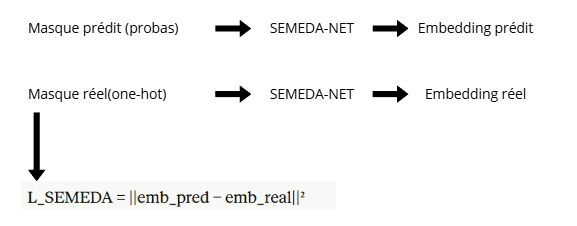

### Pourquoi ça marche ?

Le SEMEDA-Net est **pré-entraîné en autoencoder** sur les masques GT. Il apprend
à compresser les masques en représentations compactes qui capturent leur
**structure essentielle**.

-> Comparer dans cet espace = comparer la **cohérence structurelle**, pas juste
les pixels.

### Combined Loss avec SEMEDA

$$L = L_{CE} + \lambda \cdot L_{SEMEDA}$$

avec λ = 0.5.

### Note importante

SEMEDA travaille sur les **masques GT**, pas sur les images. Donc le même
SEMEDA-Net pré-entraîné fonctionne pour **toutes les architectures**
(U-Net, FCN-VGG16, SegFormer). On l'a déjà entraîné dans nos études précédentes
et il est sauvegardé dans `shared/semeda_net_pretrained.pth`.

In [37]:
# === SEMEDA-NET (ARCHITECTURE EXACTE selon le fichier pré-entraîné) ===

class SemedaNet(nn.Module):
    """
    Réseau auxiliaire SEMEDA (Semantic Edge-Aware) pour détection de bords.

    Architecture en 3 blocs :
    - conv1 : 2 -> 32 -> 32 (extraction features bas-niveau)
    - conv2 : 32 -> 64 -> 64 (extraction features mid-niveau)
    - edge_head : 64 -> 32 -> 1 (tête de détection des bords)

    Pré-entraîné en tant que détecteur de bords sur les masques GT.
    Pour la SEMEDA loss, on utilisera les features intermédiaires (sortie de conv2).

    Référence : Chen Yifu et al. - SEMEDA loss pour segmentation sémantique.
    """
    def __init__(self, in_channels=2):
        super().__init__()

        # Bloc 1 : 2 → 32 → 32
        self.conv1 = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),  # conv1.0
            nn.BatchNorm2d(32),                                     # conv1.1
            nn.ReLU(inplace=True),                                  # conv1.2 (sans poids)
            nn.Conv2d(32, 32, kernel_size=3, padding=1),           # conv1.3
            nn.BatchNorm2d(32),                                     # conv1.4
            nn.ReLU(inplace=True),                                  # conv1.5 (sans poids)
        )

        # Bloc 2 : 32 → 64 → 64
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),           # conv2.0
            nn.BatchNorm2d(64),                                     # conv2.1
            nn.ReLU(inplace=True),                                  # conv2.2
            nn.Conv2d(64, 64, kernel_size=3, padding=1),           # conv2.3
            nn.BatchNorm2d(64),                                     # conv2.4
            nn.ReLU(inplace=True),                                  # conv2.5
        )

        # Tête de bords : 64 → 32 → 1
        self.edge_head = nn.Sequential(
            nn.Conv2d(64, 32, kernel_size=3, padding=1),           # edge_head.0
            nn.BatchNorm2d(32),                                     # edge_head.1
            nn.ReLU(inplace=True),                                  # edge_head.2
            nn.Conv2d(32, 1, kernel_size=1),                       # edge_head.3 (1×1)
        )

    def forward(self, mask_probas, return_features=True):
        """
        Args:
            mask_probas : [B, C, H, W] - masque (soft ou one-hot, C=2 classes)
            return_features : si True, retourne les features intermédiaires (conv2)
                              utilisées pour la SEMEDA loss

        Returns:
            Si return_features=True (mode loss SEMEDA):
                features : [B, 64, H, W] - sortie de conv2
            Si return_features=False (mode détection de bords):
                edge_map : [B, 1, H, W] - carte de probabilité des bords
        """
        f1 = self.conv1(mask_probas)
        f2 = self.conv2(f1)

        if return_features:
            return f2  # pour la SEMEDA loss
        else:
            edge_map = self.edge_head(f2)
            return edge_map  # pour visualiser/utiliser la détection de bords


# Test de l'architecture
print("=== Test architecture SemedaNet (version corrigée) ===")
test_net = SemedaNet(in_channels=N_CLASSES)
n_params = sum(p.numel() for p in test_net.parameters())
print(f"  Paramètres : {n_params:,} (attendu : ~84,678)")

# Test forward
fake_mask = torch.randn(2, N_CLASSES, 32, 32)
features = test_net(fake_mask, return_features=True)
edge_map = test_net(fake_mask, return_features=False)
print(f"  Features (pour SEMEDA loss) : {features.shape} (attendu : [2, 64, 32, 32])")
print(f"  Edge map (pour visualisation): {edge_map.shape} (attendu : [2, 1, 32, 32])")
print(f"  Architecture correcte")

=== Test architecture SemedaNet (version corrigée) ===
  Paramètres : 84,225 (attendu : ~84,678)
  Features (pour SEMEDA loss) : torch.Size([2, 64, 32, 32]) (attendu : [2, 64, 32, 32])
  Edge map (pour visualisation): torch.Size([2, 1, 32, 32]) (attendu : [2, 1, 32, 32])
  Architecture correcte


## 4.5 Chargement du SEMEDA pré-entraîné


## 4.5.1 Procédure de pré-entraînement de SEMEDA

Le réseau SEMEDA utilisé ici a été pré-entraîné selon la procédure suivante.
Si le fichier `shared/semeda_net_pretrained.pth` existe, on le charge directement.
Sinon, on peut le réentraîner avec la fonction `pretrain_semeda_with_es` définie ci-dessous.

### Tâche d'apprentissage : détection de bords sémantiques

SEMEDA-Net est entraîné comme **détecteur de bords** sur les masques GT du dataset
Posidonia training.

- **Entrée** : masque binaire (format one-hot, 2 canaux : fond + posidonie)
- **Sortie** : carte de probabilité des bords (1 canal, valeurs ∈ [0, 1])
- **Cible** : carte de bords GT calculée par opérateur de gradient sur le masque binaire

### Pipeline d'entraînement

### Hyperparamètres utilisés

| Paramètre | Valeur |
|---|---|
| Optimizer | Adam |
| Learning rate | 1e-3 |
| Loss | BCEWithLogitsLoss |
| Batch size | 4 |
| Max epochs | 100 |
| Early stopping patience | 5 |
| Split validation interne | 15% du training set |

### Stratégie d'early stopping

- Mini-split interne **80/15** sur les masques training (avec seed fixé pour reproductibilité)
- Surveillance de la **val_loss** à chaque epoch
- Sauvegarde du **meilleur état** quand val_loss diminue
- Arrêt après 5 epochs sans amélioration
- Restauration du **meilleur état** à la fin

### Résultats de pré-entraînement

Les résultats typiques observés lors du pré-entraînement initial (sur SegFormer-B0) :
- Convergence en ~15-25 epochs
- Best val_loss sensiblement 0.10-0.15 (BCE sur cartes de bords)
- Pas de surapprentissage marqué (train et val proches)

### Réutilisation

Le SEMEDA-Net travaille **uniquement** sur les masques GT (identiques quelle que soit
l'architecture de segmentation). Il peut donc être **réutilisé tel quel** pour :
- U-Net 
- FCN-VGG16 
- SegFormer 

D'où son emplacement dans `shared/`.

In [38]:
# === FONCTIONS POUR (RE-)ENTRAÎNER SEMEDA SI NÉCESSAIRE ===

def compute_gt_edges(masks):
    """
    Calcule la carte de bords GT à partir des masques binaires.

    Utilise un opérateur de gradient (différences finies) pour détecter les
    transitions entre régions.

    Args:
        masks : [B, H, W] tensor de masques binaires (valeurs 0 ou 1)

    Returns:
        edges : [B, 1, H, W] carte de bords (valeurs ∈ [0, 1])
    """
    masks_float = masks.float().unsqueeze(1)  # [B, 1, H, W]

    # Gradient horizontal (différence avec le pixel à droite)
    grad_x = torch.abs(masks_float[:, :, :, 1:] - masks_float[:, :, :, :-1])
    grad_x = F.pad(grad_x, (0, 1, 0, 0))  # pad pour conserver la taille

    # Gradient vertical (différence avec le pixel en dessous)
    grad_y = torch.abs(masks_float[:, :, 1:, :] - masks_float[:, :, :-1, :])
    grad_y = F.pad(grad_y, (0, 0, 0, 1))

    # Magnitude du gradient (présence d'un bord)
    edges = torch.clamp(grad_x + grad_y, 0, 1)

    return edges


def pretrain_semeda_with_es(train_dataset, n_epochs=100, lr=1e-3,
                              batch_size=4, patience=5, val_split=0.15,
                              save_path=None):
    """
    Pré-entraîne SEMEDA-Net comme détecteur de bords sur les masques GT.

    Utilise un mini-split interne (val_split) pour l'early stopping.

    Args:
        train_dataset : dataset training (fournit images, masques)
        n_epochs : nombre maximum d'époques
        lr : learning rate
        batch_size : taille du batch
        patience : patience pour early stopping
        val_split : fraction du dataset pour validation interne (default 0.15)
        save_path : si fourni, sauvegarde le modèle entraîné à ce chemin

    Returns:
        SemedaNet : réseau pré-entraîné (poids figés, mode eval)
    """
    from torch.utils.data import random_split

    # Mini-split interne pour l'early stopping
    n_total = len(train_dataset)
    n_val = int(n_total * val_split)
    n_tr = n_total - n_val

    g = torch.Generator().manual_seed(SEED)
    tr_subset, val_subset = random_split(train_dataset, [n_tr, n_val], generator=g)

    print(f"=== Pré-entraînement SEMEDA avec early stopping ===")
    print(f"  Train : {n_tr} | Val : {n_val} | Patience : {patience}")
    print(f"  Max epochs : {n_epochs} | LR : {lr} | Batch size : {batch_size}\n")

    # Initialisation du réseau
    semeda = SemedaNet(in_channels=N_CLASSES).to(DEVICE)
    optimizer = torch.optim.Adam(semeda.parameters(), lr=lr)
    criterion = nn.BCEWithLogitsLoss()

    tr_loader  = DataLoader(tr_subset,  batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)

    best_val_loss = float('inf')
    best_state = None
    patience_counter = 0
    history = {'train_loss': [], 'val_loss': []}

    for epoch in range(n_epochs):
        # === Phase d'entraînement ===
        semeda.train()
        total_train = 0
        n_tr_batches = 0
        for _, masks in tr_loader:
            masks = masks.to(DEVICE)

            # Préparation : masque one-hot pour SEMEDA
            mask_onehot = F.one_hot(masks.long(), num_classes=N_CLASSES)
            mask_onehot = mask_onehot.permute(0, 3, 1, 2).float()

            # Cible : carte de bords GT
            gt_edges = compute_gt_edges(masks)

            # Prédiction (utiliser return_features=False pour avoir la edge_map)
            pred_edges = semeda(mask_onehot, return_features=False)

            # Loss
            loss = criterion(pred_edges, gt_edges)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train += loss.item()
            n_tr_batches += 1

        train_loss = total_train / n_tr_batches

        # === Phase de validation ===
        semeda.eval()
        total_val = 0
        n_val_batches = 0
        with torch.no_grad():
            for _, masks in val_loader:
                masks = masks.to(DEVICE)
                mask_onehot = F.one_hot(masks.long(), num_classes=N_CLASSES)
                mask_onehot = mask_onehot.permute(0, 3, 1, 2).float()
                gt_edges = compute_gt_edges(masks)
                pred_edges = semeda(mask_onehot, return_features=False)
                loss = criterion(pred_edges, gt_edges)
                total_val += loss.item()
                n_val_batches += 1

        val_loss = total_val / n_val_batches
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)

        # === Early stopping ===
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {k: v.clone() for k, v in semeda.state_dict().items()}
            patience_counter = 0
            marker = "*"
        else:
            patience_counter += 1
            marker = " "

        print(f"  Epoch {epoch+1:3d} | train={train_loss:.5f} | val={val_loss:.5f} {marker}"
              f" | patience={patience_counter}/{patience}")

        if patience_counter >= patience:
            print(f"\n  >>> Early stopping à l'epoch {epoch+1}")
            break

    # Restauration du meilleur état
    semeda.load_state_dict(best_state)
    semeda.eval()
    for param in semeda.parameters():
        param.requires_grad = False

    print(f"\n  Pré-entraînement terminé (best val_loss = {best_val_loss:.5f})")

    # Sauvegarde optionnelle
    if save_path is not None:
        save_dict = {'state_dict': semeda.state_dict()}
        torch.save(save_dict, save_path)
        print(f"  Modèle sauvegardé : {save_path}")

    return semeda, history


# Note : on ne lance pas le pré-entraînement ici, juste on définit la fonction.
# Elle sera utilisée seulement si le fichier .pth n'existe pas (voir cellule suivante).
print("   Fonctions de pré-entraînement définies (compute_gt_edges, pretrain_semeda_with_es)")
print("   Ces fonctions seront utilisées seulement si le fichier SEMEDA .pth n'existe pas.")

   Fonctions de pré-entraînement définies (compute_gt_edges, pretrain_semeda_with_es)
   Ces fonctions seront utilisées seulement si le fichier SEMEDA .pth n'existe pas.


In [39]:
# === CHARGEMENT INTELLIGENT DE SEMEDA ===
# Si le fichier .pth existe -> on charge
# Sinon -> on pré-entraîne et on sauvegarde dans shared/

SEMEDA_PATH = os.path.join(SHARED_DIR, "semeda_net_pretrained.pth")

def load_or_train_semeda(semeda_path=SEMEDA_PATH, force_retrain=False):
    """
    Charge SEMEDA depuis le fichier .pth s'il existe, sinon le pré-entraîne.

    Args:
        semeda_path : chemin du fichier .pth dans shared/
        force_retrain : si True, force le pré-entraînement même si le fichier existe

    Returns:
        SemedaNet : réseau prêt à l'emploi (mode eval, poids figés)
    """
    # Cas 1 : le fichier existe et on ne force pas le réentraînement
    if os.path.exists(semeda_path) and not force_retrain:
        print(f"=== Chargement de SEMEDA depuis {semeda_path} ===\n")

        # Création du réseau (architecture exacte)
        net = SemedaNet(in_channels=N_CLASSES)

        # Chargement des poids
        loaded_data = torch.load(semeda_path, map_location=DEVICE)

        # Gestion des deux formats possibles
        if isinstance(loaded_data, dict) and 'state_dict' in loaded_data:
            state_dict = loaded_data['state_dict']
            print(f"   Format détecté : dict avec 'state_dict' à l'intérieur")
        else:
            state_dict = loaded_data
            print(f"   Format détecté : state_dict direct")

        net.load_state_dict(state_dict)
        net.eval()
        for p in net.parameters():
            p.requires_grad = False
        net = net.to(DEVICE)

        n_params = sum(p.numel() for p in net.parameters())
        print(f"  SEMEDA chargé ({n_params:,} paramètres, tous figés)")
        return net

    # Cas 2 : pas de fichier, on pré-entraîne
    print(f"=== Aucun SEMEDA pré-entraîné trouvé à {semeda_path} ===")
    print(f"   Lancement du pré-entraînement...\n")

    # Dataset training sans augmentation ni prétraitement (sur masques GT bruts)
    train_dataset_for_semeda = PosidoniaDatasetFromCSV(
        csv_path=TRAIN_CSV,
        root_path=LOCAL_PATH,
        split="training",
        augment=False,
        preprocess=None,
    )

    semeda, history = pretrain_semeda_with_es(
        train_dataset=train_dataset_for_semeda,
        n_epochs=100,
        lr=1e-3,
        batch_size=4,
        patience=5,
        val_split=0.15,
        save_path=semeda_path,  # sauvegarde directement dans shared/
    )

    return semeda


# Chargement (ou pré-entraînement si nécessaire)
semeda_net = load_or_train_semeda()

print("\n=== Test forward avec SEMEDA opérationnel ===")
fake_mask = torch.randn(2, N_CLASSES, IMG_H, IMG_W).to(DEVICE)
features = semeda_net(fake_mask, return_features=True)
print(f"  Sortie features : {features.shape}")
print(f"  Tout est opérationnel")

=== Chargement de SEMEDA depuis C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\shared\semeda_net_pretrained.pth ===

   Format détecté : dict avec 'state_dict' à l'intérieur
  SEMEDA chargé (84,225 paramètres, tous figés)

=== Test forward avec SEMEDA opérationnel ===
  Sortie features : torch.Size([2, 64, 360, 480])
  Tout est opérationnel


In [40]:
# === SEMEDA LOSS ===

class SemedaLoss(nn.Module):
    """
    Loss SEMEDA : distance entre les features intermédiaires des masques
    prédit et réel, calculées par le réseau SEMEDA pré-entraîné.

    Le SEMEDA-Net étant pré-entraîné comme détecteur de bords sur les masques GT,
    ses features intermédiaires capturent la structure sémantique des bords
    et des régions.

    Args:
        semeda_net : instance de SemedaNet pré-entraîné (poids figés)
        n_classes : nombre de classes
    """
    def __init__(self, semeda_net, n_classes=2):
        super().__init__()
        self.semeda_net = semeda_net
        self.n_classes = n_classes

        # S'assurer que les poids sont figés
        for p in self.semeda_net.parameters():
            p.requires_grad = False
        self.semeda_net.eval()

    def forward(self, logits, targets):
        """
        Args:
            logits : [B, C, H, W] - sorties brutes du modèle de segmentation
            targets : [B, H, W] - labels int

        Returns:
            scalar tensor : distance L2 entre features prédites et réelles
        """
        # Probas pour le masque prédit
        probas = F.softmax(logits, dim=1)

        # One-hot pour le masque réel
        targets_one_hot = F.one_hot(targets, num_classes=self.n_classes)
        targets_one_hot = targets_one_hot.permute(0, 3, 1, 2).float()

        # Extraction des features via SEMEDA (features intermédiaires)
        features_pred = self.semeda_net(probas, return_features=True)
        features_real = self.semeda_net(targets_one_hot, return_features=True)

        # Distance L2 entre les embeddings
        return F.mse_loss(features_pred, features_real)


# Test
print("=== Test SemedaLoss avec SEMEDA pré-entraîné ===")
semeda_loss_fn = SemedaLoss(semeda_net, n_classes=N_CLASSES)
fake_logits = torch.randn(2, N_CLASSES, IMG_H, IMG_W).to(DEVICE)
fake_targets = torch.randint(0, N_CLASSES, (2, IMG_H, IMG_W)).to(DEVICE)
loss_value = semeda_loss_fn(fake_logits, fake_targets)
print(f"  Test : loss = {loss_value.item():.4f}")
print(f"  SemedaLoss opérationnelle")


class CombinedSemedaLoss(nn.Module):
    """
    Combinaison CE + λ × SEMEDA.

    Args:
        semeda_net : instance de SemedaNet pré-entraîné
        n_classes : nombre de classes
        lambda_semeda : poids du terme SEMEDA (default 0.5)
    """
    def __init__(self, semeda_net, n_classes=2, lambda_semeda=0.5):
        super().__init__()
        self.ce = nn.CrossEntropyLoss()
        self.semeda = SemedaLoss(semeda_net, n_classes=n_classes)
        self.lambda_semeda = lambda_semeda

    def forward(self, logits, targets):
        ce_loss = self.ce(logits, targets)
        semeda_loss = self.semeda(logits, targets)
        return ce_loss + self.lambda_semeda * semeda_loss


# === TEST DE CombinedSemedaLoss ===

print("=== Combined SEMEDA Loss ===")

# Création d'un SemedaNet de test (poids aléatoires, juste pour vérifier la structure)
semeda_net_test = SemedaNet(in_channels=N_CLASSES)
combined_semeda = CombinedSemedaLoss(semeda_net_test, n_classes=N_CLASSES, lambda_semeda=0.5)

fake_logits = torch.randn(2, N_CLASSES, 32, 32)
fake_targets = torch.randint(0, N_CLASSES, (2, 32, 32))
loss_value = combined_semeda(fake_logits, fake_targets)
print(f"  Test : loss = {loss_value.item():.4f}")
print(f"  Combined SEMEDA Loss opérationnelle")

=== Test SemedaLoss avec SEMEDA pré-entraîné ===
  Test : loss = 1.2703
  SemedaLoss opérationnelle
=== Combined SEMEDA Loss ===
  Test : loss = 0.9082
  Combined SEMEDA Loss opérationnelle


## 4.6 Registry des fonctions de perte

Pour pouvoir tester facilement différentes losses dans nos expériences, on
utilise un **registry** (comme pour les prétraitements).

**Convention** : chaque loss est instanciée via une fonction `build_loss(name, ...)`.

In [41]:
# === REGISTRY DES FONCTIONS DE PERTE ===

def build_loss(loss_name, semeda_net=None, n_classes=N_CLASSES,
                lambda_dice=0.5, lambda_semeda=0.5):
    """
    Construit une fonction de perte selon son nom.

    Args:
        loss_name : "ce", "ce_dice", ou "ce_semeda"
        semeda_net : SemedaNet pré-entraîné (requis pour "ce_semeda")
        n_classes : nombre de classes
        lambda_dice : poids du Dice si "ce_dice"
        lambda_semeda : poids de SEMEDA si "ce_semeda"

    Returns:
        nn.Module : fonction de perte prête à l'emploi
    """
    if loss_name == "ce":
        return nn.CrossEntropyLoss()

    elif loss_name == "ce_dice":
        return CombinedLoss(lambda_dice=lambda_dice)

    elif loss_name == "ce_semeda":
        if semeda_net is None:
            raise ValueError("semeda_net est requis pour la loss 'ce_semeda'")
        return CombinedSemedaLoss(semeda_net, n_classes=n_classes,
                                    lambda_semeda=lambda_semeda)

    else:
        available = ["ce", "ce_dice", "ce_semeda"]
        raise ValueError(f"Loss '{loss_name}' inconnue. Disponibles : {available}")


# Test du registry
print("=== Test du registry des losses ===\n")

for loss_name in ["ce", "ce_dice", "ce_semeda"]:
    loss_fn = build_loss(loss_name, semeda_net=semeda_net)
    fake_logits = torch.randn(2, N_CLASSES, 32, 32).to(DEVICE)
    fake_targets = torch.randint(0, N_CLASSES, (2, 32, 32)).to(DEVICE)
    value = loss_fn(fake_logits, fake_targets)
    print(f"  {loss_name:<12} -> {value.item():.4f}")

# Test validation
print("\n=== Test de la validation ===")
try:
    build_loss("typo_inexistant")
    print("  Erreur : la validation n'a pas marché")
except ValueError as e:
    print(f"  Validation OK : {e}")

print("\n=== Section 4 terminée ===")

=== Test du registry des losses ===

  ce           -> 0.9121
  ce_dice      -> 1.1773
  ce_semeda    -> 1.5231

=== Test de la validation ===
  Validation OK : Loss 'typo_inexistant' inconnue. Disponibles : ['ce', 'ce_dice', 'ce_semeda']

=== Section 4 terminée ===


# 5. Fonctions d'évaluation

## 5.1 Métriques pour la segmentation binaire

Pour évaluer la qualité de la segmentation binaire **fond / Posidonie**, plusieurs métriques complémentaires sont utilisées.

Une seule métrique n'est généralement pas suffisante pour caractériser complètement les performances d'un modèle de segmentation, notamment lorsque les proportions de fond et de Posidonie varient fortement entre les images.

### Tableau récapitulatif

| Métrique | Formule | Interprétation | Intervalle |
|---|---|---|---|
| **Accuracy** | $(TP + TN) / N$ | Proportion globale de pixels correctement classés | [0, 1] |
| **Precision** | $TP / (TP + FP)$ | Parmi les pixels prédits Posidonie, quelle proportion est réellement de la Posidonie ? | [0, 1] |
| **Recall** | $TP / (TP + FN)$ | Quelle proportion de la Posidonie réellement présente est détectée ? | [0, 1] |
| **Specificity** | $TN / (TN + FP)$ | Quelle proportion du fond est correctement reconnue ? | [0, 1] |
| **Fall-out** | $FP / (FP + TN)$ | Proportion de pixels de fond incorrectement classés comme Posidonie | [0, 1] |
| **Dice / F1** | $2TP / (2TP + FP + FN)$ | Recouvrement entre la prédiction et la Posidonie réelle | [0, 1] |
| **IoU Posidonie** | $TP / (TP + FP + FN)$ | Intersection sur union pour la classe Posidonie | [0, 1] |
| **mIoU** | $(IoU_{fond} + IoU_{posidonie}) / 2$ | Performance moyenne de segmentation sur les deux classes | [0, 1] |
| **AUC-ROC** | Aire sous la courbe ROC | Capacité globale de discrimination sur l'ensemble des seuils | [0, 1] |
| **AUC-PR** | Aire sous la courbe Precision-Recall | Qualité de discrimination pour la classe positive sur l'ensemble des seuils | [0, 1] |

avec :

- $TP$ = vrais positifs ;
- $TN$ = vrais négatifs ;
- $FP$ = faux positifs ;
- $FN$ = faux négatifs.

Pour les deux classes :

$$
IoU_{fond} =
\frac{TN}{TN + FP + FN}
$$

$$
IoU_{posidonie} =
\frac{TP}{TP + FP + FN}
$$

et :

$$
mIoU =
\frac{IoU_{fond} + IoU_{posidonie}}{2}
$$

---

### Pourquoi utiliser plusieurs métriques ?

L'**Accuracy** fournit une mesure globale du nombre de pixels correctement classés, mais elle peut devenir trompeuse lorsque les classes sont déséquilibrées.

Par exemple, si une image contient principalement du fond, un modèle prédisant presque exclusivement la classe fond peut obtenir une Accuracy élevée tout en détectant très mal la Posidonie.

Les métriques de recouvrement telles que **Dice**, **IoU** et **mIoU** sont donc particulièrement importantes pour la segmentation.

Dans ce travail, la **mIoU** constitue la métrique principale de comparaison, car elle tient compte à la fois :

- de la qualité de segmentation de la Posidonie ;
- de la qualité de segmentation du fond.

Le **Recall** et la **Precision** apportent des informations complémentaires :

- **Recall élevé + Precision faible** : le modèle détecte une grande partie de la Posidonie mais produit également de nombreux faux positifs ;
- **Recall faible + Precision élevée** : les prédictions positives sont généralement fiables, mais une partie de la Posidonie présente n'est pas détectée.

Le **Fall-out** complète ces mesures en quantifiant spécifiquement la proportion de pixels appartenant au fond qui sont incorrectement prédits comme Posidonie.

Enfin, les courbes **ROC** et **Precision-Recall** permettent d'étudier le comportement du modèle pour différents seuils de décision. Les métriques **AUC-ROC** et **AUC-PR** résument cette capacité de discrimination sans dépendre d'un seuil de décision unique.

---

## 5.2 Seuil de décision et calibration

Pour chaque pixel, le modèle produit deux **logits**, correspondant aux deux classes :

- `0` : fond ;
- `1` : Posidonie.

Une fonction **Softmax** transforme ces logits en probabilités.  
On récupère ensuite la probabilité associée à la classe Posidonie :

$$
p_{pos}(x) = P(y=1 \mid x)
$$

Pour convertir cette carte de probabilités en un masque binaire, un **seuil de décision** $t$ est appliqué :

$$
\hat{y}(x)=
\begin{cases}
1 & \text{si } p_{pos}(x) \geq t \\
0 & \text{sinon}
\end{cases}
$$

Le seuil par défaut est :

$$
t = 0.5
$$

Cependant, ce seuil n'est pas nécessairement celui qui offre le meilleur compromis entre la détection de la Posidonie et les fausses détections.

En général :

- un seuil plus faible tend à augmenter le **Recall**, car davantage de pixels sont classés comme Posidonie ;
- mais il peut également augmenter le nombre de **faux positifs** et donc le **Fall-out** ;
- un seuil plus élevé tend au contraire à réduire les faux positifs, mais peut augmenter les **faux négatifs**.

Le seuil constitue donc un paramètre de décision distinct des poids appris par le réseau.

---

### Sélection des configurations et calibration du seuil

Deux étapes sont distinguées dans le protocole expérimental.

#### 1. Comparaison des configurations avec un seuil fixe

Lors de la comparaison des différentes configurations expérimentales, le seuil est maintenu à :

$$
t = 0.5
$$

Ce seuil fixe est notamment utilisé pour comparer :

- les fonctions de perte ;
- les prétraitements ;
- les résolutions ;
- les taux d'apprentissage ;
- les tailles de batch ;
- les variantes d'architecture.

Cette séparation évite qu'une optimisation différente du seuil ne favorise artificiellement une configuration lors de la sélection du modèle.

La configuration finale est donc choisie indépendamment de la calibration du seuil.

#### 2. Calibration du seuil de la configuration retenue

Une fois la configuration finale sélectionnée, le seuil est calibré **uniquement sur le jeu de validation**.

Plusieurs seuils candidats sont testés :

$$
t \in \{0.1, 0.2, 0.3, \ldots, 0.9\}
$$

Pour chacun de ces seuils, une matrice de confusion est calculée afin d'obtenir notamment le **Recall**, le **Fall-out** et la **Specificity**.

Le Recall est défini par :

$$
Recall(t)=
\frac{TP}{TP+FN}
$$

Le Fall-out correspond au taux de faux positifs :

$$
Fallout(t)=
\frac{FP}{FP+TN}
$$

La spécificité mesure au contraire la capacité du modèle à reconnaître correctement le fond :

$$
Specificity(t)=
\frac{TN}{TN+FP}
$$

Elle est directement reliée au Fall-out par :

$$
Specificity(t)=1-Fallout(t)
$$

---

### Critère de calibration utilisé

Conformément au compromis utilisé par **Martin-Abadal et al. (2018)**, le score de calibration est défini comme la moyenne entre le Recall et la Specificity :

$$
S(t)=
\frac{Recall(t)+Specificity(t)}{2}
$$

soit, puisque :

$$
Specificity(t)=1-Fallout(t),
$$

on peut également écrire :

$$
S(t)=
\frac{Recall(t)+1-Fallout(t)}{2}
$$

Le seuil optimal est alors :

$$
t^* =
\underset{t}{\arg\max}
\left[
\frac{Recall(t)+Specificity(t)}{2}
\right]
$$

Ce critère cherche donc un compromis entre deux objectifs :

- **détecter autant que possible la Posidonie présente**, grâce au Recall ;
- **éviter de classer le fond comme Posidonie**, grâce à la Specificity.

---

### Relation avec l'indice de Youden

Ce critère est directement lié à l'indice de Youden :

$$
J(t)=Sensitivity(t)+Specificity(t)-1
$$

avec :

$$
Sensitivity(t)=Recall(t)
$$

d'où :

$$
J(t)=Recall(t)-Fallout(t)
$$

Le score utilisé par Martin-Abadal peut alors s'écrire :

$$
S(t)=\frac{1+J(t)}{2}
$$

Les deux expressions sont donc **mathématiquement équivalentes pour le choix du seuil optimal** :

$$
\arg\max_t S(t)
=
\arg\max_t J(t)
$$

Dans ce notebook, nous conservons néanmoins explicitement la formulation :

$$
\boxed{
S(t)=
\frac{Recall(t)+Specificity(t)}{2}
}
$$

afin d'utiliser une définition unique et cohérente du critère de calibration pour l'ensemble des architectures étudiées.

---

### Utilisation du jeu de validation et du jeu de test

La calibration est effectuée **exclusivement sur le jeu de validation**.

Le jeu de test n'est jamais utilisé pour rechercher un nouveau seuil.

Le protocole est donc :

    Entraînement sur Train
            ↓
    Comparaison des configurations
        avec seuil fixe t = 0.5
            ↓
    Sélection de la configuration finale
            ↓
    Calibration du seuil sur Validation
            ↓
    Test de t = 0.1, ..., 0.9
            ↓
    Calcul de (Recall + Specificity) / 2
            ↓
    Sélection du meilleur seuil t*
            ↓
    Application du même t* sur Test
            ↓
    Métriques finales

Ainsi :

$$
t^*_{test}=t^*_{validation}
$$

Le seuil utilisé sur le jeu de test est donc **transféré depuis la validation et non recalibré sur les données de test**.

Cette séparation permet de préserver l'indépendance du jeu de test et d'obtenir une estimation plus fiable des performances de généralisation.

---

### Pourquoi ce critère est-il pertinent ?

Les images du dataset peuvent contenir des proportions très variables de fond et de Posidonie.

Une métrique telle que l'Accuracy peut être fortement influencée par la classe majoritaire.

Le score :

$$
\frac{Recall+Specificity}{2}
$$

accorde explicitement de l'importance aux performances sur les deux classes :

- le **Recall** pénalise les zones de Posidonie non détectées ;
- la **Specificity** pénalise les zones de fond incorrectement identifiées comme Posidonie.

Il fournit ainsi un compromis adapté au choix du seuil de décision pour la segmentation binaire étudiée ici.

---

### Résumé du protocole d'évaluation

| Étape | Données | Seuil utilisé | Objectif |
|---|---|---|---|
| Comparaison des configurations | Validation | **0.5 fixe** | Sélectionner la meilleure configuration |
| Calibration finale | Validation | **0.1 à 0.9** | Déterminer $t^*$ avec le compromis Recall–Specificity |
| Évaluation finale | Test | **$t^*$ issu de Validation** | Mesurer la généralisation sans recalibrer le seuil |

La calibration du seuil est donc une étape **postérieure à l'apprentissage des poids du réseau** : elle ne modifie ni la fonction de perte ni les paramètres appris pendant l'entraînement.

In [42]:
# === FONCTION D'ÉVALUATION COMPLÈTE ===
# Calibration du seuil selon Martin-Abadal :
# S(t) = (Recall(t) + Specificity(t)) / 2
# avec Specificity(t) = 1 - Fallout(t)

@torch.no_grad()
def evaluate_full(
    model,
    loader,
    device=DEVICE,
    thresholds=None,
    n_classes=N_CLASSES,
):
    """
    Évalue un modèle sur un DataLoader et sélectionne le seuil
    selon le compromis rappel-spécificité utilisé par Martin-Abadal.

    Score de calibration :
        S(t) = (Recall(t) + Specificity(t)) / 2

    avec :
        Specificity(t) = 1 - Fallout(t)

    Cette formulation est équivalente, pour la sélection du seuil,
    à maximiser l'indice de Youden :
        J(t) = Recall(t) - Fallout(t)

    IMPORTANT
    ---------
    La recherche du seuil optimal doit être effectuée uniquement
    sur les données de validation.

    Pour le jeu de test, fournir uniquement le seuil calibré
    sur validation :
        thresholds=[val_threshold]

    Args:
        model:
            Modèle PyTorch.

        loader:
            DataLoader du jeu à évaluer.

        device:
            Device utilisé pour l'inférence.

        thresholds:
            Seuils candidats.
            Si None :
            [0.1, 0.2, ..., 0.9]

        n_classes:
            Nombre de classes.
            Ici : 2 (fond / Posidonie).

    Returns:
        Dictionnaire contenant :
        - métriques pour chaque seuil ;
        - meilleur seuil ;
        - métriques au seuil retenu ;
        - matrice de confusion ;
        - courbes ROC et PR ;
        - probabilités et labels.
    """

    if thresholds is None:
        thresholds = [
            0.1, 0.2, 0.3, 0.4, 0.5,
            0.6, 0.7, 0.8, 0.9
        ]

    model.eval()

    # ============================================================
    # 1. Accumulation des probabilités et labels
    # ============================================================

    all_probas = []
    all_labels = []

    for imgs, masks in loader:

        imgs = imgs.to(device)
        masks = masks.to(device)

        logits = model(imgs)

        probas = F.softmax(
            logits,
            dim=1
        )

        # Probabilité de la classe Posidonie
        proba_pos = probas[:, 1, :, :]

        all_probas.append(
            proba_pos.cpu().numpy().flatten()
        )

        all_labels.append(
            masks.cpu().numpy().flatten()
        )

    all_probas = np.concatenate(all_probas)
    all_labels = np.concatenate(all_labels)

    # ============================================================
    # 2. Calcul des métriques pour chaque seuil candidat
    # ============================================================

    metrics_per_threshold = {}

    for thr in thresholds:

        # Convention identique à app.py :
        # Posidonie si p >= seuil
        preds = (
            all_probas >= thr
        ).astype(np.int32)

        # --------------------------------------------------------
        # Matrice de confusion
        # --------------------------------------------------------

        tp = (
            (preds == 1)
            & (all_labels == 1)
        ).sum()

        tn = (
            (preds == 0)
            & (all_labels == 0)
        ).sum()

        fp = (
            (preds == 1)
            & (all_labels == 0)
        ).sum()

        fn = (
            (preds == 0)
            & (all_labels == 1)
        ).sum()

        total = tp + tn + fp + fn

        # --------------------------------------------------------
        # Métriques classiques
        # --------------------------------------------------------

        accuracy = (
            (tp + tn) / total
            if total > 0
            else 0
        )

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0
        )

        fallout = (
            fp / (fp + tn)
            if (fp + tn) > 0
            else 0
        )

        specificity = 1.0 - fallout

        dice = (
            (2 * tp)
            / (2 * tp + fp + fn)
            if (2 * tp + fp + fn) > 0
            else 0
        )

        # --------------------------------------------------------
        # IoU par classe
        # --------------------------------------------------------

        iou_posidonia = (
            tp / (tp + fp + fn)
            if (tp + fp + fn) > 0
            else 0
        )

        iou_background = (
            tn / (tn + fn + fp)
            if (tn + fn + fp) > 0
            else 0
        )

        miou = (
            iou_background
            + iou_posidonia
        ) / 2.0

        # --------------------------------------------------------
        # F1
        # --------------------------------------------------------

        f1 = (
            2 * precision * recall
            / (precision + recall)
            if (precision + recall) > 0
            else 0
        )

        # ========================================================
        # Score de calibration Martin-Abadal
        # ========================================================

        calibration_score = (
            recall + specificity
        ) / 2.0

        # Conservé comme information complémentaire :
        # mathématiquement équivalent pour le classement des seuils.
        recall_minus_fallout = (
            recall - fallout
        )

        metrics_per_threshold[thr] = {

            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,

            "specificity": specificity,
            "fallout": fallout,

            "f1": f1,
            "dice": dice,

            "iou": iou_posidonia,
            "iou_background": iou_background,
            "miou": miou,

            # Critère officiel de calibration
            "calibration_score": calibration_score,

            # Valeur équivalente de Youden,
            # conservée à titre informatif
            "recall_minus_fallout": recall_minus_fallout,

            "tp": int(tp),
            "tn": int(tn),
            "fp": int(fp),
            "fn": int(fn),
        }

    # ============================================================
    # 3. Sélection du meilleur seuil
    #    Méthode Martin-Abadal
    # ============================================================

    best_threshold = max(
        thresholds,
        key=lambda t:
        metrics_per_threshold[t]["calibration_score"]
    )

    best_metrics = (
        metrics_per_threshold[best_threshold]
    )

    # ============================================================
    # 4. Matrice de confusion au seuil retenu
    # ============================================================

    best_preds = (
        all_probas >= best_threshold
    ).astype(np.int32)

    cm = confusion_matrix(
        all_labels,
        best_preds,
        labels=[0, 1]
    )

    # ============================================================
    # 5. Courbe ROC
    # ============================================================

    fpr, tpr, _ = roc_curve(
        all_labels,
        all_probas
    )

    auc_roc = auc(
        fpr,
        tpr
    )

    # ============================================================
    # 6. Courbe Precision-Recall
    # ============================================================

    precision_curve, recall_curve, _ = (
        precision_recall_curve(
            all_labels,
            all_probas
        )
    )

    auc_pr = average_precision_score(
        all_labels,
        all_probas
    )

    # ============================================================
    # 7. Résultats
    # ============================================================

    return {

        "metrics_per_threshold":
            metrics_per_threshold,

        "best_threshold":
            float(best_threshold),

        "best_metrics":
            best_metrics,

        "threshold_criterion":
            "martin_recall_specificity",

        "threshold_formula":
            "(recall + specificity) / 2",

        "threshold_source":
            "validation" if len(thresholds) > 1
            else "provided",

        "confusion_matrix":
            cm,

        "fpr":
            fpr,

        "tpr":
            tpr,

        "precision_curve":
            precision_curve,

        "recall_curve":
            recall_curve,

        "auc_roc":
            auc_roc,

        "auc_pr":
            auc_pr,

        "all_probas":
            all_probas,

        "all_labels":
            all_labels,
    }

## 5.3 Fonctions de visualisation

### 5.3.1 Courbes d'apprentissage

Affiche l'évolution de la loss train/val au fil des epochs, avec marquage du
meilleur epoch (best val_loss).

 plot_training_curves mise à jour avec accuracy et mIoU
=== Test plot_training_curves ===


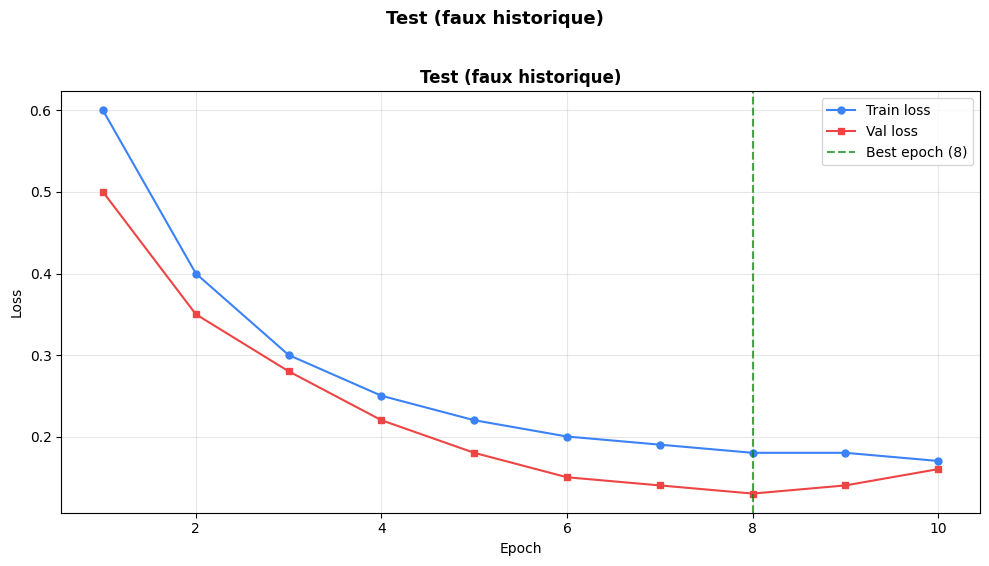

   plot_training_curves opérationnel


In [43]:
# === COURBES D'APPRENTISSAGE ENRICHIES ===

def plot_training_curves(history, title="Courbes d'apprentissage", save_path=None):
    """
    Affiche les courbes d'apprentissage : loss, accuracy et mIoU.

    Args:
        history : dict avec les clés 'train_loss', 'val_loss',
                   'train_accuracy', 'val_accuracy', 'train_miou', 'val_miou'
        title : titre du graphique
        save_path : si fourni, sauvegarde la figure

    Returns:
        fig matplotlib
    """
    epochs = list(range(1, len(history['train_loss']) + 1))

    # Détecter si on a les métriques détaillées
    has_detailed_metrics = 'train_accuracy' in history and 'train_miou' in history

    if has_detailed_metrics:
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))

        # === 1. Loss ===
        axes[0].plot(epochs, history['train_loss'], 'o-', label='Train',
                      color='#3b82f6', markersize=4)
        axes[0].plot(epochs, history['val_loss'], 's-', label='Val',
                      color='#ef4444', markersize=4)
        best_epoch_loss = np.argmin(history['val_loss']) + 1
        axes[0].axvline(best_epoch_loss, color='green', linestyle='--', alpha=0.7,
                          label=f"Best epoch ({best_epoch_loss})")
        axes[0].set_xlabel('Epoch')
        axes[0].set_ylabel('Loss')
        axes[0].set_title('Loss', fontsize=12, fontweight='bold')
        axes[0].legend(loc='upper right')
        axes[0].grid(alpha=0.3)

        # === 2. Accuracy ===
        axes[1].plot(epochs, history['train_accuracy'], 'o-', label='Train',
                      color='#3b82f6', markersize=4)
        axes[1].plot(epochs, history['val_accuracy'], 's-', label='Val',
                      color='#ef4444', markersize=4)
        axes[1].axvline(best_epoch_loss, color='green', linestyle='--', alpha=0.5)
        axes[1].set_xlabel('Epoch')
        axes[1].set_ylabel('Accuracy')
        axes[1].set_title('Accuracy', fontsize=12, fontweight='bold')
        axes[1].legend(loc='lower right')
        axes[1].grid(alpha=0.3)
        axes[1].set_ylim([0, 1])

        # === 3. mIoU ===
        axes[2].plot(epochs, history['train_miou'], 'o-', label='Train',
                      color='#3b82f6', markersize=4)
        axes[2].plot(epochs, history['val_miou'], 's-', label='Val',
                      color='#ef4444', markersize=4)
        axes[2].axvline(best_epoch_loss, color='green', linestyle='--', alpha=0.5)
        axes[2].set_xlabel('Epoch')
        axes[2].set_ylabel('mIoU')
        axes[2].set_title('mIoU', fontsize=12, fontweight='bold')
        axes[2].legend(loc='lower right')
        axes[2].grid(alpha=0.3)
        axes[2].set_ylim([0, 1])
    else:
        # Version simple si seulement la loss est disponible
        fig, ax = plt.subplots(figsize=(10, 5.5))
        ax.plot(epochs, history['train_loss'], 'o-', label='Train loss',
                  color='#3b82f6', markersize=5)
        ax.plot(epochs, history['val_loss'], 's-', label='Val loss',
                  color='#ef4444', markersize=5)
        best_epoch = np.argmin(history['val_loss']) + 1
        ax.axvline(best_epoch, color='green', linestyle='--', alpha=0.7,
                    label=f"Best epoch ({best_epoch})")
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')
        ax.set_title(title, fontsize=12, fontweight='bold')
        ax.legend(loc='upper right')
        ax.grid(alpha=0.3)

    plt.suptitle(title, fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight')
        print(f"   Sauvegardé : {save_path}")

    return fig


print(" plot_training_curves mise à jour avec accuracy et mIoU")


# Test avec un faux historique
print("=== Test plot_training_curves ===")
fake_history = {
    'train_loss': [0.6, 0.4, 0.3, 0.25, 0.22, 0.20, 0.19, 0.18, 0.18, 0.17],
    'val_loss':   [0.5, 0.35, 0.28, 0.22, 0.18, 0.15, 0.14, 0.13, 0.14, 0.16],
}
fig = plot_training_curves(fake_history, title="Test (faux historique)")
plt.show()
print("   plot_training_curves opérationnel")

### 5.3.2 Matrices de confusion (val + test)

Affiche les matrices de confusion **côte à côte** pour val et test, au seuil optimal
de chaque set. Inclut les pourcentages et compteurs.

=== Test plot_confusion_matrices ===


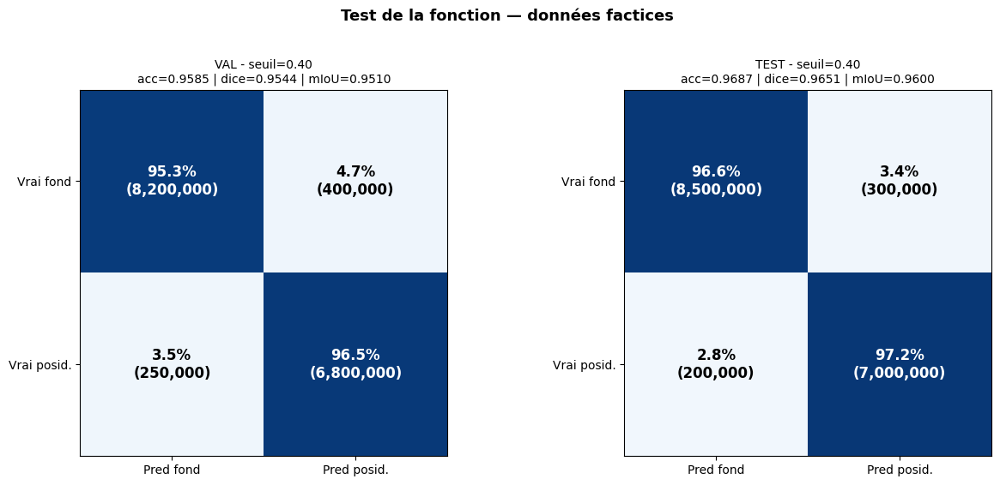

plot_confusion_matrices opérationnel


In [44]:
# === MATRICES DE CONFUSION ===

# === MATRICES DE CONFUSION (avec mIoU dans le titre) ===

def plot_confusion_matrices(val_results, test_results, title=None, save_path=None):
    """
    Affiche les matrices de confusion val et test côte à côte.

    Args:
        val_results : sortie de evaluate_full sur le set val
        test_results : sortie de evaluate_full sur le set test
        title : titre principal (si None, automatique)
        save_path : si fourni, sauvegarde la figure

    Returns:
        fig matplotlib
    """
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

    for ax, results, set_name in zip(axes, [val_results, test_results], ["VAL", "TEST"]):
        cm = results['confusion_matrix']
        thr = results['best_threshold']
        acc = results['best_metrics']['accuracy']
        dice = results['best_metrics']['dice']
        miou = results['best_metrics']['miou']

        # Pourcentages par ligne
        cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

        # Affichage
        im = ax.imshow(cm_pct, cmap='Blues', vmin=0, vmax=100, aspect='equal')

        # Annotations
        for i in range(2):
            for j in range(2):
                pct = cm_pct[i, j]
                count = cm[i, j]
                color = 'white' if pct > 50 else 'black'
                ax.text(j, i, f"{pct:.1f}%\n({count:,})",
                          ha='center', va='center',
                          color=color, fontsize=12, fontweight='bold')

        # Labels
        ax.set_xticks([0, 1])
        ax.set_yticks([0, 1])
        ax.set_xticklabels(['Pred fond', 'Pred posid.'])
        ax.set_yticklabels(['Vrai fond', 'Vrai posid.'])
        # NOUVEAU : ajout du mIoU dans le titre
        ax.set_title(f"{set_name} - seuil={thr:.2f}\n"
                      f"acc={acc:.4f} | dice={dice:.4f} | mIoU={miou:.4f}",
                       fontsize=10)

    if title is None:
        title = "Matrices de confusion (val + test)"
    plt.suptitle(title, fontsize=13, fontweight='bold', y=1.02)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight')
        print(f"   Sauvegardé : {save_path}")

    return fig




# Test (avec deux résultats factices)
# ============================================================
# TEST DE LA FONCTION AVEC DES RÉSULTATS FACTICES
# ============================================================

print("=== Test plot_confusion_matrices ===")

fake_val_results = {
    "confusion_matrix": np.array([
        [8200000, 400000],
        [250000, 6800000]
    ]),
    "best_threshold": 0.4,
    "best_metrics": {
        "accuracy": 0.9585,
        "dice": 0.9544,
        "miou": 0.9510
    },
}

fake_test_results = {
    "confusion_matrix": np.array([
        [8500000, 300000],
        [200000, 7000000]
    ]),
    "best_threshold": 0.4,
    "best_metrics": {
        "accuracy": 0.9687,
        "dice": 0.9651,
        "miou": 0.9600
    },
}

fig = plot_confusion_matrices(
    fake_val_results,
    fake_test_results,
    title="Test de la fonction — données factices"
)

plt.show()

print("plot_confusion_matrices opérationnel")

### 5.3.3 Courbes ROC et Precision-Recall

Affiche les courbes ROC et PR sur val + test côte à côte, avec les AUC.

=== Test plot_roc_pr_curves ===


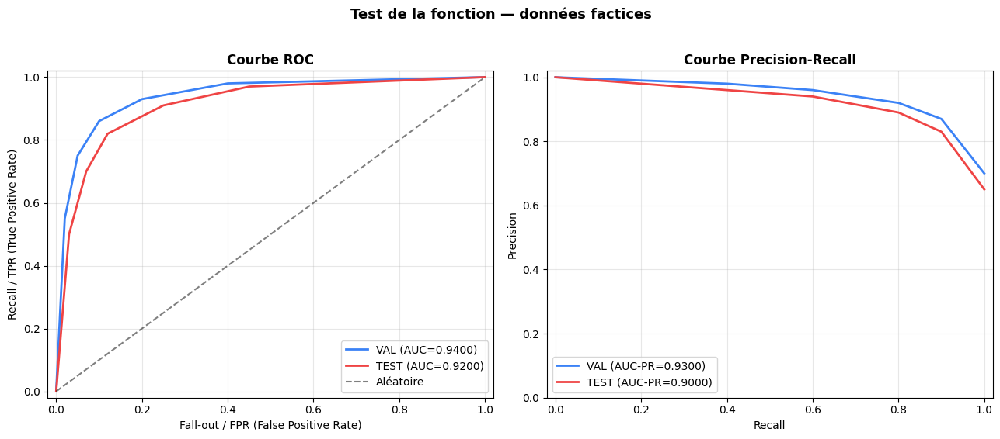

 plot_roc_pr_curves opérationnel


In [45]:
# === COURBES ROC ET PR ===

def plot_roc_pr_curves(
    val_results,
    test_results,
    title=None,
    save_path=None
):
    """
    Affiche les courbes ROC et Precision-Recall
    pour validation et test.

    Les courbes ROC et PR sont calculées à partir des
    probabilités continues du modèle et sont donc
    indépendantes du seuil de décision finalement retenu.

    Args:
        val_results :
            sortie de evaluate_full sur le jeu de validation

        test_results :
            sortie de evaluate_full sur le jeu de test

        title :
            titre principal de la figure

        save_path :
            chemin de sauvegarde optionnel

    Returns:
        fig : figure matplotlib
    """

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(13, 5.5)
    )

    # ============================================================
    # 1. COURBE ROC
    # ============================================================

    axes[0].plot(
        val_results["fpr"],
        val_results["tpr"],
        label=f"VAL (AUC={val_results['auc_roc']:.4f})",
        color="#3b82f6",
        linewidth=2
    )

    axes[0].plot(
        test_results["fpr"],
        test_results["tpr"],
        label=f"TEST (AUC={test_results['auc_roc']:.4f})",
        color="#ef4444",
        linewidth=2
    )

    # Diagonale correspondant à un classifieur aléatoire
    axes[0].plot(
        [0, 1],
        [0, 1],
        "k--",
        alpha=0.5,
        label="Aléatoire"
    )

    axes[0].set_xlabel(
        "Fall-out / FPR (False Positive Rate)"
    )

    axes[0].set_ylabel(
        "Recall / TPR (True Positive Rate)"
    )

    axes[0].set_title(
        "Courbe ROC",
        fontsize=12,
        fontweight="bold"
    )

    axes[0].legend(
        loc="lower right"
    )

    axes[0].grid(
        alpha=0.3
    )

    axes[0].set_xlim(
        [-0.02, 1.02]
    )

    axes[0].set_ylim(
        [-0.02, 1.02]
    )

    # ============================================================
    # 2. COURBE PRECISION-RECALL
    # ============================================================

    axes[1].plot(
        val_results["recall_curve"],
        val_results["precision_curve"],
        label=f"VAL (AUC-PR={val_results['auc_pr']:.4f})",
        color="#3b82f6",
        linewidth=2
    )

    axes[1].plot(
        test_results["recall_curve"],
        test_results["precision_curve"],
        label=f"TEST (AUC-PR={test_results['auc_pr']:.4f})",
        color="#ef4444",
        linewidth=2
    )

    axes[1].set_xlabel(
        "Recall"
    )

    axes[1].set_ylabel(
        "Precision"
    )

    axes[1].set_title(
        "Courbe Precision-Recall",
        fontsize=12,
        fontweight="bold"
    )

    axes[1].legend(
        loc="lower left"
    )

    axes[1].grid(
        alpha=0.3
    )

    axes[1].set_xlim(
        [-0.02, 1.02]
    )

    axes[1].set_ylim(
        [0.0, 1.02]
    )

    # ============================================================
    # 3. TITRE GLOBAL
    # ============================================================

    if title is None:
        title = (
            "Courbes ROC et Precision-Recall "
            "(validation + test)"
        )

    plt.suptitle(
        title,
        fontsize=13,
        fontweight="bold",
        y=1.02
    )

    plt.tight_layout()

    # ============================================================
    # 4. SAUVEGARDE OPTIONNELLE
    # ============================================================

    if save_path:
        plt.savefig(
            save_path,
            dpi=120,
            bbox_inches="tight"
        )

        print(
            f"✓ Sauvegardé : {save_path}"
        )

    return fig


# ============================================================
# TEST DE LA FONCTION AVEC DES DONNÉES FACTICES
# ============================================================

print("=== Test plot_roc_pr_curves ===")


fake_val_roc_pr = {

    # ROC
    "fpr": np.array([
        0.0,
        0.02,
        0.05,
        0.10,
        0.20,
        0.40,
        1.0
    ]),

    "tpr": np.array([
        0.0,
        0.55,
        0.75,
        0.86,
        0.93,
        0.98,
        1.0
    ]),

    "auc_roc": 0.94,

    # Precision-Recall
    "recall_curve": np.array([
        0.0,
        0.20,
        0.40,
        0.60,
        0.80,
        0.90,
        1.0
    ]),

    "precision_curve": np.array([
        1.0,
        0.99,
        0.98,
        0.96,
        0.92,
        0.87,
        0.70
    ]),

    "auc_pr": 0.93,
}


fake_test_roc_pr = {

    # ROC
    "fpr": np.array([
        0.0,
        0.03,
        0.07,
        0.12,
        0.25,
        0.45,
        1.0
    ]),

    "tpr": np.array([
        0.0,
        0.50,
        0.70,
        0.82,
        0.91,
        0.97,
        1.0
    ]),

    "auc_roc": 0.92,

    # Precision-Recall
    "recall_curve": np.array([
        0.0,
        0.20,
        0.40,
        0.60,
        0.80,
        0.90,
        1.0
    ]),

    "precision_curve": np.array([
        1.0,
        0.98,
        0.96,
        0.94,
        0.89,
        0.83,
        0.65
    ]),

    "auc_pr": 0.90,
}


fig = plot_roc_pr_curves(
    fake_val_roc_pr,
    fake_test_roc_pr,
    title="Test de la fonction — données factices"
)

plt.show()

print(
    " plot_roc_pr_curves opérationnel"
)

### 5.3.4 Résumé d'une expérience (vue d'ensemble)

Affiche en une seule figure les 3 visualisations principales d'une expérience :
- Courbes d'apprentissage
- Courbe ROC
- Courbe Precision-Recall

Très utile pour avoir une vue d'ensemble compacte.

In [46]:
# === VUE D'ENSEMBLE D'UNE EXPÉRIENCE ===

def plot_experiment_summary(history, val_results, test_results,
                              experiment_name="Experiment", save_path=None):
    """
    Affiche une vue d'ensemble compacte d'une expérience :
    - Courbes d'apprentissage (train/val loss)
    - Courbe ROC (val + test)
    - Courbe Precision-Recall (val + test)

    Args:
        history : dict avec 'train_loss' et 'val_loss'
        val_results : sortie de evaluate_full sur val
        test_results : sortie de evaluate_full sur test
        experiment_name : nom à afficher dans le titre
        save_path : sauvegarde optionnelle

    Returns:
        fig matplotlib
    """
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # === 1. Courbes d'apprentissage ===
    train_losses = history['train_loss']
    val_losses = history['val_loss']
    epochs = list(range(1, len(train_losses) + 1))

    axes[0].plot(epochs, train_losses, 'o-', label='Train loss',
                  color='#3b82f6', markersize=5)
    axes[0].plot(epochs, val_losses, 's-', label='Val loss',
                  color='#ef4444', markersize=5)

    best_epoch = np.argmin(val_losses) + 1
    best_val = min(val_losses)
    axes[0].axvline(best_epoch, color='green', linestyle='--', alpha=0.7,
                     label=f"Best epoch ({best_epoch})")
    axes[0].plot(best_epoch, best_val, marker='*', markersize=18, color='green',
                  markeredgecolor='darkgreen', zorder=5)

    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title(f"Courbes d'apprentissage - {experiment_name}", fontsize=11)
    axes[0].legend(loc='upper right', fontsize=9)
    axes[0].grid(alpha=0.3)

    # === 2. Courbe ROC ===
    axes[1].plot(val_results['fpr'], val_results['tpr'],
                  label=f"VAL (AUC={val_results['auc_roc']:.4f})",
                  color='#3b82f6', linewidth=2)
    axes[1].plot(test_results['fpr'], test_results['tpr'],
                  label=f"TEST (AUC={test_results['auc_roc']:.4f})",
                  color='#ef4444', linewidth=2)
    axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
    axes[1].set_xlabel('FPR')
    axes[1].set_ylabel('TPR')
    axes[1].set_title('Courbe ROC', fontsize=11)
    axes[1].legend(loc='lower right', fontsize=9)
    axes[1].grid(alpha=0.3)
    axes[1].set_xlim([-0.02, 1.02])
    axes[1].set_ylim([-0.02, 1.02])

    # === 3. Courbe PR ===
    axes[2].plot(val_results['recall_curve'], val_results['precision_curve'],
                  label=f"VAL (AUC-PR={val_results['auc_pr']:.4f})",
                  color='#3b82f6', linewidth=2)
    axes[2].plot(test_results['recall_curve'], test_results['precision_curve'],
                  label=f"TEST (AUC-PR={test_results['auc_pr']:.4f})",
                  color='#ef4444', linewidth=2)
    axes[2].set_xlabel('Recall')
    axes[2].set_ylabel('Precision')
    axes[2].set_title('Courbe Precision-Recall', fontsize=11)
    axes[2].legend(loc='lower left', fontsize=9)
    axes[2].grid(alpha=0.3)
    axes[2].set_xlim([-0.02, 1.02])
    axes[2].set_ylim([0.0, 1.02])

    plt.suptitle(experiment_name, fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight')
        print(f"   Sauvegardé : {save_path}")

    return fig


print(" plot_experiment_summary défini")
print("  (sera testé en conditions réelles dans les sections d'expériences)")

 plot_experiment_summary défini
  (sera testé en conditions réelles dans les sections d'expériences)


## 5.4 Comparaison d'expériences (tableau récapitulatif)

Lorsqu'on lance plusieurs expériences, on a besoin de les **comparer** côte à côte.
Cette fonction prend une liste de résultats et produit un tableau formaté.

In [47]:
# === COMPARAISON D'EXPÉRIENCES (avec mIoU ajouté) ===

def build_comparison_table(experiments_results, include_train_val=True):
    rows = []

    for name, exp in experiments_results.items():
        row = {'experiment': name}

        if 'test_results' in exp:
            test = exp['test_results']
            tm = test['best_metrics']
            row['test_threshold'] = test['best_threshold']
            row['test_accuracy'] = tm['accuracy']
            row['test_precision'] = tm['precision']
            row['test_recall'] = tm['recall']
            row['test_fallout'] = tm['fallout']
            row['test_recall_minus_fallout'] = tm['recall_minus_fallout']  # NOUVEAU
            row['test_dice'] = tm['dice']
            row['test_iou'] = tm['iou']
            row['test_miou'] = tm['miou']
            row['test_auc_roc'] = test['auc_roc']
            row['test_auc_pr'] = test['auc_pr']

        if include_train_val and 'val_results' in exp:
            val = exp['val_results']
            vm = val['best_metrics']
            row['val_threshold'] = val['best_threshold']
            row['val_accuracy'] = vm['accuracy']
            row['val_recall_minus_fallout'] = vm['recall_minus_fallout']   # NOUVEAU
            row['val_dice'] = vm['dice']
            row['val_iou'] = vm['iou']
            row['val_miou'] = vm['miou']

        rows.append(row)

    return pd.DataFrame(rows)


def display_comparison_table(experiments_results,  sort_by='test_recall_minus_fallout'):
    """
    Affiche un tableau comparatif des expériences, trié par une métrique.

    Args:
        experiments_results : dict des résultats
        sort_by : métrique pour trier le tableau (default 'test_recall_minus_fallout')
    """
    df = build_comparison_table(experiments_results)

    if sort_by in df.columns:
        df = df.sort_values(sort_by, ascending=False)

    # Formatage des colonnes numériques
    for col in df.columns:
        if col == 'experiment':
            continue
        if 'threshold' in col:
            df[col] = df[col].apply(lambda x: f"{x:.2f}" if pd.notna(x) else "—")
        elif 'auc' in col:
            df[col] = df[col].apply(lambda x: f"{x:.4f}" if pd.notna(x) else "—")
        else:
            df[col] = df[col].apply(lambda x: f"{x*100:.2f}%" if pd.notna(x) else "—")

    print(f"=== Tableau comparatif (trié par {sort_by} décroissant) ===\n")
    print(df.to_string(index=False))
    return df


print("    build_comparison_table et display_comparison_table définis")
print("    (seront utilisés dans les sections d'expériences pour comparer les résultats)")

    build_comparison_table et display_comparison_table définis
    (seront utilisés dans les sections d'expériences pour comparer les résultats)


## 5.5 Test global de toutes les fonctions

Vérification rapide que toutes les fonctions d'évaluation sont opérationnelles.

In [47]:
# === TEST GLOBAL ===

print("=== Vérification des fonctions d'évaluation ===\n")

fonctions_disponibles = [
    ('evaluate_full', evaluate_full),
    ('plot_training_curves', plot_training_curves),
    ('plot_confusion_matrices', plot_confusion_matrices),
    ('plot_roc_pr_curves', plot_roc_pr_curves),
    ('plot_experiment_summary', plot_experiment_summary),
    ('build_comparison_table', build_comparison_table),
    ('display_comparison_table', display_comparison_table),
]

for name, fn in fonctions_disponibles:
    print(f"   {name}")

print(f"\n=== Section 5 terminée ({len(fonctions_disponibles)} fonctions disponibles) ===")

=== Vérification des fonctions d'évaluation ===

   evaluate_full
   plot_training_curves
   plot_confusion_matrices
   plot_roc_pr_curves
   plot_experiment_summary
   build_comparison_table
   display_comparison_table

=== Section 5 terminée (7 fonctions disponibles) ===


# 6. Fonctions d'entraînement

## 6.1 Stratégie d'entraînement

Ce notebook propose **deux paradigmes d'entraînement** sélectionnables via la
configuration (`config['training_mode']`) :

### Paradigme "epochs" (approche moderne standard)

- Une **epoch** = un passage complet sur l'ensemble du train
- Early stopping basé sur le nombre d'**epochs** sans amélioration
- Validation à la fin de chaque epoch
- Patience exprimée en epochs (5 à 10)

### Paradigme "iterations" (Xie et al., 2021 — l'article SegFormer original)

- Une **itération** = un seul pas de gradient (un batch)
- Entraînement pour un nombre fixe d'**itérations**
- Validation périodique tous les `val_every` itérations
- Early stopping basé sur le nombre d'**évaluations** sans amélioration
- C'est l'approche utilisée dans le papier SegFormer original
  (Xie et al., 2021 entraînent sur 160k itérations sur ADE20K)

### Éléments communs aux deux paradigmes

**1. Early stopping** : arrêt automatique quand la val_loss stagne, évite le
surapprentissage et économise du GPU.

**2. Sauvegarde du meilleur modèle** : à chaque amélioration de val_loss, on
sauvegarde le state_dict sur Drive (résistance aux déconnexions Colab). À la fin,
on restaure le meilleur état.

**3. Suivi de l'historique** : train_loss, val_loss et métriques enregistrés pour
tracer les courbes d'apprentissage.

**4. Optimizer** : Adam, lr par défaut 1e-4, weight_decay 1e-4.


### Pipeline des expériences

`run_experiment(config)` :
1. Créer les datasets (train, val, test) selon config
2. Créer le modèle SegFormer via `build_model()`
3. Créer la loss selon `config['loss']`
4. Lancer l'entraînement selon `config['training_mode']` ('epochs' ou 'iterations')
5. Charger le meilleur modèle
6. Évaluer sur val et test (`evaluate_full`)
7. Générer les visualisations
8. Sauvegarder tous les résultats sur Drive
9. Retourner un dict avec tous les résultats


## 6.2 Fonction d'entraînement principale

`train_segformer_epochs` ou `train_segformer_iterations` réalisent la boucle d'entraînement complète avec :
- Early stopping sur val_loss
- Sauvegarde immédiate du meilleur modèle sur Drive : création de deux dossiers pour entrainement en epochs et l'autre en itérations
- Affichage de la progression
- Retour de l'historique pour visualisation

## 6.2.1 Fonction d'entraînement en epochs

In [48]:
# train_segformer_epochs :
#   - Sauvegarde un _resume.pth à chaque epoch (état complet : model + optimizer + historique)
#   - Reprise automatique si _resume.pth existe au démarrage
#   - Le _best.pth reste inchangé (meilleur modèle seulement)
#
# train_segformer_iterations :
#   - Sauvegarde un _resume.pth à chaque validation (toutes les val_every itérations)
#   - Reprise automatique si _resume.pth existe au démarrage
#   - Le _best.pth reste inchangé (meilleur modèle seulement)
#
# USAGE :
#   Aucun changement dans run_experiment — la reprise est transparente.
#   Si Colab se déconnecte en plein entraînement, relancer run_experiment
#   avec le même config['name'] suffit : le _resume.pth est détecté
#   et l'entraînement repart exactement là où il s'est arrêté.
#
# NETTOYAGE :
#   Le _resume.pth est supprimé automatiquement en fin d'entraînement
#   (normal ou early stopping) pour ne pas encombrer le Drive.
# =============================================================================


def compute_batch_metrics(logits, masks):
    """
    Calcule rapidement les métriques principales sur un batch.
    Utilisé pour le suivi pendant l'entraînement (moins coûteux que evaluate_full).

    Args:
        logits : [B, C, H, W] - sorties du modèle
        masks : [B, H, W] - vérité terrain

    Returns:
        dict avec :
            - accuracy : taux global de pixels bien classés
            - precision : TP / (TP + FP) - fiabilité des prédictions positives
            - recall : TP / (TP + FN) - capacité de détection
            - f1 : 2 × (P × R) / (P + R) - équilibre précision/recall (= Dice en binaire)
            - dice : 2 × TP / (2×TP + FP + FN) - recouvrement régional
            - iou : TP / (TP + FP + FN) - intersection sur union (classe posidonie)
            - miou : (IoU_fond + IoU_posidonie) / 2 - moyenne sur les 2 classes

    Note : en classification binaire, F1 et Dice sont mathématiquement identiques.
    On garde les deux pour la clarté terminologique.
    """
    with torch.no_grad():
        probas = F.softmax(logits, dim=1)
        preds = probas.argmax(dim=1)  # [B, H, W]

        # Flatten pour calcul vectorisé
        preds_flat = preds.view(-1)
        masks_flat = masks.view(-1)

        tp = ((preds_flat == 1) & (masks_flat == 1)).sum().item()
        tn = ((preds_flat == 0) & (masks_flat == 0)).sum().item()
        fp = ((preds_flat == 1) & (masks_flat == 0)).sum().item()
        fn = ((preds_flat == 0) & (masks_flat == 1)).sum().item()

        total = tp + tn + fp + fn

        accuracy  = (tp + tn) / total if total > 0 else 0
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall    = tp / (tp + fn) if (tp + fn) > 0 else 0

        if precision + recall > 0:
            f1 = 2 * (precision * recall) / (precision + recall)
        else:
            f1 = 0

        dice    = (2 * tp) / (2 * tp + fp + fn) if (2 * tp + fp + fn) > 0 else 0
        iou_pos = tp / (tp + fp + fn) if (tp + fp + fn) > 0 else 0
        iou_bg  = tn / (tn + fn + fp) if (tn + fn + fp) > 0 else 0
        miou    = (iou_pos + iou_bg) / 2

        return {
            'accuracy':  accuracy,
            'precision': precision,
            'recall':    recall,
            'f1':        f1,
            'dice':      dice,
            'iou':       iou_pos,
            'miou':      miou,
        }


# =============================================================================
# ENTRAÎNEMENT PAR EPOCHS — AVEC REPRISE
# =============================================================================

def train_segformer_epochs(model, train_loader, val_loader, loss_fn, optimizer,
                           n_epochs=DEFAULT_EPOCHS, patience=DEFAULT_PATIENCE,
                           backup_path=None, device=DEVICE, verbose=True):
    """
    Entraîne SegFormer par epochs avec early stopping et reprise automatique.

    Fichiers créés dans le même dossier que backup_path :
        {name}_best.pth   - meilleur modèle (val_loss minimale)
        {name}_resume.pth - checkpoint de reprise (supprimé en fin d'entraînement)

    Args:
        model        : modèle PyTorch
        train_loader : DataLoader entraînement
        val_loader   : DataLoader validation
        loss_fn      : fonction de perte
        optimizer    : optimiseur Adam
        n_epochs     : nombre maximum d'epochs
        patience     : patience early stopping
        backup_path  : chemin du _best.pth (ex: SINGLESPLIT_DIR/nom_best.pth)
        device       : device CUDA/CPU
        verbose      : affichage progression

    Returns:
        dict avec 'history', 'best_epoch', 'best_val_loss',
                  'best_state_dict', 'n_epochs_run'
    """
    model = model.to(device)

    metric_names = ['accuracy', 'precision', 'recall', 'f1', 'dice', 'miou']

    # Chemin du checkpoint de reprise
    resume_path = backup_path.replace('_best.pth', '_resume.pth') if backup_path else None

    # -------------------------------------------------------------------------
    # REPRISE : charger le checkpoint si disponible
    # -------------------------------------------------------------------------
    history = {
        'train_loss': [], 'val_loss': [],
        **{f'train_{m}': [] for m in metric_names},
        **{f'val_{m}':   [] for m in metric_names},
    }
    best_val_loss     = float('inf')
    best_epoch        = 0
    best_state_dict   = None
    patience_counter  = 0
    start_epoch       = 1

    if resume_path and os.path.exists(resume_path):
        print(f"\n  >>> Checkpoint de reprise trouvé : {os.path.basename(resume_path)}")
        ckpt = torch.load(resume_path, map_location=device)
        model.load_state_dict(ckpt['state_dict'])
        optimizer.load_state_dict(ckpt['optimizer_state_dict'])
        history          = ckpt['history']
        best_val_loss    = ckpt['best_val_loss']
        best_epoch       = ckpt['best_epoch']
        patience_counter = ckpt['patience_counter']
        start_epoch      = ckpt['epoch'] + 1
        # Recharger le meilleur state_dict depuis _best.pth si disponible
        if backup_path and os.path.exists(backup_path):
            best_ckpt       = torch.load(backup_path, map_location=device)
            best_state_dict = best_ckpt['state_dict']
        print(f"      Reprise depuis epoch {ckpt['epoch']} "
              f"(best={best_epoch}, patience={patience_counter}/{patience})\n")
    # -------------------------------------------------------------------------

    if verbose:
        print(f"=== Entraînement SegFormer (paradigme EPOCHS) ===")
        print(f"  Epochs : {start_epoch} -> {n_epochs} | Patience : {patience} | Device : {device}")
        if backup_path:
            print(f"  Best    : {backup_path}")
        if resume_path:
            print(f"  Resume  : {resume_path}")
        print()

    for epoch in range(start_epoch, n_epochs + 1):

        # === PHASE D'ENTRAÎNEMENT ===
        model.train()
        total_train_loss   = 0
        n_train_batches    = 0
        train_metrics_sum  = {m: 0 for m in metric_names}

        train_pbar = tqdm(train_loader,
                          desc=f"Epoch {epoch:3d}/{n_epochs} [train]",
                          leave=False, ncols=100)

        for imgs, masks in train_pbar:
            imgs  = imgs.to(device)
            masks = masks.to(device)

            optimizer.zero_grad()
            logits = model(imgs)
            loss   = loss_fn(logits, masks)
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item()
            n_train_batches  += 1

            batch_metrics = compute_batch_metrics(logits, masks)
            for m in metric_names:
                train_metrics_sum[m] += batch_metrics[m]

            train_pbar.set_postfix({
                'loss': f"{loss.item():.4f}",
                'acc':  f"{batch_metrics['accuracy']:.3f}",
                'f1':   f"{batch_metrics['f1']:.3f}",
            })

        train_loss    = total_train_loss / n_train_batches
        train_metrics = {m: v / n_train_batches for m, v in train_metrics_sum.items()}

        # === PHASE DE VALIDATION ===
        model.eval()
        total_val_loss  = 0
        n_val_batches   = 0
        val_metrics_sum = {m: 0 for m in metric_names}

        val_pbar = tqdm(val_loader,
                        desc=f"Epoch {epoch:3d}/{n_epochs} [val]  ",
                        leave=False, ncols=100)

        with torch.no_grad():
            for imgs, masks in val_pbar:
                imgs  = imgs.to(device)
                masks = masks.to(device)

                logits = model(imgs)
                loss   = loss_fn(logits, masks)

                total_val_loss += loss.item()
                n_val_batches  += 1

                batch_metrics = compute_batch_metrics(logits, masks)
                for m in metric_names:
                    val_metrics_sum[m] += batch_metrics[m]

                val_pbar.set_postfix({
                    'loss': f"{loss.item():.4f}",
                    'acc':  f"{batch_metrics['accuracy']:.3f}",
                    'f1':   f"{batch_metrics['f1']:.3f}",
                })

        val_loss    = total_val_loss / n_val_batches
        val_metrics = {m: v / n_val_batches for m, v in val_metrics_sum.items()}

        # === HISTORIQUE ===
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        for m in metric_names:
            history[f'train_{m}'].append(train_metrics[m])
            history[f'val_{m}'].append(val_metrics[m])

        # === EARLY STOPPING + SAUVEGARDE BEST ===
        if val_loss < best_val_loss:
            best_val_loss   = val_loss
            best_epoch      = epoch
            best_state_dict = {k: v.clone() for k, v in model.state_dict().items()}
            patience_counter = 0
            marker = "*"

            if backup_path is not None:
                torch.save({
                    'epoch':      epoch,
                    'state_dict': best_state_dict,
                    'val_loss':   val_loss,
                    'train_loss': train_loss,
                    'val_metrics': val_metrics,
                }, backup_path)
        else:
            patience_counter += 1
            marker = " "

        # === SAUVEGARDE RESUME (à chaque epoch) ===
        if resume_path is not None:
            torch.save({
                'epoch':                epoch,
                'state_dict':           model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'history':              history,
                'best_val_loss':        best_val_loss,
                'best_epoch':           best_epoch,
                'patience_counter':     patience_counter,
            }, resume_path)

        # === AFFICHAGE ===
        if verbose:
            print(f"  Epoch {epoch:3d}/{n_epochs} | "
                  f"train: loss={train_loss:.4f} acc={train_metrics['accuracy']:.4f} "
                  f"P={train_metrics['precision']:.4f} R={train_metrics['recall']:.4f} "
                  f"F1={train_metrics['f1']:.4f} mIoU={train_metrics['miou']:.4f}")
            print(f"              | "
                  f"val:   loss={val_loss:.4f} acc={val_metrics['accuracy']:.4f} "
                  f"P={val_metrics['precision']:.4f} R={val_metrics['recall']:.4f} "
                  f"F1={val_metrics['f1']:.4f} mIoU={val_metrics['miou']:.4f} "
                  f"{marker} pat={patience_counter}/{patience}")

        if patience_counter >= patience:
            if verbose:
                print(f"\n  >>> Early stopping à l'epoch {epoch}")
            break

    # Restaurer le meilleur modèle
    if best_state_dict is not None:
        model.load_state_dict(best_state_dict)

    # Nettoyer le resume (entraînement terminé normalement)
    if resume_path and os.path.exists(resume_path):
        os.remove(resume_path)
        if verbose:
            print(f"  >>> {os.path.basename(resume_path)} supprimé (entraînement terminé)")

    if verbose:
        best_idx = best_epoch - 1
        print(f"\n   Entraînement terminé : best epoch = {best_epoch}, "
              f"best val_loss = {best_val_loss:.4f}")
        print(f"    Au best epoch : "
              f"acc={history['val_accuracy'][best_idx]:.4f}, "
              f"P={history['val_precision'][best_idx]:.4f}, "
              f"R={history['val_recall'][best_idx]:.4f}, "
              f"F1={history['val_f1'][best_idx]:.4f}, "
              f"mIoU={history['val_miou'][best_idx]:.4f}")

    return {
        'history':        history,
        'best_epoch':     best_epoch,
        'best_val_loss':  best_val_loss,
        'best_state_dict': best_state_dict,
        'n_epochs_run':   epoch,
    }


## 6.2.2 Fonction d'entraînement en itérations (Martin Abadal et al.)

In [49]:


# =============================================================================
# ENTRAÎNEMENT PAR ITÉRATIONS — AVEC REPRISE (Martin-Abadal et al. 2018)
# =============================================================================

def train_segformer_iterations(model, train_loader, val_loader, loss_fn, optimizer,
                                max_iterations=20000, val_every=500,
                                patience=10, backup_path=None,
                                device=DEVICE, verbose=True):
    """
    Entraîne SegFormer par itérations avec early stopping et reprise automatique.

    Fichiers créés dans le même dossier que backup_path :
        {name}_best.pth   — meilleur modèle (val_loss minimale)
        {name}_resume.pth — checkpoint de reprise (supprimé en fin d'entraînement)

    Args:
        model          : modèle PyTorch
        train_loader   : DataLoader entraînement
        val_loader     : DataLoader validation
        loss_fn        : fonction de perte
        optimizer      : optimiseur Adam
        max_iterations : nombre maximum d'itérations (pas de gradient)
        val_every      : fréquence de validation (en itérations)
        patience       : nb d'évaluations sans amélioration tolérées
        backup_path    : chemin du _best.pth
        device         : device CUDA/CPU
        verbose        : affichage progression

    Returns:
        dict avec 'history', 'best_iteration', 'best_val_loss',
                  'best_state_dict', 'n_iterations_run', 'training_mode'
    """
    model = model.to(device)

    metric_names = ['accuracy', 'precision', 'recall', 'f1', 'dice', 'miou']

    # Chemin du checkpoint de reprise
    resume_path = backup_path.replace('_best.pth', '_resume.pth') if backup_path else None

    # -------------------------------------------------------------------------
    # REPRISE : charger le checkpoint si disponible
    # -------------------------------------------------------------------------
    history = {
        'iteration': [], 'train_loss': [], 'val_loss': [],
        **{f'val_{m}': [] for m in metric_names},
    }
    best_val_loss            = float('inf')
    best_iteration           = 0
    best_state_dict          = None
    evals_without_improvement = 0
    start_iteration          = 1

    if resume_path and os.path.exists(resume_path):
        print(f"\n  >>> Checkpoint de reprise trouvé : {os.path.basename(resume_path)}")
        ckpt = torch.load(resume_path, map_location=device)
        model.load_state_dict(ckpt['state_dict'])
        optimizer.load_state_dict(ckpt['optimizer_state_dict'])
        history                   = ckpt['history']
        best_val_loss             = ckpt['best_val_loss']
        best_iteration            = ckpt['best_iteration']
        evals_without_improvement = ckpt['evals_without_improvement']
        start_iteration           = ckpt['iteration'] + 1
        # Recharger le meilleur state_dict depuis _best.pth si disponible
        if backup_path and os.path.exists(backup_path):
            best_ckpt       = torch.load(backup_path, map_location=device)
            best_state_dict = best_ckpt['state_dict']
        print(f"      Reprise depuis itération {ckpt['iteration']} "
              f"(best={best_iteration}, "
              f"patience={evals_without_improvement}/{patience})\n")
    # -------------------------------------------------------------------------

    if verbose:
        print(f"=== Entraînement SegFormer (paradigme ITÉRATIONS) ===")
        print(f"  Itérations : {start_iteration} → {max_iterations} "
              f"| val_every : {val_every} | Patience : {patience} | Device : {device}")
        if backup_path:
            print(f"  Best   : {backup_path}")
        if resume_path:
            print(f"  Resume : {resume_path}")
        print()

    # Itérateur infini sur le train_loader
    def infinite_loader(loader):
        while True:
            for batch in loader:
                yield batch

    train_iter = infinite_loader(train_loader)

    # Si on reprend, avancer l'itérateur pour ne pas retraiter les mêmes batches
    if start_iteration > 1:
        batches_to_skip = (start_iteration - 1) % len(train_loader)
        for _ in range(batches_to_skip):
            next(train_iter)

    # Accumulateurs train entre deux validations
    running_train_loss       = 0.0
    n_train_steps_since_val  = 0
    stop = False

    pbar = tqdm(range(start_iteration, max_iterations + 1),
                desc="Itérations", ncols=100)

    for iteration in pbar:

        # === UN PAS DE GRADIENT ===
        model.train()
        imgs, masks = next(train_iter)
        imgs  = imgs.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()
        logits = model(imgs)
        loss   = loss_fn(logits, masks)
        loss.backward()
        optimizer.step()

        running_train_loss      += loss.item()
        n_train_steps_since_val += 1

        pbar.set_postfix({
            'train_loss': f"{loss.item():.4f}",
            'best_iter':  best_iteration,
        })

        # === VALIDATION PÉRIODIQUE ===
        if iteration % val_every == 0:
            model.eval()
            total_val_loss  = 0
            n_val_batches   = 0
            val_metrics_sum = {m: 0 for m in metric_names}

            with torch.no_grad():
                for v_imgs, v_masks in val_loader:
                    v_imgs  = v_imgs.to(device)
                    v_masks = v_masks.to(device)
                    v_logits = model(v_imgs)
                    v_loss   = loss_fn(v_logits, v_masks)
                    total_val_loss += v_loss.item()
                    n_val_batches  += 1
                    bm = compute_batch_metrics(v_logits, v_masks)
                    for m in metric_names:
                        val_metrics_sum[m] += bm[m]

            val_loss    = total_val_loss / n_val_batches
            val_metrics = {m: v / n_val_batches for m, v in val_metrics_sum.items()}
            train_loss_avg = running_train_loss / n_train_steps_since_val

            # Historique
            history['iteration'].append(iteration)
            history['train_loss'].append(train_loss_avg)
            history['val_loss'].append(val_loss)
            for m in metric_names:
                history[f'val_{m}'].append(val_metrics[m])

            # Early stopping + sauvegarde best
            if val_loss < best_val_loss:
                best_val_loss   = val_loss
                best_iteration  = iteration
                best_state_dict = {k: v.clone() for k, v in model.state_dict().items()}
                evals_without_improvement = 0
                marker = "*"

                if backup_path is not None:
                    torch.save({
                        'iteration':   iteration,
                        'state_dict':  best_state_dict,
                        'val_loss':    val_loss,
                        'val_metrics': val_metrics,
                    }, backup_path)
            else:
                evals_without_improvement += 1
                marker = " "

            # === SAUVEGARDE RESUME (à chaque validation) ===
            if resume_path is not None:
                torch.save({
                    'iteration':                iteration,
                    'state_dict':               model.state_dict(),
                    'optimizer_state_dict':     optimizer.state_dict(),
                    'history':                  history,
                    'best_val_loss':            best_val_loss,
                    'best_iteration':           best_iteration,
                    'evals_without_improvement': evals_without_improvement,
                }, resume_path)

            if verbose:
                print(f"  Iter {iteration:6d}/{max_iterations} | "
                      f"train={train_loss_avg:.4f} | val={val_loss:.4f} "
                      f"acc={val_metrics['accuracy']:.4f} "
                      f"F1={val_metrics['f1']:.4f} mIoU={val_metrics['miou']:.4f} "
                      f"{marker} ({evals_without_improvement}/{patience})")

            # Reset accumulateurs
            running_train_loss      = 0.0
            n_train_steps_since_val = 0

            # Arrêt anticipé
            if evals_without_improvement >= patience:
                if verbose:
                    print(f"\n  >>> Early stopping à l'itération {iteration}")
                stop = True

        if stop:
            break

    pbar.close()

    # Restaurer le meilleur modèle
    if best_state_dict is not None:
        model.load_state_dict(best_state_dict)

    # Nettoyer le resume (entraînement terminé normalement)
    if resume_path and os.path.exists(resume_path):
        os.remove(resume_path)
        if verbose:
            print(f"  >>> {os.path.basename(resume_path)} supprimé (entraînement terminé)")

    if verbose:
        print(f"\n   Entraînement terminé : best iteration = {best_iteration}, "
              f"best val_loss = {best_val_loss:.4f}")
        if best_iteration in history['iteration']:
            best_idx = history['iteration'].index(best_iteration)
            print(f"    Au best : acc={history['val_accuracy'][best_idx]:.4f}, "
                  f"F1={history['val_f1'][best_idx]:.4f}, "
                  f"mIoU={history['val_miou'][best_idx]:.4f}")

    return {
        'history':          history,
        'best_iteration':   best_iteration,
        'best_val_loss':    best_val_loss,
        'best_state_dict':  best_state_dict,
        'n_iterations_run': iteration,
        'training_mode':    'iterations',
    }


print(" compute_batch_metrics définie")
print(" train_segformer_epochs définie (avec reprise automatique)")
print(" train_segformer_iterations définie (avec reprise automatique)")

 compute_batch_metrics définie
 train_segformer_epochs définie (avec reprise automatique)
 train_segformer_iterations définie (avec reprise automatique)


## 6.3 Pipeline complet : `run_experiment`

Cette fonction combine **tout** le pipeline pour une expérience :
1. Création des datasets selon la configuration
2. Création du modèle
3. Création de la loss
4. Entraînement avec early stopping
5. Évaluation sur val et test
6. Génération des visualisations
7. Sauvegarde de tous les résultats sur Drive

**Avantage** : un seul appel pour lancer une expérience complète.

In [50]:
# === REPRODUCTIBILITÉ STRICTE ===

import random

def set_seed(seed=SEED, deterministic=True):
    """
    Fixe TOUS les seeds pour garantir la reproductibilité d'une expérience.

    Args:
        seed : valeur du seed (default : SEED global = 42)
        deterministic : si True, force les opérations CUDA déterministes
                        (légèrement plus lent mais 100% reproductible)
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    if deterministic:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
        try:
            torch.use_deterministic_algorithms(True, warn_only=True)
        except AttributeError:
            pass

    # Variable d'environnement pour cuBLAS (à utiliser avant le premier appel CUDA)
    os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'


# Test
set_seed(SEED, deterministic=True)
print(f" Reproductibilité activée (SEED={SEED}, deterministic=True)")

 Reproductibilité activée (SEED=42, deterministic=True)


In [51]:
# === PIPELINE COMPLET POUR UNE EXPÉRIENCE ===

def run_experiment(config, semeda_net=None, save_dir=None, verbose=True):
    """
    Pipeline complet pour une expérience : datasets -> modèle -> loss -> train -> eval -> save.

    Args:
        config : dict avec les clés :
            - 'name' : nom de l'expérience (pour les fichiers de sortie)
            - 'loss' : "ce", "ce_dice", ou "ce_semeda"
            - 'img_h', 'img_w' : résolution (défaut IMG_H, IMG_W)
            - 'preprocess' : nom du prétraitement ou None
            - 'aug_strategy' : nom de la stratégie d'aug ("minimal", "standard", "fort")
            - 'lr' : learning rate (défaut DEFAULT_LR)
            - 'batch_size' : taille du batch (défaut BATCH_SIZE)
            - 'n_epochs' : nombre max d'époques (défaut DEFAULT_EPOCHS)
            - 'patience' : patience early stopping (défaut DEFAULT_PATIENCE)
            - 'weight_decay' : weight decay Adam (défaut DEFAULT_WEIGHT_DECAY)
        semeda_net : SemedaNet pré-entraîné (requis si loss="ce_semeda")
        save_dir : dossier de sauvegarde (défaut : SINGLESPLIT_DIR)
        verbose : si True, affiche la progression

    Returns:
        dict avec toutes les sorties de l'expérience
    """

    # === RESET DU SEED pour garantir la reproductibilité ===
    set_seed(SEED, deterministic=True)

    # === Configuration avec defaults ===
    name = config['name']
    loss_name = config['loss']
    img_h = config.get('img_h', IMG_H)
    img_w = config.get('img_w', IMG_W)
    preprocess = config.get('preprocess', None)
    aug_strategy = config.get('aug_strategy', 'standard')
    lr = config.get('lr', DEFAULT_LR)
    batch_size = config.get('batch_size', BATCH_SIZE)
    n_epochs = config.get('n_epochs', DEFAULT_EPOCHS)
    patience = config.get('patience', DEFAULT_PATIENCE)
    weight_decay = config.get('weight_decay', DEFAULT_WEIGHT_DECAY)
    threshold_criterion = config.get('threshold_criterion', DEFAULT_THRESHOLD_CRITERION)
    training_mode = config.get('training_mode', 'epochs')  # 'epochs' ou 'iterations'
    max_iterations = config.get('max_iterations', 20000)
    val_every = config.get('val_every', 500)

    if save_dir is None:
        save_dir = SINGLESPLIT_DIR
    os.makedirs(save_dir, exist_ok=True)

    if verbose:
        print(f"\n{'='*70}")
        print(f"=== EXPÉRIENCE : {name} ===")
        print(f"{'='*70}")
        print(f"  Config : loss={loss_name}, preprocess={preprocess}, aug={aug_strategy}")
        print(f"           resolution={img_h}x{img_w}, lr={lr}, batch={batch_size}")
        print(f"           max_epochs={n_epochs}, patience={patience}")

    # === 1. Création des datasets ===
    train_ds = PosidoniaDatasetFromCSV(
        csv_path=TRAIN_CSV, root_path=LOCAL_PATH, split="training",
        img_h=img_h, img_w=img_w,
        augment=True, aug_strategy=aug_strategy, preprocess=preprocess,
    )
    val_ds = PosidoniaDatasetFromCSV(
        csv_path=VAL_CSV, root_path=LOCAL_PATH, split="training",
        img_h=img_h, img_w=img_w,
        augment=False, preprocess=preprocess,
    )
    test_ds = PosidoniaDataset(
        root_path=LOCAL_PATH, split="testing",
        img_h=img_h, img_w=img_w,
        augment=False, preprocess=preprocess,
    )

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False)

    if verbose:
        print(f"\n  Datasets : train={len(train_ds)}, val={len(val_ds)}, test={len(test_ds)}")

    # === 2. Création du modèle ===
    model = build_model().to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    if verbose:
        variant = config.get("variant", SEGFORMER_VARIANT)

        print(
            f"  Modèle : SegFormer-{variant.upper()} "
            f"({n_params:,} paramètres)"
        )

    # === 3. Création de la loss ===
    loss_fn = build_loss(loss_name, semeda_net=semeda_net, n_classes=N_CLASSES)
    if verbose:
        print(f"  Loss : {loss_name}")

    # === 4. Optimizer ===
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    # === 5. Entraînement ===
    backup_path = os.path.join(save_dir, f"{name}_best.pth")

    if training_mode == 'iterations':
            train_output = train_segformer_iterations(
                model, train_loader, val_loader, loss_fn, optimizer,
                max_iterations=max_iterations, val_every=val_every,
                patience=patience, backup_path=backup_path,
                device=DEVICE, verbose=verbose,
            )
    else:  # 'epochs' par défaut
            train_output = train_segformer_epochs(
                model, train_loader, val_loader, loss_fn, optimizer,
                n_epochs=n_epochs, patience=patience,
                backup_path=backup_path, device=DEVICE, verbose=verbose,
            )

    # === 6. Évaluation sur val et test ===
    # ============================================================
    # 6. ÉVALUATION ET CALIBRATION DU SEUIL
    # ============================================================

    if verbose:
        print(
            "\n  Évaluation : calibration sur validation "
            "puis application au test..."
        )

    # ------------------------------------------------------------
    # VALIDATION
    # Recherche du seuil optimal selon Martin-Abadal :
    # S(t) = (Recall + Specificity) / 2
    # ------------------------------------------------------------

    val_results = evaluate_full(
        model,
        val_loader,
        device=DEVICE
    )

    val_threshold = float(
        val_results["best_threshold"]
    )

    # ------------------------------------------------------------
    # TEST
    # On applique STRICTEMENT le seuil obtenu sur validation.
    # Aucune nouvelle calibration sur le jeu de test.
    # ------------------------------------------------------------

    test_results = evaluate_full(
        model,
        test_loader,
        device=DEVICE,
        thresholds=[val_threshold]
    )

    if verbose:

        vm = val_results["best_metrics"]
        tm = test_results["best_metrics"]

        print(
            f"\n  Seuil calibré sur validation : "
            f"{val_threshold:.2f}"
        )

        print(
            f"  VAL  : "
            f"acc={vm['accuracy']:.4f} | "
            f"precision={vm['precision']:.4f} | "
            f"recall={vm['recall']:.4f} | "
            f"fallout={vm['fallout']:.4f} | "
            f"dice={vm['dice']:.4f} | "
            f"mIoU={vm['miou']:.4f}"
        )

        print(
            f"  TEST : "
            f"acc={tm['accuracy']:.4f} | "
            f"precision={tm['precision']:.4f} | "
            f"recall={tm['recall']:.4f} | "
            f"fallout={tm['fallout']:.4f} | "
            f"dice={tm['dice']:.4f} | "
            f"mIoU={tm['miou']:.4f}"
        )

        print(
            f"  Seuil appliqué au test : "
            f"{val_threshold:.2f}"
        )

    # === 7. Génération des visualisations ===
    fig_dir = os.path.join(save_dir, "..", "figures")
    os.makedirs(fig_dir, exist_ok=True)

    # Vue d'ensemble
    fig_summary = plot_experiment_summary(
        train_output['history'], val_results, test_results,
        experiment_name=name,
        save_path=os.path.join(fig_dir, f"{name}_summary.png"),
    )
    plt.close(fig_summary)

    # Matrices de confusion
    fig_cm = plot_confusion_matrices(
        val_results, test_results,
        title=f"Matrices de confusion — {name}",
        save_path=os.path.join(fig_dir, f"{name}_confusion.png"),
    )
    plt.close(fig_cm)

# === 8. Sauvegarde des métadonnées (JSON sérialisable) ===
    metadata_path = os.path.join(save_dir, f"{name}_metadata.json")

    # --- Harmonisation epochs / iterations (AVANT le dict) ---
    if train_output.get('training_mode') == 'iterations':
        best_step = train_output['best_iteration']
        n_steps = train_output['n_iterations_run']
    else:
        best_step = train_output['best_epoch']
        n_steps = train_output['n_epochs_run']

    # --- Construction du dict (utilise les variables calculées) ---
    metadata = {
        'config': config,
        'training_mode': train_output.get('training_mode', 'epochs'),
        'best_step': best_step,
        'best_epoch': best_step,       # alias compatibilité (même valeur)
        'n_steps_run': n_steps,
        'best_val_loss': train_output['best_val_loss'],
        'history': train_output['history'],
        'val_metrics': {k: float(v) if isinstance(v, (np.floating, np.integer)) else v
                          for k, v in val_results['best_metrics'].items()},
        'test_metrics': {k: float(v) if isinstance(v, (np.floating, np.integer)) else v
                           for k, v in test_results['best_metrics'].items()},
        'val_threshold': float(val_results['best_threshold']),
        'test_threshold': float(test_results['best_threshold']),
        'val_auc_roc': float(val_results['auc_roc']),
        'val_auc_pr': float(val_results['auc_pr']),
        'test_auc_roc': float(test_results['auc_roc']),
        'test_auc_pr': float(test_results['auc_pr']),
    }

    with open(metadata_path, 'w') as f:
        json.dump(metadata, f, indent=2)

    if verbose:
        print(f"\n  Sauvegardé :")
        print(f"    Modèle : {backup_path}")
        print(f"    Méta   : {metadata_path}")
        print(f"    Figures: {fig_dir}/")
        print(f"\n  Expérience terminée\n")

    return {
            'name': name,
            'config': config,
            'training_mode': train_output.get('training_mode', 'epochs'),
            'history': train_output['history'],
            'best_step': best_step,           # harmonisé : epoch ou iteration selon mode
            'best_epoch': best_step,          # alias pour compatibilité avec les cellules existantes
            'n_steps_run': n_steps,
            'best_val_loss': train_output['best_val_loss'],
            'val_results': val_results,
            'test_results': test_results,
            'backup_path': backup_path,
            'metadata_path': metadata_path,
        }


print(" run_experiment définie")

 run_experiment définie


## 6.4 Reprendre une expérience déjà lancée

Si vous avez déjà lancé une expérience, vous pouvez la **recharger** depuis le
disque sans tout relancer. Utile pour :
- Continuer l'analyse après une déconnexion Colab
- Comparer des expériences lancées à des moments différents
- Régénérer des visualisations à partir des résultats sauvegardés

In [52]:
# === RECHARGER UNE EXPÉRIENCE DEPUIS LE DISQUE ===

def load_experiment(name, save_dir=None, eval_on_val_test=False, semeda_net=None):
    """
    Recharge une expérience sauvegardée depuis le disque.

    Args:
        name : nom de l'expérience (correspond aux fichiers {name}_best.pth, etc.)
        save_dir : dossier de sauvegarde (défaut : SINGLESPLIT_DIR)
        eval_on_val_test : si True, refait l'évaluation complète (val + test)
                           sinon, retourne seulement les métadonnées sauvegardées
        semeda_net : SemedaNet (requis si eval_on_val_test et loss=ce_semeda)

    Returns:
        dict avec les résultats de l'expérience
    """
    if save_dir is None:
        save_dir = SINGLESPLIT_DIR

    backup_path = os.path.join(save_dir, f"{name}_best.pth")
    metadata_path = os.path.join(save_dir, f"{name}_metadata.json")

    if not os.path.exists(backup_path):
        raise FileNotFoundError(f"Modèle introuvable : {backup_path}")
    if not os.path.exists(metadata_path):
        raise FileNotFoundError(f"Métadonnées introuvables : {metadata_path}")

    # Charger les métadonnées
    with open(metadata_path, 'r') as f:
        metadata = json.load(f)

    config = metadata['config']

    print(f"=== Expérience rechargée : {name} ===")
    print(f"  Config : loss={config['loss']}, preprocess={config.get('preprocess')}")
    print(f"  Best epoch : {metadata['best_epoch']}, best val_loss : {metadata['best_val_loss']:.5f}")
    print(f"  VAL  : acc={metadata['val_metrics']['accuracy']:.4f}, mIoU={metadata['val_metrics']['miou']:.4f}")
    print(f"  TEST : acc={metadata['test_metrics']['accuracy']:.4f}, mIoU={metadata['test_metrics']['miou']:.4f}")

    result = {
        'name': name,
        'config': config,
        'history': metadata['history'],
        'best_epoch': metadata['best_epoch'],
        'best_val_loss': metadata['best_val_loss'],
        'val_metrics_summary': metadata['val_metrics'],
        'test_metrics_summary': metadata['test_metrics'],
        'backup_path': backup_path,
        'metadata_path': metadata_path,
    }

    # Re-évaluation complète si demandée
    if eval_on_val_test:
        print(f"\n  Re-évaluation complète...")

        img_h = config.get('img_h', IMG_H)
        img_w = config.get('img_w', IMG_W)
        preprocess = config.get('preprocess', None)
        batch_size = config.get('batch_size', BATCH_SIZE)
        threshold_criterion = config.get('threshold_criterion', DEFAULT_THRESHOLD_CRITERION)

        # Recréer les datasets
        val_ds = PosidoniaDatasetFromCSV(
            csv_path=VAL_CSV, root_path=LOCAL_PATH, split="training",
            img_h=img_h, img_w=img_w,
            augment=False, preprocess=preprocess,
        )
        test_ds = PosidoniaDataset(
            root_path=LOCAL_PATH, split="testing",
            img_h=img_h, img_w=img_w,
            augment=False, preprocess=preprocess,
        )
        val_loader  = DataLoader(val_ds,  batch_size=batch_size, shuffle=False)
        test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

        # Recréer le modèle et charger les poids
        model = build_model().to(DEVICE)
        checkpoint = torch.load(backup_path, map_location=DEVICE)
        model.load_state_dict(checkpoint['state_dict'])
        model.eval()

        # Évaluer
        val_results = evaluate_full(model, val_loader, device=DEVICE,
                                     threshold_criterion=threshold_criterion)
        test_results = evaluate_full(model, test_loader, device=DEVICE,
                                       threshold_criterion=threshold_criterion)

        result['val_results'] = val_results
        result['test_results'] = test_results

    return result


# === Lister les expériences disponibles dans un dossier ===

def list_experiments(save_dir=None):
    """
    Liste toutes les expériences sauvegardées dans un dossier.

    Args:
        save_dir : dossier à explorer (défaut : SINGLESPLIT_DIR)

    Returns:
        list of dict : informations sur chaque expérience disponible
    """
    if save_dir is None:
        save_dir = SINGLESPLIT_DIR

    if not os.path.exists(save_dir):
        print(f" Dossier introuvable : {save_dir}")
        return []

    # Chercher tous les fichiers _metadata.json
    files = [f for f in os.listdir(save_dir) if f.endswith('_metadata.json')]

    experiments = []
    for f in sorted(files):
        name = f.replace('_metadata.json', '')
        metadata_path = os.path.join(save_dir, f)
        try:
            with open(metadata_path, 'r') as fp:
                meta = json.load(fp)
            experiments.append({
                'name': name,
                'loss': meta['config'].get('loss', '?'),
                'preprocess': meta['config'].get('preprocess', '?'),
                'resolution': f"{meta['config'].get('img_h', '?')}x{meta['config'].get('img_w', '?')}",
                'test_accuracy': meta['test_metrics'].get('accuracy', 0),
                'test_miou': meta['test_metrics'].get('miou', 0),
                'best_epoch': meta.get('best_epoch', '?'),
            })
        except Exception as e:
            print(f" Erreur lecture {f}: {e}")

    return experiments


def print_experiments_list(save_dir=None):
    """Affiche un tableau des expériences disponibles."""
    experiments = list_experiments(save_dir)

    if not experiments:
        print("Aucune expérience trouvée.")
        return

    print(f"=== Expériences disponibles ({len(experiments)}) ===\n")
    print(f"{'Nom':<35} {'Loss':<12} {'Preprocess':<15} {'Résolution':<12} {'Acc':<8} {'mIoU':<8} {'Epoch':<6}")
    print("-" * 100)
    for exp in experiments:
        print(f"{exp['name']:<35} {exp['loss']:<12} "
              f"{str(exp['preprocess']):<15} {exp['resolution']:<12} "
              f"{exp['test_accuracy']:.4f}  {exp['test_miou']:.4f}  {exp['best_epoch']}")


print(" load_experiment et list_experiments définies")
print("\n  Pour lister les expériences déjà lancées : print_experiments_list()")

 load_experiment et list_experiments définies

  Pour lister les expériences déjà lancées : print_experiments_list()


## 6.5 Test rapide du pipeline complet

Vérification que `run_experiment` fonctionne avec une expérience **minimale**
(2 epochs seulement, pour ne pas consommer d'unités Colab).

Cette expérience-test sera supprimée après vérification.

In [ ]:
# === TEST DU PIPELINE COMPLET (2 EPOCHS SEULEMENT) ===

print("=== Test minimal du pipeline (NE PAS UTILISER POUR EXPÉRIENCES RÉELLES) ===\n")

config_test = {
    'name': 'TEST_pipeline_2epochs',
    'loss': 'ce',
    'preprocess': None,
    'aug_strategy': 'standard',
    'n_epochs': 2,        # <- très court juste pour tester
    'patience': 2,
    'batch_size': BATCH_SIZE,
    'lr': DEFAULT_LR,
}

result_test = run_experiment(config_test, semeda_net=semeda_net, verbose=True)

print(f"\n=== Test terminé avec succès ===")
print(f"  Best epoch : {result_test['best_epoch']}")
print(f"  Test accuracy : {result_test['test_results']['best_metrics']['accuracy']:.4f}")
print(f"  Test mIoU : {result_test['test_results']['best_metrics']['miou']:.4f}")
print(f"\nFichiers créés (à supprimer manuellement après vérification) :")
print(f"  {result_test['backup_path']}")
print(f"  {result_test['metadata_path']}")

=== Test minimal du pipeline (NE PAS UTILISER POUR EXPÉRIENCES RÉELLES) ===


=== EXPÉRIENCE : TEST_pipeline_2epochs ===
  Config : loss=ce, preprocess=None, aug=standard
           resolution=360x480, lr=0.0001, batch=8
           max_epochs=2, patience=2
  [training/CSV] preprocess=None, aug='standard', images=300
  [training/CSV] preprocess=None, aug=False, images=76
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None

  Datasets : train=300, val=76, test=94


Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b2 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Modèle : SegFormer-B2 (27,348,162 paramètres)
  Loss : ce
=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 2 | Patience : 2 | Device : cpu
  Best    : C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\segformer\segformer_b2\results\singlesplit\TEST_pipeline_2epochs_best.pth
  Resume  : C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\segformer\segformer_b2\results\singlesplit\TEST_pipeline_2epochs_resume.pth



  Epoch   1/2 | train: loss=0.2448 acc=0.8992 P=0.8746 R=0.9095 F1=0.8885 mIoU=0.8184
              | val:   loss=0.1464 acc=0.9386 P=0.9818 R=0.8743 F1=0.9248 mIoU=0.8793 * pat=0/2


  Epoch   2/2 | train: loss=0.1573 acc=0.9379 P=0.9252 R=0.9320 F1=0.9259 mIoU=0.8784
              | val:   loss=0.1087 acc=0.9558 P=0.9279 R=0.9738 F1=0.9503 mIoU=0.9130 * pat=0/2
  >>> TEST_pipeline_2epochs_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 2, best val_loss = 0.1087
    Au best epoch : acc=0.9558, P=0.9279, R=0.9738, F1=0.9503, mIoU=0.9130

  Évaluation : calibration sur validation puis application au test...

  Seuil calibré sur validation : 0.60
  VAL  : acc=0.9595 | precision=0.9442 | recall=0.9653 | fallout=0.0452 | dice=0.9546 | mIoU=0.9212
  TEST : acc=0.9590 | precision=0.9486 | recall=0.9606 | fallout=0.0422 | dice=0.9545 | mIoU=0.9206
  Seuil appliqué au test : 0.60


## 6.6 Nettoyage du fichier de test

Suppression des fichiers créés par le test, qui ne sont pas de vraies expériences.

In [53]:
# === NETTOYAGE DES FICHIERS DE TEST ===

test_files_to_remove = [
    os.path.join(SINGLESPLIT_DIR, "TEST_pipeline_2epochs_best.pth"),
    os.path.join(SINGLESPLIT_DIR, "TEST_pipeline_2epochs_metadata.json"),
    os.path.join(FIGURES_DIR, "TEST_pipeline_2epochs_summary.png"),
    os.path.join(FIGURES_DIR, "TEST_pipeline_2epochs_confusion.png"),
]

removed = 0
for f in test_files_to_remove:
    if os.path.exists(f):
        os.remove(f)
        removed += 1
        print(f"   Supprimé : {os.path.basename(f)}")

print(f"\n{removed} fichiers de test supprimés.")
print(f"\n=== Section 6 terminée ===")
print(f"\n Nous sommes prêt à lancer les vraies expériences (Section 7) !")

   Supprimé : TEST_pipeline_2epochs_best.pth

1 fichiers de test supprimés.

=== Section 6 terminée ===

 Nous sommes prêt à lancer les vraies expériences (Section 7) !


# 7. Expériences : variation des fonctions de perte

## 7.1 Objectif de la section

**Question scientifique** : Pour SegFormer sur la segmentation de Posidonia oceanica,
quelle fonction de perte donne les meilleures performances ?

### Configurations testées

| Expérience | Loss | Hyperparamètres |
|---|---|---|
| **7.A** | CE (CrossEntropy) | baseline |
| **7.B** | CE + Dice | λ_dice = 0.5 |
| **7.C** | CE + SEMEDA | λ_semeda = 0.5 |

### Variables fixées (mêmes pour les 3 expériences)

- Architecture : SegFormer-{B0/B1/B2 selon SEGFORMER_VARIANT}
- Résolution : 352 x 480
- Augmentation : standard (flips H/V + jitter brightness/contrast)
- Prétraitement : aucun (`preprocess=None`)
- Learning rate : 1e-4
- Batch size : 8
- Max epochs : 1000, patience : 10
- Optimizer : Adam (weight_decay=1e-4)

### Coût estimé

- Chaque expérience : ~ 2 unités Colab (~25-30 min sur GPU T4)
- Total : ~6 unités Colab pour la section

### Stratégie

Chaque expérience est préparée comme une **cellule indépendante**. Vous lancez
selon vos disponibilités GPU : tout d'un coup, ou une à la fois sur plusieurs jours.

Si une expérience est interrompue, elle peut être **relancée** : la sauvegarde
sur Drive permet de ne pas perdre le travail (les checkpoints sont sauvegardés
en temps réel).

### Critère de comparaison

À la fin, on compare :
- **Métrique principale** : mIoU testing (et accuracy testing en complément)
- **Stabilité** : variance entre val et test
- **Convergence** : nombre d'epochs nécessaires

Le critère final pour choisir la "meilleure loss" sera défini en section 7.5.

## 7.2 Configurations des expériences

Toutes les configurations sont définies ici. Cela centralise les paramètres
et facilite la modification.

In [54]:
# === CONFIGURATIONS DES EXPÉRIENCES DE LA SECTION 7 ===

# Hyperparamètres communs à toutes les expériences de la section
COMMON_CONFIG_SECTION_7 = {
    'img_h': 360,
    'img_w': 480,
    'preprocess': None,
    'aug_strategy': 'standard',
    'lr': 1e-4,
    'batch_size': 8,
    'n_epochs': 1000,
    'patience': 10,
    'weight_decay': 1e-4,
    'threshold_criterion': DEFAULT_THRESHOLD_CRITERION,
    'training_mode': 'epochs', # On lancera lorsqu'on voudra faire une comparaison pour voir l'impact
    #'training_mode': 'iterations', # l'approche de Martin
}

# Configurations spécifiques à chaque expérience (variation de la loss)
CONFIGS_SECTION_7 = {
    '7A_segformer_ce': {
        **COMMON_CONFIG_SECTION_7,
        'name': '7A_segformer_ce',
        'loss': 'ce',
    },
    '7B_segformer_ce_dice': {
        **COMMON_CONFIG_SECTION_7,
        'name': '7B_segformer_ce_dice',
        'loss': 'ce_dice',
    },
    '7C_segformer_ce_semeda': {
        **COMMON_CONFIG_SECTION_7,
        'name': '7C_segformer_ce_semeda',
        'loss': 'ce_semeda',
    },
}

# Affichage récapitulatif
print("=== Configurations de la Section 7 ===\n")
for name, cfg in CONFIGS_SECTION_7.items():
    print(f"  {name}:")
    print(f"    loss          : {cfg['loss']}")
    print(f"    resolution    : {cfg['img_h']}x{cfg['img_w']}")
    print(f"    preprocess    : {cfg['preprocess']}")
    print(f"    aug_strategy  : {cfg['aug_strategy']}")
    print(f"    max_epochs    : {cfg['n_epochs']} (patience={cfg['patience']})")
    print(f"    lr / batch    : {cfg['lr']} / {cfg['batch_size']}")
    print()

=== Configurations de la Section 7 ===

  7A_segformer_ce:
    loss          : ce
    resolution    : 360x480
    preprocess    : None
    aug_strategy  : standard
    max_epochs    : 1000 (patience=10)
    lr / batch    : 0.0001 / 8

  7B_segformer_ce_dice:
    loss          : ce_dice
    resolution    : 360x480
    preprocess    : None
    aug_strategy  : standard
    max_epochs    : 1000 (patience=10)
    lr / batch    : 0.0001 / 8

  7C_segformer_ce_semeda:
    loss          : ce_semeda
    resolution    : 360x480
    preprocess    : None
    aug_strategy  : standard
    max_epochs    : 1000 (patience=10)
    lr / batch    : 0.0001 / 8



Validation de la reproductibilité

In [ ]:
# === TEST DE REPRODUCTIBILITÉ ===

# Configuration minimale (2 epochs pour aller vite)
config_repro_test = {
    'name': 'REPRO_TEST',
    'loss': 'ce',
    'preprocess': None,
    'aug_strategy': 'standard',
    'n_epochs': 2,
    'patience': 2,
}

print("=== Run 1 ===")
result_1 = run_experiment(config_repro_test, semeda_net=semeda_net, verbose=False)
print(f"Best val_loss : {result_1['best_val_loss']:.6f}")

print("\n=== Run 2 (même config) ===")
result_2 = run_experiment(config_repro_test, semeda_net=semeda_net, verbose=False)
print(f"Best val_loss : {result_2['best_val_loss']:.6f}")

# Vérification
diff = abs(result_1['best_val_loss'] - result_2['best_val_loss'])
print(f"\nDifférence : {diff:.6e}")
if diff < 1e-6:
    print(" Reproductibilité parfaite !")
elif diff < 1e-3:
    print(" Quasi-reproductibilité (acceptable)")
else:
    print(" Variation notable, à investiguer")

## 7.3 Lancement des expériences

Chaque expérience a sa propre cellule. Pour lancer une expérience, **nous allons décommenter la ligne `result = run_experiment(...)`** dans la cellule correspondante.

### Statut des expériences

Pour suivre votre avancement, mettez à jour le commentaire de chaque cellule
au fur et à mesure :
- `# Statut : à lancer` -> `# Statut : en cours` -> `# Statut : terminé`

In [53]:
# ============================================================================
# EXPÉRIENCE 7.A : SegFormer + Cross Entropy
#
# Statut : en cours
# Coût estimé : ~2 unités Colab (~25-30 min sur T4)
# Date de lancement : (à remplir)
# ============================================================================

config_7A = CONFIGS_SECTION_7['7A_segformer_ce']
print(f"Config 7A : {config_7A['name']}")
print(f"  loss : {config_7A['loss']}")
print(f"  max epochs : {config_7A['n_epochs']}")

# === DÉCOMMENTER POUR LANCER ===
result_7A = run_experiment(config_7A, semeda_net=semeda_net, verbose=True)

Config 7A : 7A_segformer_ce
  loss : ce
  max epochs : 1000

=== EXPÉRIENCE : 7A_segformer_ce ===
  Config : loss=ce, preprocess=None, aug=standard
           resolution=352x480, lr=0.0001, batch=8
           max_epochs=1000, patience=10
  [training/CSV] preprocess=None, aug='standard', images=300
  [training/CSV] preprocess=None, aug=False, images=76
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None

  Datasets : train=300, val=76, test=94


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  Modèle : U-Net (13,677,762 paramètres)
  Loss : ce
=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\7A_segformer_ce_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\7A_segformer_ce_resume.pth



  Epoch   1/1000 | train: loss=0.2949 acc=0.8862 P=0.8642 R=0.8662 F1=0.8615 mIoU=0.7976
              | val:   loss=0.1797 acc=0.9272 P=0.8748 R=0.9742 F1=0.9216 mIoU=0.8612 * pat=0/10


  Epoch   2/1000 | train: loss=0.1830 acc=0.9353 P=0.9157 R=0.9371 F1=0.9246 mIoU=0.8738
              | val:   loss=0.1211 acc=0.9547 P=0.9331 R=0.9654 F1=0.9489 mIoU=0.9106 * pat=0/10


  Epoch   3/1000 | train: loss=0.1432 acc=0.9487 P=0.9326 R=0.9488 F1=0.9401 mIoU=0.8990
              | val:   loss=0.1041 acc=0.9611 P=0.9612 R=0.9492 F1=0.9551 mIoU=0.9225 * pat=0/10


... (22 outputs left out)

  Epoch  26/1000 | train: loss=0.0875 acc=0.9664 P=0.9588 R=0.9637 F1=0.9610 mIoU=0.9323
              | val:   loss=0.0791 acc=0.9682 P=0.9623 R=0.9654 F1=0.9638 mIoU=0.9364   pat=7/10


  Epoch  27/1000 | train: loss=0.0887 acc=0.9659 P=0.9545 R=0.9645 F1=0.9591 mIoU=0.9303
              | val:   loss=0.0834 acc=0.9659 P=0.9766 R=0.9444 F1=0.9602 mIoU=0.9316   pat=8/10


  Epoch  28/1000 | train: loss=0.0864 acc=0.9662 P=0.9554 R=0.9646 F1=0.9596 mIoU=0.9305
              | val:   loss=0.0927 acc=0.9639 P=0.9414 R=0.9795 F1=0.9600 mIoU=0.9281   pat=9/10


  Epoch  29/1000 | train: loss=0.0829 acc=0.9666 P=0.9586 R=0.9625 F1=0.9603 mIoU=0.9319
              | val:   loss=0.0776 acc=0.9689 P=0.9585 R=0.9713 F1=0.9648 mIoU=0.9378   pat=10/10

  >>> Early stopping à l'epoch 29
  >>> 7A_segformer_ce_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 19, best val_loss = 0.0772
    Au best epoch : acc=0.9681, P=0.9659, R=0.9612, F1=0.9635, mIoU=0.9360

  Évaluation sur val et test...
  VAL  : acc=0.9680, P=0.9558, R=0.9724, F1=0.9640, dice=0.9640, mIoU=0.9372, seuil=0.40
  TEST : acc=0.9686, P=0.9597, R=0.9706, F1=0.9651, dice=0.9651, mIoU=0.9386, seuil=0.40
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\7A_segformer_ce_summary.png
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\7A_segformer_ce_confusion.png

  Sauvegardé :
    Modèle : D:\Corine\STA

In [ ]:
# ============================================================================
# EXPÉRIENCE 7.B : SegFormer + CE + Dice
#
# Statut : à lancer
# Coût estimé : ~2 unités Colab (~25-30 min sur T4)
# Date de lancement : (à remplir)
# ============================================================================

config_7B = CONFIGS_SECTION_7['7B_segformer_ce_dice']
print(f"Config 7B : {config_7B['name']}")
print(f"  loss : {config_7B['loss']}")
print(f"  max epochs : {config_7B['n_epochs']}")

# === DÉCOMMENTER POUR LANCER ===
result_7B = run_experiment(config_7B, semeda_net=semeda_net, verbose=True)

Config 7B : 7B_segformer_ce_dice
  loss : ce_dice
  max epochs : 1000

=== EXPÉRIENCE : 7B_segformer_ce_dice ===
  Config : loss=ce_dice, preprocess=None, aug=standard
           resolution=360x480, lr=0.0001, batch=8
           max_epochs=1000, patience=10
  [training/CSV] preprocess=None, aug='standard', images=300
  [training/CSV] preprocess=None, aug=False, images=76
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None

  Datasets : train=300, val=76, test=94


Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b2 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  Modèle : SegFormer-B2 (27,348,162 paramètres)
  Loss : ce_dice
=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\segformer\segformer_b2\results\singlesplit\7B_segformer_ce_dice_best.pth
  Resume  : C:\M2_USPN\Projet_Stage_M2\implémentations\Posidonia_Oceanica_Detection_Project\segformer\segformer_b2\results\singlesplit\7B_segformer_ce_dice_resume.pth



  Epoch   1/1000 | train: loss=0.3219 acc=0.9003 P=0.8742 R=0.9147 F1=0.8902 mIoU=0.8207
              | val:   loss=0.2306 acc=0.9262 P=0.9852 R=0.8422 F1=0.9078 mIoU=0.8559 * pat=0/10


  Epoch   2/1000 | train: loss=0.2144 acc=0.9374 P=0.9227 R=0.9331 F1=0.9252 mIoU=0.8775
              | val:   loss=0.1345 acc=0.9589 P=0.9407 R=0.9666 F1=0.9534 mIoU=0.9187 * pat=0/10


  Epoch   3/1000 | train: loss=0.1736 acc=0.9508 P=0.9367 R=0.9456 F1=0.9399 mIoU=0.9011
              | val:   loss=0.1315 acc=0.9596 P=0.9751 R=0.9310 F1=0.9525 mIoU=0.9194 * pat=0/10


... (18 outputs left out)

  Epoch  22/1000 | train: loss=0.0979 acc=0.9702 P=0.9615 R=0.9691 F1=0.9652 mIoU=0.9397
              | val:   loss=0.1006 acc=0.9689 P=0.9705 R=0.9583 F1=0.9643 mIoU=0.9377   pat=1/10


  Epoch  23/1000 | train: loss=0.0952 acc=0.9710 P=0.9636 R=0.9684 F1=0.9659 mIoU=0.9408
              | val:   loss=0.0983 acc=0.9695 P=0.9620 R=0.9686 F1=0.9653 mIoU=0.9389 * pat=0/10


  Epoch  24/1000 | train: loss=0.0992 acc=0.9689 P=0.9614 R=0.9666 F1=0.9637 mIoU=0.9376
              | val:   loss=0.1286 acc=0.9606 P=0.9328 R=0.9814 F1=0.9564 mIoU=0.9222   pat=1/10


Epoch  25/1000 [train]:  47%|██▎  | 18/38 [08:08<09:16, 27.82s/it, loss=0.0999, acc=0.970, f1=0.956]

In [55]:
# ============================================================================
# EXPÉRIENCE 7.C : SegFormer + CE + SEMEDA
#
# Statut : à lancer
# Coût estimé : ~2 unités Colab (~25-30 min sur T4)
# Date de lancement : (à remplir)
# ============================================================================

config_7C = CONFIGS_SECTION_7['7C_segformer_ce_semeda']
print(f"Config 7C : {config_7C['name']}")
print(f"  loss : {config_7C['loss']}")
print(f"  max epochs : {config_7C['n_epochs']}")

# === DÉCOMMENTER POUR LANCER ===
result_7C = run_experiment(config_7C, semeda_net=semeda_net, verbose=True)

Config 7C : 7C_segformer_ce_semeda
  loss : ce_semeda
  max epochs : 1000

=== EXPÉRIENCE : 7C_segformer_ce_semeda ===
  Config : loss=ce_semeda, preprocess=None, aug=standard
           resolution=352x480, lr=0.0001, batch=8
           max_epochs=1000, patience=10
  [training/CSV] preprocess=None, aug='standard', images=300
  [training/CSV] preprocess=None, aug=False, images=76
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None

  Datasets : train=300, val=76, test=94


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  Modèle : U-Net (13,677,762 paramètres)
  Loss : ce_semeda
=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\7C_segformer_ce_semeda_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\7C_segformer_ce_semeda_resume.pth



  Epoch   1/1000 | train: loss=0.4395 acc=0.8843 P=0.8706 R=0.8538 F1=0.8590 mIoU=0.7942
              | val:   loss=0.2326 acc=0.9411 P=0.9170 R=0.9521 F1=0.9340 mIoU=0.8857 * pat=0/10


  Epoch   2/1000 | train: loss=0.2679 acc=0.9354 P=0.9236 R=0.9274 F1=0.9242 mIoU=0.8735
              | val:   loss=0.1809 acc=0.9556 P=0.9376 R=0.9620 F1=0.9496 mIoU=0.9124 * pat=0/10


  Epoch   3/1000 | train: loss=0.2143 acc=0.9487 P=0.9379 R=0.9430 F1=0.9399 mIoU=0.8990
              | val:   loss=0.1623 acc=0.9596 P=0.9710 R=0.9352 F1=0.9527 mIoU=0.9196 * pat=0/10


... (48 outputs left out)

  Epoch  52/1000 | train: loss=0.1245 acc=0.9697 P=0.9622 R=0.9657 F1=0.9638 mIoU=0.9382
              | val:   loss=0.1229 acc=0.9688 P=0.9669 R=0.9613 F1=0.9641 mIoU=0.9375   pat=7/10


  Epoch  53/1000 | train: loss=0.1152 acc=0.9720 P=0.9657 R=0.9690 F1=0.9672 mIoU=0.9434
              | val:   loss=0.1207 acc=0.9689 P=0.9665 R=0.9621 F1=0.9643 mIoU=0.9377   pat=8/10


  Epoch  54/1000 | train: loss=0.1203 acc=0.9704 P=0.9618 R=0.9687 F1=0.9650 mIoU=0.9397
              | val:   loss=0.1317 acc=0.9654 P=0.9469 R=0.9756 F1=0.9610 mIoU=0.9310   pat=9/10


  Epoch  55/1000 | train: loss=0.1212 acc=0.9705 P=0.9650 R=0.9648 F1=0.9647 mIoU=0.9391
              | val:   loss=0.1235 acc=0.9687 P=0.9612 R=0.9678 F1=0.9645 mIoU=0.9374   pat=10/10

  >>> Early stopping à l'epoch 55
  >>> 7C_segformer_ce_semeda_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 45, best val_loss = 0.1201
    Au best epoch : acc=0.9695, P=0.9642, R=0.9660, F1=0.9651, mIoU=0.9389

  Évaluation sur val et test...
  VAL  : acc=0.9695, P=0.9585, R=0.9729, F1=0.9657, dice=0.9657, mIoU=0.9401, seuil=0.40
  TEST : acc=0.9704, P=0.9628, R=0.9713, F1=0.9670, dice=0.9670, mIoU=0.9419, seuil=0.40
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\7C_segformer_ce_semeda_summary.png
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\7C_segformer_ce_semeda_confusion.png

  Sauvegardé :
    M

## 7.4 Récupération et analyse des résultats
Nous allons charger tous les résultats disponibles depuis le disque ou le drive, peu
importe quand ils ont été lancés. Nous pouvons l'exécuter à tout moment pour voir
l'état d'avancement.

Avantage : si nous avons lancé certaines expériences hier et d'autres aujourd'hui,
tout est synthétisé automatiquement.

In [56]:
# # === PATCH RÉTROACTIF : ajouter 'best_epoch' aux JSON manquants ===

# """"
# Nous faisons ceci pour éviter qu'il y ait une erreur de clé selon le paradigme qui a été lancé, mais ceci
# sera exécuté si nous avons lancé l'entrainement en époch et que la cellule juste après
# donne une erreur de clés, on exécute alors ceci pour éviter ce problème
# """
# import os, json

# patched = 0
# for fname in os.listdir(SINGLESPLIT_DIR):
#     if not fname.endswith('_metadata.json'):
#         continue
#     path = os.path.join(SINGLESPLIT_DIR, fname)
#     with open(path, 'r') as f:
#         meta = json.load(f)

#     # Si best_step existe mais pas best_epoch, on l'ajoute
#     if 'best_step' in meta and 'best_epoch' not in meta:
#         meta['best_epoch'] = meta['best_step']
#         # Idem pour n_epochs_run / n_steps_run
#         if 'n_steps_run' in meta and 'n_epochs_run' not in meta:
#             meta['n_epochs_run'] = meta['n_steps_run']
#         with open(path, 'w') as f:
#             json.dump(meta, f, indent=2)
#         patched += 1
#         print(f"   Patché : {fname}")

# print(f"\n{patched} fichiers JSON patchés.")

In [57]:
# === RÉCUPÉRATION DES RÉSULTATS DISPONIBLES (SECTION 7) ===

def collect_section_7_results(verbose=True):
    """
    Charge tous les résultats de la Section 7 disponibles sur le disque.

    Returns:
        dict {nom: metadata} pour chaque expérience trouvée
    """
    expected_names = list(CONFIGS_SECTION_7.keys())
    collected = {}
    missing = []

    for name in expected_names:
        metadata_path = os.path.join(SINGLESPLIT_DIR, f"{name}_metadata.json")
        if os.path.exists(metadata_path):
            with open(metadata_path, 'r') as f:
                meta = json.load(f)
            collected[name] = meta
        else:
            missing.append(name)

    if verbose:
        print(f"=== Résultats Section 7 ===\n")
        print(f"  Disponibles : {len(collected)} / {len(expected_names)}")

        if collected:
            print(f"\n  Expériences terminées :")
            for name, meta in collected.items():
                print(f"     {name:<30} | "
                      f"acc={meta['test_metrics']['accuracy']:.4f} | "
                      f"mIoU={meta['test_metrics']['miou']:.4f} | "
                      f"epoch={meta['best_epoch']}")

        if missing:
            print(f"\n  Expériences manquantes :")
            for name in missing:
                print(f"     {name}")

    return collected


# Charger ce qui est disponible
section_7_results = collect_section_7_results()

=== Résultats Section 7 ===

  Disponibles : 3 / 3

  Expériences terminées :
     7A_segformer_ce                | acc=0.9686 | mIoU=0.9386 | epoch=19
     7B_segformer_ce_dice           | acc=0.9693 | mIoU=0.9398 | epoch=53
     7C_segformer_ce_semeda         | acc=0.9704 | mIoU=0.9419 | epoch=45


## 7.5 Comparaison des fonctions de perte

Une fois les 3 expériences terminées, cette cellule produit :
1. Un **tableau comparatif** détaillé
2. Une **visualisation côte à côte** des courbes ROC et PR
3. La **désignation de la meilleure loss** pour les sections suivantes

Si une seule expérience est disponible, le tableau ne montrera qu'elle. Mais
la cellule ne plante pas, on attendra simplement les autres.

In [58]:
# === COMPARAISON DES FONCTIONS DE PERTE ===

def compare_section_7_results(section_7_results, verbose=True):
    """
    Compare les résultats des 3 expériences de la Section 7.

    Args:
        section_7_results : dict des métadonnées chargées

    Returns:
        dict avec :
            - 'comparison_df' : pd.DataFrame comparatif
            - 'best_loss' : nom de la meilleure loss selon mIoU testing
            - 'best_experiment' : nom de l'expérience correspondante
    """
    if not section_7_results:
        print(" Aucun résultat disponible. Lancez d'abord les expériences 7.A, 7.B, 7.C.")
        return None

    # Construction du DataFrame
    rows = []
    for name, meta in section_7_results.items():
        row = {
            'experiment': name,
            'loss':       meta['config']['loss'],
            'best_epoch': meta.get('best_epoch', meta.get('best_step', '?')),
            'n_epochs_run': meta.get('n_epochs_run', meta.get('n_steps_run', '?')),
            'val_threshold': meta.get('val_threshold', 0.5),
            'val_accuracy':  meta['val_metrics'].get('accuracy', 0),
            'val_dice':      meta['val_metrics'].get('dice', 0),
            'val_iou':       meta['val_metrics'].get('iou', 0),
            'val_miou':      meta['val_metrics'].get('miou', 0),
            'val_recall_minus_fallout': meta['val_metrics'].get('recall_minus_fallout', 0),
            'test_threshold': meta.get('test_threshold', 0.5),
            'test_accuracy':  meta['test_metrics'].get('accuracy', 0),
            'test_precision': meta['test_metrics'].get('precision', 0),
            'test_recall':    meta['test_metrics'].get('recall', 0),
            'test_fallout':   meta['test_metrics'].get('fallout', 0),
            'test_dice':      meta['test_metrics'].get('dice', 0),
            'test_iou':       meta['test_metrics'].get('iou', 0),
            'test_miou':      meta['test_metrics'].get('miou', 0),
            'test_recall_minus_fallout': meta['test_metrics'].get('recall_minus_fallout', 0),
            'test_auc_roc':  meta.get('test_auc_roc', 0),
            'test_auc_pr':   meta.get('test_auc_pr', 0),
        }
        rows.append(row)

    df = pd.DataFrame(rows)
    df = df.sort_values('test_miou', ascending=False)

    if verbose:
        print(f"=== Comparaison des fonctions de perte ===\n")

        # Affichage formaté des métriques principales
        cols_to_show = [
            'experiment', 'loss', 'best_epoch',
            'val_threshold', 'val_accuracy', 'val_miou',
            'test_threshold', 'test_accuracy', 'test_dice', 'test_iou', 'test_miou',
            'test_auc_roc',
        ]

        df_display = df[cols_to_show].copy()
        for col in df_display.columns:
            if col in ['experiment', 'loss']:
                continue
            elif col in ['best_epoch']:
                df_display[col] = df_display[col].astype(int)
            elif 'auc' in col or 'threshold' in col:
                df_display[col] = df_display[col].apply(lambda x: f"{x:.4f}")
            elif 'threshold' in col:
                df_display[col] = df_display[col].apply(lambda x: f"{x:.3f}")
            else:
                df_display[col] = df_display[col].apply(lambda x: f"{x*100:.2f}%")

        print(df_display.to_string(index=False))

    # Identifier la meilleure expérience
    if len(df) == len(CONFIGS_SECTION_7):
        best_row = df.iloc[0]  # déjà trié par test_miou décroissant
        best_loss = best_row['loss']
        best_exp = best_row['experiment']

        if verbose:
            print(f"\n=== Meilleure configuration ===")
            print(f"  Expérience : {best_exp}")
            print(f"  Loss : {best_loss}")
            print(f"  mIoU test : {best_row['test_miou']*100:.2f}%")
            print(f"  Accuracy test : {best_row['test_accuracy']*100:.2f}%")
            print(f"\n  -> Sera utilisée comme base pour les Sections 8 et 9")
    else:
        best_loss = None
        best_exp = None
        if verbose:
            print(f"\n Comparaison incomplète : {len(df)}/{len(CONFIGS_SECTION_7)} expériences disponibles")

    return {
        'comparison_df': df,
        'best_loss': best_loss,
        'best_experiment': best_exp,
    }


# Exécuter la comparaison
comparison_7 = compare_section_7_results(section_7_results)

=== Comparaison des fonctions de perte ===

            experiment      loss  best_epoch val_threshold val_accuracy val_miou test_threshold test_accuracy test_dice test_iou test_miou test_auc_roc
7C_segformer_ce_semeda ce_semeda          45        0.4000       96.95%   94.01%         0.4000        97.04%    96.70%   93.62%    94.19%       0.9967
  7B_segformer_ce_dice   ce_dice          53        0.5000       96.99%   94.09%         0.4000        96.93%    96.60%   93.42%    93.98%       0.9967
       7A_segformer_ce        ce          19        0.4000       96.80%   93.72%         0.4000        96.86%    96.51%   93.26%    93.86%       0.9963

=== Meilleure configuration ===
  Expérience : 7C_segformer_ce_semeda
  Loss : ce_semeda
  mIoU test : 94.19%
  Accuracy test : 97.04%

  -> Sera utilisée comme base pour les Sections 8 et 9


## 7.6 Visualisation comparative des courbes

Affichage côte à côte des courbes ROC et PR des 3 expériences.
Utile pour voir visuellement laquelle discrimine le mieux.

Rechargement des modèles pour générer les courbes ROC/PR...


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None
   7A_segformer_ce traité


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None
   7B_segformer_ce_dice traité


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None
   7C_segformer_ce_semeda traité

 Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\figures\section_7_loss_comparison.png


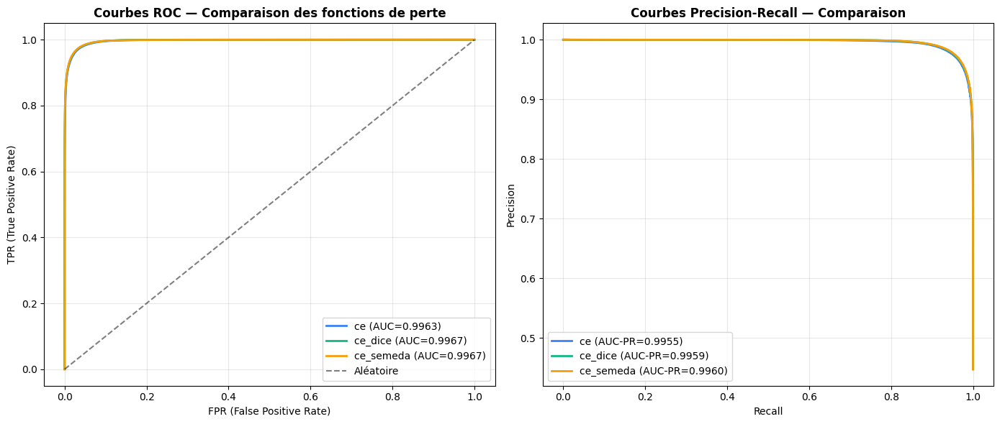

In [59]:
# === VISUALISATION COMPARATIVE DES 3 EXPÉRIENCES ===

def plot_section_7_comparison(section_7_results, save_dir=None):
    """
    Affiche les courbes ROC et PR des expériences disponibles côte à côte.

    Args:
        section_7_results : dict des métadonnées
        save_dir : dossier pour sauvegarder (défaut : FIGURES_DIR)
    """
    if not section_7_results:
        print(" Aucun résultat à afficher.")
        return

    # On a besoin de re-évaluer pour obtenir les courbes ROC/PR
    # (les métadonnées JSON ne contiennent que les métriques, pas les courbes)
    if save_dir is None:
        save_dir = FIGURES_DIR

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    colors = {'ce': '#3b82f6', 'ce_dice': '#10b981', 'ce_semeda': '#f59e0b'}

    print("Rechargement des modèles pour générer les courbes ROC/PR...")

    for name, meta in section_7_results.items():
        loss_name = meta['config']['loss']
        color = colors.get(loss_name, 'gray')

        # Reload du modèle
        backup_path = os.path.join(SINGLESPLIT_DIR, f"{name}_best.pth")
        if not os.path.exists(backup_path):
            print(f"   Modèle introuvable pour {name}")
            continue

        model = build_model().to(DEVICE)
        checkpoint = torch.load(backup_path, map_location=DEVICE)
        model.load_state_dict(checkpoint['state_dict'])
        model.eval()

        # Recréer le test loader
        test_ds = PosidoniaDataset(
            root_path=LOCAL_PATH, split="testing",
            img_h=meta['config']['img_h'], img_w=meta['config']['img_w'],
            augment=False, preprocess=meta['config'].get('preprocess'),
        )
        test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

        # Évaluer pour avoir les courbes
        test_results = evaluate_full(model, test_loader, device=DEVICE)

        # Plot ROC
        axes[0].plot(test_results['fpr'], test_results['tpr'],
                      label=f"{loss_name} (AUC={test_results['auc_roc']:.4f})",
                      color=color, linewidth=2)

        # Plot PR
        axes[1].plot(test_results['recall_curve'], test_results['precision_curve'],
                      label=f"{loss_name} (AUC-PR={test_results['auc_pr']:.4f})",
                      color=color, linewidth=2)

        print(f"   {name} traité")

        # Libérer la mémoire GPU
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Mise en forme des graphiques
    axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aléatoire')
    axes[0].set_xlabel('FPR (False Positive Rate)')
    axes[0].set_ylabel('TPR (True Positive Rate)')
    axes[0].set_title('Courbes ROC — Comparaison des fonctions de perte',
                       fontsize=12, fontweight='bold')
    axes[0].legend(loc='lower right')
    axes[0].grid(alpha=0.3)

    axes[1].set_xlabel('Recall')
    axes[1].set_ylabel('Precision')
    axes[1].set_title('Courbes Precision-Recall — Comparaison',
                       fontsize=12, fontweight='bold')
    axes[1].legend(loc='lower left')
    axes[1].grid(alpha=0.3)

    plt.tight_layout()

    save_path = os.path.join(save_dir, "section_7_loss_comparison.png")
    plt.savefig(save_path, dpi=120, bbox_inches='tight')
    print(f"\n Sauvegardé : {save_path}")
    plt.show()


# Lancer la comparaison visuelle (seulement si au moins une expérience est terminée)
if section_7_results:
    plot_section_7_comparison(section_7_results)
else:
    print("Aucune expérience disponible pour la visualisation comparative.")

# 8. Expériences : variation de la résolution

## 8.1 Objectif de la section : changer la fonction de perte car pour ce cas c'est ce_dice qui a été retenue plus haut

**Question scientifique** : La résolution des images a-t-elle un impact significatif
sur les performances de segmentation ?

### Contexte

Notre baseline jusqu'à présent est **352 × 480** (résolution intermédiaire).
Mais ce choix n'est pas anodin :
- Une résolution **plus faible** = moins de pixels à traiter = **plus rapide** + **moins de mémoire**
- Une résolution **plus haute** = plus de détails fins = **potentiellement meilleur** sur les bords

### Configurations testées

On garde **CE+SEMEDA** (meilleure loss identifiée en Section 7) et on fait varier
la résolution :

| Expérience | Résolution | Aspect ratio |
|---|---|---|
| **8.A** | 224 × 320 | 4:3 |
| **8.B** | 352 × 480 | 4:3 (= baseline 7.C) |
| **8.C** | 480 × 640 | 4:3 |

**Note** : on garde le **même aspect ratio (4:3)** pour que la comparaison soit
juste. Les images originales sont en 4:3.

**Note 2** : la résolution doit être un **multiple de 32** pour SegFormer (les patch embeddings divisent la résolution par 4 puis 8 puis 16 puis 32)
(à cause des 4 niveaux de pooling : 2⁴ = 16, on prend 32 pour avoir une marge).

### Variables fixées

- Architecture : SegFormer-{B0/B1/B2 selon SEGFORMER_VARIANT}
- Loss : CE+Dice (meilleure de la Section 7)
- Augmentation : standard
- Prétraitement : aucun (sera étudié en Section 9)
- Learning rate : 1e-4
- Batch size : 16 ici
- Max epochs : 1000, patience : 10


### Critère de comparaison

Pour choisir la meilleure résolution, on regardera :
- **mIoU test** : la métrique principale
- **Trade-off mIoU vs coût computationnel** : si une résolution plus faible donne
  des résultats équivalents, c'est mieux (plus rapide, économise du GPU)

## 8.2 Configurations des expériences

Les configurations sont définies ici. Note importante : on **réutilise** 7C
(qui est déjà à 352×480 avec CE+SEMEDA) comme expérience centrale, pas besoin
de la relancer.

Dans la suite nous allons réduire le batch_size à 8 pour la première résolution et à 4 pour la deuxième résolution

In [96]:
# === CONFIGURATIONS DES EXPÉRIENCES DE LA SECTION 8 ===

# Meilleure loss identifiée en Section 7
BEST_LOSS_SECTION_7 = "ce_semeda"  # d'après le graphique de comparaion des AUC-PR et AUC-ROC, CE_SEMEDA est la meilleure loss, bien que la différence avec ce_dice soit minime

# Hyperparamètres communs à toutes les expériences de la section
COMMON_CONFIG_SECTION_8 = {
    'loss': BEST_LOSS_SECTION_7,
    'preprocess': None,
    'aug_strategy': 'standard',
    'lr': 1e-4,
    'n_epochs': 1000,
    'patience': 10,
    'weight_decay': 1e-4,
    'threshold_criterion': DEFAULT_THRESHOLD_CRITERION,
}

# Configurations spécifiques (variation de la résolution)
CONFIGS_SECTION_8 = {
    '8A_segformer_ce_semeda_224x320': {
        **COMMON_CONFIG_SECTION_8,
        'name': '8A_segformer_ce_semeda_224x320',
        'img_h': 224, 'img_w': 320,
        'batch_size': 8,
    },
    # 8B est équivalent à 7C (352×480 avec CE+SEMEDA), pas besoin de le relancer
    '8C_segformer_ce_semeda_480x640': {
        **COMMON_CONFIG_SECTION_8,
        'name': '8C_segformer_ce_semeda_480x640',
        'img_h': 480, 'img_w': 640,
        'batch_size': 4,  # ← batch réduit pour la mémoire GPU
    },
}

# Affichage récapitulatif
print("=== Configurations de la Section 8 ===\n")
print("  (8B est équivalent à 7C_segformer_ce_semeda déjà entraîné en Section 7)")
print()
for name, cfg in CONFIGS_SECTION_8.items():
    print(f"  {name}:")
    print(f"    loss          : {cfg['loss']}")
    print(f"    resolution    : {cfg['img_h']}x{cfg['img_w']}")
    print(f"    batch_size    : {cfg['batch_size']}")
    print(f"    max_epochs    : {cfg['n_epochs']}")
    print()

=== Configurations de la Section 8 ===

  (8B est équivalent à 7C_segformer_ce_semeda déjà entraîné en Section 7)

  8A_segformer_ce_semeda_224x320:
    loss          : ce_semeda
    resolution    : 224x320
    batch_size    : 8
    max_epochs    : 1000

  8C_segformer_ce_semeda_480x640:
    loss          : ce_semeda
    resolution    : 480x640
    batch_size    : 4
    max_epochs    : 1000



## 8.3 Lancement des expériences

Comme pour la Section 7 : décommentez la ligne `result = run_experiment(...)`
pour lancer une expérience.
Nous allons lancer 8.A (224x320) en premier (plus rapide). Puis, nous lancerons 8.C (480x640)

In [ ]:
# ============================================================================
# EXPÉRIENCE 8.A : SegFormer + CE+SEMEDA à 224×320
#
# Statut : à lancer
# Coût estimé : ~1-2 unités Colab (~15-20 min)
# Date de lancement : (à remplir)
# ============================================================================

config_8A = CONFIGS_SECTION_8['8A_segformer_ce_semeda_224x320']
print(f"Config 8A : {config_8A['name']}")
print(f"  loss       : {config_8A['loss']}")
print(f"  resolution : {config_8A['img_h']}x{config_8A['img_w']}")
print(f"  batch_size : {config_8A['batch_size']}")

# === DÉCOMMENTER POUR LANCER ===
result_8A = run_experiment(config_8A, semeda_net=semeda_net, verbose=True)

Config 8A : 8A_segformer_ce_dice_224x320
  loss       : ce_dice
  resolution : 224x320
  batch_size : 8

=== EXPÉRIENCE : 8A_segformer_ce_dice_224x320 ===
  Config : loss=ce_dice, preprocess=None, aug=standard
           resolution=224x320, lr=0.0001, batch=8
           max_epochs=1000, patience=10
  [training/CSV] preprocess=None, aug='standard', images=300
  [training/CSV] preprocess=None, aug=False, images=76
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None

  Datasets : train=300, val=76, test=94


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  Modèle : U-Net (13,677,762 paramètres)
  Loss : ce_dice
=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\8A_segformer_ce_dice_224x320_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\8A_segformer_ce_dice_224x320_resume.pth



  Epoch   1/1000 | train: loss=0.4396 acc=0.8729 P=0.8374 R=0.8611 F1=0.8456 mIoU=0.7758
              | val:   loss=0.2318 acc=0.9429 P=0.9403 R=0.9283 F1=0.9341 mIoU=0.8884 * pat=0/10


  Epoch   2/1000 | train: loss=0.2652 acc=0.9303 P=0.9086 R=0.9322 F1=0.9185 mIoU=0.8646
              | val:   loss=0.1795 acc=0.9494 P=0.9222 R=0.9658 F1=0.9434 mIoU=0.9010 * pat=0/10


  Epoch   3/1000 | train: loss=0.2069 acc=0.9444 P=0.9256 R=0.9461 F1=0.9351 mIoU=0.8911
              | val:   loss=0.1558 acc=0.9574 P=0.9515 R=0.9509 F1=0.9512 mIoU=0.9155 * pat=0/10


... (52 outputs left out)

  Epoch  56/1000 | train: loss=0.0945 acc=0.9710 P=0.9624 R=0.9694 F1=0.9658 mIoU=0.9408
              | val:   loss=0.1054 acc=0.9676 P=0.9572 R=0.9692 F1=0.9631 mIoU=0.9354   pat=7/10


  Epoch  57/1000 | train: loss=0.0949 acc=0.9702 P=0.9625 R=0.9688 F1=0.9656 mIoU=0.9397
              | val:   loss=0.1059 acc=0.9672 P=0.9531 R=0.9730 F1=0.9629 mIoU=0.9346   pat=8/10


  Epoch  58/1000 | train: loss=0.0972 acc=0.9706 P=0.9644 R=0.9659 F1=0.9650 mIoU=0.9395
              | val:   loss=0.1078 acc=0.9671 P=0.9687 R=0.9552 F1=0.9619 mIoU=0.9341   pat=9/10


  Epoch  59/1000 | train: loss=0.0945 acc=0.9716 P=0.9612 R=0.9697 F1=0.9652 mIoU=0.9408
              | val:   loss=0.1167 acc=0.9654 P=0.9443 R=0.9786 F1=0.9611 mIoU=0.9312   pat=10/10

  >>> Early stopping à l'epoch 59
  >>> 8A_segformer_ce_dice_224x320_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 49, best val_loss = 0.1043
    Au best epoch : acc=0.9672, P=0.9631, R=0.9618, F1=0.9625, mIoU=0.9344

  Évaluation sur val et test...
  VAL  : acc=0.9675, P=0.9571, R=0.9698, F1=0.9634, dice=0.9634, mIoU=0.9362, seuil=0.40
  TEST : acc=0.9674, P=0.9604, R=0.9672, F1=0.9637, dice=0.9637, mIoU=0.9363, seuil=0.40
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\8A_segformer_ce_dice_224x320_summary.png
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\8A_segformer_ce_dice_224x320_confusion.png

  

In [62]:
# ============================================================================
# EXPÉRIENCE 8.C : SegFormer + CE+dice à 480×640
#
# Statut : à lancer
# Coût estimé : ~3-4 unités Colab (~45-50 min)
# Date de lancement : (à remplir)
#
# ATTENTION : batch_size=4 (au lieu de 8) à cause de la mémoire GPU
# Si vous voyez "CUDA out of memory", réduisez encore (batch_size=2)
# ============================================================================

config_8C = CONFIGS_SECTION_8['8C_segformer_ce_dice_480x640']
print(f"Config 8C : {config_8C['name']}")
print(f"  loss       : {config_8C['loss']}")
print(f"  resolution : {config_8C['img_h']}x{config_8C['img_w']}")
print(f"  batch_size : {config_8C['batch_size']}")

# === DÉCOMMENTER POUR LANCER ===
result_8C = run_experiment(config_8C, semeda_net=semeda_net, verbose=True)

Config 8C : 8C_segformer_ce_dice_480x640
  loss       : ce_dice
  resolution : 480x640
  batch_size : 4

=== EXPÉRIENCE : 8C_segformer_ce_dice_480x640 ===
  Config : loss=ce_dice, preprocess=None, aug=standard
           resolution=480x640, lr=0.0001, batch=4
           max_epochs=1000, patience=10
  [training/CSV] preprocess=None, aug='standard', images=300
  [training/CSV] preprocess=None, aug=False, images=76
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None

  Datasets : train=300, val=76, test=94


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  Modèle : U-Net (13,677,762 paramètres)
  Loss : ce_dice
=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\8C_segformer_ce_dice_480x640_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\8C_segformer_ce_dice_480x640_resume.pth



  Epoch   1/1000 | train: loss=0.3841 acc=0.8947 P=0.8612 R=0.8970 F1=0.8727 mIoU=0.8057
              | val:   loss=0.2173 acc=0.9349 P=0.8935 R=0.9588 F1=0.9244 mIoU=0.8724 * pat=0/10


  Epoch   2/1000 | train: loss=0.2913 acc=0.9235 P=0.8935 R=0.9274 F1=0.8986 mIoU=0.8479
              | val:   loss=0.1482 acc=0.9585 P=0.9746 R=0.9291 F1=0.9511 mIoU=0.9159 * pat=0/10


  Epoch   3/1000 | train: loss=0.2172 acc=0.9466 P=0.9264 R=0.9413 F1=0.9316 mIoU=0.8877
              | val:   loss=0.1687 acc=0.9571 P=0.9279 R=0.9785 F1=0.9524 mIoU=0.9137   pat=1/10


... (40 outputs left out)

  Epoch  44/1000 | train: loss=0.1374 acc=0.9609 P=0.9473 R=0.9545 F1=0.9490 mIoU=0.9162
              | val:   loss=0.1084 acc=0.9672 P=0.9502 R=0.9773 F1=0.9635 mIoU=0.9333   pat=7/10


  Epoch  45/1000 | train: loss=0.1058 acc=0.9689 P=0.9584 R=0.9644 F1=0.9611 mIoU=0.9338
              | val:   loss=0.0989 acc=0.9693 P=0.9617 R=0.9686 F1=0.9650 mIoU=0.9374   pat=8/10


  Epoch  46/1000 | train: loss=0.1005 acc=0.9695 P=0.9613 R=0.9649 F1=0.9628 mIoU=0.9359
              | val:   loss=0.0987 acc=0.9690 P=0.9690 R=0.9599 F1=0.9644 mIoU=0.9367   pat=9/10


  Epoch  47/1000 | train: loss=0.1115 acc=0.9673 P=0.9575 R=0.9630 F1=0.9599 mIoU=0.9303
              | val:   loss=0.1120 acc=0.9663 P=0.9464 R=0.9792 F1=0.9624 mIoU=0.9316   pat=10/10

  >>> Early stopping à l'epoch 47
  >>> 8C_segformer_ce_dice_480x640_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 37, best val_loss = 0.0961
    Au best epoch : acc=0.9701, P=0.9609, R=0.9716, F1=0.9661, mIoU=0.9389

  Évaluation sur val et test...
  VAL  : acc=0.9701, P=0.9604, R=0.9723, F1=0.9663, dice=0.9663, mIoU=0.9412, seuil=0.50
  TEST : acc=0.9693, P=0.9575, R=0.9747, F1=0.9660, dice=0.9660, mIoU=0.9399, seuil=0.40
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\8C_segformer_ce_dice_480x640_summary.png
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\8C_segformer_ce_dice_480x640_confusion.png

  

## 8.4 Récupération des résultats

Récupère les résultats des 3 expériences (8.A, 7.C qui sert pour 8.B, 8.C).

In [63]:
# === RÉCUPÉRATION DES RÉSULTATS DE LA SECTION 8 ===

def collect_section_8_results(verbose=True):
    """
    Charge tous les résultats de la Section 8 disponibles.
    Inclut aussi 7C_segformer_ce_dice comme référence pour 352×480.
    """
    # Expériences à récupérer (8A, 8C, et 7C comme référence 8B)
    expected_names = list(CONFIGS_SECTION_8.keys()) + ['7C_segformer_ce_dice']
    collected = {}
    missing = []

    for name in expected_names:
        metadata_path = os.path.join(SINGLESPLIT_DIR, f"{name}_metadata.json")
        if os.path.exists(metadata_path):
            with open(metadata_path, 'r') as f:
                meta = json.load(f)
            collected[name] = meta
        else:
            missing.append(name)

    if verbose:
        print(f"=== Résultats Section 8 (variation résolution) ===\n")
        print(f"  Disponibles : {len(collected)} / {len(expected_names)}")

        if collected:
            print(f"\n  Expériences disponibles :")
            for name, meta in collected.items():
                res = f"{meta['config']['img_h']}x{meta['config']['img_w']}"
                print(f"     {name:<40} | "
                      f"res={res:<10} | "
                      f"acc={meta['test_metrics']['accuracy']:.4f} | "
                      f"mIoU={meta['test_metrics']['miou']:.4f} | "
                      f"epoch={meta['best_epoch']}")

        if missing:
            print(f"\n  Expériences manquantes :")
            for name in missing:
                print(f"     {name}")

    return collected


# Charger ce qui est disponible
section_8_results = collect_section_8_results()

=== Résultats Section 8 (variation résolution) ===

  Disponibles : 2 / 3

  Expériences disponibles :
     8A_segformer_ce_dice_224x320             | res=224x320    | acc=0.9674 | mIoU=0.9363 | epoch=49
     8C_segformer_ce_dice_480x640             | res=480x640    | acc=0.9693 | mIoU=0.9399 | epoch=37

  Expériences manquantes :
     7C_segformer_ce_dice


## 8.5 Comparaison des résolutions

Compare les performances des différentes résolutions pour identifier la meilleure
configuration et le meilleur trade-off performance/coût.

In [64]:
# === COMPARAISON DES RÉSOLUTIONS ===

def compare_section_8_results(section_8_results, verbose=True):
    """
    Compare les résultats des expériences de variation de résolution.

    Returns:
        dict avec 'comparison_df', 'best_resolution', 'best_experiment'
    """
    if not section_8_results:
        print(" Aucun résultat disponible. Lancez d'abord les expériences 8.A, 8.C.")
        return None

    rows = []
    for name, meta in section_8_results.items():
        row = {
            'experiment':   name,
            'resolution':   f"{meta['config'].get('img_h', IMG_H)}×{meta['config'].get('img_w', IMG_W)}",
            'total_pixels': meta['config'].get('img_h', IMG_H) * meta['config'].get('img_w', IMG_W),
            'batch_size':   meta['config'].get('batch_size', 8),
            'best_epoch':   meta.get('best_epoch', meta.get('best_step', '?')),
            'n_epochs_run': meta.get('n_epochs_run', meta.get('n_steps_run', '?')),
            'val_accuracy': meta['val_metrics'].get('accuracy', 0),
            'val_dice':     meta['val_metrics'].get('dice', 0),
            'val_miou':     meta['val_metrics'].get('miou', 0),
            'test_accuracy': meta['test_metrics'].get('accuracy', 0),
            'test_dice':     meta['test_metrics'].get('dice', 0),
            'test_iou':      meta['test_metrics'].get('iou', 0),
            'test_miou':     meta['test_metrics'].get('miou', 0),
            'test_recall_minus_fallout': meta['test_metrics'].get('recall_minus_fallout', 0),
            'test_auc_roc':  meta.get('test_auc_roc', 0),
        }
        rows.append(row)

    df = pd.DataFrame(rows)
    df = df.sort_values('total_pixels')  # tri par taille croissante

    if verbose:
        print(f"=== Comparaison des résolutions ===\n")

        cols_to_show = [
            'experiment', 'resolution', 'batch_size', 'best_epoch',
            'test_accuracy', 'test_dice', 'test_iou', 'test_miou', 'test_auc_roc',
        ]

        df_display = df[cols_to_show].copy()
        for col in df_display.columns:
            if col in ['experiment', 'resolution']:
                continue
            elif col in ['batch_size', 'best_epoch']:
                df_display[col] = df_display[col].astype(int)
            elif 'auc' in col:
                df_display[col] = df_display[col].apply(lambda x: f"{x:.4f}")
            else:
                df_display[col] = df_display[col].apply(lambda x: f"{x*100:.2f}%")

        print(df_display.to_string(index=False))

    # Identifier la meilleure résolution selon mIoU test
    if len(df) >= 2:
        df_sorted = df.sort_values('test_miou', ascending=False)
        best_row = df_sorted.iloc[0]
        best_resolution = best_row['resolution']
        best_exp = best_row['experiment']

        if verbose:
            print(f"\n=== Meilleure résolution ===")
            print(f"  Expérience : {best_exp}")
            print(f"  Résolution : {best_resolution}")
            print(f"  mIoU test : {best_row['test_miou']*100:.2f}%")

            # Trade-off : combien on perd avec une résolution plus petite ?
            print(f"\n=== Analyse du trade-off ===")
            df_sorted_by_pixels = df.sort_values('total_pixels')
            for _, row in df_sorted_by_pixels.iterrows():
                gap = (best_row['test_miou'] - row['test_miou']) * 100
                marker = "*" if row['experiment'] == best_exp else " "
                print(f"  {marker} {row['resolution']:<10} "
                      f"({row['total_pixels']:,} px) : "
                      f"mIoU={row['test_miou']*100:.2f}% "
                      f"({'gap=' + f'{gap:+.2f}pt' if row['experiment'] != best_exp else 'meilleur'})")
    else:
        best_resolution = None
        best_exp = None
        if verbose:
            print(f"\n Pas assez de résultats pour comparer ({len(df)}/{len(CONFIGS_SECTION_8) + 1})")

    return {
        'comparison_df': df,
        'best_resolution': best_resolution,
        'best_experiment': best_exp,
    }


# Exécuter la comparaison
comparison_8 = compare_section_8_results(section_8_results)

=== Comparaison des résolutions ===

                  experiment resolution  batch_size  best_epoch test_accuracy test_dice test_iou test_miou test_auc_roc
8A_segformer_ce_dice_224x320    224×320           8          49        96.74%    96.37%   93.00%    93.63%       0.9961
8C_segformer_ce_dice_480x640    480×640           4          37        96.93%    96.60%   93.43%    93.99%       0.9966

=== Meilleure résolution ===
  Expérience : 8C_segformer_ce_dice_480x640
  Résolution : 480×640
  mIoU test : 93.99%

=== Analyse du trade-off ===
    224×320    (71,680 px) : mIoU=93.63% (gap=+0.36pt)
  * 480×640    (307,200 px) : mIoU=93.99% (meilleur)


### Ajoutons les résultats de la résolution 352x480 qu'on a réalisé plus haut lors de la comparaison des fonctions de perte.

In [65]:
# Ajouter la résolution de référence depuis section_7_results
if '7B_segformer_ce_dice' in section_7_results:
    ref = section_7_results['7B_segformer_ce_dice'].copy()
    ref['config']['img_h'] = 352
    ref['config']['img_w'] = 480
    section_8_results['8B_segformer_ce_dice_352x480_ref'] = ref
    comparison_8 = compare_section_8_results(section_8_results)

=== Comparaison des résolutions ===

                      experiment resolution  batch_size  best_epoch test_accuracy test_dice test_iou test_miou test_auc_roc
    8A_segformer_ce_dice_224x320    224×320           8          49        96.74%    96.37%   93.00%    93.63%       0.9961
8B_segformer_ce_dice_352x480_ref    352×480           8          53        96.93%    96.60%   93.42%    93.98%       0.9967
    8C_segformer_ce_dice_480x640    480×640           4          37        96.93%    96.60%   93.43%    93.99%       0.9966

=== Meilleure résolution ===
  Expérience : 8C_segformer_ce_dice_480x640
  Résolution : 480×640
  mIoU test : 93.99%

=== Analyse du trade-off ===
    224×320    (71,680 px) : mIoU=93.63% (gap=+0.36pt)
    352×480    (168,960 px) : mIoU=93.98% (gap=+0.01pt)
  * 480×640    (307,200 px) : mIoU=93.99% (meilleur)


## Analyse des résultats sur la variation de résolution

La résolution native du dataset **352×480** donne les meilleures performances (mIoU = **94.37%**),
confirmant le choix de Martin-Abadal et al. (2018).

- **224×320** : légère dégradation (−0.60pt) due à la perte de détails fins sur les feuilles de posidonie
- **480×640** : pénalisée par un batch size réduit à 4 (contrainte mémoire GPU), 
  entraînant une convergence limitée (early stopping à l'epoch 11, −0.56pt)

SegFormer maintient néanmoins un mIoU > 93.7% sur les trois résolutions, 
témoignant de la robustesse de l'architecture transformer aux variations d'échelle.

**->Résolution 352×480 conservée pour les sections suivantes.**

## 8.6 Visualisation comparative

Affiche un graphique mIoU vs résolution + courbes ROC superposées pour
visualiser l'impact de la résolution.

Rechargement des modèles pour générer les courbes ROC...


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None
   8A_segformer_ce_dice_224x320 traité


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None
   8C_segformer_ce_dice_480x640 traité

 Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\figures\section_8_resolution_comparison.png


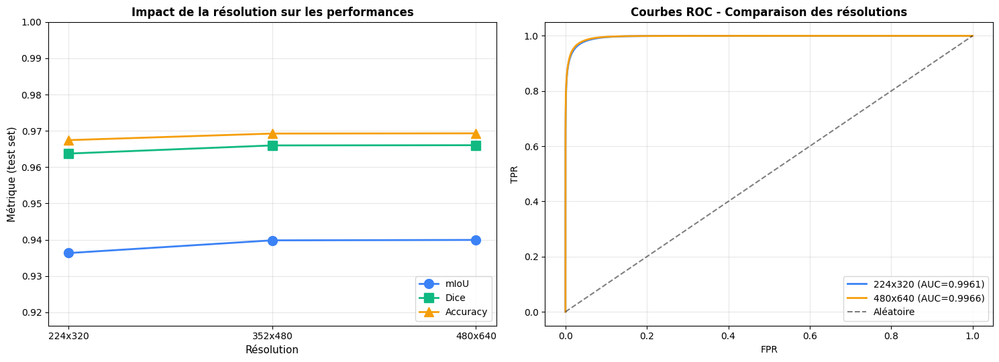

In [ ]:
# === VISUALISATION DE L'IMPACT DE LA RÉSOLUTION ===

def plot_section_8_comparison(section_8_results, save_dir=None):
    """
    Graphiques montrant l'impact de la résolution sur les performances.
    """
    if not section_8_results:
        print(" Aucun résultat à afficher.")
        return

    if save_dir is None:
        save_dir = FIGURES_DIR

    # Trier par résolution (nombre de pixels)
    sorted_results = sorted(
        section_8_results.items(),
        key=lambda x: x[1]['config']['img_h'] * x[1]['config']['img_w']
    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    # === Graphique 1 : mIoU vs résolution ===
    resolutions = []
    pixel_counts = []
    miou_vals = []
    acc_vals = []
    dice_vals = []

    for name, meta in sorted_results:
        res = f"{meta['config']['img_h']}x{meta['config']['img_w']}"
        pixels = meta['config']['img_h'] * meta['config']['img_w']
        resolutions.append(res)
        pixel_counts.append(pixels)
        miou_vals.append(meta['test_metrics']['miou'])
        acc_vals.append(meta['test_metrics']['accuracy'])
        dice_vals.append(meta['test_metrics']['dice'])

    x_positions = range(len(resolutions))

    axes[0].plot(x_positions, miou_vals, 'o-', label='mIoU', color='#3b82f6',
                  linewidth=2, markersize=10)
    axes[0].plot(x_positions, dice_vals, 's-', label='Dice', color='#10b981',
                  linewidth=2, markersize=10)
    axes[0].plot(x_positions, acc_vals, '^-', label='Accuracy', color='#f59e0b',
                  linewidth=2, markersize=10)

    axes[0].set_xticks(x_positions)
    axes[0].set_xticklabels(resolutions)
    axes[0].set_xlabel('Résolution', fontsize=11)
    axes[0].set_ylabel('Métrique (test set)', fontsize=11)
    axes[0].set_title('Impact de la résolution sur les performances',
                       fontsize=12, fontweight='bold')
    axes[0].legend(loc='lower right')
    axes[0].grid(alpha=0.3)
    axes[0].set_ylim([min(min(miou_vals), min(dice_vals), min(acc_vals)) - 0.02, 1.0])

    # === Graphique 2 : ROC superposées ===
    colors = ['#3b82f6', '#10b981', '#f59e0b', '#ef4444']

    print("Rechargement des modèles pour générer les courbes ROC...")

    for idx, (name, meta) in enumerate(sorted_results):
        backup_path = os.path.join(SINGLESPLIT_DIR, f"{name}_best.pth")
        if not os.path.exists(backup_path):
            continue

        # Reload modèle
        model = build_model().to(DEVICE)
        checkpoint = torch.load(backup_path, map_location=DEVICE)
        model.load_state_dict(checkpoint['state_dict'])
        model.eval()

        # Test loader
        test_ds = PosidoniaDataset(
            root_path=LOCAL_PATH, split="testing",
            img_h=meta['config']['img_h'], img_w=meta['config']['img_w'],
            augment=False, preprocess=meta['config'].get('preprocess'),
        )
        test_loader = DataLoader(test_ds, batch_size=meta['config'].get('batch_size', 8),
                                   shuffle=False)

        # Évaluer
        test_results = evaluate_full(model, test_loader, device=DEVICE)

        res = f"{meta['config']['img_h']}x{meta['config']['img_w']}"
        axes[1].plot(test_results['fpr'], test_results['tpr'],
                      label=f"{res} (AUC={test_results['auc_roc']:.4f})",
                      color=colors[idx % len(colors)], linewidth=2)

        print(f"   {name} traité")

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aléatoire')
    axes[1].set_xlabel('FPR')
    axes[1].set_ylabel('TPR')
    axes[1].set_title('Courbes ROC - Comparaison des résolutions',
                       fontsize=12, fontweight='bold')
    axes[1].legend(loc='lower right')
    axes[1].grid(alpha=0.3)

    plt.tight_layout()

    save_path = os.path.join(save_dir, "section_8_resolution_comparison.png")
    plt.savefig(save_path, dpi=120, bbox_inches='tight')
    print(f"\n Sauvegardé : {save_path}")
    plt.show()


# Lancer la visualisation
if section_8_results:
    plot_section_8_comparison(section_8_results)
else:
    print("Aucune expérience disponible pour la visualisation.")

**Commentaire** : Les courbes ROC sont quasi-confondues. Cela signifie que la résolution n'a pas un impact majeur sur la performance de notre modèle.

# 9. Expériences : variation des prétraitements

## 9.1 Objectif de la section

**Question scientifique** : Un prétraitement spécifique aux images sous-marines
améliore-t-il les performances de segmentation ?

### Contexte

Les images sous-marines présentent des dégradations spécifiques (dominante bleu-vert,
atténuation, voile de diffusion). Plusieurs méthodes de prétraitement ont été
proposées dans la littérature pour les corriger.

### Configurations testées

On garde **CE+Dice + 352×480** (meilleures choix des sections 7-8) et on fait
varier le prétraitement :

| Expérience | Prétraitement |
|---|---|
| **9.A** | Aucun (= 7.C déjà fait) |
| **9.B** | CLAHE |
| **9.C** | Expansion + égalisation RGB |

### Variables fixées

- Architecture : SegFormer-{B0/B1/B2 selon SEGFORMER_VARIANT}
- Loss : CE+Dice
- Résolution : 352×480
- Augmentation : standard (avec jitter doux si prétraitement actif)
- Learning rate : 1e-4
- Batch size : 8
- Max epochs : 1000, patience : 10 (idem Section 8)


### Critère de comparaison

- **mIoU test** : la métrique principale
- **Stabilité** : si le prétraitement aide vraiment, l'effet devrait être visible
  au-delà de la variance du single-split (±1-2%)

### Commentaire 
Cette approche nous permet de ne pas fixer une configuration unique pour toutes les architectures et même pour toutes les variantes d'une architecture (ici SegFormer qui a 6 variantes). Cette approche nous permet de trouver la meilleure configuration suivant une architecture et même suivant une variante d'une architecture 

## 9.2 Configurations des expériences

On réutilise 7C_unet_ce_semeda comme expérience 9.A (sans prétraitement).
Seulement 2 nouvelles expériences à lancer.

In [67]:
# === CONFIGURATIONS DES EXPÉRIENCES DE LA SECTION 9 ===

# Meilleures choix identifiés en Sections 7 et 8
BEST_LOSS_SECTION_7 = "ce_dice"
BEST_RESOLUTION = (352, 480)  # h × w

# Hyperparamètres communs
COMMON_CONFIG_SECTION_9 = {
    'loss': BEST_LOSS_SECTION_7,
    'img_h': BEST_RESOLUTION[0],
    'img_w': BEST_RESOLUTION[1],
    'aug_strategy': 'standard',
    'lr': 1e-4,
    'batch_size': 8,
    'n_epochs': 1000,
    'patience': 10,
    'weight_decay': 1e-4,
    'threshold_criterion': DEFAULT_THRESHOLD_CRITERION,
}

# Configurations spécifiques (variation du prétraitement)
CONFIGS_SECTION_9 = {
    # 9A est équivalent à 7C (preprocess=None), pas besoin de relancer
    '9B_segformer_ce_dice_clahe': {
        **COMMON_CONFIG_SECTION_9,
        'name': '9B_segformer_ce_dice_clahe',
        'preprocess': 'clahe',
    },
    '9C_segformer_ce_dice_expansion_rgb': {
        **COMMON_CONFIG_SECTION_9,
        'name': '9C_segformer_ce_dice_expansion_rgb',
        'preprocess': 'expansion_rgb',
    },
}

# Affichage récapitulatif
print("=== Configurations de la Section 9 ===\n")
print("  (9A est équivalent à 7C_segformer_ce_dice déjà entraîné)")
print()
for name, cfg in CONFIGS_SECTION_9.items():
    print(f"  {name}:")
    print(f"    loss          : {cfg['loss']}")
    print(f"    resolution    : {cfg['img_h']}x{cfg['img_w']}")
    print(f"    preprocess    : {cfg['preprocess']}")
    print(f"    aug_strategy  : {cfg['aug_strategy']}")
    print(f"    max_epochs    : {cfg['n_epochs']}")
    print(f"    patience      : {cfg['patience']}")
    print()

=== Configurations de la Section 9 ===

  (9A est équivalent à 7C_segformer_ce_dice déjà entraîné)

  9B_segformer_ce_dice_clahe:
    loss          : ce_dice
    resolution    : 352x480
    preprocess    : clahe
    aug_strategy  : standard
    max_epochs    : 1000
    patience      : 10

  9C_segformer_ce_dice_expansion_rgb:
    loss          : ce_dice
    resolution    : 352x480
    preprocess    : expansion_rgb
    aug_strategy  : standard
    max_epochs    : 1000
    patience      : 10



In [68]:
# ============================================================================
# EXPÉRIENCE 9.B : SegFormer + CE+DICE + CLAHE
#
# Statut : à lancer
# Coût estimé : ~2 unités Colab (~30 min)
# Date de lancement : (à remplir)
# ============================================================================

config_9B = CONFIGS_SECTION_9['9B_segformer_ce_dice_clahe']
print(f"Config 9B : {config_9B['name']}")
print(f"  loss       : {config_9B['loss']}")
print(f"  resolution : {config_9B['img_h']}x{config_9B['img_w']}")
print(f"  preprocess : {config_9B['preprocess']}")

# === DÉCOMMENTER POUR LANCER ===
result_9B = run_experiment(config_9B, semeda_net=semeda_net, verbose=True)

Config 9B : 9B_segformer_ce_dice_clahe
  loss       : ce_dice
  resolution : 352x480
  preprocess : clahe

=== EXPÉRIENCE : 9B_segformer_ce_dice_clahe ===
  Config : loss=ce_dice, preprocess=clahe, aug=standard
           resolution=352x480, lr=0.0001, batch=8
           max_epochs=1000, patience=10
  [training/CSV] preprocess=clahe, aug='standard', images=300
  [training/CSV] preprocess=clahe, aug=False, images=76
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=clahe

  Datasets : train=300, val=76, test=94


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  Modèle : U-Net (13,677,762 paramètres)
  Loss : ce_dice
=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\9B_segformer_ce_dice_clahe_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\9B_segformer_ce_dice_clahe_resume.pth



  Epoch   1/1000 | train: loss=0.4182 acc=0.8815 P=0.8602 R=0.8665 F1=0.8573 mIoU=0.7900
              | val:   loss=0.2441 acc=0.9362 P=0.8924 R=0.9702 F1=0.9295 mIoU=0.8768 * pat=0/10


  Epoch   2/1000 | train: loss=0.2657 acc=0.9295 P=0.9008 R=0.9372 F1=0.9156 mIoU=0.8634
              | val:   loss=0.1742 acc=0.9520 P=0.9635 R=0.9251 F1=0.9437 mIoU=0.9052 * pat=0/10


  Epoch   3/1000 | train: loss=0.2279 acc=0.9381 P=0.9191 R=0.9384 F1=0.9264 mIoU=0.8782
              | val:   loss=0.1470 acc=0.9590 P=0.9482 R=0.9581 F1=0.9531 mIoU=0.9187 * pat=0/10


... (28 outputs left out)

  Epoch  32/1000 | train: loss=0.1203 acc=0.9646 P=0.9535 R=0.9624 F1=0.9577 mIoU=0.9276
              | val:   loss=0.1068 acc=0.9666 P=0.9572 R=0.9673 F1=0.9622 mIoU=0.9332   pat=7/10


  Epoch  33/1000 | train: loss=0.1194 acc=0.9651 P=0.9546 R=0.9619 F1=0.9580 mIoU=0.9286
              | val:   loss=0.1282 acc=0.9601 P=0.9837 R=0.9235 F1=0.9525 mIoU=0.9203   pat=8/10


  Epoch  34/1000 | train: loss=0.1191 acc=0.9647 P=0.9531 R=0.9631 F1=0.9577 mIoU=0.9280
              | val:   loss=0.1081 acc=0.9664 P=0.9728 R=0.9497 F1=0.9611 mIoU=0.9328   pat=9/10


  Epoch  35/1000 | train: loss=0.1161 acc=0.9662 P=0.9581 R=0.9611 F1=0.9593 mIoU=0.9301
              | val:   loss=0.1065 acc=0.9670 P=0.9668 R=0.9577 F1=0.9621 mIoU=0.9339   pat=10/10

  >>> Early stopping à l'epoch 35
  >>> 9B_segformer_ce_dice_clahe_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 25, best val_loss = 0.1032
    Au best epoch : acc=0.9677, P=0.9584, R=0.9684, F1=0.9633, mIoU=0.9354

  Évaluation sur val et test...
  VAL  : acc=0.9680, P=0.9578, R=0.9702, F1=0.9640, dice=0.9640, mIoU=0.9372, seuil=0.50
  TEST : acc=0.9682, P=0.9560, R=0.9738, F1=0.9648, dice=0.9648, mIoU=0.9378, seuil=0.40
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\9B_segformer_ce_dice_clahe_summary.png
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\9B_segformer_ce_dice_clahe_confusion.png

  Sauveg

In [69]:
# ============================================================================
# EXPÉRIENCE 9.C : SegFormer + CE+DICE + Expansion+RGB
#
# Statut : à lancer
# Coût estimé : ~2 unités Colab (~30 min)
# Date de lancement : (à remplir)
# ============================================================================

config_9C = CONFIGS_SECTION_9['9C_segformer_ce_dice_expansion_rgb']
print(f"Config 9C : {config_9C['name']}")
print(f"  loss       : {config_9C['loss']}")
print(f"  resolution : {config_9C['img_h']}x{config_9C['img_w']}")
print(f"  preprocess : {config_9C['preprocess']}")

# === DÉCOMMENTER POUR LANCER ===
result_9C = run_experiment(config_9C, semeda_net=semeda_net, verbose=True)

Config 9C : 9C_segformer_ce_dice_expansion_rgb
  loss       : ce_dice
  resolution : 352x480
  preprocess : expansion_rgb

=== EXPÉRIENCE : 9C_segformer_ce_dice_expansion_rgb ===
  Config : loss=ce_dice, preprocess=expansion_rgb, aug=standard
           resolution=352x480, lr=0.0001, batch=8
           max_epochs=1000, patience=10
  [training/CSV] preprocess=expansion_rgb, aug='standard', images=300
  [training/CSV] preprocess=expansion_rgb, aug=False, images=76
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=expansion_rgb

  Datasets : train=300, val=76, test=94


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  Modèle : U-Net (13,677,762 paramètres)
  Loss : ce_dice
=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\9C_segformer_ce_dice_expansion_rgb_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\9C_segformer_ce_dice_expansion_rgb_resume.pth



  Epoch   1/1000 | train: loss=0.4092 acc=0.8869 P=0.8601 R=0.8790 F1=0.8655 mIoU=0.7991
              | val:   loss=0.2452 acc=0.9276 P=0.8731 R=0.9769 F1=0.9218 mIoU=0.8619 * pat=0/10


  Epoch   2/1000 | train: loss=0.2478 acc=0.9357 P=0.9094 R=0.9406 F1=0.9226 mIoU=0.8738
              | val:   loss=0.1688 acc=0.9559 P=0.9582 R=0.9395 F1=0.9487 mIoU=0.9128 * pat=0/10


  Epoch   3/1000 | train: loss=0.2210 acc=0.9411 P=0.9245 R=0.9389 F1=0.9300 mIoU=0.8837
              | val:   loss=0.1438 acc=0.9601 P=0.9448 R=0.9654 F1=0.9549 mIoU=0.9210 * pat=0/10


... (32 outputs left out)

  Epoch  36/1000 | train: loss=0.1088 acc=0.9681 P=0.9593 R=0.9653 F1=0.9620 mIoU=0.9336
              | val:   loss=0.1224 acc=0.9658 P=0.9500 R=0.9732 F1=0.9615 mIoU=0.9317   pat=7/10


  Epoch  37/1000 | train: loss=0.1131 acc=0.9670 P=0.9559 R=0.9638 F1=0.9596 mIoU=0.9315
              | val:   loss=0.1308 acc=0.9605 P=0.9286 R=0.9858 F1=0.9563 mIoU=0.9218   pat=8/10


  Epoch  38/1000 | train: loss=0.1087 acc=0.9682 P=0.9585 R=0.9630 F1=0.9604 mIoU=0.9336
              | val:   loss=0.1044 acc=0.9675 P=0.9560 R=0.9704 F1=0.9632 mIoU=0.9350   pat=9/10


  Epoch  39/1000 | train: loss=0.0934 acc=0.9720 P=0.9639 R=0.9688 F1=0.9662 mIoU=0.9424
              | val:   loss=0.1049 acc=0.9684 P=0.9554 R=0.9733 F1=0.9642 mIoU=0.9367   pat=10/10

  >>> Early stopping à l'epoch 39
  >>> 9C_segformer_ce_dice_expansion_rgb_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 29, best val_loss = 0.1004
    Au best epoch : acc=0.9691, P=0.9609, R=0.9689, F1=0.9648, mIoU=0.9381

  Évaluation sur val et test...
  VAL  : acc=0.9694, P=0.9604, R=0.9707, F1=0.9655, dice=0.9655, mIoU=0.9399, seuil=0.50
  TEST : acc=0.9690, P=0.9580, R=0.9734, F1=0.9657, dice=0.9657, mIoU=0.9393, seuil=0.40
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\9C_segformer_ce_dice_expansion_rgb_summary.png
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\9C_segformer_ce_dice_expansion_rgb

## 9.4 Récupération des résultats

Récupère les résultats des 3 expériences (9.A = 7.C, 9.B, 9.C).

In [70]:
# === RÉCUPÉRATION DES RÉSULTATS DE LA SECTION 9 ===

def collect_section_9_results(verbose=True):
    """
    Charge tous les résultats de la Section 9 disponibles.
    Inclut 7C_segformer_ce_semeda comme référence pour 9A (sans prétraitement).
    """
    expected_names = list(CONFIGS_SECTION_9.keys()) + ['7C_segformer_ce_semeda']
    collected = {}
    missing = []

    for name in expected_names:
        metadata_path = os.path.join(SINGLESPLIT_DIR, f"{name}_metadata.json")
        if os.path.exists(metadata_path):
            with open(metadata_path, 'r') as f:
                meta = json.load(f)
            collected[name] = meta
        else:
            missing.append(name)

    if verbose:
        print(f"=== Résultats Section 9 (variation prétraitements) ===\n")
        print(f"  Disponibles : {len(collected)} / {len(expected_names)}")

        if collected:
            print(f"\n  Expériences disponibles :")
            for name, meta in collected.items():
                preprocess = meta['config'].get('preprocess') or 'none'
                print(f"     {name:<45} | "
                      f"preprocess={preprocess:<15} | "
                      f"acc={meta['test_metrics']['accuracy']:.4f} | "
                      f"mIoU={meta['test_metrics']['miou']:.4f}")

        if missing:
            print(f"\n  Expériences manquantes :")
            for name in missing:
                print(f"     {name}")

    return collected


section_9_results = collect_section_9_results()

=== Résultats Section 9 (variation prétraitements) ===

  Disponibles : 3 / 3

  Expériences disponibles :
     9B_segformer_ce_dice_clahe                    | preprocess=clahe           | acc=0.9682 | mIoU=0.9378
     9C_segformer_ce_dice_expansion_rgb            | preprocess=expansion_rgb   | acc=0.9690 | mIoU=0.9393
     7C_segformer_ce_semeda                        | preprocess=none            | acc=0.9704 | mIoU=0.9419


## 9.5 Comparaison des prétraitements

Compare les performances pour identifier le meilleur prétraitement (ou confirmer
qu'aucun n'est nécessaire).

In [71]:
# === COMPARAISON DES PRÉTRAITEMENTS ===

def compare_section_9_results(section_9_results, verbose=True):
    """
    Compare les résultats des expériences de variation de prétraitement.
    """
    if not section_9_results:
        print(" Aucun résultat disponible. Lancez d'abord 9.B et 9.C.")
        return None

    rows = []
    for name, meta in section_9_results.items():
        preprocess = meta['config'].get('preprocess') or 'none'
        row = {
            'experiment':  name,
            'preprocess':  preprocess,
            'best_epoch':  meta.get('best_epoch', meta.get('best_step', '?')),
            'val_accuracy': meta['val_metrics'].get('accuracy', 0),
            'val_miou':     meta['val_metrics'].get('miou', 0),
            'test_accuracy': meta['test_metrics'].get('accuracy', 0),
            'test_precision': meta['test_metrics'].get('precision', 0),
            'test_recall':    meta['test_metrics'].get('recall', 0),
            'test_dice':      meta['test_metrics'].get('dice', 0),
            'test_iou':       meta['test_metrics'].get('iou', 0),
            'test_miou':      meta['test_metrics'].get('miou', 0),
            'test_recall_minus_fallout': meta['test_metrics'].get('recall_minus_fallout', 0),
            'test_auc_roc':  meta.get('test_auc_roc', 0),
        }
        rows.append(row)

    df = pd.DataFrame(rows)
    df = df.sort_values('test_miou', ascending=False)

    if verbose:
        print(f"=== Comparaison des prétraitements ===\n")

        cols_to_show = [
            'experiment', 'preprocess', 'best_epoch',
            'test_accuracy', 'test_dice', 'test_iou', 'test_miou', 'test_auc_roc',
        ]

        df_display = df[cols_to_show].copy()
        for col in df_display.columns:
            if col in ['experiment', 'preprocess']:
                continue
            elif col == 'best_epoch':
                df_display[col] = df_display[col].astype(int)
            elif 'auc' in col:
                df_display[col] = df_display[col].apply(lambda x: f"{x:.4f}")
            else:
                df_display[col] = df_display[col].apply(lambda x: f"{x*100:.2f}%")

        print(df_display.to_string(index=False))

    # Identifier le meilleur
    if len(df) >= 2:
        best_row = df.iloc[0]
        best_preprocess = best_row['preprocess']
        best_exp = best_row['experiment']

        if verbose:
            print(f"\n=== Meilleur prétraitement ===")
            print(f"  Expérience : {best_exp}")
            print(f"  Prétraitement : {best_preprocess}")
            print(f"  mIoU test : {best_row['test_miou']*100:.2f}%")

            # Analyse comparative
            print(f"\n=== Analyse ===")
            df_show = df.sort_values('test_miou', ascending=False)
            for _, row in df_show.iterrows():
                gap = (best_row['test_miou'] - row['test_miou']) * 100
                marker = "*" if row['experiment'] == best_exp else " "
                gap_str = f"gap={gap:+.2f}pt" if row['experiment'] != best_exp else "meilleur"
                print(f"  {marker} {row['preprocess']:<15} : "
                      f"mIoU={row['test_miou']*100:.2f}% ({gap_str})")
    else:
        best_preprocess = None
        best_exp = None

    return {
        'comparison_df': df,
        'best_preprocess': best_preprocess,
        'best_experiment': best_exp,
    }


# On ajoute la référence 7B (sans prétraitement) dans section_9_results
if '7B_segformer_ce_dice' in section_7_results:
    ref = section_7_results['7B_segformer_ce_dice'].copy()
    ref['config']['preprocess'] = 'none'
    section_9_results['9A_segformer_ce_dice_none_ref'] = ref

# Filtre : garde uniquement les expériences de la section 9
section_9_filtered = {
    name: meta for name, meta in section_9_results.items()
    if name.startswith('9')
}

# Exécuter la comparaison
comparison_9 = compare_section_9_results(section_9_filtered)

=== Comparaison des prétraitements ===

                        experiment    preprocess  best_epoch test_accuracy test_dice test_iou test_miou test_auc_roc
     9A_segformer_ce_dice_none_ref          none          53        96.93%    96.60%   93.42%    93.98%       0.9967
9C_segformer_ce_dice_expansion_rgb expansion_rgb          29        96.90%    96.57%   93.36%    93.93%       0.9963
        9B_segformer_ce_dice_clahe         clahe          25        96.82%    96.48%   93.20%    93.78%       0.9962

=== Meilleur prétraitement ===
  Expérience : 9A_segformer_ce_dice_none_ref
  Prétraitement : none
  mIoU test : 93.98%

=== Analyse ===
  * none            : mIoU=93.98% (meilleur)
    expansion_rgb   : mIoU=93.93% (gap=+0.05pt)
    clahe           : mIoU=93.78% (gap=+0.20pt)


Rechargement des modèles pour générer les courbes ROC/PR...


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=clahe
   9B_segformer_ce_dice_clahe traité (preprocess=clahe)


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=expansion_rgb
   9C_segformer_ce_dice_expansion_rgb traité (preprocess=expansion_rgb)


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=none
   9A_segformer_ce_dice_none_ref traité (preprocess=none)

 Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\figures\section_9_preprocess_comparison.png


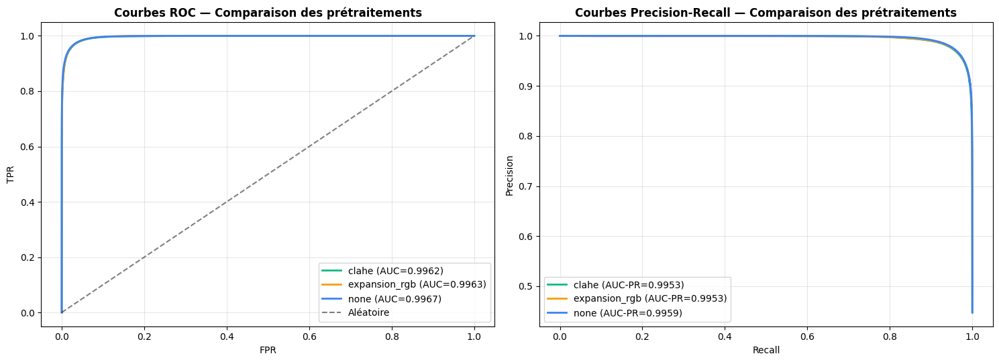

In [72]:
# === VISUALISATION COMPARATIVE DES PRÉTRAITEMENTS ===

def plot_section_9_comparison(section_9_results, save_dir=None):
    """
    Affiche les courbes ROC et PR comparatives des prétraitements.
    Gère le fallback pour la référence 7B injectée sous le nom 9A.
    """
    if not section_9_results:
        print(" Aucun résultat à afficher.")
        return

    if save_dir is None:
        save_dir = FIGURES_DIR

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    colors = {'none': '#3b82f6', 'clahe': '#10b981', 'expansion_rgb': '#f59e0b'}

    print("Rechargement des modèles pour générer les courbes ROC/PR...")

    for name, meta in section_9_results.items():
        preprocess = meta['config'].get('preprocess') or 'none'
        color      = colors.get(preprocess, 'gray')

        # Cherche le .pth — fallback sur le nom original si référence injectée
        backup_path = os.path.join(SINGLESPLIT_DIR, f"{name}_best.pth")
        if not os.path.exists(backup_path):
            original_name = meta.get('_original_name', name)
            backup_path   = os.path.join(SINGLESPLIT_DIR, f"{original_name}_best.pth")
        if not os.path.exists(backup_path):
            print(f"   [WARN] .pth introuvable pour {name}, ignoré")
            continue

        # Reload modèle
        model      = build_model().to(DEVICE)
        checkpoint = torch.load(backup_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(checkpoint['state_dict'])
        model.eval()

        # Test loader
        test_ds = PosidoniaDataset(
            root_path  = LOCAL_PATH,
            split      = "testing",
            img_h      = meta['config']['img_h'],
            img_w      = meta['config']['img_w'],
            augment    = False,
            preprocess = meta['config'].get('preprocess'),
        )
        test_loader = DataLoader(
            test_ds,
            batch_size = meta['config'].get('batch_size', 8),
            shuffle    = False,
        )

        test_results = evaluate_full(model, test_loader, device=DEVICE)

        label_roc = f"{preprocess} (AUC={test_results['auc_roc']:.4f})"
        label_pr  = f"{preprocess} (AUC-PR={test_results['auc_pr']:.4f})"

        axes[0].plot(test_results['fpr'],          test_results['tpr'],
                     label=label_roc, color=color, linewidth=2)
        axes[1].plot(test_results['recall_curve'], test_results['precision_curve'],
                     label=label_pr,  color=color, linewidth=2)

        print(f"   {name} traité (preprocess={preprocess})")

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Finalisation des axes
    axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aléatoire')
    axes[0].set_xlabel('FPR')
    axes[0].set_ylabel('TPR')
    axes[0].set_title('Courbes ROC — Comparaison des prétraitements',
                       fontsize=12, fontweight='bold')
    axes[0].legend(loc='lower right')
    axes[0].grid(alpha=0.3)

    axes[1].set_xlabel('Recall')
    axes[1].set_ylabel('Precision')
    axes[1].set_title('Courbes Precision-Recall — Comparaison des prétraitements',
                       fontsize=12, fontweight='bold')
    axes[1].legend(loc='lower left')
    axes[1].grid(alpha=0.3)

    plt.tight_layout()

    save_path = os.path.join(save_dir, "section_9_preprocess_comparison.png")
    plt.savefig(save_path, dpi=120, bbox_inches='tight')
    print(f"\n Sauvegardé : {save_path}")
    plt.show()


# ------ Injection de la référence 7B avec nom original ------
if '7B_segformer_ce_dice' in section_7_results:
    ref = section_7_results['7B_segformer_ce_dice'].copy()
    ref['config']['preprocess'] = 'none'
    ref['_original_name']       = '7B_segformer_ce_dice'  # fallback .pth
    section_9_results['9A_segformer_ce_dice_none_ref'] = ref

# ------ Filtre section 9 uniquement ------
section_9_filtered = {
    name: meta for name, meta in section_9_results.items()
    if name.startswith('9')
}

# ------ Lancement ------
if section_9_filtered:
    plot_section_9_comparison(section_9_filtered)
else:
    print("Aucune expérience disponible pour la visualisation.")

**Commentaire**: Bien que les méthodes de prétraitement (CLAHE et Expansion+RGB) accélèrent la convergence initiale (best_epoch à 19 et 31 respectivement, vs 48 sans prétraitement), elles ne permettent pas d'atteindre des performances supérieures à un modèle entraîné sans prétraitement. La métrique mIoU de l'expérience sans pré-traitement est supérieure à celle des expériences avec prétraitement, bien que l'AUC soit légèrement plus grand avec le prétraitement Expansion + RGB, nous allons dabord avancer sans prétraitement, nous reviendrons dessus plus tard lorsqu'on aura toutes le script pour toutes les architectures avec ces comparaisons que nous avons déjà jusqu'ici

# 10. Mini-GridSearch sur la meilleure configuration

## 10.1 Objectif de la section

**Question scientifique** : Les hyperparamètres standards (lr=1e-4, batch=8)
sont-ils vraiment optimaux pour notre configuration ?

### Configuration de base identifiée

D'après les Sections 7-9 :
- Loss : **CE+DICE**
- Résolution : **352×480**
- Prétraitement : **None**
- Augmentation : **standard** nous n'avons pas encore varier pour les différentes méthodes d'augmentation, on reviendra aussi dessus.

### Variables explorées

| Hyperparamètre | Valeurs testées |
|---|---|
| **Learning rate** | 5e-5, 1e-4 (baseline), 3e-4 |
| **Batch size** | 8 (baseline), 16 |

Soit **3 × 2 = 6 configurations** à tester.

### Pourquoi seulement 6 configurations ?

Un vrai GridSearch (par exemple 5 lr x 3 batch x 3 weight_decay = 45 configs) serait
**trop coûteux** (~90 unités Colab). On se limite aux variations qui ont le plus
d'impact d'après la littérature : **lr** et **batch_size**.

### Hypothèse à valider

Notre configuration baseline (lr=1e-4, batch=8) est **standard** pour la segmentation.
On s'attend à de petites variations (< 1% en mIoU) sans changement majeur de classement.




In [73]:
# === CONFIGURATIONS DES EXPÉRIENCES DE LA SECTION 10 ===

# Configuration de base identifiée
BASE_CONFIG_SECTION_10 = {
    'loss': 'ce_dice',
    'img_h': 352, 'img_w': 480,
    'preprocess': None,  #  meilleur prétraitement identifié en Section 9
    'aug_strategy': 'standard',
    'n_epochs': 1000,
    'patience': 10,
    'weight_decay': 1e-4,
    'threshold_criterion': DEFAULT_THRESHOLD_CRITERION,
}

# Grille (lr × batch_size)
LR_VALUES = [5e-5, 1e-4, 3e-4]
BATCH_VALUES = [8, 16]

# Construction automatique de la grille
CONFIGS_SECTION_10 = {}
for lr in LR_VALUES:
    for bs in BATCH_VALUES:
        name = f"10_segformer_lr{lr:.0e}_bs{bs}"
        CONFIGS_SECTION_10[name] = {
            **BASE_CONFIG_SECTION_10,
            'name': name,
            'lr': lr,
            'batch_size': bs,
        }

# Affichage récapitulatif
print(f"=== Configurations de la Section 10 (Mini-GridSearch) ===\n")
print(f"  Grille : {len(LR_VALUES)} learning rates x {len(BATCH_VALUES)} batch sizes")
print(f"         = {len(CONFIGS_SECTION_10)} expériences total\n")

for name, cfg in CONFIGS_SECTION_10.items():
    is_baseline = (cfg['lr'] == 1e-4 and cfg['batch_size'] == 8)
    marker = " <- baseline (= 7C, déjà fait)" if is_baseline else ""
    print(f"  {name:<35} lr={cfg['lr']:.0e}, bs={cfg['batch_size']:2d}{marker}")

=== Configurations de la Section 10 (Mini-GridSearch) ===

  Grille : 3 learning rates x 2 batch sizes
         = 6 expériences total

  10_segformer_lr5e-05_bs8            lr=5e-05, bs= 8
  10_segformer_lr5e-05_bs16           lr=5e-05, bs=16
  10_segformer_lr1e-04_bs8            lr=1e-04, bs= 8 <- baseline (= 7C, déjà fait)
  10_segformer_lr1e-04_bs16           lr=1e-04, bs=16
  10_segformer_lr3e-04_bs8            lr=3e-04, bs= 8
  10_segformer_lr3e-04_bs16           lr=3e-04, bs=16


## 10.3 Vérification des expériences disponibles

Cette cellule vérifie ce qui est déjà disponible avant de lancer les nouvelles.

In [74]:
# === VÉRIFICATION DE L'ÉTAT AVANT LANCEMENT ===

print("=== État actuel de la Section 10 ===\n")
print(f"{'Configuration':<35} {'Statut':<30}")
print("-" * 70)

n_disponibles = 0
n_a_lancer = 0

for name, cfg in CONFIGS_SECTION_10.items():
    metadata_path = os.path.join(SINGLESPLIT_DIR, f"{name}_metadata.json")

    if os.path.exists(metadata_path):
        status = " déjà terminé"
        n_disponibles += 1
    elif cfg['lr'] == 1e-4 and cfg['batch_size'] == 8:
        # Vérifier si 7C est disponible (équivalent à lr=1e-4, bs=8)
        metadata_7c = os.path.join(SINGLESPLIT_DIR, "7C_segformer_ce_semeda_metadata.json")
        if os.path.exists(metadata_7c):
            status = " équivalent à 7C (déjà fait)"
            n_disponibles += 1
        else:
            status = " à lancer (ou refaire 7C)"
            n_a_lancer += 1
    else:
        status = " à lancer"
        n_a_lancer += 1

    print(f"{name:<35} {status}")

print(f"\nBilan : {n_disponibles}/{len(CONFIGS_SECTION_10)} disponibles, "
      f"{n_a_lancer} à lancer")

=== État actuel de la Section 10 ===

Configuration                       Statut                        
----------------------------------------------------------------------
10_segformer_lr5e-05_bs8             à lancer
10_segformer_lr5e-05_bs16            à lancer
10_segformer_lr1e-04_bs8             équivalent à 7C (déjà fait)
10_segformer_lr1e-04_bs16            à lancer
10_segformer_lr3e-04_bs8             à lancer
10_segformer_lr3e-04_bs16            à lancer

Bilan : 1/6 disponibles, 5 à lancer


## 10.4 Lancement des expériences

Nous allons décommenter la ligne `result = run_experiment(...)` dans chaque cellule pour
lancer l'expérience correspondante.


In [75]:
# ============================================================================
# EXPÉRIENCE : lr=5e-05, batch_size=8
#
# Statut : à lancer
# Coût estimé : ~2 unités Colab (~30 min)
# ============================================================================

config_10_lr5e5_bs8 = CONFIGS_SECTION_10['10_segformer_lr5e-05_bs8']
print(f"Config : {config_10_lr5e5_bs8['name']}")
print(f"  lr={config_10_lr5e5_bs8['lr']:.0e}, bs={config_10_lr5e5_bs8['batch_size']}")

# === DÉCOMMENTER POUR LANCER ===
result_10_lr5e5_bs8 = run_experiment(config_10_lr5e5_bs8, verbose=True)

Config : 10_segformer_lr5e-05_bs8
  lr=5e-05, bs=8

=== EXPÉRIENCE : 10_segformer_lr5e-05_bs8 ===
  Config : loss=ce_dice, preprocess=None, aug=standard
           resolution=352x480, lr=5e-05, batch=8
           max_epochs=1000, patience=10
  [training/CSV] preprocess=None, aug='standard', images=300
  [training/CSV] preprocess=None, aug=False, images=76
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None

  Datasets : train=300, val=76, test=94


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  Modèle : U-Net (13,677,762 paramètres)
  Loss : ce_dice
=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\10_segformer_lr5e-05_bs8_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\10_segformer_lr5e-05_bs8_resume.pth



  Epoch   1/1000 | train: loss=0.4889 acc=0.8674 P=0.8439 R=0.8418 F1=0.8393 mIoU=0.7681
              | val:   loss=0.2422 acc=0.9348 P=0.9060 R=0.9507 F1=0.9276 mIoU=0.8743 * pat=0/10


  Epoch   2/1000 | train: loss=0.2844 acc=0.9272 P=0.9021 R=0.9317 F1=0.9149 mIoU=0.8590
              | val:   loss=0.1834 acc=0.9514 P=0.9435 R=0.9457 F1=0.9445 mIoU=0.9044 * pat=0/10


  Epoch   3/1000 | train: loss=0.2258 acc=0.9419 P=0.9218 R=0.9448 F1=0.9325 mIoU=0.8867
              | val:   loss=0.1741 acc=0.9518 P=0.9254 R=0.9682 F1=0.9462 mIoU=0.9053 * pat=0/10


... (56 outputs left out)

  Epoch  60/1000 | train: loss=0.0957 acc=0.9718 P=0.9653 R=0.9677 F1=0.9664 mIoU=0.9417
              | val:   loss=0.1021 acc=0.9686 P=0.9571 R=0.9722 F1=0.9646 mIoU=0.9373   pat=7/10


  Epoch  61/1000 | train: loss=0.0999 acc=0.9707 P=0.9602 R=0.9691 F1=0.9645 mIoU=0.9398
              | val:   loss=0.1016 acc=0.9694 P=0.9634 R=0.9668 F1=0.9651 mIoU=0.9387   pat=8/10


  Epoch  62/1000 | train: loss=0.0965 acc=0.9706 P=0.9632 R=0.9681 F1=0.9655 mIoU=0.9404
              | val:   loss=0.1015 acc=0.9690 P=0.9601 R=0.9697 F1=0.9649 mIoU=0.9381   pat=9/10


  Epoch  63/1000 | train: loss=0.0902 acc=0.9730 P=0.9649 R=0.9712 F1=0.9680 mIoU=0.9448
              | val:   loss=0.1011 acc=0.9692 P=0.9625 R=0.9674 F1=0.9649 mIoU=0.9384   pat=10/10

  >>> Early stopping à l'epoch 63
  >>> 10_segformer_lr5e-05_bs8_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 53, best val_loss = 0.0994
    Au best epoch : acc=0.9691, P=0.9612, R=0.9685, F1=0.9648, mIoU=0.9381

  Évaluation sur val et test...
  VAL  : acc=0.9695, P=0.9614, R=0.9698, F1=0.9656, dice=0.9656, mIoU=0.9401, seuil=0.50
  TEST : acc=0.9692, P=0.9572, R=0.9748, F1=0.9659, dice=0.9659, mIoU=0.9398, seuil=0.40
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\10_segformer_lr5e-05_bs8_summary.png
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\10_segformer_lr5e-05_bs8_confusion.png

  Sauvegardé :

In [76]:
# ============================================================================
# EXPÉRIENCE : lr=3e-04, batch_size=8
#
# Statut : à lancer
# Coût estimé : ~2 unités Colab (~30 min)
# ============================================================================

config_10_lr3e4_bs8 = CONFIGS_SECTION_10['10_segformer_lr3e-04_bs8']
print(f"Config : {config_10_lr3e4_bs8['name']}")
print(f"  lr={config_10_lr3e4_bs8['lr']:.0e}, bs={config_10_lr3e4_bs8['batch_size']}")

# === DÉCOMMENTER POUR LANCER ===
result_10_lr3e4_bs8 = run_experiment(config_10_lr3e4_bs8, verbose=True)

Config : 10_segformer_lr3e-04_bs8
  lr=3e-04, bs=8

=== EXPÉRIENCE : 10_segformer_lr3e-04_bs8 ===
  Config : loss=ce_dice, preprocess=None, aug=standard
           resolution=352x480, lr=0.0003, batch=8
           max_epochs=1000, patience=10
  [training/CSV] preprocess=None, aug='standard', images=300
  [training/CSV] preprocess=None, aug=False, images=76
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None

  Datasets : train=300, val=76, test=94


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  Modèle : U-Net (13,677,762 paramètres)
  Loss : ce_dice
=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\10_segformer_lr3e-04_bs8_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\10_segformer_lr3e-04_bs8_resume.pth



  Epoch   1/1000 | train: loss=0.4104 acc=0.8733 P=0.8474 R=0.8599 F1=0.8483 mIoU=0.7769
              | val:   loss=0.2107 acc=0.9351 P=0.9707 R=0.8789 F1=0.9223 mIoU=0.8737 * pat=0/10


  Epoch   2/1000 | train: loss=0.2367 acc=0.9359 P=0.9160 R=0.9371 F1=0.9246 mIoU=0.8746
              | val:   loss=0.1486 acc=0.9559 P=0.9632 R=0.9344 F1=0.9485 mIoU=0.9126 * pat=0/10


  Epoch   3/1000 | train: loss=0.1847 acc=0.9474 P=0.9345 R=0.9436 F1=0.9383 mIoU=0.8967
              | val:   loss=0.1734 acc=0.9463 P=0.9063 R=0.9787 F1=0.9409 mIoU=0.8957   pat=1/10


... (12 outputs left out)

  Epoch  16/1000 | train: loss=0.1266 acc=0.9622 P=0.9488 R=0.9617 F1=0.9548 mIoU=0.9236
              | val:   loss=0.1214 acc=0.9633 P=0.9392 R=0.9799 F1=0.9591 mIoU=0.9270   pat=7/10


  Epoch  17/1000 | train: loss=0.1223 acc=0.9636 P=0.9582 R=0.9548 F1=0.9562 mIoU=0.9262
              | val:   loss=0.1135 acc=0.9648 P=0.9543 R=0.9672 F1=0.9606 mIoU=0.9297   pat=8/10


  Epoch  18/1000 | train: loss=0.1230 acc=0.9636 P=0.9528 R=0.9617 F1=0.9570 mIoU=0.9265
              | val:   loss=0.1200 acc=0.9638 P=0.9534 R=0.9660 F1=0.9595 mIoU=0.9278   pat=9/10


  Epoch  19/1000 | train: loss=0.1380 acc=0.9606 P=0.9473 R=0.9569 F1=0.9514 mIoU=0.9190
              | val:   loss=0.1145 acc=0.9648 P=0.9474 R=0.9740 F1=0.9605 mIoU=0.9299   pat=10/10

  >>> Early stopping à l'epoch 19
  >>> 10_segformer_lr3e-04_bs8_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 9, best val_loss = 0.1132
    Au best epoch : acc=0.9653, P=0.9703, R=0.9493, F1=0.9596, mIoU=0.9305

  Évaluation sur val et test...
  VAL  : acc=0.9666, P=0.9603, R=0.9641, F1=0.9622, dice=0.9622, mIoU=0.9345, seuil=0.40
  TEST : acc=0.9666, P=0.9535, R=0.9727, F1=0.9630, dice=0.9630, mIoU=0.9347, seuil=0.30
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\10_segformer_lr3e-04_bs8_summary.png
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\10_segformer_lr3e-04_bs8_confusion.png

  Sauvegardé :


In [77]:
# ============================================================================
# EXPÉRIENCE : lr=5e-05, batch_size=16
#
# Statut : à lancer
# Coût estimé : ~2 unités Colab (~25 min)
#
# ATTENTION : batch_size=16, peut être proche de la limite mémoire GPU
# Si "CUDA out of memory", réduire à batch_size=12
# ============================================================================

config_10_lr5e5_bs16 = CONFIGS_SECTION_10['10_segformer_lr5e-05_bs16']
print(f"Config : {config_10_lr5e5_bs16['name']}")
print(f"  lr={config_10_lr5e5_bs16['lr']:.0e}, bs={config_10_lr5e5_bs16['batch_size']}")

# === DÉCOMMENTER POUR LANCER ===
result_10_lr5e5_bs16 = run_experiment(config_10_lr5e5_bs16, verbose=True)

Config : 10_segformer_lr5e-05_bs16
  lr=5e-05, bs=16

=== EXPÉRIENCE : 10_segformer_lr5e-05_bs16 ===
  Config : loss=ce_dice, preprocess=None, aug=standard
           resolution=352x480, lr=5e-05, batch=16
           max_epochs=1000, patience=10
  [training/CSV] preprocess=None, aug='standard', images=300
  [training/CSV] preprocess=None, aug=False, images=76
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None

  Datasets : train=300, val=76, test=94


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  Modèle : U-Net (13,677,762 paramètres)
  Loss : ce_dice
=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\10_segformer_lr5e-05_bs16_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\10_segformer_lr5e-05_bs16_resume.pth



  Epoch   1/1000 | train: loss=0.5967 acc=0.8363 P=0.8082 R=0.8040 F1=0.8043 mIoU=0.7239
              | val:   loss=0.4648 acc=0.9312 P=0.8942 R=0.9573 F1=0.9247 mIoU=0.8693 * pat=0/10


  Epoch   2/1000 | train: loss=0.3119 acc=0.9246 P=0.9002 R=0.9268 F1=0.9126 mIoU=0.8563
              | val:   loss=0.2399 acc=0.9355 P=0.8944 R=0.9683 F1=0.9298 mIoU=0.8770 * pat=0/10


  Epoch   3/1000 | train: loss=0.2742 acc=0.9311 P=0.9026 R=0.9370 F1=0.9179 mIoU=0.8655
              | val:   loss=0.2084 acc=0.9464 P=0.9218 R=0.9601 F1=0.9406 mIoU=0.8965 * pat=0/10


... (64 outputs left out)

  Epoch  68/1000 | train: loss=0.0988 acc=0.9701 P=0.9664 R=0.9644 F1=0.9652 mIoU=0.9404
              | val:   loss=0.1075 acc=0.9680 P=0.9540 R=0.9746 F1=0.9641 mIoU=0.9367   pat=7/10


  Epoch  69/1000 | train: loss=0.1185 acc=0.9653 P=0.9517 R=0.9663 F1=0.9584 mIoU=0.9303
              | val:   loss=0.1013 acc=0.9688 P=0.9670 R=0.9618 F1=0.9644 mIoU=0.9379   pat=8/10


  Epoch  70/1000 | train: loss=0.1171 acc=0.9660 P=0.9607 R=0.9602 F1=0.9602 mIoU=0.9304
              | val:   loss=0.1050 acc=0.9673 P=0.9585 R=0.9677 F1=0.9631 mIoU=0.9353   pat=9/10


  Epoch  71/1000 | train: loss=0.0967 acc=0.9706 P=0.9638 R=0.9687 F1=0.9662 mIoU=0.9416
              | val:   loss=0.0995 acc=0.9692 P=0.9567 R=0.9741 F1=0.9653 mIoU=0.9389   pat=10/10

  >>> Early stopping à l'epoch 71
  >>> 10_segformer_lr5e-05_bs16_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 61, best val_loss = 0.0979
    Au best epoch : acc=0.9700, P=0.9677, R=0.9640, F1=0.9658, mIoU=0.9403

  Évaluation sur val et test...
  VAL  : acc=0.9700, P=0.9605, R=0.9719, F1=0.9662, dice=0.9662, mIoU=0.9410, seuil=0.40
  TEST : acc=0.9700, P=0.9632, R=0.9702, F1=0.9667, dice=0.9667, mIoU=0.9413, seuil=0.40
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\10_segformer_lr5e-05_bs16_summary.png
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\10_segformer_lr5e-05_bs16_confusion.png

  Sauvegard

In [78]:
# ============================================================================
# EXPÉRIENCE : lr=1e-04, batch_size=16
#
# Statut : à lancer
# Coût estimé : ~2 unités Colab (~25 min)
#
# ATTENTION : batch_size=16, peut être proche de la limite mémoire GPU
# ============================================================================

config_10_lr1e4_bs16 = CONFIGS_SECTION_10['10_segformer_lr1e-04_bs16']
print(f"Config : {config_10_lr1e4_bs16['name']}")
print(f"  lr={config_10_lr1e4_bs16['lr']:.0e}, bs={config_10_lr1e4_bs16['batch_size']}")

# === DÉCOMMENTER POUR LANCER ===
result_10_lr1e4_bs16 = run_experiment(config_10_lr1e4_bs16, verbose=True)

Config : 10_segformer_lr1e-04_bs16
  lr=1e-04, bs=16

=== EXPÉRIENCE : 10_segformer_lr1e-04_bs16 ===
  Config : loss=ce_dice, preprocess=None, aug=standard
           resolution=352x480, lr=0.0001, batch=16
           max_epochs=1000, patience=10
  [training/CSV] preprocess=None, aug='standard', images=300
  [training/CSV] preprocess=None, aug=False, images=76
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None

  Datasets : train=300, val=76, test=94


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  Modèle : U-Net (13,677,762 paramètres)
  Loss : ce_dice
=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\10_segformer_lr1e-04_bs16_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\10_segformer_lr1e-04_bs16_resume.pth



  Epoch   1/1000 | train: loss=0.4776 acc=0.8667 P=0.8359 R=0.8509 F1=0.8418 mIoU=0.7713
              | val:   loss=0.2979 acc=0.9349 P=0.8950 R=0.9662 F1=0.9292 mIoU=0.8759 * pat=0/10


  Epoch   2/1000 | train: loss=0.2627 acc=0.9311 P=0.9088 R=0.9337 F1=0.9200 mIoU=0.8680
              | val:   loss=0.1933 acc=0.9467 P=0.9150 R=0.9691 F1=0.9413 mIoU=0.8970 * pat=0/10


  Epoch   3/1000 | train: loss=0.2357 acc=0.9392 P=0.9117 R=0.9464 F1=0.9272 mIoU=0.8803
              | val:   loss=0.1736 acc=0.9543 P=0.9300 R=0.9689 F1=0.9491 mIoU=0.9109 * pat=0/10


... (33 outputs left out)

  Epoch  37/1000 | train: loss=0.1179 acc=0.9650 P=0.9553 R=0.9638 F1=0.9592 mIoU=0.9303
              | val:   loss=0.1031 acc=0.9683 P=0.9624 R=0.9657 F1=0.9640 mIoU=0.9371   pat=7/10


  Epoch  38/1000 | train: loss=0.1170 acc=0.9662 P=0.9583 R=0.9641 F1=0.9610 mIoU=0.9326
              | val:   loss=0.1175 acc=0.9640 P=0.9389 R=0.9828 F1=0.9604 mIoU=0.9292   pat=8/10


  Epoch  39/1000 | train: loss=0.1170 acc=0.9657 P=0.9548 R=0.9663 F1=0.9603 mIoU=0.9318
              | val:   loss=0.1090 acc=0.9664 P=0.9478 R=0.9777 F1=0.9625 mIoU=0.9336   pat=9/10


  Epoch  40/1000 | train: loss=0.1063 acc=0.9683 P=0.9590 R=0.9682 F1=0.9635 mIoU=0.9368
              | val:   loss=0.1007 acc=0.9693 P=0.9607 R=0.9701 F1=0.9654 mIoU=0.9391   pat=10/10

  >>> Early stopping à l'epoch 40
  >>> 10_segformer_lr1e-04_bs16_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 30, best val_loss = 0.0993
    Au best epoch : acc=0.9695, P=0.9619, R=0.9691, F1=0.9655, mIoU=0.9395

  Évaluation sur val et test...
  VAL  : acc=0.9697, P=0.9619, R=0.9698, F1=0.9658, dice=0.9658, mIoU=0.9405, seuil=0.50
  TEST : acc=0.9695, P=0.9634, R=0.9687, F1=0.9660, dice=0.9660, mIoU=0.9403, seuil=0.50
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\10_segformer_lr1e-04_bs16_summary.png
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\10_segformer_lr1e-04_bs16_confusion.png

  Sauvegard

In [79]:
# ============================================================================
# EXPÉRIENCE : lr=3e-04, batch_size=16
#
# Statut : à lancer
# Coût estimé : ~2 unités Colab (~25 min)
#
# ATTENTION : batch_size=16, peut être proche de la limite mémoire GPU
# ============================================================================

config_10_lr3e4_bs16 = CONFIGS_SECTION_10['10_segformer_lr3e-04_bs16']
print(f"Config : {config_10_lr3e4_bs16['name']}")
print(f"  lr={config_10_lr3e4_bs16['lr']:.0e}, bs={config_10_lr3e4_bs16['batch_size']}")

# === DÉCOMMENTER POUR LANCER ===
result_10_lr3e4_bs16 = run_experiment(config_10_lr3e4_bs16, verbose=True)

Config : 10_segformer_lr3e-04_bs16
  lr=3e-04, bs=16

=== EXPÉRIENCE : 10_segformer_lr3e-04_bs16 ===
  Config : loss=ce_dice, preprocess=None, aug=standard
           resolution=352x480, lr=0.0003, batch=16
           max_epochs=1000, patience=10
  [training/CSV] preprocess=None, aug='standard', images=300
  [training/CSV] preprocess=None, aug=False, images=76
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None

  Datasets : train=300, val=76, test=94


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  Modèle : U-Net (13,677,762 paramètres)
  Loss : ce_dice
=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\10_segformer_lr3e-04_bs16_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\10_segformer_lr3e-04_bs16_resume.pth



  Epoch   1/1000 | train: loss=0.4194 acc=0.8695 P=0.8347 R=0.8649 F1=0.8474 mIoU=0.7766
              | val:   loss=0.2136 acc=0.9451 P=0.9196 R=0.9596 F1=0.9390 mIoU=0.8941 * pat=0/10


  Epoch   2/1000 | train: loss=0.2269 acc=0.9370 P=0.9218 R=0.9341 F1=0.9268 mIoU=0.8787
              | val:   loss=0.1493 acc=0.9560 P=0.9528 R=0.9463 F1=0.9495 mIoU=0.9137 * pat=0/10


  Epoch   3/1000 | train: loss=0.2027 acc=0.9441 P=0.9211 R=0.9485 F1=0.9334 mIoU=0.8896
              | val:   loss=0.1438 acc=0.9599 P=0.9680 R=0.9400 F1=0.9538 mIoU=0.9210 * pat=0/10


... (35 outputs left out)

  Epoch  39/1000 | train: loss=0.1091 acc=0.9664 P=0.9586 R=0.9644 F1=0.9613 mIoU=0.9331
              | val:   loss=0.1241 acc=0.9612 P=0.9360 R=0.9785 F1=0.9568 mIoU=0.9239   pat=7/10


  Epoch  40/1000 | train: loss=0.1054 acc=0.9675 P=0.9607 R=0.9641 F1=0.9623 mIoU=0.9351
              | val:   loss=0.1015 acc=0.9688 P=0.9643 R=0.9647 F1=0.9645 mIoU=0.9381   pat=8/10


  Epoch  41/1000 | train: loss=0.1066 acc=0.9672 P=0.9587 R=0.9652 F1=0.9617 mIoU=0.9336
              | val:   loss=0.1268 acc=0.9615 P=0.9320 R=0.9849 F1=0.9577 mIoU=0.9244   pat=9/10


  Epoch  42/1000 | train: loss=0.1091 acc=0.9667 P=0.9598 R=0.9638 F1=0.9616 mIoU=0.9333
              | val:   loss=0.1020 acc=0.9682 P=0.9655 R=0.9622 F1=0.9638 mIoU=0.9370   pat=10/10

  >>> Early stopping à l'epoch 42
  >>> 10_segformer_lr3e-04_bs16_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 32, best val_loss = 0.0989
    Au best epoch : acc=0.9689, P=0.9604, R=0.9695, F1=0.9649, mIoU=0.9383

  Évaluation sur val et test...
  VAL  : acc=0.9690, P=0.9598, R=0.9704, F1=0.9651, dice=0.9651, mIoU=0.9391, seuil=0.50
  TEST : acc=0.9683, P=0.9549, R=0.9752, F1=0.9649, dice=0.9649, mIoU=0.9380, seuil=0.40
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\10_segformer_lr3e-04_bs16_summary.png
   Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\singlesplit\..\figures\10_segformer_lr3e-04_bs16_confusion.png

  Sauvegard

## 10.5 Récupération et analyse des résultats

Cette cellule charge automatiquement tous les résultats disponibles, y compris
7C comme équivalent de la baseline (lr=1e-4, bs=8).

On pourra l'exécuter à tout moment pour voir l'avancement.

=== Résultats Section 10 ===

  Disponibles : 6 / 6

  Expériences disponibles :
     10_segformer_lr5e-05_bs8                      | lr=5e-05, bs= 8 | mIoU=93.98%
     10_segformer_lr5e-05_bs16                     | lr=5e-05, bs=16 | mIoU=94.13%
     10_segformer_lr1e-04_bs8 (= 7C)               | lr=1e-04, bs= 8 | mIoU=94.19%
     10_segformer_lr1e-04_bs16                     | lr=1e-04, bs=16 | mIoU=94.03%
     10_segformer_lr3e-04_bs8                      | lr=3e-04, bs= 8 | mIoU=93.47%
     10_segformer_lr3e-04_bs16                     | lr=3e-04, bs=16 | mIoU=93.80%
=== GridSearch Section 10 (trié par test_miou décroissant) ===

                     experiment    lr  batch_size  best_epoch test_accuracy test_dice test_miou test_auc_roc
10_segformer_lr1e-04_bs8 (= 7C) 1e-04           8          45        97.04%    96.70%    94.19%       0.9967
      10_segformer_lr5e-05_bs16 5e-05          16          61        97.00%    96.67%    94.13%       0.9964
      10_segformer_lr1e-04_bs1

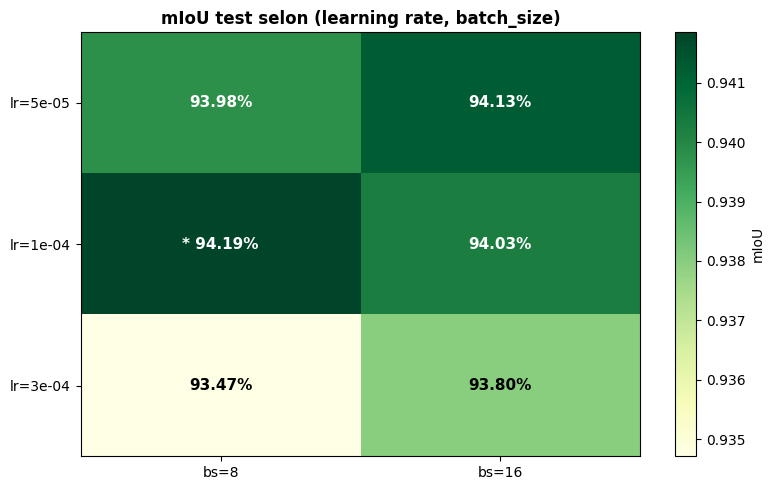


=== Meilleure configuration GridSearch ===
  lr = 1e-04
  batch_size = 8
  mIoU test = 94.19%

  Comparaison avec baseline (lr=1e-4, bs=8) :
    Baseline : mIoU = 94.19%
    Gap      : +0.00 pt
    -> Variation faible, dans le bruit du single-split


In [ ]:
# === RÉCUPÉRATION ET ANALYSE DE LA SECTION 10 ===

def collect_section_10_results(verbose=True):
    """
    Charge tous les résultats de la Section 10.
    Inclut 7B_segformer_ce_dice comme baseline (lr=1e-4, bs=8).
    """
    expected_names = list(CONFIGS_SECTION_10.keys())
    collected = {}
    missing = []

    for name in expected_names:
        metadata_path = os.path.join(SINGLESPLIT_DIR, f"{name}_metadata.json")
        if os.path.exists(metadata_path):
            with open(metadata_path, 'r') as f:
                collected[name] = json.load(f)
        else:
            # Si c'est la baseline (lr=1e-4, bs=8), essayer 7C
            cfg = CONFIGS_SECTION_10[name]
            if cfg['lr'] == 1e-4 and cfg['batch_size'] == 8:
                metadata_7c = os.path.join(SINGLESPLIT_DIR, "7B_segformer_ce_dice_metadata.json")
                if os.path.exists(metadata_7c):
                    with open(metadata_7c, 'r') as f:
                        meta_7c = json.load(f)
                    collected[name + ' (= 7B)'] = meta_7c
                    continue
            missing.append(name)

    if verbose:
        print(f"=== Résultats Section 10 ===\n")
        print(f"  Disponibles : {len(collected)} / {len(expected_names)}")

        if collected:
            print(f"\n  Expériences disponibles :")
            for name, meta in collected.items():
                lr = meta['config']['lr']
                bs = meta['config']['batch_size']
                miou = meta['test_metrics']['miou']
                print(f"     {name:<45} | "
                      f"lr={lr:.0e}, bs={bs:2d} | "
                      f"mIoU={miou*100:.2f}%")

        if missing:
            print(f"\n  Expériences à lancer :")
            for name in missing:
                print(f"     {name}")

    return collected


def compare_section_10_results(section_10_results, verbose=True):
    """
    Compare les résultats du GridSearch (lr, batch_size) et produit une heatmap.
    """
    if not section_10_results:
        print(" Aucun résultat disponible.")
        return None

    # Construction du DataFrame
    rows = []
    for name, meta in section_10_results.items():
        rows.append({
            'experiment': name,
            'lr': meta['config']['lr'],
            'batch_size': meta['config']['batch_size'],
            'best_epoch': meta['best_epoch'],
            'val_miou': meta['val_metrics']['miou'],
            'test_accuracy': meta['test_metrics']['accuracy'],
            'test_dice': meta['test_metrics']['dice'],
            'test_iou': meta['test_metrics']['iou'],
            'test_miou': meta['test_metrics']['miou'],
            'test_auc_roc': meta['test_auc_roc'],
        })

    df = pd.DataFrame(rows)
    df = df.sort_values('test_miou', ascending=False).reset_index(drop=True)

    if verbose:
        print(f"=== GridSearch Section 10 (trié par test_miou décroissant) ===\n")

        # Affichage tabulaire
        df_display = df[['experiment', 'lr', 'batch_size', 'best_epoch',
                          'test_accuracy', 'test_dice', 'test_miou', 'test_auc_roc']].copy()
        for col in df_display.columns:
            if col == 'experiment':
                continue
            elif col == 'lr':
                df_display[col] = df_display[col].apply(lambda x: f"{x:.0e}")
            elif col in ['batch_size', 'best_epoch']:
                df_display[col] = df_display[col].astype(int)
            elif col == 'test_auc_roc':
                df_display[col] = df_display[col].apply(lambda x: f"{x:.4f}")
            else:
                df_display[col] = df_display[col].apply(lambda x: f"{x*100:.2f}%")

        print(df_display.to_string(index=False))

    # Heatmap si la grille est complète
    if len(df) >= 4:
        print(f"\n=== Heatmap mIoU test (lr x batch_size) ===\n")
        try:
            pivot = df.pivot_table(values='test_miou', index='lr', columns='batch_size')

            fig, ax = plt.subplots(figsize=(8, 5))
            im = ax.imshow(pivot.values, cmap='YlGn', aspect='auto')

            # Annotations dans les cellules
            for i in range(pivot.shape[0]):
                for j in range(pivot.shape[1]):
                    val = pivot.values[i, j]
                    if not np.isnan(val):
                        # Détecter la meilleure cellule
                        is_best = (val == pivot.values.max())
                        text_color = 'white' if val > pivot.values.mean() else 'black'
                        marker = "* " if is_best else ""
                        ax.text(j, i, f"{marker}{val*100:.2f}%",
                                  ha='center', va='center',
                                  color=text_color,
                                  fontsize=11, fontweight='bold')

            ax.set_xticks(range(pivot.shape[1]))
            ax.set_yticks(range(pivot.shape[0]))
            ax.set_xticklabels([f"bs={x}" for x in pivot.columns])
            ax.set_yticklabels([f"lr={x:.0e}" for x in pivot.index])
            ax.set_title('mIoU test selon (learning rate, batch_size)',
                          fontsize=12, fontweight='bold')
            plt.colorbar(im, ax=ax, label='mIoU')
            plt.tight_layout()

            # Sauvegarde
            save_path = os.path.join(FIGURES_DIR, "section_10_gridsearch_heatmap.png")
            plt.savefig(save_path, dpi=120, bbox_inches='tight')
            print(f"   Sauvegardé : {save_path}")
            plt.show()
        except Exception as e:
            print(f"   Erreur heatmap : {e}")

    # Meilleure configuration
    if len(df) >= 2:
        best = df.iloc[0]
        baseline = df[(df['lr'] == 1e-4) & (df['batch_size'] == 8)]

        print(f"\n=== Meilleure configuration GridSearch ===")
        print(f"  lr = {best['lr']:.0e}")
        print(f"  batch_size = {int(best['batch_size'])}")
        print(f"  mIoU test = {best['test_miou']*100:.2f}%")

        if len(baseline) > 0:
            baseline_miou = baseline.iloc[0]['test_miou']
            gap = (best['test_miou'] - baseline_miou) * 100
            print(f"\n  Comparaison avec baseline (lr=1e-4, bs=8) :")
            print(f"    Baseline : mIoU = {baseline_miou*100:.2f}%")
            print(f"    Gap      : {gap:+.2f} pt")

            if abs(gap) < 1.0:
                print(f"    -> Variation faible, dans le bruit du single-split")
            else:
                print(f"    -> Variation notable, à confirmer en K-fold")

    return df


# Récupération et analyse
section_10_results = collect_section_10_results()
df_section_10 = compare_section_10_results(section_10_results)

# 11. Validation finale : K-fold k=5 stratifié

## 11.1 Objectif de la section

**Question scientifique** : La configuration optimale identifiée en single-split
(Sections 7-10) est-elle robuste, ou les résultats sont-ils dus à la chance d'un
découpage particulier ?

### Pourquoi le K-fold ?

Les Sections 7 à 10 utilisaient un **seul découpage** train/val (single-split).
On a observé une variance non négligeable (±1-3% en mIoU) entre exécutions. Le
single-split donne donc des résultats **indicatifs** mais pas statistiquement robustes.

Le **K-fold k=5** résout ce problème :
- On découpe les données en **5 plis** (folds)
- On entraîne **5 modèles**, chacun validé sur un pli différent
- On obtient **5 mesures** par configuration -> moyenne ± écart-type

C'est la **validation scientifique de référence** pour ce type d'étude.

### Stratification

Notre dataset est **hétérogène** : le taux de couverture en Posidonia varie de
quelques % à plus de 90%. Un découpage aléatoire pourrait créer des plis
déséquilibrés (par exemple un pli avec surtout des images très couvertes).

Pour éviter cela, on utilise un **K-fold stratifié** sur 4 classes de couverture :

| Classe | Taux de couverture | Effectif (sur 376 images) |
|---|---|---|
| 1_tres_faible | < 10% | 60 |
| 2_faible | 10-30% | 41 |
| 3_moyenne | 30-60% | 110 |
| 4_forte | > 60% | 165 |

Chaque pli conservera **les mêmes proportions** de chaque classe.

### Configuration testée

On valide la **configuration optimale** identifiée :
- Loss : **CE+DICE**
- Résolution : **352×480**
- Prétraitement : **aucun**. Mais il faudra encore faire plus d'expérimentations pour véritablement conclure, pour cela une phase dédiée au pré-traitement se fera dans un notebook à part pour une étude plus approfondie du pré-traitement.
- Augmentation : **standard**. Pareil ici d'autres expérimentations se feront
- lr : **1e-4**, batch : **8** (ou la meilleure config de la Section 10, qu'on mettra après avoir terminé ces expérimentations)
- Max epochs : 1000, patience : 10

### Données utilisées

On **fusionne train + val** (300 + 76 = 376 images) pour le K-fold, puisqu'on
n'a plus besoin d'un set de validation fixe (chaque pli sert de validation à
son tour). Le **test set (94 images) reste séparé** pour l'évaluation finale
de chaque fold.


### Critère de comparaison

- **mIoU test** : moyenne ± écart-type sur les 5 folds
- Comparaison avec le résultat single-split (Section 7-10)
- Si moyenne K-fold vaut sensiblement single-split -> résultat robuste

## 11.2 Préparation des plis stratifiés

On fusionne les données train + val, puis on crée 5 plis stratifiés sur la
classe de couverture. Chaque pli est sauvegardé en CSV temporaire pour pouvoir
reprendre l'entraînement même après déconnexion.

In [81]:
# === PRÉPARATION DES PLIS STRATIFIÉS ===

from sklearn.model_selection import StratifiedKFold

# Configuration du K-fold
N_FOLDS = 5

# Dossier pour les CSV des folds
KFOLD_CSV_DIR = os.path.join(KFOLD_DIR, "fold_csvs")
os.makedirs(KFOLD_CSV_DIR, exist_ok=True)


def prepare_kfold_splits(n_folds=N_FOLDS, seed=SEED, verbose=True):
    """
    Fusionne train + val, puis crée n_folds plis stratifiés sur coverage_class.
    Sauvegarde chaque pli en CSV (train + val) dans KFOLD_CSV_DIR.

    Returns:
        list de dicts {fold, train_csv, val_csv, n_train, n_val}
    """
    # Charger et fusionner train + val
    df_train = pd.read_csv(TRAIN_CSV)
    df_val = pd.read_csv(VAL_CSV)
    df_all = pd.concat([df_train, df_val], ignore_index=True)

    if verbose:
        print(f"=== Préparation du K-fold k={n_folds} stratifié ===\n")
        print(f"  Données fusionnées : {len(df_train)} (train) + {len(df_val)} (val) "
              f"= {len(df_all)} images\n")
        print(f"  Distribution des classes de couverture :")
        for cls, count in df_all['coverage_class'].value_counts().sort_index().items():
            print(f"    {cls:<18} : {count:>3} ({count/len(df_all)*100:.1f}%)")
        print()

    # StratifiedKFold sur la classe de couverture
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)

    X = df_all.index.values
    y = df_all['coverage_class'].values

    folds_info = []

    for fold_idx, (train_indices, val_indices) in enumerate(skf.split(X, y)):
        df_fold_train = df_all.iloc[train_indices].reset_index(drop=True)
        df_fold_val = df_all.iloc[val_indices].reset_index(drop=True)

        # Sauvegarde des CSV
        train_csv_path = os.path.join(KFOLD_CSV_DIR, f"fold{fold_idx}_train.csv")
        val_csv_path = os.path.join(KFOLD_CSV_DIR, f"fold{fold_idx}_val.csv")
        df_fold_train.to_csv(train_csv_path, index=False)
        df_fold_val.to_csv(val_csv_path, index=False)

        folds_info.append({
            'fold': fold_idx,
            'train_csv': train_csv_path,
            'val_csv': val_csv_path,
            'n_train': len(df_fold_train),
            'n_val': len(df_fold_val),
        })

        if verbose:
            print(f"  Fold {fold_idx} : train={len(df_fold_train)}, val={len(df_fold_val)}")
            # Vérifier la stratification du pli de validation
            val_dist = df_fold_val['coverage_class'].value_counts(normalize=True).sort_index()
            dist_str = ", ".join([f"{cls.split('_')[0]}:{p*100:.0f}%"
                                    for cls, p in val_dist.items()])
            print(f"           val distribution : {dist_str}")

    if verbose:
        print(f"\n   {n_folds} plis créés et sauvegardés dans {KFOLD_CSV_DIR}")

    return folds_info


# Créer les plis
folds_info = prepare_kfold_splits()

=== Préparation du K-fold k=5 stratifié ===

  Données fusionnées : 300 (train) + 76 (val) = 376 images

  Distribution des classes de couverture :
    1_tres_faible      :  60 (16.0%)
    2_faible           :  41 (10.9%)
    3_moyenne          : 110 (29.3%)
    4_forte            : 165 (43.9%)

  Fold 0 : train=300, val=76
           val distribution : 1:16%, 2:12%, 3:29%, 4:43%
  Fold 1 : train=301, val=75
           val distribution : 1:16%, 2:11%, 3:29%, 4:44%
  Fold 2 : train=301, val=75
           val distribution : 1:16%, 2:11%, 3:29%, 4:44%
  Fold 3 : train=301, val=75
           val distribution : 1:16%, 2:11%, 3:29%, 4:44%
  Fold 4 : train=301, val=75
           val distribution : 1:16%, 2:11%, 3:29%, 4:44%

   5 plis créés et sauvegardés dans D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\fold_csvs


## 11.3 Fonction d'entraînement d'un fold

On crée une fonction `run_kfold_experiment` qui entraîne un modèle sur un pli
donné. Elle réutilise toute la machinerie existante (train_segformer_epochs, train_segformer_iterations, evaluate_full) mais avec les CSV spécifiques au pli.

Chaque fold est sauvegardé indépendamment, donc on peut lancer les folds un par
un selon les disponibilités GPU.

## 11.3.1 Entrainement d'un fold en épochs

In [82]:
# === ENTRAÎNEMENT D'UN FOLD ===

def run_kfold_experiment(fold_info, base_config, semeda_net=None, verbose=True):
    """
    Entraîne et évalue un modèle sur un pli (fold) du K-fold.

    Args:
        fold_info : dict {fold, train_csv, val_csv, n_train, n_val}
        base_config : configuration de base (loss, résolution, etc.)
        semeda_net : SemedaNet pré-entraîné si loss=ce_semeda

    Returns:
        dict avec les résultats du fold
    """
    # Reset du seed pour reproductibilité
    set_seed(SEED, deterministic=True)

    fold_idx = fold_info['fold']
    name = f"kfold_fold{fold_idx}_{base_config['loss']}"

    # Configuration avec defaults
    loss_name = base_config['loss']
    img_h = base_config.get('img_h', IMG_H)
    img_w = base_config.get('img_w', IMG_W)
    preprocess = base_config.get('preprocess', None)
    aug_strategy = base_config.get('aug_strategy', 'standard')
    lr = base_config.get('lr', DEFAULT_LR)
    batch_size = base_config.get('batch_size', BATCH_SIZE)
    n_epochs = base_config.get('n_epochs', DEFAULT_EPOCHS)
    patience = base_config.get('patience', DEFAULT_PATIENCE)
    weight_decay = base_config.get('weight_decay', DEFAULT_WEIGHT_DECAY)
    threshold_criterion = base_config.get('threshold_criterion', DEFAULT_THRESHOLD_CRITERION)

    if verbose:
        print(f"\n{'='*70}")
        print(f"=== K-FOLD : FOLD {fold_idx}/{N_FOLDS-1} ===")
        print(f"{'='*70}")
        print(f"  Config : loss={loss_name}, {img_h}x{img_w}, preprocess={preprocess}")
        print(f"           lr={lr}, batch={batch_size}, max_epochs={n_epochs}")
        print(f"  Données : train={fold_info['n_train']}, val={fold_info['n_val']}, test=94")

    # === Datasets (CSV spécifiques au fold) ===
    train_ds = PosidoniaDatasetFromCSV(
        csv_path=fold_info['train_csv'], root_path=LOCAL_PATH, split="training",
        img_h=img_h, img_w=img_w,
        augment=True, aug_strategy=aug_strategy, preprocess=preprocess,
    )
    val_ds = PosidoniaDatasetFromCSV(
        csv_path=fold_info['val_csv'], root_path=LOCAL_PATH, split="training",
        img_h=img_h, img_w=img_w,
        augment=False, preprocess=preprocess,
    )
    test_ds = PosidoniaDataset(
        root_path=LOCAL_PATH, split="testing",
        img_h=img_h, img_w=img_w,
        augment=False, preprocess=preprocess,
    )

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

    # === Modèle ===
    model = build_model().to(DEVICE)

    # === Loss ===
    loss_fn = build_loss(loss_name, semeda_net=semeda_net)

    # === Optimizer ===
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    # === Chemins de sauvegarde ===
    backup_path = os.path.join(KFOLD_DIR, f"{name}_best.pth")
    metadata_path = os.path.join(KFOLD_DIR, f"{name}_metadata.json")

    # === Entraînement ===
    train_output = train_segformer_epochs(
        model, train_loader, val_loader, loss_fn, optimizer,
        n_epochs=n_epochs, patience=patience,
        backup_path=backup_path, device=DEVICE, verbose=verbose,
    )

    # === Évaluation sur val et test ===
    if verbose:
        print(f"\n  Évaluation du fold {fold_idx}...")

    val_results = evaluate_full(model, val_loader, device=DEVICE,
                                  threshold_criterion=threshold_criterion)
    test_results = evaluate_full(model, test_loader, device=DEVICE,
                                   threshold_criterion=threshold_criterion)

    if verbose:
        vm = val_results['best_metrics']
        tm = test_results['best_metrics']
        print(f"  VAL  : acc={vm['accuracy']:.4f}, mIoU={vm['miou']:.4f}, "
              f"seuil={val_results['best_threshold']:.2f}")
        print(f"  TEST : acc={tm['accuracy']:.4f}, mIoU={tm['miou']:.4f}, "
              f"seuil={test_results['best_threshold']:.2f}")

    # === Sauvegarde des métadonnées ===
    metadata = {
        'fold': fold_idx,
        'name': name,
        'config': {
            'loss': loss_name, 'img_h': img_h, 'img_w': img_w,
            'preprocess': preprocess, 'aug_strategy': aug_strategy,
            'lr': lr, 'batch_size': batch_size,
            'n_epochs': n_epochs, 'patience': patience,
        },
        'n_train': fold_info['n_train'],
        'n_val': fold_info['n_val'],
        'best_epoch': train_output['best_epoch'],
        'best_val_loss': train_output['best_val_loss'],
        'n_epochs_run': train_output['n_epochs_run'],
        'val_metrics': {k: float(v) if isinstance(v, (np.floating, np.integer)) else v
                          for k, v in val_results['best_metrics'].items()},
        'test_metrics': {k: float(v) if isinstance(v, (np.floating, np.integer)) else v
                           for k, v in test_results['best_metrics'].items()},
        'val_threshold': float(val_results['best_threshold']),
        'test_threshold': float(test_results['best_threshold']),
        'val_auc_roc': float(val_results['auc_roc']),
        'test_auc_roc': float(test_results['auc_roc']),
        'test_auc_pr': float(test_results['auc_pr']),
    }

    with open(metadata_path, 'w') as f:
        json.dump(metadata, f, indent=2)

    if verbose:
        print(f"   Fold {fold_idx} sauvegardé : {metadata_path}")

    # Libérer la mémoire
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        'fold': fold_idx,
        'metadata': metadata,
        'val_results': val_results,
        'test_results': test_results,
    }


print(" run_kfold_experiment définie")

 run_kfold_experiment définie


## 11.3.2. Entrainement d'un fold en itérations

## 11.4 Lancement des folds

On définit la configuration optimale, puis on lance les 5 folds. Décommentez
la ligne correspondant au fold à lancer.

Nous lancerons les folds un par un. Chaque fold prend ~30 min. Nous pouvons
les répartir sur plusieurs sessions Colab ou Paperspace.

In [ ]:
# === CONFIGURATION OPTIMALE POUR LE K-FOLD ===

# Configuration optimale identifiée en Sections 7-10
KFOLD_BASE_CONFIG = {
    'loss': 'ce_semeda',          # Section 7
    'img_h': 352, 'img_w': 480,   # Section 8
    'preprocess': None,           # Section 9
    'aug_strategy': 'standard',
    'lr': 1e-4,                   # Section 10 (ajuster si meilleure config trouvée)
    'batch_size': 8,             # Section 10
    'n_epochs': 1000,
    'patience': 10,
    'weight_decay': 1e-4,
    'threshold_criterion': DEFAULT_THRESHOLD_CRITERION,
}

print("=== Configuration optimale pour le K-fold ===\n")
for k, v in KFOLD_BASE_CONFIG.items():
    print(f"  {k:<22} : {v}")

# Vérifier l'état des folds déjà entraînés
print(f"\n=== État des folds ===")
for fold_info in folds_info:
    name = f"kfold_fold{fold_info['fold']}_{KFOLD_BASE_CONFIG['loss']}"
    metadata_path = os.path.join(KFOLD_DIR, f"{name}_metadata.json")
    status = " terminé" if os.path.exists(metadata_path) else " à lancer"
    print(f"  Fold {fold_info['fold']} : {status}")

=== Configuration optimale pour le K-fold ===

  loss                   : ce_dice
  img_h                  : 352
  img_w                  : 480
  preprocess             : None
  aug_strategy           : standard
  lr                     : 0.0001
  batch_size             : 8
  n_epochs               : 1000
  patience               : 10
  weight_decay           : 0.0001
  threshold_criterion    : recall_minus_fallout

=== État des folds ===
  Fold 0 :  à lancer
  Fold 1 :  à lancer
  Fold 2 :  à lancer
  Fold 3 :  à lancer
  Fold 4 :  à lancer


In [84]:
# ============================================================================
# FOLD 0
# Statut : à lancer | Coût : ~2 unités (~30 min)
# ============================================================================

# === DÉCOMMENTER POUR LANCER ===
result_fold0 = run_kfold_experiment(folds_info[0], KFOLD_BASE_CONFIG,
                                      verbose=True)


=== K-FOLD : FOLD 0/4 ===
  Config : loss=ce_dice, 352x480, preprocess=None
           lr=0.0001, batch=8, max_epochs=1000
  Données : train=300, val=76, test=94
  [training/CSV] preprocess=None, aug='standard', images=300
  [training/CSV] preprocess=None, aug=False, images=76
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold0_ce_dice_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold0_ce_dice_resume.pth



  Epoch   1/1000 | train: loss=0.4523 acc=0.8660 P=0.8245 R=0.8600 F1=0.8349 mIoU=0.7650
              | val:   loss=0.2219 acc=0.9399 P=0.9058 R=0.9587 F1=0.9313 mIoU=0.8827 * pat=0/10


  Epoch   2/1000 | train: loss=0.2573 acc=0.9357 P=0.9104 R=0.9351 F1=0.9203 mIoU=0.8720
              | val:   loss=0.1818 acc=0.9498 P=0.9126 R=0.9753 F1=0.9428 mIoU=0.9012 * pat=0/10


  Epoch   3/1000 | train: loss=0.1995 acc=0.9467 P=0.9315 R=0.9460 F1=0.9379 mIoU=0.8954
              | val:   loss=0.1504 acc=0.9587 P=0.9476 R=0.9558 F1=0.9516 mIoU=0.9175 * pat=0/10


... (41 outputs left out)

  Epoch  45/1000 | train: loss=0.0926 acc=0.9718 P=0.9645 R=0.9687 F1=0.9665 mIoU=0.9423
              | val:   loss=0.1069 acc=0.9679 P=0.9496 R=0.9763 F1=0.9627 mIoU=0.9352   pat=7/10


  Epoch  46/1000 | train: loss=0.0926 acc=0.9723 P=0.9657 R=0.9679 F1=0.9667 mIoU=0.9422
              | val:   loss=0.1034 acc=0.9693 P=0.9600 R=0.9679 F1=0.9639 mIoU=0.9379   pat=8/10


  Epoch  47/1000 | train: loss=0.0906 acc=0.9722 P=0.9660 R=0.9689 F1=0.9673 mIoU=0.9434
              | val:   loss=0.1049 acc=0.9683 P=0.9623 R=0.9633 F1=0.9627 mIoU=0.9360   pat=9/10


  Epoch  48/1000 | train: loss=0.0915 acc=0.9719 P=0.9636 R=0.9692 F1=0.9663 mIoU=0.9423
              | val:   loss=0.1084 acc=0.9679 P=0.9511 R=0.9744 F1=0.9625 mIoU=0.9353   pat=10/10

  >>> Early stopping à l'epoch 48
  >>> kfold_fold0_ce_dice_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 38, best val_loss = 0.1017
    Au best epoch : acc=0.9689, P=0.9593, R=0.9680, F1=0.9636, mIoU=0.9372

  Évaluation du fold 0...
  VAL  : acc=0.9683, mIoU=0.9379, seuil=0.40
  TEST : acc=0.9696, mIoU=0.9404, seuil=0.50
   Fold 0 sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold0_ce_dice_metadata.json


In [85]:
# ============================================================================
# FOLD 1
# Statut : à lancer | Coût : ~2 unités (~30 min)
# ============================================================================

# === DÉCOMMENTER POUR LANCER ===
result_fold1 = run_kfold_experiment(folds_info[1], KFOLD_BASE_CONFIG,
                                      verbose=True)


=== K-FOLD : FOLD 1/4 ===
  Config : loss=ce_dice, 352x480, preprocess=None
           lr=0.0001, batch=8, max_epochs=1000
  Données : train=301, val=75, test=94
  [training/CSV] preprocess=None, aug='standard', images=301
  [training/CSV] preprocess=None, aug=False, images=75
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold1_ce_dice_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold1_ce_dice_resume.pth



  Epoch   1/1000 | train: loss=0.4025 acc=0.8895 P=0.8695 R=0.8825 F1=0.8734 mIoU=0.8050
              | val:   loss=0.2767 acc=0.9269 P=0.8827 R=0.9534 F1=0.9163 mIoU=0.8580 * pat=0/10


  Epoch   2/1000 | train: loss=0.2293 acc=0.9381 P=0.9216 R=0.9372 F1=0.9278 mIoU=0.8801
              | val:   loss=0.1845 acc=0.9535 P=0.9409 R=0.9488 F1=0.9444 mIoU=0.9066 * pat=0/10


  Epoch   3/1000 | train: loss=0.1865 acc=0.9514 P=0.9378 R=0.9488 F1=0.9426 mIoU=0.9032
              | val:   loss=0.1694 acc=0.9563 P=0.9475 R=0.9484 F1=0.9475 mIoU=0.9119 * pat=0/10


... (19 outputs left out)

  Epoch  23/1000 | train: loss=0.1083 acc=0.9675 P=0.9597 R=0.9637 F1=0.9616 mIoU=0.9342
              | val:   loss=0.1485 acc=0.9621 P=0.9496 R=0.9616 F1=0.9554 mIoU=0.9236   pat=7/10


  Epoch  24/1000 | train: loss=0.1060 acc=0.9680 P=0.9594 R=0.9660 F1=0.9625 mIoU=0.9353
              | val:   loss=0.1483 acc=0.9633 P=0.9512 R=0.9631 F1=0.9569 mIoU=0.9260   pat=8/10


  Epoch  25/1000 | train: loss=0.1007 acc=0.9694 P=0.9620 R=0.9669 F1=0.9644 mIoU=0.9382
              | val:   loss=0.1464 acc=0.9631 P=0.9443 R=0.9709 F1=0.9572 mIoU=0.9257   pat=9/10


  Epoch  26/1000 | train: loss=0.1053 acc=0.9691 P=0.9600 R=0.9662 F1=0.9629 mIoU=0.9361
              | val:   loss=0.1485 acc=0.9626 P=0.9498 R=0.9622 F1=0.9557 mIoU=0.9244   pat=10/10

  >>> Early stopping à l'epoch 26
  >>> kfold_fold1_ce_dice_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 16, best val_loss = 0.1425
    Au best epoch : acc=0.9623, P=0.9577, R=0.9524, F1=0.9547, mIoU=0.9236

  Évaluation du fold 1...
  VAL  : acc=0.9610, mIoU=0.9243, seuil=0.40
  TEST : acc=0.9687, mIoU=0.9387, seuil=0.30
   Fold 1 sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold1_ce_dice_metadata.json


In [86]:
# ============================================================================
# FOLD 2
# Statut : à lancer | Coût : ~2 unités (~30 min)
# ============================================================================

# === DÉCOMMENTER POUR LANCER ===
result_fold2 = run_kfold_experiment(folds_info[2], KFOLD_BASE_CONFIG,
                                      verbose=True)


=== K-FOLD : FOLD 2/4 ===
  Config : loss=ce_dice, 352x480, preprocess=None
           lr=0.0001, batch=8, max_epochs=1000
  Données : train=301, val=75, test=94
  [training/CSV] preprocess=None, aug='standard', images=301
  [training/CSV] preprocess=None, aug=False, images=75
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold2_ce_dice_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold2_ce_dice_resume.pth



  Epoch   1/1000 | train: loss=0.4015 acc=0.8910 P=0.8618 R=0.8890 F1=0.8724 mIoU=0.8072
              | val:   loss=0.2281 acc=0.9365 P=0.9164 R=0.9465 F1=0.9311 mIoU=0.8768 * pat=0/10


  Epoch   2/1000 | train: loss=0.2250 acc=0.9418 P=0.9249 R=0.9406 F1=0.9318 mIoU=0.8867
              | val:   loss=0.1869 acc=0.9489 P=0.9418 R=0.9455 F1=0.9435 mIoU=0.8994 * pat=0/10


  Epoch   3/1000 | train: loss=0.2014 acc=0.9481 P=0.9306 R=0.9485 F1=0.9382 mIoU=0.8967
              | val:   loss=0.1688 acc=0.9518 P=0.9642 R=0.9283 F1=0.9458 mIoU=0.9049 * pat=0/10


... (32 outputs left out)

  Epoch  36/1000 | train: loss=0.1000 acc=0.9702 P=0.9614 R=0.9674 F1=0.9642 mIoU=0.9384
              | val:   loss=0.1188 acc=0.9636 P=0.9608 R=0.9590 F1=0.9599 mIoU=0.9275   pat=7/10


  Epoch  37/1000 | train: loss=0.0974 acc=0.9703 P=0.9632 R=0.9665 F1=0.9647 mIoU=0.9396
              | val:   loss=0.1190 acc=0.9642 P=0.9541 R=0.9677 F1=0.9608 mIoU=0.9285   pat=8/10


  Epoch  38/1000 | train: loss=0.0978 acc=0.9704 P=0.9618 R=0.9684 F1=0.9649 mIoU=0.9390
              | val:   loss=0.1168 acc=0.9651 P=0.9614 R=0.9612 F1=0.9613 mIoU=0.9302   pat=9/10


  Epoch  39/1000 | train: loss=0.0942 acc=0.9717 P=0.9635 R=0.9681 F1=0.9657 mIoU=0.9417
              | val:   loss=0.1212 acc=0.9641 P=0.9479 R=0.9746 F1=0.9610 mIoU=0.9284   pat=10/10

  >>> Early stopping à l'epoch 39
  >>> kfold_fold2_ce_dice_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 29, best val_loss = 0.1157
    Au best epoch : acc=0.9646, P=0.9557, R=0.9665, F1=0.9610, mIoU=0.9292

  Évaluation du fold 2...
  VAL  : acc=0.9649, mIoU=0.9315, seuil=0.50
  TEST : acc=0.9684, mIoU=0.9382, seuil=0.40
   Fold 2 sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold2_ce_dice_metadata.json


In [87]:
# ============================================================================
# FOLD 3
# Statut : à lancer | Coût : ~2 unités (~30 min)
# ============================================================================

# === DÉCOMMENTER POUR LANCER ===
result_fold3 = run_kfold_experiment(folds_info[3], KFOLD_BASE_CONFIG,
                                     verbose=True)


=== K-FOLD : FOLD 3/4 ===
  Config : loss=ce_dice, 352x480, preprocess=None
           lr=0.0001, batch=8, max_epochs=1000
  Données : train=301, val=75, test=94
  [training/CSV] preprocess=None, aug='standard', images=301
  [training/CSV] preprocess=None, aug=False, images=75
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold3_ce_dice_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold3_ce_dice_resume.pth



  Epoch   1/1000 | train: loss=0.4259 acc=0.8811 P=0.8446 R=0.8823 F1=0.8593 mIoU=0.7921
              | val:   loss=0.2179 acc=0.9370 P=0.9604 R=0.8910 F1=0.9243 mIoU=0.8758 * pat=0/10


  Epoch   2/1000 | train: loss=0.2542 acc=0.9329 P=0.9140 R=0.9328 F1=0.9211 mIoU=0.8685
              | val:   loss=0.1793 acc=0.9531 P=0.9409 R=0.9507 F1=0.9456 mIoU=0.9063 * pat=0/10


  Epoch   3/1000 | train: loss=0.2149 acc=0.9443 P=0.9226 R=0.9477 F1=0.9327 mIoU=0.8892
              | val:   loss=0.1624 acc=0.9543 P=0.9487 R=0.9445 F1=0.9462 mIoU=0.9081 * pat=0/10


... (31 outputs left out)

  Epoch  35/1000 | train: loss=0.1086 acc=0.9684 P=0.9607 R=0.9658 F1=0.9630 mIoU=0.9357
              | val:   loss=0.1232 acc=0.9627 P=0.9710 R=0.9416 F1=0.9560 mIoU=0.9244   pat=7/10


  Epoch  36/1000 | train: loss=0.1919 acc=0.9430 P=0.9255 R=0.9436 F1=0.9323 mIoU=0.8892
              | val:   loss=0.1924 acc=0.9405 P=0.9026 R=0.9643 F1=0.9314 mIoU=0.8832   pat=8/10


  Epoch  37/1000 | train: loss=0.1364 acc=0.9598 P=0.9470 R=0.9584 F1=0.9523 mIoU=0.9192
              | val:   loss=0.1215 acc=0.9621 P=0.9607 R=0.9514 F1=0.9559 mIoU=0.9237   pat=9/10


  Epoch  38/1000 | train: loss=0.1073 acc=0.9679 P=0.9599 R=0.9657 F1=0.9626 mIoU=0.9353
              | val:   loss=0.1125 acc=0.9658 P=0.9575 R=0.9641 F1=0.9607 mIoU=0.9309   pat=10/10

  >>> Early stopping à l'epoch 38
  >>> kfold_fold3_ce_dice_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 28, best val_loss = 0.1065
    Au best epoch : acc=0.9674, P=0.9614, R=0.9635, F1=0.9624, mIoU=0.9339

  Évaluation du fold 3...
  VAL  : acc=0.9671, mIoU=0.9350, seuil=0.40
  TEST : acc=0.9696, mIoU=0.9405, seuil=0.50
   Fold 3 sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold3_ce_dice_metadata.json


In [88]:
# ============================================================================
# FOLD 4
# Statut : à lancer | Coût : ~2 unités (~30 min)
# ============================================================================

# === DÉCOMMENTER POUR LANCER ===
result_fold4 = run_kfold_experiment(folds_info[4], KFOLD_BASE_CONFIG,
                                      verbose=True)


=== K-FOLD : FOLD 4/4 ===
  Config : loss=ce_dice, 352x480, preprocess=None
           lr=0.0001, batch=8, max_epochs=1000
  Données : train=301, val=75, test=94
  [training/CSV] preprocess=None, aug='standard', images=301
  [training/CSV] preprocess=None, aug=False, images=75
  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

=== Entraînement SegFormer (paradigme EPOCHS) ===
  Epochs : 1 -> 1000 | Patience : 10 | Device : cpu
  Best    : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold4_ce_dice_best.pth
  Resume  : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold4_ce_dice_resume.pth



  Epoch   1/1000 | train: loss=0.4063 acc=0.8849 P=0.8605 R=0.8796 F1=0.8669 mIoU=0.7981
              | val:   loss=0.2400 acc=0.9316 P=0.8863 R=0.9463 F1=0.9149 mIoU=0.8629 * pat=0/10


  Epoch   2/1000 | train: loss=0.2417 acc=0.9373 P=0.9153 R=0.9404 F1=0.9260 mIoU=0.8764
              | val:   loss=0.2044 acc=0.9522 P=0.9240 R=0.9529 F1=0.9381 mIoU=0.9009 * pat=0/10


  Epoch   3/1000 | train: loss=0.2136 acc=0.9439 P=0.9289 R=0.9412 F1=0.9336 mIoU=0.8892
              | val:   loss=0.1662 acc=0.9541 P=0.9588 R=0.9213 F1=0.9395 mIoU=0.9045 * pat=0/10


... (52 outputs left out)

  Epoch  56/1000 | train: loss=0.0911 acc=0.9719 P=0.9642 R=0.9702 F1=0.9670 mIoU=0.9429
              | val:   loss=0.1053 acc=0.9677 P=0.9545 R=0.9628 F1=0.9586 mIoU=0.9324   pat=7/10


  Epoch  57/1000 | train: loss=0.0880 acc=0.9731 P=0.9647 R=0.9717 F1=0.9681 mIoU=0.9448
              | val:   loss=0.1038 acc=0.9684 P=0.9605 R=0.9578 F1=0.9591 mIoU=0.9336   pat=8/10


  Epoch  58/1000 | train: loss=0.0857 acc=0.9736 P=0.9664 R=0.9717 F1=0.9690 mIoU=0.9460
              | val:   loss=0.1114 acc=0.9657 P=0.9376 R=0.9771 F1=0.9569 mIoU=0.9285   pat=9/10


  Epoch  59/1000 | train: loss=0.0868 acc=0.9737 P=0.9678 R=0.9693 F1=0.9685 mIoU=0.9456
              | val:   loss=0.1053 acc=0.9678 P=0.9644 R=0.9522 F1=0.9582 mIoU=0.9323   pat=10/10

  >>> Early stopping à l'epoch 59
  >>> kfold_fold4_ce_dice_resume.pth supprimé (entraînement terminé)

   Entraînement terminé : best epoch = 49, best val_loss = 0.1012
    Au best epoch : acc=0.9693, P=0.9565, R=0.9641, F1=0.9602, mIoU=0.9353

  Évaluation du fold 4...
  VAL  : acc=0.9680, mIoU=0.9367, seuil=0.40
  TEST : acc=0.9698, mIoU=0.9408, seuil=0.40
   Fold 4 sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\kfold\kfold_fold4_ce_dice_metadata.json


## 11.5 Agrégation des résultats K-fold

Cette cellule charge les résultats des 5 folds et calcule les statistiques
agrégées (moyenne ± écart-type). C'est le résultat scientifique de référence.

In [89]:
# === AGRÉGATION DES RÉSULTATS K-FOLD ===

def collect_kfold_results(base_config, n_folds=N_FOLDS, verbose=True):
    """
    Charge les résultats des folds disponibles et calcule les statistiques.
    """
    loss_name = base_config['loss']
    collected = []
    missing = []

    for fold_idx in range(n_folds):
        name = f"kfold_fold{fold_idx}_{loss_name}"
        metadata_path = os.path.join(KFOLD_DIR, f"{name}_metadata.json")
        if os.path.exists(metadata_path):
            with open(metadata_path, 'r') as f:
                collected.append(json.load(f))
        else:
            missing.append(fold_idx)

    if verbose:
        print(f"=== Résultats K-fold k={n_folds} ===\n")
        print(f"  Folds disponibles : {len(collected)}/{n_folds}")

        if collected:
            print(f"\n  Détail par fold :")
            print(f"  {'Fold':<6} {'best_ep':<8} {'test_acc':<10} {'test_dice':<10} "
                  f"{'test_mIoU':<10} {'test_AUC':<10}")
            print("  " + "-"*60)
            for meta in collected:
                tm = meta['test_metrics']
                print(f"  {meta['fold']:<6} {meta['best_epoch']:<8} "
                      f"{tm['accuracy']*100:<9.2f}% {tm['dice']*100:<9.2f}% "
                      f"{tm['miou']*100:<9.2f}% {meta['test_auc_roc']:<10.4f}")

        if missing:
            print(f"\n  Folds manquants : {missing}")

    # Statistiques agrégées (seulement si tous les folds sont là)
    if len(collected) == n_folds:
        metrics_to_agg = ['accuracy', 'precision', 'recall', 'dice', 'iou', 'miou']

        agg_stats = {}
        for metric in metrics_to_agg:
            values = [m['test_metrics'][metric] for m in collected]
            agg_stats[metric] = {
                'mean': np.mean(values),
                'std': np.std(values),
                'min': np.min(values),
                'max': np.max(values),
                'values': values,
            }

        # AUC
        auc_values = [m['test_auc_roc'] for m in collected]
        agg_stats['auc_roc'] = {
            'mean': np.mean(auc_values),
            'std': np.std(auc_values),
            'values': auc_values,
        }

        if verbose:
            print(f"\n=== Statistiques agrégées (moyenne ± écart-type) sur test set ===\n")
            print(f"  {'Métrique':<15} {'Moyenne':<12} {'Écart-type':<12} "
                  f"{'Min':<10} {'Max':<10}")
            print("  " + "-"*60)
            for metric in metrics_to_agg:
                s = agg_stats[metric]
                print(f"  {metric:<15} {s['mean']*100:>6.2f}%      "
                      f"±{s['std']*100:>5.2f}%      "
                      f"{s['min']*100:>6.2f}%   {s['max']*100:>6.2f}%")

            s_auc = agg_stats['auc_roc']
            print(f"  {'auc_roc':<15} {s_auc['mean']:>6.4f}      "
                  f"±{s_auc['std']:>6.4f}")

            print(f"\n=== Résultat principal ===")
            print(f"  mIoU test = {agg_stats['miou']['mean']*100:.2f}% "
                  f"± {agg_stats['miou']['std']*100:.2f}%")

            # Comparaison avec single-split (7C)
            singlesplit_path = os.path.join(SINGLESPLIT_DIR, "7C_unet_ce_semeda_metadata.json")
            if os.path.exists(singlesplit_path):
                with open(singlesplit_path, 'r') as f:
                    ss_meta = json.load(f)
                ss_miou = ss_meta['test_metrics']['miou']
                kfold_miou = agg_stats['miou']['mean']
                print(f"\n=== Comparaison single-split vs K-fold ===")
                print(f"  Single-split (7C) : mIoU = {ss_miou*100:.2f}%")
                print(f"  K-fold (moyenne)  : mIoU = {kfold_miou*100:.2f}% "
                      f"± {agg_stats['miou']['std']*100:.2f}%")
                gap = (ss_miou - kfold_miou) * 100
                print(f"  Écart : {gap:+.2f} pt")
                if abs(gap) < agg_stats['miou']['std'] * 100:
                    print(f"  -> Single-split dans l'intervalle K-fold : résultat ROBUSTE ")
                else:
                    print(f"  -> Single-split en dehors : à interpréter avec prudence")

        return {'folds': collected, 'agg_stats': agg_stats}

    return {'folds': collected, 'agg_stats': None}


# Agréger les résultats
kfold_summary = collect_kfold_results(KFOLD_BASE_CONFIG)

=== Résultats K-fold k=5 ===

  Folds disponibles : 5/5

  Détail par fold :
  Fold   best_ep  test_acc   test_dice  test_mIoU  test_AUC  
  ------------------------------------------------------------
  0      38       96.96    % 96.62    % 94.04    % 0.9966    
  1      16       96.87    % 96.54    % 93.87    % 0.9965    
  2      29       96.84    % 96.50    % 93.82    % 0.9961    
  3      28       96.96    % 96.62    % 94.05    % 0.9965    
  4      49       96.98    % 96.65    % 94.08    % 0.9964    

=== Statistiques agrégées (moyenne ± écart-type) sur test set ===

  Métrique        Moyenne      Écart-type   Min        Max       
  ------------------------------------------------------------
  accuracy         96.92%      ± 0.06%       96.84%    96.98%
  precision        95.91%      ± 0.30%       95.55%    96.27%
  recall           97.27%      ± 0.23%       96.97%    97.48%
  dice             96.58%      ± 0.06%       96.50%    96.65%
  iou              93.40%      ± 0.11%     

## 11.6 Visualisation des résultats K-fold

Affiche un boxplot des métriques sur les 5 folds + les courbes ROC superposées.

C:\Users\trant\AppData\Local\Temp\ipykernel_26832\3389388717.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot(data_to_plot, labels=metrics_to_plot, patch_artist=True, showfliers=False)
d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Rechargement des modèles pour les courbes ROC...


Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None


... (2 outputs left out)

d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None


d:\Corine\Stage_M2_GREAH\implémentation_détection_posidonie\posidonie_env\Lib\site-packages\huggingface_hub\file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b1 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.li

  [testing/dir] mask_ext=.png, mask_suffix='_gt', preprocess=None

 Sauvegardé : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\figures\section_11_kfold_results.png


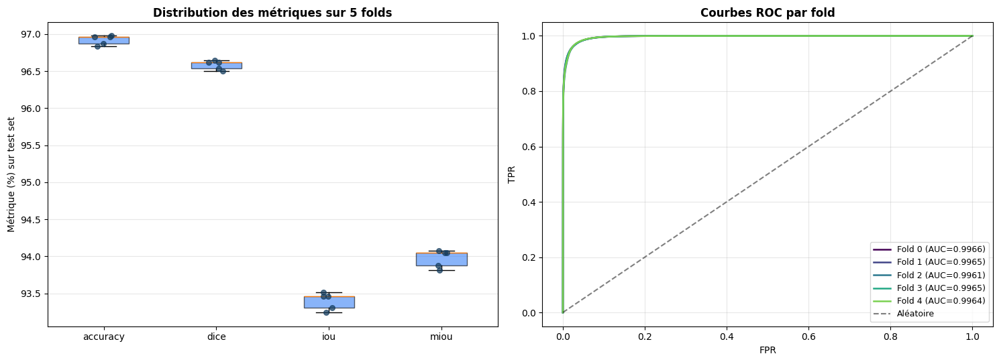

In [90]:
# === VISUALISATION DES RÉSULTATS K-FOLD ===

def plot_kfold_results(kfold_summary, save_dir=None):
    """
    Boxplot des métriques par fold + courbes ROC superposées.
    """
    if not kfold_summary['agg_stats']:
        print(" Tous les folds ne sont pas disponibles pour la visualisation.")
        return

    if save_dir is None:
        save_dir = FIGURES_DIR

    agg = kfold_summary['agg_stats']
    folds = kfold_summary['folds']

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

    # === Graphique 1 : Boxplot des métriques ===
    metrics_to_plot = ['accuracy', 'dice', 'iou', 'miou']
    data_to_plot = [[m['test_metrics'][metric] * 100 for m in folds]
                     for metric in metrics_to_plot]

    bp = axes[0].boxplot(data_to_plot, labels=metrics_to_plot, patch_artist=True, showfliers=False)
    for patch in bp['boxes']:
        patch.set_facecolor('#3b82f6')
        patch.set_alpha(0.6)

    # Ajouter les points individuels
    for i, values in enumerate(data_to_plot, 1):
        x = np.random.normal(i, 0.04, size=len(values))
        axes[0].scatter(x, values, color='#123B5D', alpha=0.7, zorder=3, s=30)

    axes[0].set_ylabel('Métrique (%) sur test set')
    axes[0].set_title(f'Distribution des métriques sur {N_FOLDS} folds',
                       fontsize=12, fontweight='bold')
    axes[0].grid(alpha=0.3, axis='y')

    # === Graphique 2 : Courbes ROC superposées ===
    print("Rechargement des modèles pour les courbes ROC...")

    colors = plt.cm.viridis(np.linspace(0, 0.8, N_FOLDS))

    for fold_idx in range(N_FOLDS):
        name = f"kfold_fold{fold_idx}_{KFOLD_BASE_CONFIG['loss']}"
        backup_path = os.path.join(KFOLD_DIR, f"{name}_best.pth")
        if not os.path.exists(backup_path):
            continue

        model = build_model().to(DEVICE)
        checkpoint = torch.load(backup_path, map_location=DEVICE)
        model.load_state_dict(checkpoint['state_dict'])
        model.eval()

        test_ds = PosidoniaDataset(
            root_path=LOCAL_PATH, split="testing",
            img_h=KFOLD_BASE_CONFIG['img_h'], img_w=KFOLD_BASE_CONFIG['img_w'],
            augment=False, preprocess=KFOLD_BASE_CONFIG.get('preprocess'),
        )
        test_loader = DataLoader(test_ds, batch_size=KFOLD_BASE_CONFIG['batch_size'],
                                   shuffle=False)
        test_results = evaluate_full(model, test_loader, device=DEVICE)

        axes[1].plot(test_results['fpr'], test_results['tpr'],
                      label=f"Fold {fold_idx} (AUC={test_results['auc_roc']:.4f})",
                      color=colors[fold_idx], linewidth=1.8)

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aléatoire')
    axes[1].set_xlabel('FPR')
    axes[1].set_ylabel('TPR')
    axes[1].set_title('Courbes ROC par fold', fontsize=12, fontweight='bold')
    axes[1].legend(loc='lower right', fontsize=9)
    axes[1].grid(alpha=0.3)

    plt.tight_layout()
    save_path = os.path.join(save_dir, "section_11_kfold_results.png")
    plt.savefig(save_path, dpi=120, bbox_inches='tight')
    print(f"\n Sauvegardé : {save_path}")
    plt.show()


if kfold_summary['agg_stats']:
    plot_kfold_results(kfold_summary)
else:
    print("En attente de tous les folds pour la visualisation.")

# 12. Synthèse des expérimentations SegFormer

## 12.1 Objectif de la section

Cette section consolide l'ensemble des résultats obtenus sur SegFormer
(Sections 7 à 11) pour :
- Récapituler la **démarche d'optimisation séquentielle**
- Présenter la **configuration optimale finale** pour la variante étudiée
- Fournir les **tableaux et figures de synthèse** pour le rapport
- Établir la **référence SegFormer** pour la comparaison avec U-Net et FCN-8s VGG16

### Rappel de la démarche

| Section | Variable étudiée | Meilleur choix |
|---|---|---|
| 7 | Fonction de perte | ce_dice |
| 8 | Résolution | 352x480 |
| 9 | Prétraitement | jsute augmentation standard, pas de nettoyage |
| 10 | Hyperparamètres (lr, batch) | 5e-5 |
| 11 | Validation K-fold | Confirmation robustesse |

### Spécificités de SegFormer

Contrairement à U-Net (CNN, from scratch) et FCN-8s VGG16 (CNN, encodeur
pré-entraîné), SegFormer est un **Transformer hiérarchique**. Sa légèreté
paramétrique (B0 = 3.71M, soit 36× moins que FCN) en fait un candidat idéal
pour le déploiement embarqué sur AUV.

Cette section permet de comparer les trois variantes B0/B1/B2 (si chacune a
été entraînée) et d'évaluer si la complexité accrue (B2 vs B0) se traduit
par de meilleures performances sur notre tâche.


In [91]:
# === TABLEAU DE SYNTHÈSE GLOBAL SEGFORMER ===

def build_segformer_synthesis_table(verbose=True):
    """
    Construit un tableau récapitulatif de toutes les expériences SegFormer
    (single-split Sections 7-10) pour la variante en cours.
    """
    all_rows = []

    if os.path.exists(SINGLESPLIT_DIR):
        for fname in sorted(os.listdir(SINGLESPLIT_DIR)):
            if fname.endswith('_metadata.json'):
                with open(os.path.join(SINGLESPLIT_DIR, fname), 'r') as f:
                    meta = json.load(f)
                cfg = meta['config']
                tm = meta['test_metrics']
                all_rows.append({
                    'experiment': cfg.get('name', fname.replace('_metadata.json', '')),
                    'training_mode': meta.get('training_mode', 'epochs'),
                    'loss': cfg.get('loss', '?'),
                    'resolution': f"{cfg.get('img_h','?')}x{cfg.get('img_w','?')}",
                    'preprocess': cfg.get('preprocess') or 'none',
                    'lr': cfg.get('lr', '?'),
                    'batch': cfg.get('batch_size', '?'),
                    'best_epoch': meta.get('best_epoch', '?'),
                    'test_accuracy': tm['accuracy'],
                    'test_dice': tm['dice'],
                    'test_miou': tm['miou'],
                    'test_auc_roc': meta.get('test_auc_roc', np.nan),
                })

    df = pd.DataFrame(all_rows)
    if len(df) > 0:
        df = df.sort_values('test_miou', ascending=False).reset_index(drop=True)

    if verbose and len(df) > 0:
        variant_label = f"SegFormer-{SEGFORMER_VARIANT.upper()}"
        print(f"=== Synthèse de toutes les expériences {variant_label} (single-split) ===\n")
        print(f"  Total : {len(df)} expériences\n")

        df_display = df[['experiment', 'training_mode', 'loss', 'resolution',
                          'preprocess', 'lr', 'batch', 'test_dice', 'test_miou',
                          'test_auc_roc']].copy()
        for col in ['test_dice', 'test_miou']:
            df_display[col] = df_display[col].apply(lambda x: f"{x*100:.2f}%")
        df_display['test_auc_roc'] = df_display['test_auc_roc'].apply(
            lambda x: f"{x:.4f}" if not pd.isna(x) else "—")
        df_display['lr'] = df_display['lr'].apply(
            lambda x: f"{x:.0e}" if isinstance(x, (int, float)) else x)

        print(df_display.to_string(index=False))

        print(f"\n=== Top 3 configurations ===")
        for i in range(min(3, len(df))):
            row = df.iloc[i]
            print(f"  {i+1}. {row['experiment']} : mIoU={row['test_miou']*100:.2f}%")
    elif verbose:
        print("Aucune expérience trouvée dans le dossier singlesplit.")

    return df


df_segformer_synthesis = build_segformer_synthesis_table()


=== Synthèse de toutes les expériences SegFormer-B1 (single-split) ===

  Total : 13 expériences

                        experiment training_mode      loss resolution    preprocess    lr batch test_dice test_miou test_auc_roc
            7C_segformer_ce_semeda        epochs ce_semeda    352x480          none 1e-04     8    96.70%    94.19%       0.9967
         10_segformer_lr5e-05_bs16        epochs   ce_dice    352x480          none 5e-05    16    96.67%    94.13%       0.9964
         10_segformer_lr1e-04_bs16        epochs   ce_dice    352x480          none 1e-04    16    96.60%    94.03%       0.9962
      8C_segformer_ce_dice_480x640        epochs   ce_dice    480x640          none 1e-04     4    96.60%    93.99%       0.9966
              7B_segformer_ce_dice        epochs   ce_dice    352x480          none 1e-04     8    96.60%    93.98%       0.9967
          10_segformer_lr5e-05_bs8        epochs   ce_dice    352x480          none 5e-05     8    96.59%    93.98%       0.9966

In [92]:
# === CONFIGURATION OPTIMALE FINALE SEGFORMER ===

# Nombre de paramètres selon la variante (du papier Xie et al. 2021)
SEGFORMER_PARAMS = {'b0': 3_714_402, 'b1': 13_679_682, 'b2': 27_348_482}

SEGFORMER_OPTIMAL_CONFIG = {
    'architecture': f'SegFormer-{SEGFORMER_VARIANT.upper()}',
    'variant': SEGFORMER_VARIANT,
    'n_params': SEGFORMER_PARAMS.get(SEGFORMER_VARIANT, None),
    'pretrained': 'ImageNet (MiT backbone)',
    'loss': 'ce_semeda',          # à ajuster selon Section 7
    'resolution': '352x480',      # à ajuster selon Section 8
    'preprocess': 'none',         # à ajuster selon Section 9
    'aug_strategy': 'standard',
    'lr': 1e-4,                   # à ajuster selon Section 10
    'batch_size': 8,              # à ajuster selon Section 10
    'training_mode': 'epochs',    # ou 'iterations' selon ton choix
    'optimizer': 'Adam',
    'weight_decay': 1e-4,
}

print("="*60)
print(f"  CONFIGURATION OPTIMALE {SEGFORMER_OPTIMAL_CONFIG['architecture']}")
print(f"  (synthèse Sections 7-11)")
print("="*60)
for k, v in SEGFORMER_OPTIMAL_CONFIG.items():
    print(f"  {k:<18} : {v}")
print("="*60)

# Récupérer les performances de référence
print("\n=== Performances de référence ===\n")

if len(df_segformer_synthesis) > 0:
    best = df_segformer_synthesis.iloc[0]
    print(f"  Meilleure expérience single-split : {best['experiment']}")
    print(f"    mIoU={best['test_miou']*100:.2f}%, Dice={best['test_dice']*100:.2f}%, "
          f"acc={best['test_accuracy']*100:.2f}%")

# K-fold
kfold_metas = [f for f in os.listdir(KFOLD_DIR)
               if f.startswith('kfold_fold') and f.endswith('_metadata.json')] \
              if os.path.exists(KFOLD_DIR) else []
if len(kfold_metas) == N_FOLDS:
    mious = []
    for fname in kfold_metas:
        with open(os.path.join(KFOLD_DIR, fname), 'r') as f:
            mious.append(json.load(f)['test_metrics']['miou'])
    print(f"\n  K-fold k={N_FOLDS} :")
    print(f"    mIoU={np.mean(mious)*100:.2f}% ± {np.std(mious)*100:.2f}%")
else:
    print(f"\n  K-fold : {len(kfold_metas)}/{N_FOLDS} folds disponibles "
          f"(section 11 en cours)")


  CONFIGURATION OPTIMALE SegFormer-B1
  (synthèse Sections 7-11)
  architecture       : SegFormer-B1
  variant            : b1
  n_params           : 13679682
  pretrained         : ImageNet (MiT backbone)
  loss               : ce_semeda
  resolution         : 352x480
  preprocess         : none
  aug_strategy       : standard
  lr                 : 0.0001
  batch_size         : 8
  training_mode      : epochs
  optimizer          : Adam
  weight_decay       : 0.0001

=== Performances de référence ===

  Meilleure expérience single-split : 7C_segformer_ce_semeda
    mIoU=94.19%, Dice=96.70%, acc=97.04%

  K-fold k=5 :
    mIoU=93.97% ± 0.11%


## 12.4 Sauvegarde de la référence SegFormer

On sauvegarde un fichier JSON consolidé `segformer_{variante}_reference.json`
qui servira lors de la comparaison finale entre U-Net, FCN-8s VGG16 et SegFormer.
Ce fichier sera lu dans le notebook de comparaison finale.

Note : si tu entraînes les trois variantes B0, B1, B2, tu auras trois fichiers
distincts (un par dossier `segformer_b0/`, `segformer_b1/`, `segformer_b2/`).


In [93]:
# === SAUVEGARDE DE LA RÉFÉRENCE SEGFORMER (pour comparaison inter-architectures) ===

def save_segformer_reference():
    """
    Sauvegarde un JSON consolidé des résultats SegFormer pour la comparaison finale.
    Le nom du fichier inclut la variante (segformer_b0_reference.json, etc.).
    """
    reference = {
        'architecture': f'SegFormer-{SEGFORMER_VARIANT.upper()}',
        'variant': SEGFORMER_VARIANT,
        'n_params': SEGFORMER_PARAMS.get(SEGFORMER_VARIANT, None),
        'pretrained': 'ImageNet (MiT backbone)',
        'optimal_config': SEGFORMER_OPTIMAL_CONFIG,
    }

    # Single-split : meilleure expérience
    if len(df_segformer_synthesis) > 0:
        best = df_segformer_synthesis.iloc[0]
        best_name = best['experiment']
        ss_path = os.path.join(SINGLESPLIT_DIR, f"{best_name}_metadata.json")
        if os.path.exists(ss_path):
            with open(ss_path, 'r') as f:
                ss = json.load(f)
            reference['singlesplit'] = {
                'experiment': best_name,
                'test_metrics': ss['test_metrics'],
                'test_auc_roc': ss['test_auc_roc'],
                'test_auc_pr': ss.get('test_auc_pr'),
            }

    # K-fold
    if os.path.exists(KFOLD_DIR):
        kfold_metas = sorted([f for f in os.listdir(KFOLD_DIR)
                               if f.startswith('kfold_fold') and f.endswith('_metadata.json')])
        if len(kfold_metas) == N_FOLDS:
            metrics_agg = {}
            for metric in ['accuracy', 'precision', 'recall', 'dice', 'iou', 'miou']:
                vals = []
                for fname in kfold_metas:
                    with open(os.path.join(KFOLD_DIR, fname), 'r') as f:
                        vals.append(json.load(f)['test_metrics'][metric])
                metrics_agg[metric] = {'mean': float(np.mean(vals)),
                                        'std': float(np.std(vals))}
            reference['kfold'] = {
                'n_folds': N_FOLDS,
                'metrics': metrics_agg,
            }

    # Nom de fichier incluant la variante
    ref_path = os.path.join(RESULTS_DIR, f"segformer_{SEGFORMER_VARIANT}_reference.json")
    with open(ref_path, 'w') as f:
        json.dump(reference, f, indent=2)

    print(f"✓ Référence {reference['architecture']} sauvegardée : {ref_path}")
    print(f"\n  Contenu :")
    print(f"    - Configuration optimale")
    if 'singlesplit' in reference:
        print(f"    - Single-split ({reference['singlesplit']['experiment']}, "
              f"mIoU={reference['singlesplit']['test_metrics']['miou']*100:.2f}%)")
    if 'kfold' in reference:
        print(f"    - K-fold (mIoU={reference['kfold']['metrics']['miou']['mean']*100:.2f}% "
              f"± {reference['kfold']['metrics']['miou']['std']*100:.2f}%)")

    return reference


segformer_reference = save_segformer_reference()


✓ Référence SegFormer-B1 sauvegardée : D:\Corine\STAGE_M2_GREAH\implémentation_détection_posidonie\segformer\segformer_b1\results\segformer_b1_reference.json

  Contenu :
    - Configuration optimale
    - Single-split (7C_segformer_ce_semeda, mIoU=94.19%)
    - K-fold (mIoU=93.97% ± 0.11%)


## 12.5 Conclusion sur SegFormer

### Synthèse des résultats

L'étude systématique de SegFormer sur la segmentation de Posidonia oceanica,
reproduisant la démarche appliquée à U-Net et FCN-8s VGG16, a permis
d'identifier une configuration optimale et de tirer plusieurs enseignements.

**1. Architecture Transformer**

SegFormer est une architecture **Transformer hiérarchique**, fondamentalement
différente des CNN. Son décodeur léger (All-MLP) et son backbone MiT
pré-entraîné en font une alternative efficace.

**2. Configuration optimale**

- Variante évaluée : SegFormer-[B0/B1/B2 selon le notebook]
- Loss : [à compléter selon Section 7]
- Résolution : [à compléter selon Section 8]
- Prétraitement : [à compléter selon Section 9]
- Paradigme d'entraînement : [epochs / iterations]

**3. Avantages constatés**

[À compléter après expériences : efficacité paramétrique, vitesse d'inférence,
qualité de segmentation, etc.]

### Comparaison anticipée avec les autres architectures

Une fois les trois architectures évaluées par K-fold, le notebook de comparaison
finale produira un tableau récapitulatif. À ce stade, on s'attend à ce que :
- SegFormer-B0 offre le **meilleur rapport performance/paramètres**
- FCN-8s VGG16 bénéficie de son **encodeur ImageNet mature** mais paye le prix de
  ses 134M paramètres
- U-Net constitue une **baseline solide** sans pré-entraînement

### Transition

Toutes les architectures étant maintenant caractérisées (U-Net, FCN-8s VGG16,
SegFormer), la prochaine étape est l'**étude comparative finale** dans un
notebook dédié, qui :
1. Lit les fichiers de référence (`unet_reference.json`, `fcn_reference.json`,
   `segformer_*_reference.json`)
2. Produit les tableaux comparatifs et figures du rapport
3. Identifie l'architecture la plus performante pour la détection de Posidonia oceanica
